# Formula 1 Podium Prediction — Milestone 1

**Team 106**

| Member | ID |
|---|---|
| John Magdy Fouad Soliman | 58-22411 |
| Abdelrahman Mohamed Abdelrahman Omar Elaswar | 58-4203 |
| Omar Ehab Mohamed Salama Nasr | 58-0949 |
| Mohamed Hany Elghamry Youssef | 58-1835 |

**Kaggle notebook:** https://www.kaggle.com/code/johnsolimann/project-acl-2026  
**GitHub repository:** https://github.com/Johnn-19/Advanced-Computer-Labs-2026

**Task.** For every driver in every race, predict whether they finish on the podium (`positionOrder <= 3`), using only information available **after qualifying and before the race starts**.

| Item | Definition |
|---|---|
| Unit of analysis (one row) | one driver entering one race — unique on `(raceId, driverId)` |
| Target | `podium = 1 if positionOrder <= 3 else 0` |
| Prediction cutoff | after qualifying / starting grid, before lights out |
| Split | train ≤ 2019 · validation 2020–2021 · test ≥ 2022 |
| Dataset | Formula 1 World Championship (1950–2024), Kaggle / Ergast — 14 relational CSV tables |


## Table of Contents

0. [Setup and Data Loading](#0)
1. [Exploratory Data Analysis (EDA)](#1)
2. [Data Cleaning](#2)
3. [Data Analysis](#3)
4. [Answering the Data-Engineering Questions](#4)
5. [Feature Selection](#5) — 5.1 modeling table & leakage audit · 5.2 leakage-safe features · 5.3 leakage checks · 5.4 evidence · 5.5 empirical decisions · 5.6 final feature set
6. [Proper Dataset Splitting](#6)
7. [Data Pre-processing and Feature Engineering](#7) — 7.1 pipeline · 7.2 pre-processing-order experiments · 7.3 effect on the data
8. [Prediction Model](#8) — 8.0 metrics & helpers · 8.1 Logistic Regression · 8.2 Random Forest & Gradient Boosting · 8.3 Shallow NN · 8.4 comparison on train/validation/test · 8.5 feature-group ablation
9. [Explainable AI (XAI)](#9) — 9.1 global (permutation importance, SHAP) · 9.2 local (SHAP waterfall, LIME)
10. [Inference Function](#10)
11. [Conclusions and Known Limitations](#11)

Sections 1–9 follow the Milestone 1 checklist. Splitting (6) comes before pre-processing (7) because every pre-processing step is fitted on the training set only. The split boundaries are fixed as constants in Section 0, so the empirical feature experiments in Section 5 already train on training seasons and score on validation seasons only — the test seasons are not used for any feature, pre-processing, hyper-parameter, threshold or model choice; predictive performance on them is evaluated only in Section 8.4.

<a id="0"></a>
# 0. Setup and Data Loading

Install LIME and SHAP if they are missing, and pin **scikit-learn 1.9.1**, the version all results in this notebook were produced with (needs *Internet: On* in the Kaggle settings). Other scikit-learn versions train slightly different models, so the numbers in the text would not match the outputs.


In [1]:
# Install / pin packages (needs Settings -> Internet: On on Kaggle)
# scikit-learn is pinned to the version every result in this notebook was produced with: different versions
# train slightly different models (e.g. HistGradientBoosting changed between releases), so the numbers quoted
# in the markdown would no longer match the outputs.
import importlib.util, importlib.metadata, subprocess, sys
PINNED = {"scikit-learn": "1.9.1"}
for pkg, version in PINNED.items():
    try:
        installed = importlib.metadata.version(pkg)
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed != version:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"{pkg}=={version}"], check=False)
for pkg in ["lime", "shap"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 60.5 MB/s eta 0:00:00


Imports, global constants (random seed, split boundaries) and a `save_fig` helper that saves every figure for the report.

In [2]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)

# ---- Global constants -------------------------------------------------------
SEED = 42
np.random.seed(SEED)

TRAIN_END = 2019        # train: seasons <= 2019
VAL_END   = 2021        # validation: 2020-2021, test: >= 2022
HYBRID_START = 2014     # Q1 / Q3 era boundaries
GROUND_EFFECT_START = 2022

FIG_DIR = "/kaggle/working/figures" if os.path.exists("/kaggle") else "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name):
    """Save the current figure so it can be reused in the report."""
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=150, bbox_inches="tight")

import sklearn, platform
print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")
if sklearn.__version__ != "1.9.1":
    print("WARNING: scikit-learn is not 1.9.1 (turn Internet on and re-run). The notebook still runs, "
          "but model scores will differ slightly from the numbers quoted in the text.")
print("Setup complete. Figures will be saved to:", FIG_DIR)

Python 3.13.15 | numpy 2.1.3 | pandas 2.3.3 | scikit-learn 1.9.1
Setup complete. Figures will be saved to: /kaggle/working/figures


Load all 14 CSV files twice: `raw_text` keeps every value as text (used to count the `\N` markers), and `raw` parses `\N` and empty strings as missing. **`raw` is never modified**; all cleaning works on copies.

The search for the data folder skips the folders this notebook writes itself (`clean/`, `model/`, `figures/`, `tables/`), and an assertion checks that the files really are the raw Ergast export (they must still contain `\N`). Without this guard a second run on a machine where `clean/` already exists can silently load the *cleaned* CSVs as if they were raw, and every EDA/cleaning output in Sections 1–2 would then be wrong.

In [3]:
# Locate the RAW dataset folder wherever Kaggle mounted it. Folders written by this notebook itself
# (clean/, model/, figures/, tables/) are skipped, so a re-run can never read its own cleaned output as "raw".
OWN_OUTPUT_DIRS = {"clean", "model", "figures", "tables"}
candidates = sorted(glob.glob("/kaggle/input/**/results.csv", recursive=True)) + sorted(glob.glob("**/results.csv", recursive=True))
candidates = [c for c in candidates
              if not set(os.path.normpath(os.path.abspath(c)).split(os.sep)) & OWN_OUTPUT_DIRS
              and os.path.exists(os.path.join(os.path.dirname(c), "lap_times.csv"))]
if not candidates:
    raise FileNotFoundError(
        "F1 dataset not found. Attach 'Formula 1 World Championship (1950 - 2024)' "
        "via 'Add Input' in the right-hand panel, then re-run."
    )
DATA_DIR = os.path.dirname(os.path.abspath(candidates[0]))
print("Data directory:", DATA_DIR)

TABLES = ["circuits", "constructors", "constructor_results", "constructor_standings",
          "drivers", "driver_standings", "races", "results", "qualifying", "lap_times",
          "pit_stops", "sprint_results", "seasons", "status"]

raw_text = {t: pd.read_csv(os.path.join(DATA_DIR, f"{t}.csv"), dtype=str, keep_default_na=False) for t in TABLES}
# Only "\\N" and empty strings mean "missing" (Section 1.2); keep_default_na=False stops pandas
# from silently treating other strings such as "NA" as missing
MISSING_MARKERS = ["\\N", ""]
raw      = {t: pd.read_csv(os.path.join(DATA_DIR, f"{t}.csv"), na_values=MISSING_MARKERS, keep_default_na=False) for t in TABLES}

# Guard: the raw Ergast export marks missing values with the literal "\N"; a cleaned copy would not
assert (raw_text["results"]["position"] == "\\N").any(), f"{DATA_DIR} does not look like the raw dataset (no '\\N' markers)"

pd.DataFrame({t: {"rows": df.shape[0], "columns": df.shape[1]} for t, df in raw.items()}).T

Data directory: /kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020


,rows,columns
circuits,77,9
constructors,212,5
constructor_results,12625,5
constructor_standings,13391,7
drivers,861,9
driver_standings,34863,7
races,1125,18
results,26759,18
qualifying,10494,9
lap_times,589081,6


<a id="1"></a>
# 1. Exploratory Data Analysis (EDA)

We explore the **raw** data before any cleaning. Every finding leads to a cleaning or modeling decision (collected in 1.6), and the key plots are repeated after cleaning in Section 3, so the effect of cleaning is visible.

## 1.1 Tables, keys and data types

The data is relational: `results` (one row per driver entry) is the backbone, and the other tables are joined to it by IDs. A **primary key (PK)** uniquely identifies a row; a **foreign key (FK)** points to a PK in another table.

| Table | Primary key | Foreign keys → table |
|---|---|---|
| `results` | `resultId` | `raceId`→races, `driverId`→drivers, `constructorId`→constructors, `statusId`→status |
| `races` | `raceId` | `circuitId`→circuits, `year`→seasons |
| `qualifying` | `qualifyId` | `raceId`, `driverId`, `constructorId` |
| `driver_standings` | `driverStandingsId` (logically `raceId`+`driverId`) | `raceId`, `driverId` |
| `constructor_standings` | `constructorStandingsId` (logically `raceId`+`constructorId`) | `raceId`, `constructorId` |
| `constructor_results` | `constructorResultsId` | `raceId`, `constructorId` |
| `sprint_results` | `resultId` | `raceId`, `driverId`, `constructorId`, `statusId` |
| `lap_times` | `raceId`+`driverId`+`lap` | `raceId`, `driverId` |
| `pit_stops` | `raceId`+`driverId`+`stop` | `raceId`, `driverId` |
| `drivers`, `constructors`, `circuits`, `status`, `seasons` | their own ID (`year` for seasons) | — |

Preview of the backbone table `results`.

In [4]:
# A look at the backbone table
raw["results"].head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22.0,1,1.0,1,1,10.0,58,1:34:50.616,5690616.0,39.0,2.0,1:27.452,218.300,1
1,2,18,2,2,3.0,5,2.0,2,2,8.0,58,+5.478,5696094.0,41.0,3.0,1:27.739,217.586,1
2,3,18,3,3,7.0,7,3.0,3,3,6.0,58,+8.163,5698779.0,41.0,5.0,1:28.090,216.719,1
3,4,18,4,4,5.0,11,4.0,4,4,5.0,58,+17.181,5707797.0,58.0,7.0,1:28.603,215.464,1
4,5,18,5,1,23.0,3,5.0,5,5,4.0,58,+18.014,5708630.0,43.0,1.0,1:27.418,218.385,1


Compare a plain `read_csv` with our load: which columns turn into text only because of `\N`, and which are still text (dates, lap times)?

In [5]:
# Dates and lap times are still plain text even after handling '\\N'
print("races.date dtype:      ", raw["races"]["date"].dtype, "→ example:", raw["races"]["date"].iloc[0])
print("qualifying.q1 dtype:   ", raw["qualifying"]["q1"].dtype, "→ example:", raw["qualifying"]["q1"].dropna().iloc[0])
print("pit_stops.duration:    ", raw["pit_stops"]["duration"].dtype, "→ example:", raw["pit_stops"]["duration"].iloc[0])

# Plain load: pandas does not know that '\\N' means "missing"
results_naive = pd.read_csv(os.path.join(DATA_DIR, "results.csv"))

dtype_compare = pd.DataFrame({
    "plain load":           results_naive.dtypes.astype(str),
    "load with na_values":  raw["results"].dtypes.astype(str),
})
dtype_compare[dtype_compare["plain load"] != dtype_compare["load with na_values"]]

races.date dtype:       object → example: 2009-03-29
qualifying.q1 dtype:    object → example: 1:26.572
pit_stops.duration:     object → example: 26.898


,plain load,load with na_values
number,object,float64
position,object,float64
milliseconds,object,float64
fastestLap,object,float64
rank,object,float64
fastestLapSpeed,object,float64


**Findings.** `results` has 26,759 rows. `lap_times` is the largest table but is recorded **during** the race, so it can never be a feature. `qualifying` has far fewer rows than `results`, a first hint that qualifying does not cover every season (1.3). In a plain load, `position`, `milliseconds`, `fastestLap`, `rank` and other numeric columns become text only because of `\N`, and dates and lap times (`"1:26.572"`) are strings. **Decision:** parse `\N` as missing and convert dates to `datetime` and durations to seconds (2.1).

## 1.2 Missing values and the `\N` sentinel

Count the literal `\N` and the empty strings in every column of every table, and plot the 20 columns with the highest share.

Columns containing '\N' or empty strings: 30
Empty strings found in: [{'table': 'qualifying', 'column': 'q3', 'n_empty': 46}, {'table': 'qualifying', 'column': 'q2', 'n_empty': 22}]


,table,column,n_sentinel,n_empty,pct_of_rows
0,constructor_results,status,12608,0,99.865347
13,races,sprint_time,1110,0,98.666667
12,races,sprint_date,1107,0,98.400000
9,races,fp3_time,1072,0,95.288889
7,races,fp2_time,1057,0,93.955556
5,races,fp1_time,1057,0,93.955556
11,races,quali_time,1057,0,93.955556
8,races,fp3_date,1053,0,93.600000
1,drivers,number,802,0,93.147503
4,races,fp1_date,1035,0,92.000000


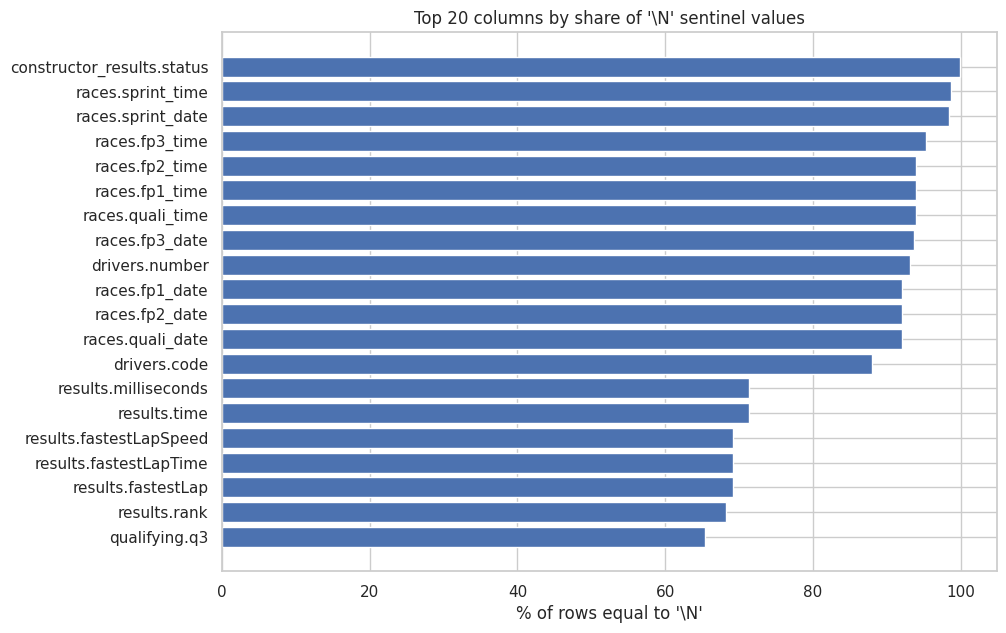

In [6]:
sentinel_rows = []
for t, df in raw_text.items():
    for col in df.columns:
        n_sentinel = (df[col] == "\\N").sum()
        n_empty    = (df[col] == "").sum()
        if n_sentinel + n_empty > 0:
            sentinel_rows.append({"table": t, "column": col, "n_sentinel": n_sentinel, "n_empty": n_empty,
                                  "pct_of_rows": 100 * (n_sentinel + n_empty) / len(df)})

sentinel_counts = pd.DataFrame(sentinel_rows).sort_values("pct_of_rows", ascending=False)
print("Columns containing '\\N' or empty strings:", len(sentinel_counts))
print("Empty strings found in:", sentinel_counts.loc[sentinel_counts.n_empty > 0, ["table", "column", "n_empty"]].to_dict("records"))
display(sentinel_counts.head(20))

top = sentinel_counts.head(20).copy()
top["label"] = top["table"] + "." + top["column"]

plt.figure(figsize=(10, 7))
plt.barh(top["label"][::-1], top["pct_of_rows"][::-1])
plt.xlabel("% of rows equal to '\\N'")
plt.title("Top 20 columns by share of '\\N' sentinel values")
save_fig("1_2_sentinels")
plt.show()

Share of missing values per column in `results` and `qualifying`, the two tables that feed the target and the main features.

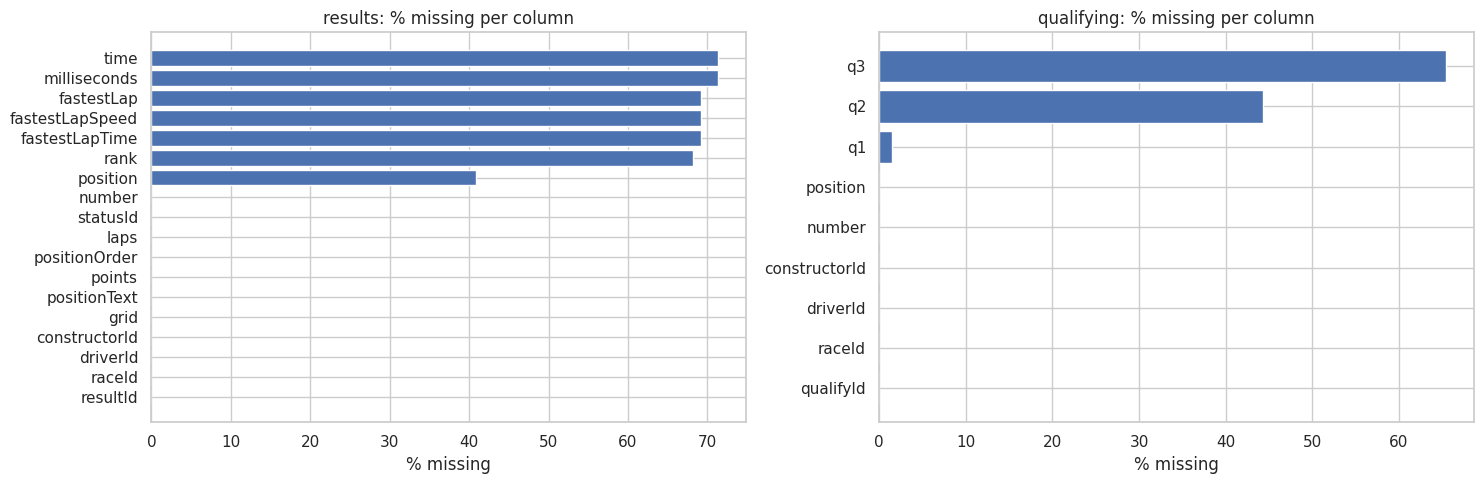

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, t in zip(axes, ["results", "qualifying"]):
    pct = raw[t].isna().mean().mul(100).sort_values()
    ax.barh(pct.index, pct.values)
    ax.set_title(f"{t}: % missing per column")
    ax.set_xlabel("% missing")

plt.tight_layout()
save_fig("1_2_missingness")
plt.show()

**Findings.** `\N` appears in 30 columns and follows the meaning of each column rather than being random:
- `results.time`, `milliseconds`, `fastestLap*` and `rank` are missing for most rows (only finishers get a time; fastest-lap data exists only for recent seasons). They are post-race, so they are never features.
- `results.position` is missing when the driver was not classified, which is information, not an error.
- `qualifying.q2`/`q3` are missing for drivers knocked out in Q1/Q2 (structural missingness).
- A few `q2`/`q3` values are **empty strings** instead of `\N`, a second, inconsistent missing marker.

The target column `positionOrder` and the key feature `grid` are never missing. **Decision:** treat exactly `\N` and `""` as missing, and do not impute post-race columns.

## 1.3 Target, season structure and qualifying coverage

Join `results` with `races`, `status` and `circuits` into one EDA table and add the target `podium = positionOrder <= 3`. This is a copy for exploration only.

In [8]:
eda = (
    raw["results"]
    .merge(raw["races"][["raceId", "year", "round", "name", "circuitId"]], on="raceId", how="left")
    .merge(raw["status"], on="statusId", how="left")
    .merge(raw["circuits"][["circuitId", "country"]], on="circuitId", how="left")
)

eda["podium"] = (eda["positionOrder"] <= 3).astype(int)

print("EDA table shape:", eda.shape)
eda[["raceId", "year", "name", "driverId", "grid", "positionOrder", "status", "podium"]].head()

EDA table shape: (26759, 25)


,raceId,year,name,driverId,grid,positionOrder,status,podium
0,18,2008,Australian Grand Prix,1,1,1,Finished,1
1,18,2008,Australian Grand Prix,2,5,2,Finished,1
2,18,2008,Australian Grand Prix,3,7,3,Finished,1
3,18,2008,Australian Grand Prix,4,11,4,Finished,0
4,18,2008,Australian Grand Prix,5,3,5,Finished,0


Races per season and average entrants per race.

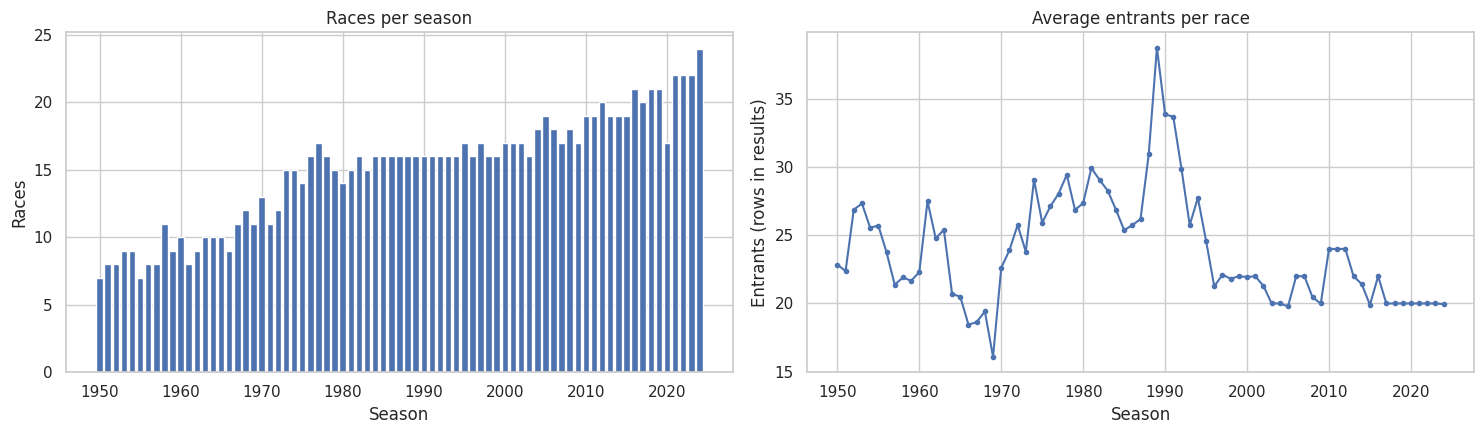

In [9]:
races_per_season   = eda.groupby("year")["raceId"].nunique()
entrants_per_race  = eda.groupby(["year", "raceId"]).size().groupby("year").mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

axes[0].bar(races_per_season.index, races_per_season.values)
axes[0].set_title("Races per season")
axes[0].set_xlabel("Season")
axes[0].set_ylabel("Races")

axes[1].plot(entrants_per_race.index, entrants_per_race.values, marker=".")
axes[1].set_title("Average entrants per race")
axes[1].set_xlabel("Season")
axes[1].set_ylabel("Entrants (rows in results)")

plt.tight_layout()
save_fig("1_3_season_structure")
plt.show()

Class balance and podium rate per season.

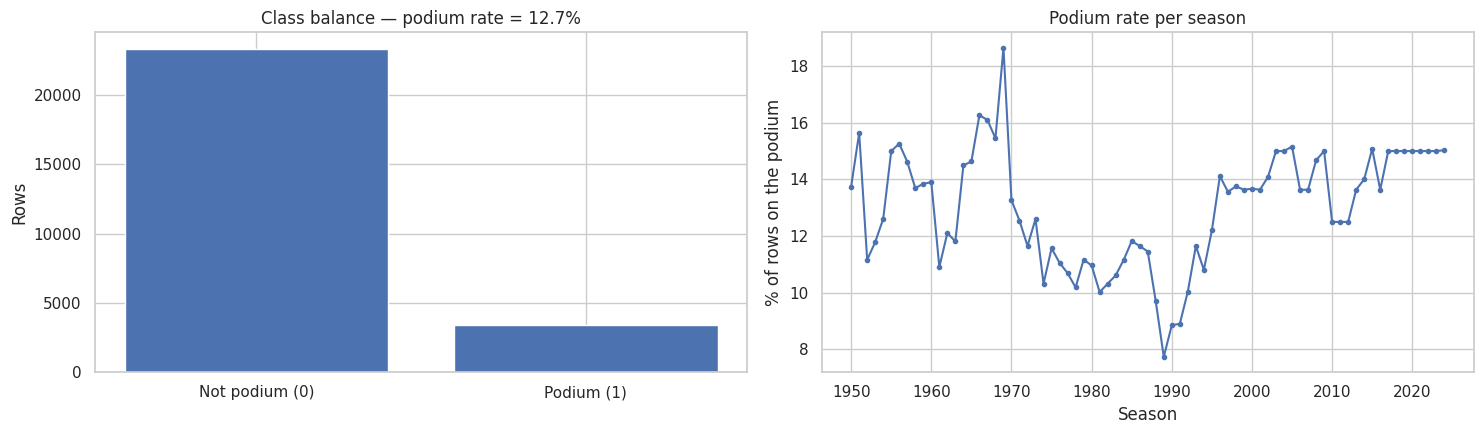

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

counts = eda["podium"].value_counts().sort_index()
axes[0].bar(["Not podium (0)", "Podium (1)"], counts.values)
axes[0].set_title(f"Class balance — podium rate = {eda['podium'].mean():.1%}")
axes[0].set_ylabel("Rows")

podium_rate = eda.groupby("year")["podium"].mean()
axes[1].plot(podium_rate.index, podium_rate.values * 100, marker=".")
axes[1].set_title("Podium rate per season")
axes[1].set_xlabel("Season")
axes[1].set_ylabel("% of rows on the podium")

plt.tight_layout()
save_fig("1_3_target")
plt.show()

Qualifying coverage: the share of result rows with a qualifying record per season, and whether the gaps are whole races or single drivers.

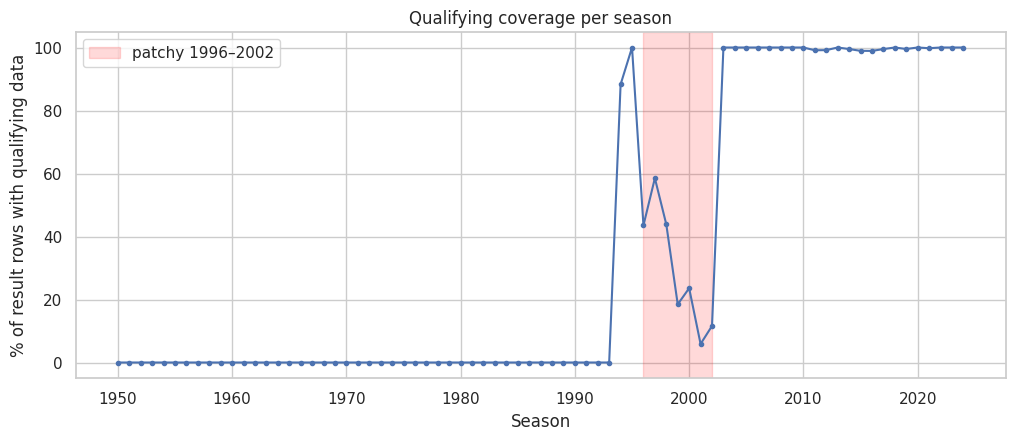

year
1993      0.0
1994     88.3
1995    100.0
1996     43.5
1997     58.5
1998     43.8
1999     18.5
2000     23.6
2001      5.9
2002     11.6
2003    100.0
2004    100.0
Name: has_quali, dtype: float64

,races in season,races with qualifying
year,,
1994,16,15.0
1995,17,17.0
1996,16,7.0
1997,17,10.0
1998,16,7.0
1999,16,3.0
2000,17,4.0
2001,17,1.0
2002,17,2.0


In [11]:
quali_keys = raw["qualifying"][["raceId", "driverId"]].drop_duplicates().assign(has_quali=1)

coverage = (
    eda[["raceId", "driverId", "year"]]
    .merge(quali_keys, on=["raceId", "driverId"], how="left")
    .assign(has_quali=lambda d: d["has_quali"].fillna(0))
    .groupby("year")["has_quali"].mean() * 100
)

plt.figure(figsize=(12, 4.5))
plt.plot(coverage.index, coverage.values, marker=".")
plt.axvspan(1996, 2002, alpha=0.15, color="red", label="patchy 1996–2002")
plt.title("Qualifying coverage per season")
plt.xlabel("Season")
plt.ylabel("% of result rows with qualifying data")
plt.legend()
save_fig("1_3_quali_coverage")
plt.show()

display(coverage.loc[1993:2004].round(1))

# Is the gap whole races or single drivers? Count races with any qualifying data
races_with_quali = raw["qualifying"].merge(raw["races"][["raceId", "year"]], on="raceId").groupby("year")["raceId"].nunique()
pd.DataFrame({"races in season": races_per_season, "races with qualifying": races_with_quali}).loc[1994:2004]

**Findings.**
- Seasons grew from 7 races (1950) to 24 (2024). Entrants per race peaked above 30 in 1988–1991 (many did not qualify) and are about 20 today.
- Only about 1 row in 8 is a podium (12.7%), so the problem is **imbalanced**: predicting "no podium" for everyone is already ~87% accurate. The rate falls below 10% in the big-field seasons and is about 15% in the modern era. **Decision:** imbalance-aware metrics (PR-AUC, ROC-AUC, F1), and test class weighting during modeling (8.1); remove non-starters (2.3), which inflate the denominator.
- There is **no qualifying data before 1994**. Coverage drops sharply in 1996–2002 (whole races are missing, not single drivers) and is essentially complete from 2003 (99.8% of rows). **Decision:** `grid` is the reliable starting-order feature for every season; qualifying features need a restricted training window, a grid fallback or a `has_quali` flag (Section 5).

## 1.4 Grid position, status and the position columns

Podium rate for each grid slot 1–20.

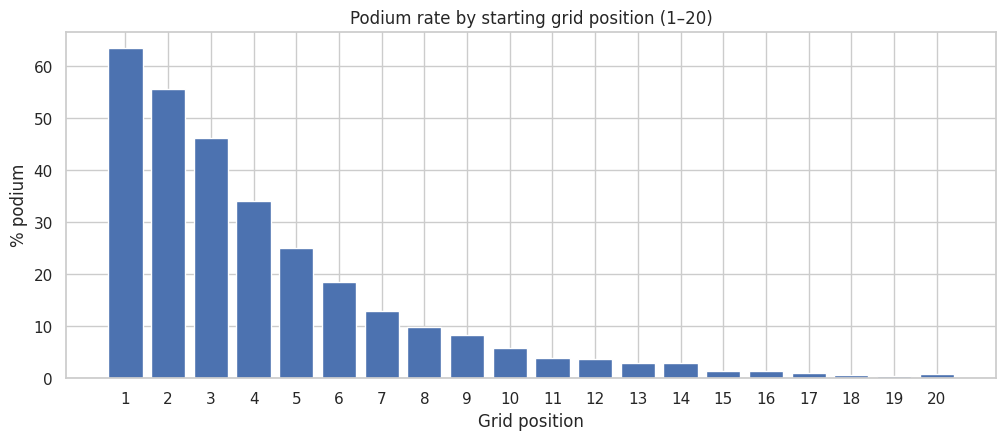

In [12]:
grid_rate = eda[eda["grid"].between(1, 20)].groupby("grid")["podium"].mean() * 100

plt.figure(figsize=(12, 4.5))
plt.bar(grid_rate.index, grid_rate.values)
plt.title("Podium rate by starting grid position (1–20)")
plt.xlabel("Grid position")
plt.ylabel("% podium")
plt.xticks(grid_rate.index)
save_fig("1_4_grid_vs_podium")
plt.show()

What does `grid = 0` mean? The status of every row with `grid = 0`.

Rows with grid = 0: 1638  (6.1% of all rows)


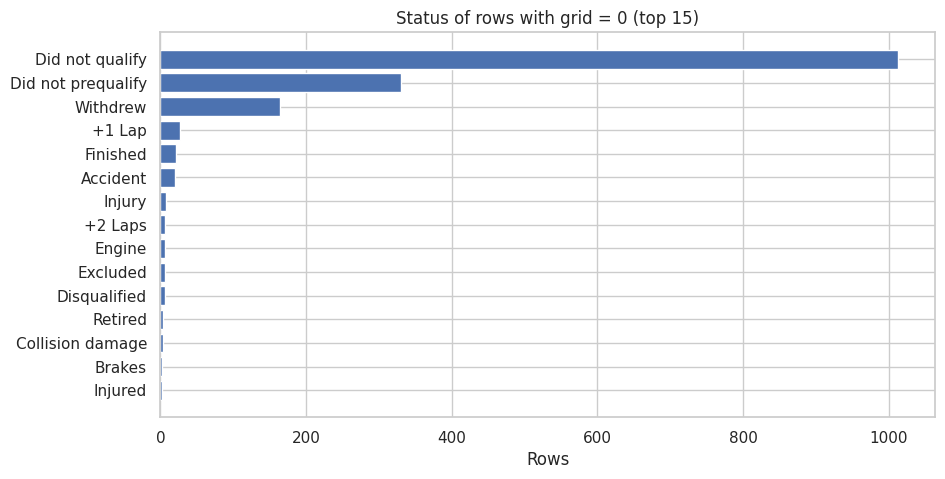

In [13]:
grid0 = eda[eda["grid"] == 0]
print(f"Rows with grid = 0: {len(grid0)}  ({len(grid0) / len(eda):.1%} of all rows)")

grid0_status = grid0["status"].value_counts().head(15)

plt.figure(figsize=(10, 5))
plt.barh(grid0_status.index[::-1], grid0_status.values[::-1])
plt.title("Status of rows with grid = 0 (top 15)")
plt.xlabel("Rows")
save_fig("1_4_grid0_status")
plt.show()

The 20 most frequent `status` values, and the share of entries that reached the finish per decade.

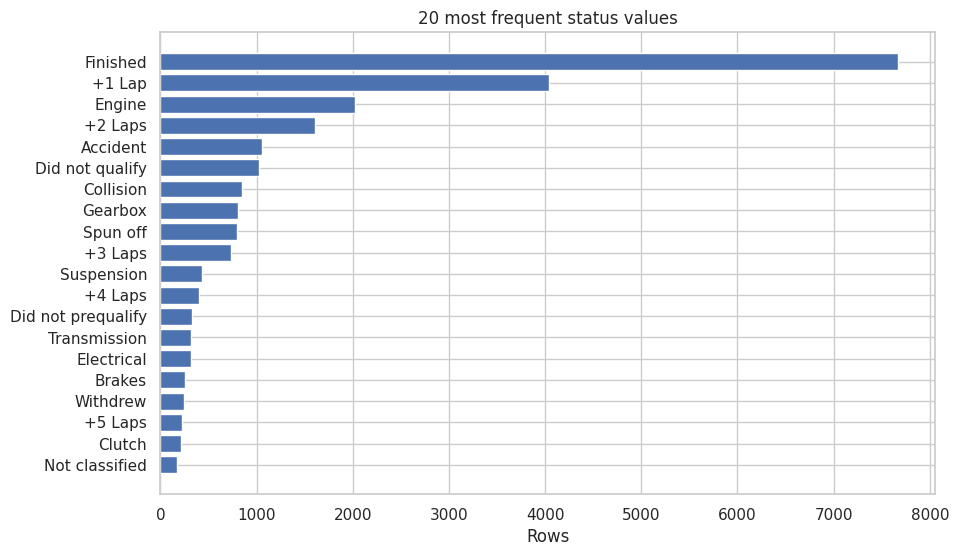

Distinct status values: 137


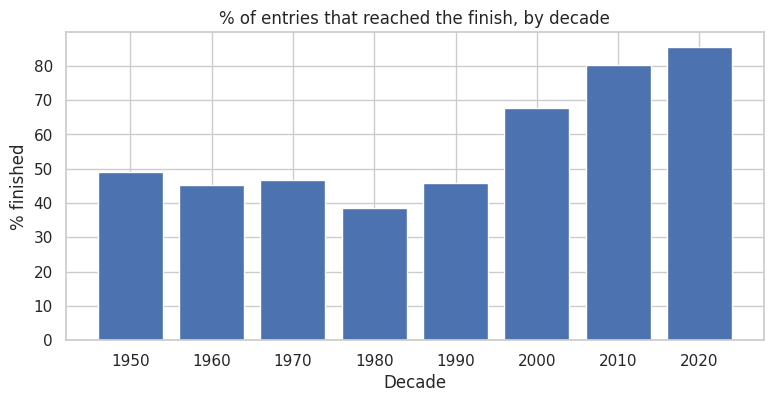

In [14]:
top_status = eda["status"].value_counts().head(20)

plt.figure(figsize=(10, 6))
plt.barh(top_status.index[::-1], top_status.values[::-1])
plt.title("20 most frequent status values")
plt.xlabel("Rows")
save_fig("1_4_status_top20")
plt.show()

print("Distinct status values:", eda["status"].nunique())

# Share of starters who reached the flag ("Finished" or "+N Lap(s)"), per decade
finished = eda["status"].eq("Finished") | eda["status"].str.match(r"^\+\d+ Laps?$")
by_decade = finished.groupby((eda["year"] // 10) * 10).mean() * 100

plt.figure(figsize=(9, 4))
plt.bar(by_decade.index.astype(str), by_decade.values)
plt.title("% of entries that reached the finish, by decade")
plt.xlabel("Decade")
plt.ylabel("% finished")
save_fig("1_4_finish_rate_decade")
plt.show()

Which of `position`, `positionText` and `positionOrder` is always filled, and which letter codes `positionText` uses.

In [15]:
print("Missing values:")
print(eda[["position", "positionText", "positionOrder"]].isna().sum(), "\n")

letter_codes = eda.loc[~eda["positionText"].astype(str).str.isdigit(), "positionText"].value_counts()
print("Letter codes in positionText (R retired, D disqualified, E excluded, W withdrawn, F failed to qualify, N not classified):")
letter_codes

Missing values:
position         10953
positionText         0
positionOrder        0
dtype: int64 

Letter codes in positionText (R retired, D disqualified, E excluded, W withdrawn, F failed to qualify, N not classified):


positionText
R    8897
F    1368
W     336
N     190
D     151
E       9
Name: count, dtype: int64

**Findings.**
- The podium rate falls steadily with grid position: about 63% from pole, 56% from P2, 46% from P3 and under 6% by P10. **`grid` is expected to be the strongest feature** (to be confirmed by the ablation and XAI).
- `grid = 0` (1,638 rows, 6.1%) is mostly **not** a pit-lane start: it is drivers who did not qualify, did not prequalify or withdrew. **Decision:** remove non-starters (2.3) and give real pit-lane starters their own flag.
- There are 137 distinct status values. Before 2000 only about 40–50% of entries reached the finish (39% in the 1980s), against 80%+ since 2010, so a good grid slot converted to a podium less reliably in early F1. `status` is post-race: used for Q3 only, never as a feature.
- `position` is missing for every unclassified driver, while `positionOrder` is always filled, which confirms it as the target column. The `positionText` codes are dominated by R (retired) and F (failed to qualify).

## 1.5 Duplicates, the Indianapolis 500 and summary statistics

Find drivers with more than one row in the same race (shared drives), show an example, and test whether "keep the row with grid > 0" resolves them.

Rows involved in duplicates: 176
Distinct (raceId, driverId) pairs affected: 85


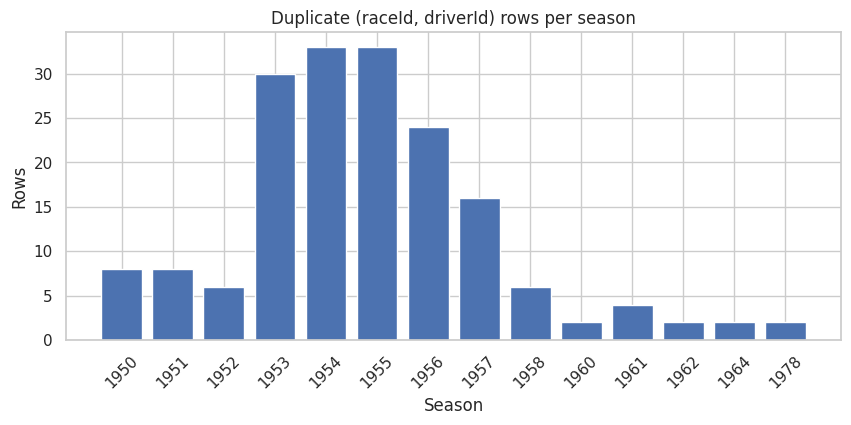

,raceId,year,name,driverId,constructorId,grid,positionOrder,laps,points,status
13188,540,1978,Italian Grand Prix,229,54,0,26,0,0.0,Did not qualify
13191,540,1978,Italian Grand Prix,229,57,0,29,0,0.0,Did not prequalify
17362,717,1964,United States Grand Prix,373,172,1,7,102,0.0,Out of fuel
24298,717,1964,United States Grand Prix,373,172,1,12,54,0.0,Injection
17740,733,1962,British Grand Prix,465,172,0,22,0,0.0,Withdrew
17743,733,1962,British Grand Prix,465,97,0,25,0,0.0,Withdrew
17961,742,1961,British Grand Prix,475,102,20,19,56,0.0,Disqualified
17963,742,1961,British Grand Prix,475,172,5,21,44,0.0,Brakes
18062,745,1961,United States Grand Prix,418,172,11,17,23,0.0,Gearbox
24297,745,1961,United States Grand Prix,418,172,15,11,92,0.0,+8 Laps


,number of pairs
rows with grid > 0 in the pair,
2,76
3,6
0,3


In [16]:
dup_mask = eda.duplicated(["raceId", "driverId"], keep=False)
dups = eda[dup_mask]

print(f"Rows involved in duplicates: {len(dups)}")
print(f"Distinct (raceId, driverId) pairs affected: {dups[['raceId', 'driverId']].drop_duplicates().shape[0]}")

dups_per_year = dups.groupby("year").size()

plt.figure(figsize=(10, 4))
plt.bar(dups_per_year.index.astype(str), dups_per_year.values)
plt.title("Duplicate (raceId, driverId) rows per season")
plt.xlabel("Season")
plt.ylabel("Rows")
plt.xticks(rotation=45)
save_fig("1_5_duplicates")
plt.show()

# Example: one driver with two rows in the same race
example = dups[["raceId", "year", "name", "driverId", "constructorId", "grid", "positionOrder", "laps", "points", "status"]]
display(example.sort_values(["raceId", "driverId"]).head(10))

# Does the "keep the row with grid > 0" rule resolve the duplicates?
rows_with_grid = dups.groupby(["raceId", "driverId"])["grid"].apply(lambda g: (g > 0).sum())
rows_with_grid.value_counts().rename_axis("rows with grid > 0 in the pair").to_frame("number of pairs")

How isolated are the Indianapolis 500 drivers from the rest of the championship?

In [17]:
is_indy = eda["name"].str.contains("Indianapolis", case=False)
indy_drivers  = set(eda.loc[is_indy, "driverId"])
other_drivers = set(eda.loc[~is_indy, "driverId"])

print("Indy 500 races in the data:   ", eda.loc[is_indy, "raceId"].nunique())
print("Result rows from the Indy 500:", is_indy.sum())
print("Drivers who raced the Indy 500:", len(indy_drivers))
print("…of whom also raced any other Grand Prix:", len(indy_drivers & other_drivers))

Indy 500 races in the data:    11
Result rows from the Indy 500: 405
Drivers who raced the Indy 500: 107
…of whom also raced any other Grand Prix: 4


Summary statistics of the main numeric columns.

In [18]:
eda[["grid", "positionOrder", "points", "laps"]].describe().round(2)

,grid,positionOrder,points,laps
count,26759.00,26759.00,26759.00,26759.0
mean,11.13,12.79,1.99,46.3
std,7.20,7.67,4.35,29.5
min,0.00,1.00,0.00,0.0
25%,5.00,6.00,0.00,23.0
50%,11.00,12.00,0.00,53.0
75%,17.00,18.00,2.00,66.0
max,34.00,39.00,50.00,200.0


**Findings.**
- 85 driver-race pairs (176 rows) appear more than once, almost all in 1950–1957: shared drives, where a driver who took over a teammate's car is recorded in both cars. In 76 of the pairs **both** rows have a real grid slot, so "keep grid > 0" alone does not resolve them and a tie-break is needed (2.4).
- The Indy 500 adds 11 races (405 rows), and only 4 of its 107 drivers ever raced another Grand Prix. It would distort the home-race analysis (Q2) and the podium base rate. **Decision:** exclude it (2.3).

## 1.6 EDA findings → cleaning decisions

| # | Finding (evidence) | Decision | Where |
|---|---|---|---|
| 1 | `\N` (and a few empty strings) used as missing markers; numeric columns read as text (1.1, 1.2) | Parse exactly these markers as NaN | 2.1 |
| 2 | Dates and lap times stored as strings (1.1) | Convert to `datetime` / seconds | 2.1 |
| 3 | Missingness is mostly structural and in post-race columns (1.2) | Do not impute post-race columns; they are never features | 2.1, 5 |
| 4 | Podium ≈ 1 in 8 rows; lower in big-field eras (1.3) | Imbalance-aware metrics; test class weighting | 8 |
| 5 | No qualifying data before 1994; patchy 1996–2002 (1.3) | Restrict window / fall back to grid / flag | 5 |
| 6 | Grid strongly and monotonically related to podium (1.4) | Grid as a core feature | 5 |
| 7 | `grid = 0` is mostly non-starters (1.4) | Remove non-starters; pit-lane flag for real starters | 2.3, 5 |
| 8 | `positionOrder` always filled (1.4) | Target = `positionOrder <= 3` | 5.1 |
| 9 | Duplicate (raceId, driverId) rows, mostly 1950s; both rows usually have grid > 0 (1.5) | Started car, then best `positionOrder` | 2.4 |
| 10 | Indy 500 drivers isolated (1.5) | Exclude the Indy 500 | 2.3 |
| 11 | One nationality value with a trailing space and a variant spelling, `'Argentinian '` (2.1) | Strip whitespace in all text columns; map to `Argentine` | 2.1 |

<a id="2"></a>
# 2. Data Cleaning

Every step works on **copies** of `raw` and is recorded in a cleaning log. The order matters: first make the values correct (2.1), then audit the structure (2.2), then fix the scope (2.3) and the grain (2.4). Two outputs:
- `clean`: all 14 tables with correct types and verified keys, no rows removed (used for joins and the data-engineering questions);
- `results_clean`: the modeling backbone, one row per driver per race, real starts only, Indy 500 excluded.

## 2.1 Sentinel handling (`\N`) and semantic typing

Create working copies of every table and a log that records what each cleaning step changes.

In [19]:
clean = {t: df.copy() for t, df in raw.items()}

cleaning_log = []

def log_step(step, table, rows_before, rows_after, note=""):
    """Record what a cleaning step did, so its impact can be reported later."""
    cleaning_log.append({
        "step": step, "table": table,
        "rows_before": rows_before, "rows_after": rows_after,
        "rows_removed": rows_before - rows_after, "note": note,
    })

Verify the sentinel handling: no literal `\N` may remain, and the number of NaNs per table must equal the number of missing markers counted in 1.2.

In [20]:
sentinel_check = pd.DataFrame({
    "markers in raw CSV":       {t: int(df.isin(MISSING_MARKERS).sum().sum()) for t, df in raw_text.items()},
    "NaN after loading":        {t: int(df.isna().sum().sum()) for t, df in clean.items()},
    "'\\N' still in clean":    {t: int((df == "\\N").sum().sum()) for t, df in clean.items()},
})
sentinel_check["match"] = sentinel_check.iloc[:, 0] == sentinel_check.iloc[:, 1]
display(sentinel_check)

assert sentinel_check["'\\N' still in clean"].sum() == 0, "Some '\\N' strings were not converted"
assert sentinel_check["match"].all(), "NaN counts do not match the missing-marker counts"
print("Every missing marker was converted to NaN, and no other value was turned into NaN.")

,markers in raw CSV,NaN after loading,'\N' still in clean,match
circuits,0,0,0,True
constructors,0,0,0,True
constructor_results,12608,12608,0,True
constructor_standings,0,0,0,True
drivers,1559,1559,0,True
driver_standings,0,0,0,True
races,11349,11349,0,True
results,122887,122887,0,True
qualifying,11668,11668,0,True
lap_times,0,0,0,True


Every missing marker was converted to NaN, and no other value was turned into NaN.


Convert date strings to `datetime`, and combine race date and start time into `race_datetime`.

In [21]:
# --- Dates ------------------------------------------------------------------
races = clean["races"]
date_cols = ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"]
for col in date_cols:
    races[col] = pd.to_datetime(races[col], errors="coerce")

# Combined start date-time; the start time is only recorded for recent seasons
races["race_datetime"] = pd.to_datetime(
    races["date"].dt.strftime("%Y-%m-%d") + " " + races["time"].fillna("00:00:00"), errors="coerce"
)

clean["drivers"]["dob"] = pd.to_datetime(clean["drivers"]["dob"], errors="coerce")

print(races[["date", "race_datetime"]].dtypes, "\n")
print("drivers.dob:", clean["drivers"]["dob"].dtype)

date             datetime64[ns]
race_datetime    datetime64[ns]
dtype: object 

drivers.dob: datetime64[ns]


A parser for duration strings (`'1:23.456'`, `'16:44.718'`, `'26.898'`) → seconds, with unit tests on the formats seen in the EDA.

In [22]:
def time_to_seconds(t):
    """Convert duration strings such as '1:23.456', '16:44.718' or '83.456' to seconds (float)."""
    if pd.isna(t):
        return np.nan
    try:
        seconds = 0.0
        for part in str(t).strip().split(":"):   # works for 'ss.sss', 'm:ss.sss' and 'h:mm:ss.sss'
            seconds = seconds * 60 + float(part)
        return seconds
    except ValueError:
        return np.nan

# Quick unit test on the formats we saw in Section 1
assert time_to_seconds("1:23.456") == 83.456
assert time_to_seconds("16:44.718") == 1004.718
assert time_to_seconds("26.898") == 26.898
assert np.isnan(time_to_seconds(np.nan))

Convert every duration column to seconds, report parse failures, and cross-check against the dataset's own `milliseconds` column. `results.time` stays text on purpose: it mixes the winner's total time with gaps (`'+5.478'`), the same value is already in `milliseconds`, and it is post-race anyway.

In [23]:
# --- Durations (text -> seconds) --------------------------------------------
duration_cols = {
    "qualifying":     ["q1", "q2", "q3"],
    "results":        ["fastestLapTime"],
    "sprint_results": ["fastestLapTime"],
    "lap_times":      ["time"],
    "pit_stops":      ["duration"],
}

typing_report = []
for table, cols in duration_cols.items():
    for col in cols:
        original  = clean[table][col]
        converted = original.map(time_to_seconds)
        typing_report.append({
            "column": f"{table}.{col}",
            "example before": original.dropna().iloc[0],
            "example after (s)": round(converted.dropna().iloc[0], 3),
            "non-missing before": int(original.notna().sum()),
            "non-missing after":  int(converted.notna().sum()),
            "parse failures": int(original.notna().sum() - converted.notna().sum()),
        })
        clean[table][col] = converted

display(pd.DataFrame(typing_report))

# Sanity check: our converted seconds must agree with the 'milliseconds' column the dataset already provides
for table, col in [("lap_times", "time"), ("pit_stops", "duration")]:
    diff = (clean[table][col] - clean[table]["milliseconds"] / 1000).abs()
    print(f"{table}.{col}: max difference vs milliseconds = {diff.max():.4f} s")

,column,example before,example after (s),non-missing before,non-missing after,parse failures
0,qualifying.q1,1:26.572,86.572,10338,10338,0
1,qualifying.q2,1:25.187,85.187,5847,5847,0
2,qualifying.q3,1:26.714,86.714,3629,3629,0
3,results.fastestLapTime,1:27.452,87.452,8252,8252,0
4,sprint_results.fastestLapTime,1:30.013,90.013,351,351,0
5,lap_times.time,1:38.109,98.109,589081,589081,0
6,pit_stops.duration,26.898,26.898,11371,11371,0


lap_times.time: max difference vs milliseconds = 0.0000 s
pit_stops.duration: max difference vs milliseconds = 0.0000 s


Audit every text column of every table for leading or trailing whitespace, which would silently break joins and mappings.

In [24]:
def whitespace_audit(tables):
    """List every text column that contains values with leading or trailing whitespace."""
    rows = []
    for t, df in tables.items():
        for col in df.select_dtypes(include="object").columns:
            s = df[col].dropna().astype(str)
            bad = s[s != s.str.strip()]
            if len(bad):
                rows.append({"table": t, "column": col, "rows": len(bad),
                             "examples": sorted(set(bad.map(repr)))[:5]})
    return pd.DataFrame(rows, columns=["table", "column", "rows", "examples"])

ws_before = whitespace_audit(clean)
ws_before

,table,column,rows,examples
0,drivers,nationality,1,['Argentinian ']


Strip the whitespace and unify the one nationality spelling variant.

In [25]:
# 1) Strip whitespace in every text column (missing values stay missing)
for t, df in clean.items():
    for col in df.select_dtypes(include="object").columns:
        df[col] = df[col].str.strip()

# 2) The stripped value 'Argentinian' is a spelling variant of 'Argentine', used for every other Argentine driver
NATIONALITY_FIXES = {"Argentinian": "Argentine"}
drv = clean["drivers"]
affected = drv[drv["nationality"].isin(NATIONALITY_FIXES)]
print("Drivers with a variant nationality spelling:")
print(affected[["driverId", "forename", "surname", "nationality"]].to_string(index=False), "\n")
drv["nationality"] = drv["nationality"].replace(NATIONALITY_FIXES)

log_step("Strip whitespace + unify nationality spelling", "drivers", len(drv), len(drv),
         f"{int(ws_before['rows'].sum())} value(s) stripped, {len(affected)} nationality relabelled")

assert whitespace_audit(clean).empty, "whitespace still present"
print("Argentine drivers now:", int((drv["nationality"] == "Argentine").sum()),
      "| nationality values:", drv["nationality"].nunique())

Drivers with a variant nationality spelling:
 driverId forename   surname nationality
      861   Franco Colapinto Argentinian 

Argentine drivers now: 25 | nationality values: 42


**Findings.** The NaN counts match the marker counts table by table, so NaN means exactly "this value was `\N` in the CSV". This missingness is structural, so it is not filled here; any imputation happens inside the pre-processing pipeline, fitted on the training set only (Section 7). Every duration converted with **zero parse failures** and agrees with `milliseconds`. Only one text value had stray whitespace: Franco Colapinto (2024) was stored as `'Argentinian '`, with a trailing space **and** a different spelling from the `'Argentine'` of every other Argentine driver. Without this fix the nationality mapping in Q2 fails.

## 2.2 Primary keys, foreign keys and value ranges

Check that every primary key, including the logical keys our joins rely on, is unique and non-null. `results` on `(raceId, driverId)` is expected to fail: those are the shared drives.

In [26]:
PRIMARY_KEYS = {
    "circuits":              ["circuitId"],
    "constructors":          ["constructorId"],
    "drivers":               ["driverId"],
    "races":                 ["raceId"],
    "races (logical)":       ["year", "round"],
    "results":               ["resultId"],
    "results (logical)":     ["raceId", "driverId"],
    "qualifying":            ["qualifyId"],
    "qualifying (logical)":  ["raceId", "driverId"],
    "driver_standings":      ["raceId", "driverId"],
    "constructor_standings": ["raceId", "constructorId"],
    "constructor_results":   ["raceId", "constructorId"],
    "sprint_results":        ["raceId", "driverId"],
    "lap_times":             ["raceId", "driverId", "lap"],
    "pit_stops":             ["raceId", "driverId", "stop"],
    "seasons":               ["year"],
    "status":                ["statusId"],
}

def check_primary_keys(tables, keys):
    rows = []
    for name, cols in keys.items():
        df = tables[name.split(" ")[0]]
        rows.append({
            "table": name, "key": " + ".join(cols), "rows": len(df),
            "null keys": int(df[cols].isna().any(axis=1).sum()),
            "duplicate keys": int(df.duplicated(cols).sum()),
        })
    out = pd.DataFrame(rows)
    out["valid"] = (out["null keys"] == 0) & (out["duplicate keys"] == 0)
    return out

pk_report = check_primary_keys(clean, PRIMARY_KEYS)
pk_report

,table,key,rows,null keys,duplicate keys,valid
0,circuits,circuitId,77,0,0,True
1,constructors,constructorId,212,0,0,True
2,drivers,driverId,861,0,0,True
3,races,raceId,1125,0,0,True
4,races (logical),year + round,1125,0,0,True
5,results,resultId,26759,0,0,True
6,results (logical),raceId + driverId,26759,0,91,False
7,qualifying,qualifyId,10494,0,0,True
8,qualifying (logical),raceId + driverId,10494,0,0,True
9,driver_standings,raceId + driverId,34863,0,0,True


Check that every foreign-key value exists in its parent table, and that every race has results.

In [27]:
FOREIGN_KEYS = [
    # (child table, child column, parent table, parent column)
    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),
    ("races", "circuitId", "circuits", "circuitId"),
    ("races", "year", "seasons", "year"),
    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),
    ("driver_standings", "raceId", "races", "raceId"),
    ("driver_standings", "driverId", "drivers", "driverId"),
    ("constructor_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId"),
    ("constructor_results", "raceId", "races", "raceId"),
    ("constructor_results", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "raceId", "races", "raceId"),
    ("sprint_results", "driverId", "drivers", "driverId"),
    ("sprint_results", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "statusId", "status", "statusId"),
    ("lap_times", "raceId", "races", "raceId"),
    ("lap_times", "driverId", "drivers", "driverId"),
    ("pit_stops", "raceId", "races", "raceId"),
    ("pit_stops", "driverId", "drivers", "driverId"),
]

def check_foreign_keys(tables, fks):
    rows = []
    for child, ccol, parent, pcol in fks:
        values  = tables[child][ccol].dropna()
        orphans = ~values.isin(tables[parent][pcol])
        rows.append({"relation": f"{child}.{ccol} → {parent}.{pcol}",
                     "null values": int(tables[child][ccol].isna().sum()),
                     "orphan rows": int(orphans.sum())})
    out = pd.DataFrame(rows)
    out["valid"] = (out["orphan rows"] == 0) & (out["null values"] == 0)
    return out

fk_report = check_foreign_keys(clean, FOREIGN_KEYS)
display(fk_report)

# Reverse check: races that exist in races.csv but have no results
races_without_results = clean["races"][~clean["races"]["raceId"].isin(clean["results"]["raceId"])]
print(f"Races without any results: {len(races_without_results)}")

,relation,null values,orphan rows,valid
0,results.raceId → races.raceId,0,0,True
1,results.driverId → drivers.driverId,0,0,True
2,results.constructorId → constructors.construct...,0,0,True
3,results.statusId → status.statusId,0,0,True
4,races.circuitId → circuits.circuitId,0,0,True
5,races.year → seasons.year,0,0,True
6,qualifying.raceId → races.raceId,0,0,True
7,qualifying.driverId → drivers.driverId,0,0,True
8,qualifying.constructorId → constructors.constr...,0,0,True
9,driver_standings.raceId → races.raceId,0,0,True


Races without any results: 0


Value-range checks (no negative grid, laps or points; dates in the right season; realistic qualifying times) and ties in `positionOrder`.

In [28]:
res, q = clean["results"], clean["qualifying"]

range_checks = pd.DataFrame([
    {"check": "results.grid >= 0",                        "violations": int((res["grid"] < 0).sum())},
    {"check": "results.positionOrder >= 1",               "violations": int((res["positionOrder"] < 1).sum())},
    {"check": "results.laps >= 0",                        "violations": int((res["laps"] < 0).sum())},
    {"check": "results.points >= 0",                      "violations": int((res["points"] < 0).sum())},
    {"check": "races: year of date == season year",       "violations": int((clean["races"]["date"].dt.year != clean["races"]["year"]).sum())},
    {"check": "qualifying q1 between 40 s and 300 s",     "violations": int((~q["q1"].dropna().between(40, 300)).sum())},
    {"check": "qualifying: q2 present but q1 missing",    "violations": int((q["q2"].notna() & q["q1"].isna()).sum())},
])
display(range_checks)

# positionOrder should rank drivers 1, 2, 3, ... inside each race. Are there ties?
ties = res[res.duplicated(["raceId", "positionOrder"], keep=False)]
ties_years = ties.merge(clean["races"][["raceId", "year"]], on="raceId")["year"]
print(f"Rows sharing a positionOrder with another driver in the same race: {len(ties)}")
print("Seasons:", sorted(ties_years.unique().tolist()))

,check,violations
0,results.grid >= 0,0
1,results.positionOrder >= 1,0
2,results.laps >= 0,0
3,results.points >= 0,0
4,races: year of date == season year,0
5,qualifying q1 between 40 s and 300 s,1
6,qualifying: q2 present but q1 missing,0


Rows sharing a positionOrder with another driver in the same race: 228
Seasons: [1950, 1951, 1952, 1953, 1954, 1955, 1956, 1957, 1958, 1960, 1961, 1964]


Inspect the implausible qualifying time and set it to NaN. We keep the row, so the driver's qualifying position survives.

In [29]:
# Inspect the implausible qualifying time(s)
q_bad = clean["qualifying"][~clean["qualifying"]["q1"].dropna().between(40, 300).reindex(clean["qualifying"].index, fill_value=True)]
display(q_bad.merge(clean["races"][["raceId", "year", "name"]], on="raceId")[["year", "name", "driverId", "position", "q1", "q2", "q3"]])

# A lap of more than 5 minutes is not a real qualifying lap (laps take ~1-2 minutes): treat it as a data-entry error.
# We set the value to NaN instead of dropping the row, so the driver's qualifying position is kept.
n_fixed = int((~clean["qualifying"]["q1"].dropna().between(40, 300)).sum())
for col in ["q1", "q2", "q3"]:
    clean["qualifying"].loc[~clean["qualifying"][col].between(40, 300), col] = np.nan
log_step("Implausible qualifying times → NaN", "qualifying", len(clean["qualifying"]), len(clean["qualifying"]),
         f"{n_fixed} value(s) outside 40-300 s")
print(f"Values set to NaN: {n_fixed} | max q1 now: {clean['qualifying']['q1'].max():.3f} s")

,year,name,driverId,position,q1,q2,q3
0,1995,Japanese Grand Prix,87,24,1002.64,NaN,NaN


Values set to NaN: 1 | max q1 now: 153.885 s


**Findings.**
- Every primary key is unique and non-null **except** `results` on `(raceId, driverId)` (91 duplicate rows). `resultId` is unique, so the table is not broken: its grain is one row per *car*, not per *driver* (fixed in 2.4).
- Every foreign key has **0 orphans and 0 nulls**, so no join loses or misattaches rows, and every race (including all 24 rounds of 2024) has results.
- There are no impossible values in `results` or `races`. One Q1 time of about 1,003 s (Japanese GP 1995) is a data-entry error (real laps take 1–2 minutes) and was set to NaN.
- 228 rows share a `positionOrder` with another driver in the same race, all in 1950–1964: both drivers of a shared car were credited with its result. This is historically correct, so it is kept and documented.

## 2.3 Scope: Indianapolis 500 and non-starters

**Indianapolis 500.** Removed from the modeling backbone (evidence in 1.5). The rows stay in `clean["results"]`, so the decision can be revisited.

**Non-starters.** A non-starter has no starting grid, so there is nothing to predict at the cutoff, and these rows inflate the "no podium" class. A row is a non-starter if **any** of these holds:
1. `positionText` is `F` (failed to qualify) or `W` (withdrawn);
2. `status` is *Did not qualify*, *Did not prequalify*, *Withdrew* or *107% Rule*;
3. `grid == 0` **and** `laps == 0`.

Rule 1 is needed because some withdrawn cars carry a mechanical status such as *Engine*. Rule 3 requires both conditions, so real pit-lane starters (`grid == 0`, `laps > 0`) are kept.

Remove the 11 Indianapolis 500 races.

In [30]:
indy_race_ids = clean["races"].loc[clean["races"]["name"].str.contains("Indianapolis", case=False), "raceId"]

results_scope = clean["results"].copy()
before = len(results_scope)
results_scope = results_scope[~results_scope["raceId"].isin(indy_race_ids)]
log_step("Exclude Indianapolis 500", "results", before, len(results_scope), f"{len(indy_race_ids)} races")

print(f"Indy 500 races: {len(indy_race_ids)} | rows removed: {before - len(results_scope)}")

Indy 500 races: 11 | rows removed: 405


Flag non-starters with the three rules, show how many rows each rule catches, and remove them.

In [31]:
NON_START_STATUS = ["Did not qualify", "Did not prequalify", "Withdrew", "107% Rule"]
non_start_ids = clean["status"].loc[clean["status"]["status"].isin(NON_START_STATUS), "statusId"]

rule_1 = results_scope["positionText"].isin(["F", "W"])
rule_2 = results_scope["statusId"].isin(non_start_ids)
rule_3 = (results_scope["grid"] == 0) & (results_scope["laps"] == 0)
non_starter = rule_1 | rule_2 | rule_3

display(pd.DataFrame({
    "rule": ["1: positionText F/W", "2: non-start status", "3: grid 0 and 0 laps", "any rule (removed)"],
    "rows flagged": [rule_1.sum(), rule_2.sum(), rule_3.sum(), non_starter.sum()],
}))

before = len(results_scope)
results_scope = results_scope[~non_starter]
log_step("Remove non-starters", "results", before, len(results_scope), "rules 1-3")

pitlane_starters = ((results_scope["grid"] == 0) & (results_scope["laps"] > 0)).sum()
print(f"Rows removed: {before - len(results_scope)}")
print(f"Remaining rows with grid = 0 (real pit-lane starters): {pitlane_starters}")

,rule,rows flagged
0,1: positionText F/W,1704
1,2: non-start status,1613
2,3: grid 0 and 0 laps,1566
3,any rule (removed),1739


Rows removed: 1739
Remaining rows with grid = 0 (real pit-lane starters): 72


## 2.4 Grain fixed to one row per (raceId, driverId)

**Rule:** for a driver with more than one row in a race (a shared drive), keep **the car he started in**; if that cannot be identified, keep the row with the **best `positionOrder`**.

The started car is the row whose grid slot is **not shared with any other driver** in that race: a driver who took over a teammate's car is recorded with that car's grid slot, which the teammate's row also has. Our prediction is made at the starting grid, so the row matching the driver's own starting position is the one consistent with the cutoff. The `positionOrder` tie-break uses a post-race value only to choose which duplicate row to keep for a few 1950s cases; it never becomes a feature.

Find the duplicate pairs left after 2.3 and count which step of the rule resolves each one.

In [32]:
res = results_scope.copy()

# How many drivers occupy each grid slot in each race?
res["drivers_on_slot"] = res.groupby(["raceId", "grid"])["driverId"].transform("nunique")
res["started_car"] = (res["grid"] > 0) & (res["drivers_on_slot"] == 1)

dup_mask = res.duplicated(["raceId", "driverId"], keep=False)
dup_rows = res[dup_mask]
print(f"Duplicate rows left after the scope decisions: {len(dup_rows)} "
      f"({dup_rows[['raceId', 'driverId']].drop_duplicates().shape[0]} driver-race pairs)")

# Which step of the rule resolves each pair?
started_per_pair = dup_rows.groupby(["raceId", "driverId"])["started_car"].sum()
resolved_by = np.where(started_per_pair == 1, "step 1: unique started car", "step 2: best positionOrder")
pd.Series(resolved_by).value_counts().rename_axis("resolved by").to_frame("pairs")

Duplicate rows left after the scope decisions: 125 (61 driver-race pairs)


,pairs
resolved by,
step 1: unique started car,41
step 2: best positionOrder,20


Apply the rule (started car first, then best `positionOrder`) and assert that the grain is now unique.

In [33]:
# Apply the rule: started car first, then best (lowest) positionOrder
before = len(res)
results_clean = (
    res.sort_values(["raceId", "driverId", "started_car", "positionOrder"], ascending=[True, True, False, True])
       .drop_duplicates(["raceId", "driverId"], keep="first")
       .drop(columns=["drivers_on_slot", "started_car"])
       .sort_values(["raceId", "positionOrder"])
       .reset_index(drop=True)
)
log_step("Resolve shared-drive duplicates", "results", before, len(results_clean), "started car → best positionOrder")

assert not results_clean.duplicated(["raceId", "driverId"]).any()
print(f"Rows removed: {before - len(results_clean)} | grain is now one row per (raceId, driverId)")

Rows removed: 64 | grain is now one row per (raceId, driverId)


Example: which row was kept for one shared drive.

In [34]:
# Example: which row was kept for one shared drive?
example_pair = started_per_pair[started_per_pair == 1].index[0]          # a pair resolved by step 1
example_pair = {"raceId": example_pair[0], "driverId": example_pair[1]}
show = ["raceId", "driverId", "constructorId", "grid", "drivers_on_slot", "started_car", "positionOrder", "laps"]
example_rows = dup_rows[(dup_rows["raceId"] == example_pair["raceId"]) & (dup_rows["driverId"] == example_pair["driverId"])][show].copy()
example_rows["kept"] = example_rows.index.isin(
    res.sort_values(["raceId", "driverId", "started_car", "positionOrder"], ascending=[True, True, False, True])
       .drop_duplicates(["raceId", "driverId"]).index
)
example_rows

,raceId,driverId,constructorId,grid,drivers_on_slot,started_car,positionOrder,laps,kept
17961,742,475,102,20,2,False,19,56,False
17963,742,475,172,5,1,True,21,44,True


## 2.5 Final checks, cleaning summary and saving

Final grain check on `results_clean`, and the audit trail of every cleaning step.

In [35]:
final_checks = check_primary_keys({"results_clean": results_clean}, {"results_clean": ["raceId", "driverId"]})
final_checks["non-starters left"] = int((results_clean["positionText"].isin(["F", "W"])).sum())
final_checks["Indy 500 rows left"] = int(results_clean["raceId"].isin(indy_race_ids).sum())
display(final_checks)

cleaning_summary = pd.DataFrame(cleaning_log)
cleaning_summary["% of step input removed"] = (100 * cleaning_summary["rows_removed"] / cleaning_summary["rows_before"]).round(2)
cleaning_summary

,table,key,rows,null keys,duplicate keys,valid,non-starters left,Indy 500 rows left
0,results_clean,raceId + driverId,24551,0,0,True,0,0


,step,table,rows_before,rows_after,rows_removed,note,% of step input removed
0,Strip whitespace + unify nationality spelling,drivers,861,861,0,"1 value(s) stripped, 1 nationality relabelled",0.00
1,Implausible qualifying times → NaN,qualifying,10494,10494,0,1 value(s) outside 40-300 s,0.00
2,Exclude Indianapolis 500,results,26759,26354,405,11 races,1.51
3,Remove non-starters,results,26354,24615,1739,rules 1-3,6.60
4,Resolve shared-drive duplicates,results,24615,24551,64,started car → best positionOrder,0.26


Save the cleaned tables so teammates can reuse them without re-running the cleaning.

In [36]:
CLEAN_DIR = "/kaggle/working/clean" if os.path.exists("/kaggle") else "clean"
os.makedirs(CLEAN_DIR, exist_ok=True)

results_clean.to_csv(os.path.join(CLEAN_DIR, "results_clean.csv"), index=False)
for t, df in clean.items():
    df.to_csv(os.path.join(CLEAN_DIR, f"{t}.csv"), index=False)

print("Saved to", CLEAN_DIR, ":", sorted(os.listdir(CLEAN_DIR)))

Saved to /kaggle/working/clean : ['circuits.csv', 'constructor_results.csv', 'constructor_standings.csv', 'constructors.csv', 'driver_standings.csv', 'drivers.csv', 'lap_times.csv', 'pit_stops.csv', 'qualifying.csv', 'races.csv', 'results.csv', 'results_clean.csv', 'seasons.csv', 'sprint_results.csv', 'status.csv']


**Findings.** After removing 405 Indy 500 rows, 1,739 non-starters and 64 shared-drive duplicates, `results_clean` has **24,551 rows, exactly one per `(raceId, driverId)`**, only real race starts and no Indy 500. Of the 61 duplicate pairs left after 2.3, 41 were resolved by the started-car step and 20 by the `positionOrder` tie-break. The cleaning-log table is the audit trail of every change.

<a id="3"></a>
# 3. Data Analysis

We repeat the key EDA plots on the cleaned backbone, **side by side with the raw data**, to show the effect of the cleaning on the data.

Rebuild the analysis table from `results_clean` with the same joins as in 1.3, so before and after are directly comparable.

In [37]:
def build_eda_table(results_df):
    """Same joins as Section 1.3, so 'before' and 'after' are directly comparable."""
    out = (
        results_df
        .merge(clean["races"][["raceId", "year", "round", "name", "circuitId", "date"]], on="raceId", how="left")
        .merge(clean["status"], on="statusId", how="left")
        .merge(clean["circuits"][["circuitId", "country"]], on="circuitId", how="left")
    )
    out["podium"] = (out["positionOrder"] <= 3).astype(int)
    return out

eda_before = eda                                   # built from the raw results in Section 1.3
eda_after  = build_eda_table(results_clean)
print("Before:", eda_before.shape, "| After:", eda_after.shape)

Before: (26759, 25) | After: (24551, 26)


## 3.1 Rows, duplicates and podium rate — before vs after

Rows left in the backbone after each cleaning step.

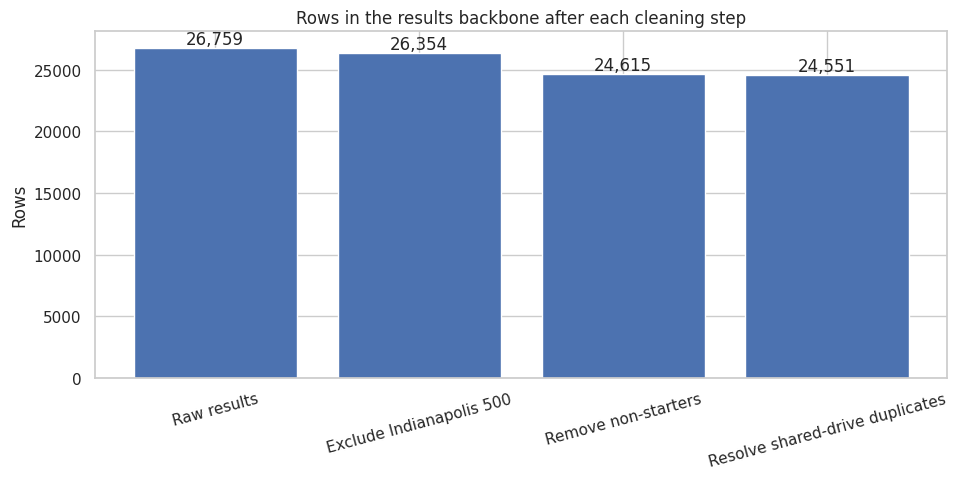

In [38]:
results_steps = cleaning_summary[cleaning_summary["table"] == "results"]
steps  = ["Raw results"] + results_steps["step"].tolist()
counts = [len(raw["results"])] + results_steps["rows_after"].tolist()

plt.figure(figsize=(11, 4.5))
bars = plt.bar(steps, counts)
for bar, n in zip(bars, counts):
    plt.text(bar.get_x() + bar.get_width() / 2, n, f"{n:,}", ha="center", va="bottom")
plt.title("Rows in the results backbone after each cleaning step")
plt.ylabel("Rows")
plt.xticks(rotation=15)
save_fig("3_1_rows_per_step")
plt.show()

Duplicate `(raceId, driverId)` rows before and after cleaning.

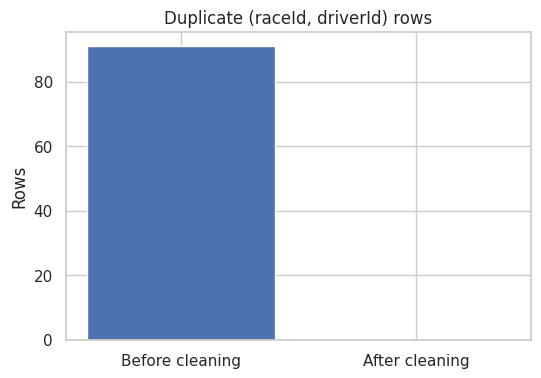

Before: 91 | After: 0


In [39]:
dup_before = eda_before.duplicated(["raceId", "driverId"]).sum()
dup_after  = eda_after.duplicated(["raceId", "driverId"]).sum()

plt.figure(figsize=(6, 4))
plt.bar(["Before cleaning", "After cleaning"], [dup_before, dup_after])
plt.title("Duplicate (raceId, driverId) rows")
plt.ylabel("Rows")
save_fig("3_1_duplicates_before_after")
plt.show()
print(f"Before: {dup_before} | After: {dup_after}")

Overall podium rate and podium rate per season, before and after cleaning.

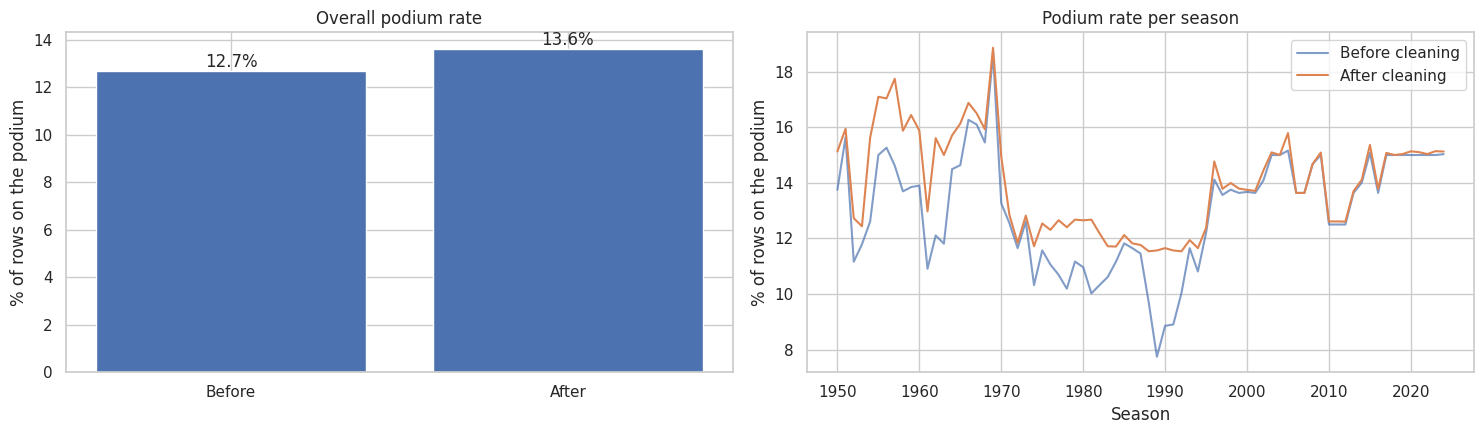

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

rates = pd.Series({"Before": eda_before["podium"].mean() * 100, "After": eda_after["podium"].mean() * 100})
axes[0].bar(rates.index, rates.values)
for i, v in enumerate(rates.values):
    axes[0].text(i, v, f"{v:.1f}%", ha="center", va="bottom")
axes[0].set_title("Overall podium rate")
axes[0].set_ylabel("% of rows on the podium")

axes[1].plot(eda_before.groupby("year")["podium"].mean() * 100, label="Before cleaning", alpha=0.7)
axes[1].plot(eda_after.groupby("year")["podium"].mean() * 100,  label="After cleaning")
axes[1].set_title("Podium rate per season")
axes[1].set_xlabel("Season")
axes[1].set_ylabel("% of rows on the podium")
axes[1].legend()

plt.tight_layout()
save_fig("3_1_podium_rate_before_after")
plt.show()

**Findings.** About 4 in 5 removed rows are non-starters; the Indy 500 and the duplicate fix remove few rows, so the cleaning narrows the scope without discarding real race starts. Duplicates drop from 91 to 0. The podium rate rises from 12.7% to 13.6%, most visibly in the late 1980s and early 1990s (from below 10% to about 12%), and is steadier across eras because every row is now a real start. The classes are still **imbalanced**.

## 3.2 Field size, grid position and missingness — before vs after

Average rows per race: entrants before cleaning vs starters after.

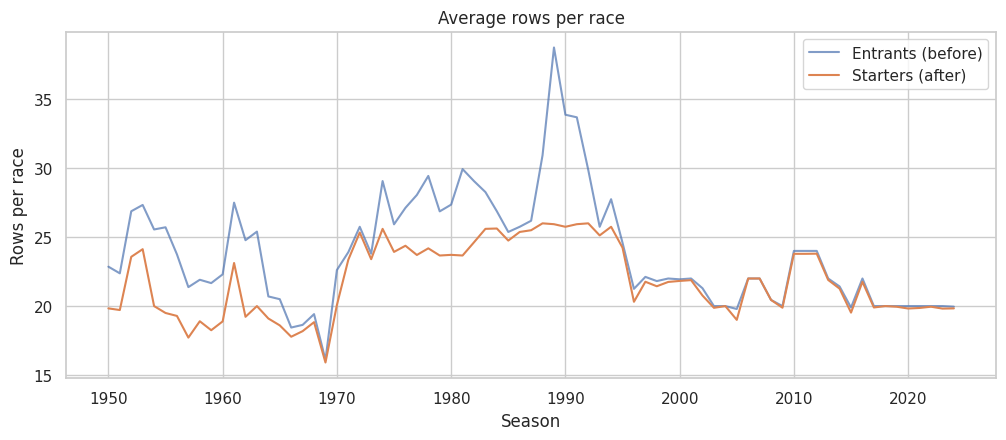

In [41]:
per_race_before = eda_before.groupby(["year", "raceId"]).size().groupby("year").mean()
per_race_after  = eda_after.groupby(["year", "raceId"]).size().groupby("year").mean()

plt.figure(figsize=(12, 4.5))
plt.plot(per_race_before, label="Entrants (before)", alpha=0.7)
plt.plot(per_race_after,  label="Starters (after)")
plt.title("Average rows per race")
plt.xlabel("Season")
plt.ylabel("Rows per race")
plt.legend()
save_fig("3_2_rows_per_race_before_after")
plt.show()

Distribution of grid positions, and the podium rate by grid slot after cleaning.

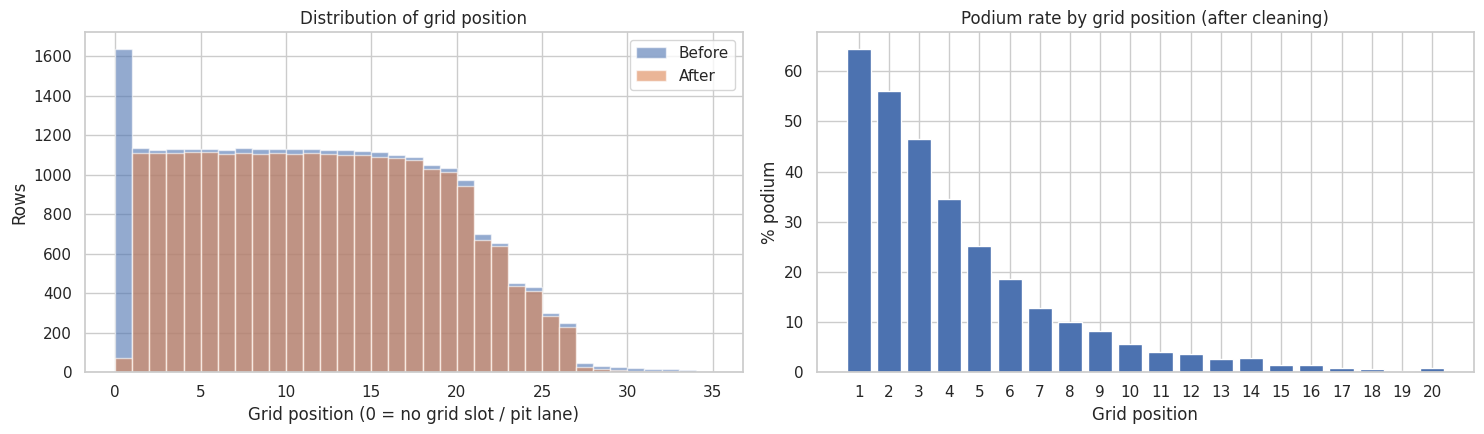

grid = 0 rows before: 1638 | after: 72 (real pit-lane starters)


In [42]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

axes[0].hist(eda_before["grid"], bins=range(0, 36), alpha=0.6, label="Before")
axes[0].hist(eda_after["grid"],  bins=range(0, 36), alpha=0.6, label="After")
axes[0].set_title("Distribution of grid position")
axes[0].set_xlabel("Grid position (0 = no grid slot / pit lane)")
axes[0].set_ylabel("Rows")
axes[0].legend()

grid_rate_after = eda_after[eda_after["grid"].between(1, 20)].groupby("grid")["podium"].mean() * 100
axes[1].bar(grid_rate_after.index, grid_rate_after.values)
axes[1].set_title("Podium rate by grid position (after cleaning)")
axes[1].set_xlabel("Grid position")
axes[1].set_ylabel("% podium")
axes[1].set_xticks(grid_rate_after.index)

plt.tight_layout()
save_fig("3_2_grid_before_after")
plt.show()

print(f"grid = 0 rows before: {(eda_before['grid'] == 0).sum()} | after: {(eda_after['grid'] == 0).sum()} (real pit-lane starters)")

Share of missing values in selected `results` columns, before and after.

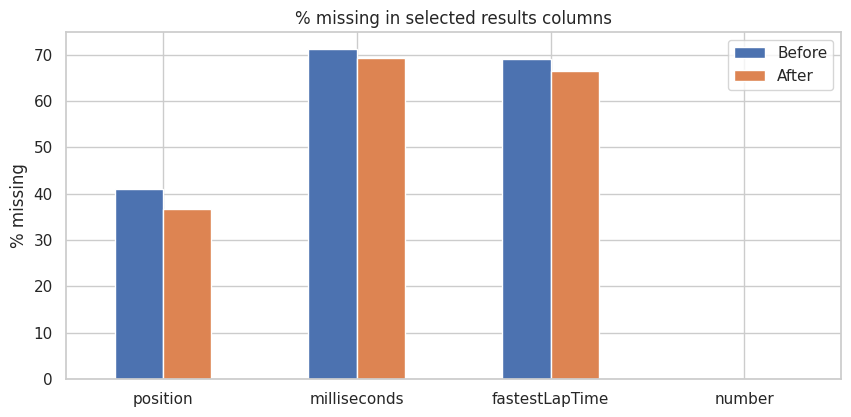

,Before,After
position,40.9,36.7
milliseconds,71.3,69.2
fastestLapTime,69.2,66.4
number,0.0,0.0


In [43]:
cols = ["position", "milliseconds", "fastestLapTime", "number"]
miss = pd.DataFrame({
    "Before": eda_before[cols].isna().mean() * 100,
    "After":  eda_after[cols].isna().mean() * 100,
})

miss.plot(kind="bar", figsize=(10, 4.5))
plt.title("% missing in selected results columns")
plt.ylabel("% missing")
plt.xticks(rotation=0)
save_fig("3_2_missingness_before_after")
plt.show()
miss.round(1)

**Findings.** After cleaning, field size reflects the cars that actually started (about 25–26 per race in the late 1980s, about 20 today), which makes it a meaningful context feature. The spike at `grid = 0` disappears: 1,638 rows before, 72 genuine pit-lane starters after. The grid–podium relationship is unchanged by cleaning. `position` is missing less often (40.9% → 36.7%) because part of the unclassified rows were non-starters; post-race columns stay largely missing, which does not matter because they are never features.

## 3.3 Newly typed columns and overall impact

Distributions that only became computable after semantic typing: Q1 lap times, pit-stop durations and driver age on race day.

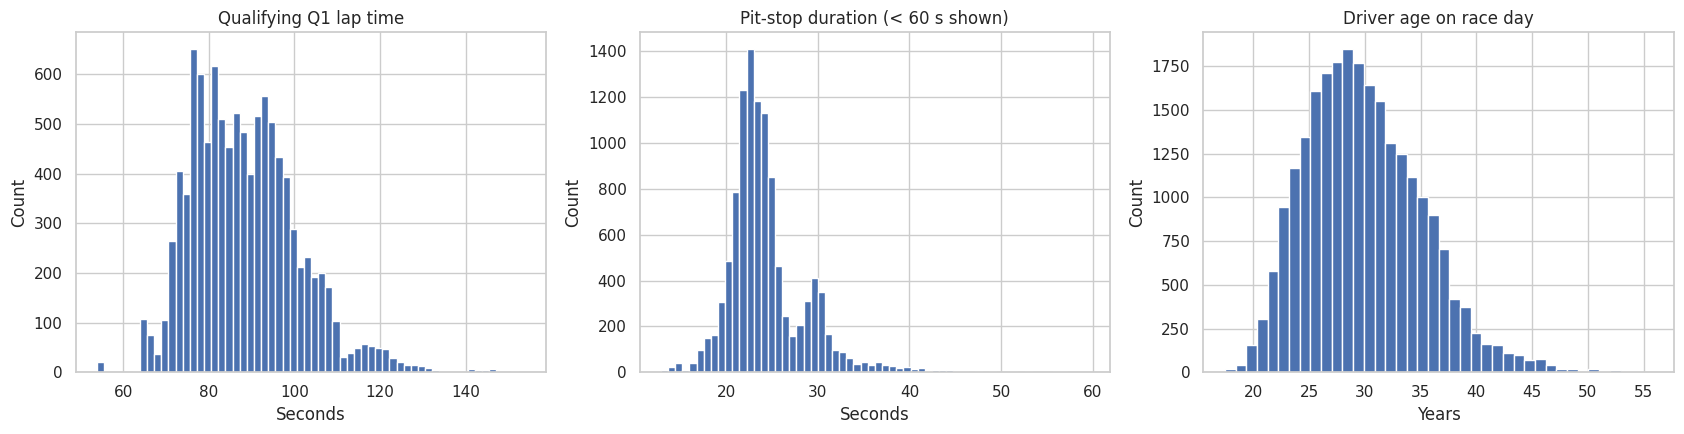

Pit stops longer than 60 s (red flags / repairs): 517


In [44]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].hist(clean["qualifying"]["q1"].dropna(), bins=60)
axes[0].set_title("Qualifying Q1 lap time")
axes[0].set_xlabel("Seconds")

pit = clean["pit_stops"]["duration"]
axes[1].hist(pit[pit < 60], bins=60)
axes[1].set_title("Pit-stop duration (< 60 s shown)")
axes[1].set_xlabel("Seconds")

ages = eda_after.merge(clean["drivers"][["driverId", "dob"]], on="driverId")
ages = (ages["date"] - ages["dob"]).dt.days / 365.25
axes[2].hist(ages.dropna(), bins=40)
axes[2].set_title("Driver age on race day")
axes[2].set_xlabel("Years")

for ax in axes:
    ax.set_ylabel("Count")
plt.tight_layout()
save_fig("3_3_typed_columns")
plt.show()

print(f"Pit stops longer than 60 s (red flags / repairs): {(pit >= 60).sum()}")

Summary of the backbone before and after cleaning.

In [45]:
def summarise(df):
    return {
        "rows": len(df),
        "races": df["raceId"].nunique(),
        "drivers": df["driverId"].nunique(),
        "seasons": df["year"].nunique(),
        "podium rate (%)": round(df["podium"].mean() * 100, 2),
        "duplicate (raceId, driverId)": int(df.duplicated(["raceId", "driverId"]).sum()),
        "rows with grid = 0": int((df["grid"] == 0).sum()),
        "% position missing": round(df["position"].isna().mean() * 100, 1),
    }

impact = pd.DataFrame({"Before cleaning": summarise(eda_before), "After cleaning": summarise(eda_after)})
impact = impact.apply(lambda col: col.map(lambda v: f"{v:g}"))   # display 26519 instead of 26519.00
impact

,Before cleaning,After cleaning
rows,26759,24551
races,1125,1114
drivers,861,681
seasons,75,75
podium rate (%),12.69,13.64
"duplicate (raceId, driverId)",91,0
rows with grid = 0,1638,72
% position missing,40.9,36.7


**Findings.** Q1 times cluster between about 1 and 2 minutes, pit stops peak at 20–25 s (517 stops, about 4.5%, last over a minute: red flags or repairs), and driver age is now computable, a candidate experience feature. Overall the backbone keeps 24,551 of 26,759 rows (1,114 races, 681 drivers, all 75 seasons) with the required grain and correct types. **Still open:** the qualifying-coverage gap (1.3), which cleaning cannot fix and which is handled in Section 5.

<a id="4"></a>
# 4. Answering the Data-Engineering Questions

Each question needs **multi-hop joins**: `results` alone has no season, circuit, country, nationality, team name or retirement reason. Every answer gives the result, a plot, and a note on **grain**, **missingness** and the **pre-race cutoff**. All three use `results_clean` (one row per driver per race, real starts only, Indy 500 excluded).

> These questions use post-race columns (`positionOrder`, `status`) as the *outcome* being studied, which is fine for analysis. They are **not** model features.

| Joined table | Join key | Adds | Needed for |
|---|---|---|---|
| `races` | `raceId` | `year`, `round`, `circuitId`, `date` | all three |
| `circuits` | `circuitId` (via races) | circuit name, `country` | Q1, Q2 |
| `drivers` | `driverId` | `nationality` | Q2 |
| `constructors` | `constructorId` | team name | Q3 |
| `status` | `statusId` | why the race ended | Q3 |
| `qualifying` | `raceId` + `driverId` | qualifying position | Q1 |

Join the backbone to the six tables once (left joins), assert that no row was added or lost, and measure the missingness the joins introduce.

In [46]:
from scipy.stats import spearmanr
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.contingency_tables import StratifiedTable
import statsmodels.formula.api as smf

quali_pos = clean["qualifying"][["raceId", "driverId", "position"]].rename(columns={"position": "quali_position"})

de = (
    results_clean
    .merge(clean["races"][["raceId", "year", "round", "circuitId", "date"]], on="raceId", how="left")
    .merge(clean["circuits"][["circuitId", "name", "country"]].rename(columns={"name": "circuit"}), on="circuitId", how="left")
    .merge(clean["drivers"][["driverId", "nationality"]], on="driverId", how="left")
    .merge(clean["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor"}), on="constructorId", how="left")
    .merge(clean["status"], on="statusId", how="left")
    .merge(quali_pos, on=["raceId", "driverId"], how="left")
)
de["podium"] = (de["positionOrder"] <= 3).astype(int)

# The joins must not add or lose rows, and must keep the grain
assert len(de) == len(results_clean), "a join changed the number of rows"
assert not de.duplicated(["raceId", "driverId"]).any(), "a join broke the (raceId, driverId) grain"

print("Analysis table:", de.shape)
display(de[["year", "circuit", "country", "driverId", "nationality", "constructor", "grid", "quali_position", "positionOrder", "status", "podium"]].head())

# Missingness introduced by the joins (a missing value here means the key had no match)
join_missing = de[["year", "circuit", "country", "nationality", "constructor", "status", "quali_position"]].isna().mean().mul(100).round(2)
join_missing.to_frame("% missing after join")

Analysis table: (24551, 29)


,year,circuit,country,driverId,nationality,constructor,grid,quali_position,positionOrder,status,podium
0,2009,Albert Park Grand Prix Circuit,Australia,18,British,Brawn,1,1.0,1,Finished,1
1,2009,Albert Park Grand Prix Circuit,Australia,22,Brazilian,Brawn,2,2.0,2,Finished,1
2,2009,Albert Park Grand Prix Circuit,Australia,15,Italian,Toyota,20,8.0,3,Finished,1
3,2009,Albert Park Grand Prix Circuit,Australia,10,German,Toyota,19,6.0,4,Finished,0
4,2009,Albert Park Grand Prix Circuit,Australia,4,Spanish,Renault,10,12.0,5,Finished,0


,% missing after join
year,0.00
circuit,0.00
country,0.00
nationality,0.00
constructor,0.00
status,0.00
quali_position,57.59


**Findings.** The joined table keeps exactly 24,551 rows and the `(raceId, driverId)` grain. Season, circuit, nationality, team and status are never missing (0 orphans, 2.2). Only `quali_position` is missing (57.6%), because qualifying is recorded only from 1994 and is patchy in 1996–2002 (1.3).

## 4.1 Q1 — Which circuits convert a front-row start into a podium most often, and does the ranking change after 2014?

**Definitions.** *Front row by grid*: `grid` is 1 or 2 (where the car actually started, after penalties). *Front row by qualifying*: qualifying position 1 or 2 (before penalties). *Conversion rate* = podiums by front-row starters ÷ front-row starts at that circuit.

**Windows.** 2003–2013 (pre-hybrid) vs 2014–2024 (hybrid and after): both are 11 seasons long, both have essentially complete qualifying data (so the two definitions can be compared on the same races), and both are modern-reliability eras. A full-history comparison is kept as a robustness check.

**Minimum sample.** A circuit is ranked only with **at least 10 front-row starts** (5 races) in a window, and every rate has a 95% Wilson confidence interval.

Select 2003–2024 and flag front-row starts under both definitions.

In [47]:
PRE_WINDOW, POST_WINDOW = (2003, 2013), (2014, 2024)
PRE_LABEL, POST_LABEL = "2003–2013 (pre-hybrid)", "2014–2024 (hybrid & after)"
MIN_FRONT_ROW_STARTS = 10

q1 = de[de["year"].between(PRE_WINDOW[0], POST_WINDOW[1])].copy()
q1["window"] = np.where(q1["year"] >= HYBRID_START, POST_LABEL, PRE_LABEL)
q1["front_row_grid"]  = q1["grid"].isin([1, 2])
q1["front_row_quali"] = q1["quali_position"].isin([1, 2])

print(f"Rows 2003–2024: {len(q1)} | races: {q1['raceId'].nunique()} | circuits: {q1['circuit'].nunique()}")
print(f"Rows without a qualifying record in this window: {q1['quali_position'].isna().sum()} ({q1['quali_position'].isna().mean():.1%})")
print(f"Grid front-row starts with no qualifying record: {(q1['front_row_grid'] & q1['quali_position'].isna()).sum()}")

Rows 2003–2024: 8905 | races: 428 | circuits: 38
Rows without a qualifying record in this window: 21 (0.2%)
Grid front-row starts with no qualifying record: 0


How often do the grid and qualifying definitions disagree, how many disagreements come from 2021–22 sprint weekends (where the sprint set the grid), and how do the mismatched drivers do?

In [48]:
sprint_race_ids = set(clean["sprint_results"]["raceId"])
q1["sprint_set_grid"] = q1["raceId"].isin(sprint_race_ids) & q1["year"].between(2021, 2022)

agree = pd.crosstab(q1["front_row_quali"], q1["front_row_grid"],
                    rownames=["front row by qualifying"], colnames=["front row by grid"])
display(agree)

q_only = q1[q1["front_row_quali"] & ~q1["front_row_grid"]]   # qualified P1/P2 but started further back
g_only = q1[q1["front_row_grid"] & ~q1["front_row_quali"]]   # promoted onto the front row

mismatch = pd.DataFrame([
    {"case": "qualified front row, started elsewhere", "rows": len(q_only),
     "of which 2021–22 sprint weekends": int(q_only["sprint_set_grid"].sum()), "podium rate (%)": round(q_only["podium"].mean() * 100, 1)},
    {"case": "started front row, qualified elsewhere", "rows": len(g_only),
     "of which 2021–22 sprint weekends": int(g_only["sprint_set_grid"].sum()), "podium rate (%)": round(g_only["podium"].mean() * 100, 1)},
]).set_index("case")
display(mismatch)

example = q_only.sort_values("year", ascending=False)[["year", "circuit", "driverId", "constructor", "quali_position", "grid", "positionOrder", "sprint_set_grid"]].head(8)
example

front row by grid,False,True
front row by qualifying,,
False,8018,36
True,36,815


,rows,of which 2021–22 sprint weekends,podium rate (%)
case,,,
"qualified front row, started elsewhere",36,5,30.6
"started front row, qualified elsewhere",36,5,63.9


,year,circuit,driverId,constructor,quali_position,grid,positionOrder,sprint_set_grid
24336,2024,Circuit de Spa-Francorchamps,830,Red Bull,1.0,11,4,False
24197,2024,Autodromo Enzo e Dino Ferrari,857,McLaren,2.0,5,4,False
23665,2023,Jeddah Corniche Circuit,844,Ferrari,2.0,12,7,False
23793,2023,Circuit Gilles Villeneuve,807,Haas F1 Team,2.0,5,15,False
24040,2023,Las Vegas Strip Street Circuit,832,Ferrari,2.0,12,6,False
23859,2023,Circuit de Spa-Francorchamps,830,Red Bull,1.0,6,1,False
23604,2022,Autódromo José Carlos Pace,830,Red Bull,2.0,3,6,True
23499,2022,Autodromo Nazionale di Monza,830,Red Bull,2.0,7,1,False


Overall front-row conversion per definition and window.

In [49]:
# Overall front-row conversion by definition and window
overall = pd.DataFrame([
    {"window": w, "definition": definition, "front-row starts": len(g), "podium rate (%)": round(g["podium"].mean() * 100, 1)}
    for definition, flag in [("grid", "front_row_grid"), ("qualifying", "front_row_quali")]
    for w, g in q1[q1[flag]].groupby("window")
]).pivot(index="window", columns="definition", values=["front-row starts", "podium rate (%)"])
overall["front-row starts"] = overall["front-row starts"].astype(int)
overall

front-row starts            podium rate (%)           
definition                             grid qualifying            grid qualifying
window                                                                           
2003–2013 (pre-hybrid)                  398        398            68.3       67.6
2014–2024 (hybrid & after)              453        453            76.2       74.2

**Findings.** The two definitions agree for the vast majority of front-row starts: **815** drivers both qualified and started on the front row, while **36** qualified there but started further back and another **36** were promoted onto it. Only 5 of each group come from the 2021–22 sprint weekends, where the sprint set the grid; the rest come from **grid penalties** (and drivers excluded from qualifying).

The difference matters for the outcome. Drivers who *qualified* P1/P2 but started elsewhere reached the podium only **30.6%** of the time, while drivers *promoted* onto the front row reached it **63.9%** of the time, not far below the normal front-row rate (68–76%). **Where a car starts matters more than where it qualified**, which supports using `grid` as the main feature and `grid − qualifying position` as a penalty feature (Section 5).

Front-row conversion is also clearly **higher after 2014** under both definitions (grid: 68.3% → 76.2%; qualifying: 67.6% → 74.2%): in the hybrid era the front row was usually taken by a dominant, reliable car.

Conversion rate per circuit and window with Wilson CIs: number of eligible circuits, top-10 table and plot.

Circuits per window (all / with >= 10 front-row starts):


,all_circuits,eligible
window,,
2003–2013 (pre-hybrid),27,20
2014–2024 (hybrid & after),32,19


,2003–2013 (pre-hybrid) | circuit,2003–2013 (pre-hybrid) | conversion,2014–2024 (hybrid & after) | circuit,2014–2024 (hybrid & after) | conversion
rank,,,,
1,Circuit de Nevers Magny-Cours,91.7% (11/12),Circuit de Monaco,89.5% (17/19)
2,Istanbul Park,78.6% (11/14),Suzuka Circuit,88.9% (16/18)
3,Autodromo Nazionale di Monza,77.3% (17/22),Yas Marina Circuit,86.4% (19/22)
4,Circuit de Monaco,77.3% (17/22),Circuit de Barcelona-Catalunya,81.8% (18/22)
5,Silverstone Circuit,72.7% (16/22),Circuit de Spa-Francorchamps,81.8% (18/22)
6,Circuit de Spa-Francorchamps,72.2% (13/18),Sochi Autodrom,81.2% (13/16)
7,Suzuka Circuit,72.2% (13/18),Circuit of the Americas,80.0% (16/20)
8,Hockenheimring,71.4% (10/14),Autódromo José Carlos Pace,78.9% (15/19)
9,Circuit de Barcelona-Catalunya,68.2% (15/22),Shanghai International Circuit,78.6% (11/14)


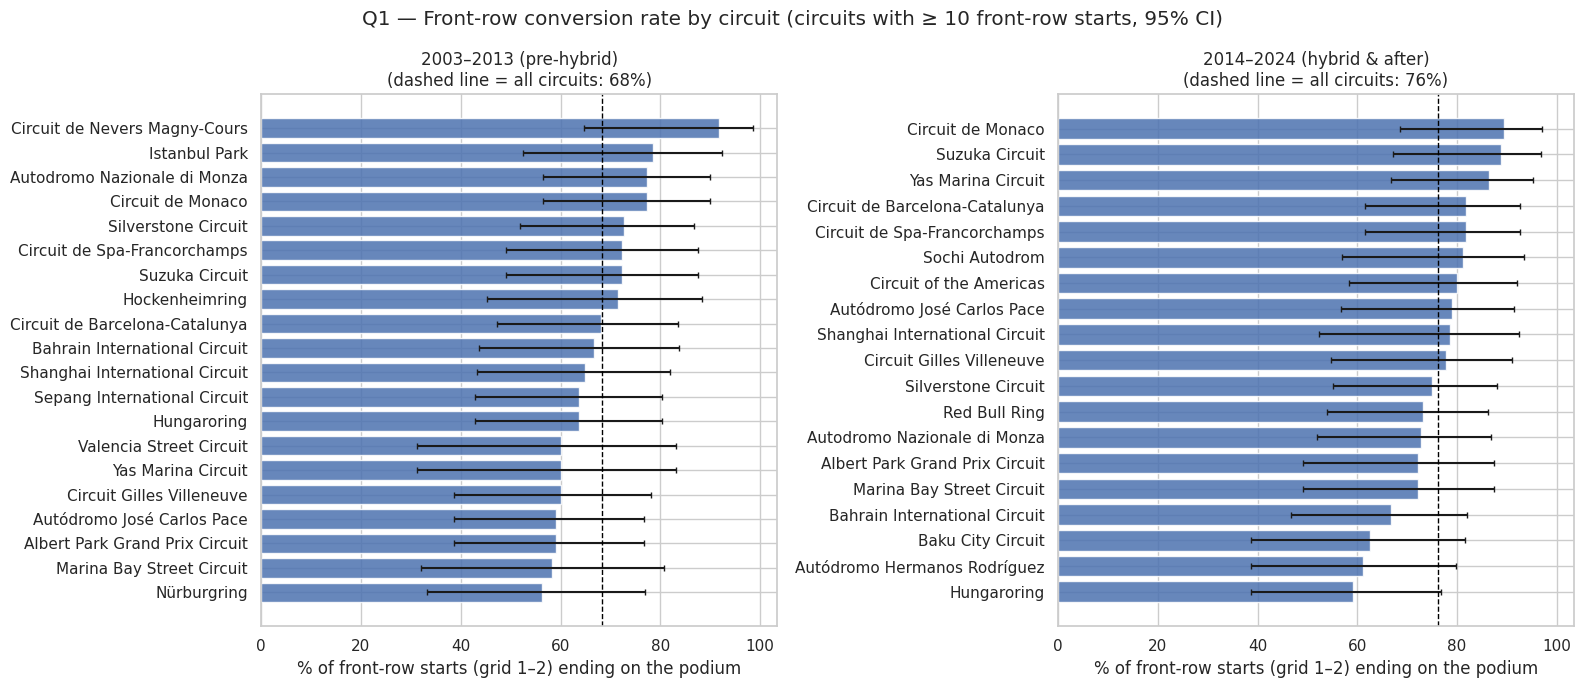

In [50]:
def conversion_by_circuit(df, flag):
    # podiums / front-row starts per (window, circuit), with a 95% Wilson confidence interval
    g = (df[df[flag]]
         .groupby(["window", "circuit"])["podium"]
         .agg(front_row_starts="size", podiums="sum")
         .reset_index())
    g["rate"] = g["podiums"] / g["front_row_starts"]
    g["ci_low"], g["ci_high"] = proportion_confint(g["podiums"], g["front_row_starts"], alpha=0.05, method="wilson")
    g["eligible"] = g["front_row_starts"] >= MIN_FRONT_ROW_STARTS
    return g

conv_grid = conversion_by_circuit(q1, "front_row_grid")
print("Circuits per window (all / with >= 10 front-row starts):")
display(conv_grid.groupby("window")["eligible"].agg(all_circuits="size", eligible="sum"))

def top_table(conv, n=10):
    rows = []
    for w in [PRE_LABEL, POST_LABEL]:
        t = conv[(conv["window"] == w) & conv["eligible"]].sort_values(["rate", "front_row_starts"], ascending=False).head(n)
        t = t.assign(rank=range(1, len(t) + 1),
                     conversion=lambda d: (d["rate"] * 100).round(1).astype(str) + "% (" + d["podiums"].astype(str) + "/" + d["front_row_starts"].astype(str) + ")")
        rows.append(t.set_index("rank")[["circuit", "conversion"]].add_prefix(w + " | "))
    return pd.concat(rows, axis=1).fillna("")

display(top_table(conv_grid))

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharex=True)

for ax, w in zip(axes, [PRE_LABEL, POST_LABEL]):
    t = conv_grid[(conv_grid["window"] == w) & conv_grid["eligible"]].sort_values("rate")
    err = [(t["rate"] - t["ci_low"]) * 100, (t["ci_high"] - t["rate"]) * 100]
    ax.barh(t["circuit"], t["rate"] * 100, xerr=err, capsize=2, alpha=0.85)
    overall_rate = q1.loc[q1["front_row_grid"] & (q1["window"] == w), "podium"].mean() * 100
    ax.axvline(overall_rate, color="black", linestyle="--", linewidth=1)
    ax.set_title(f"{w}\n(dashed line = all circuits: {overall_rate:.0f}%)")
    ax.set_xlabel("% of front-row starts (grid 1–2) ending on the podium")

fig.suptitle("Q1 — Front-row conversion rate by circuit (circuits with ≥ 10 front-row starts, 95% CI)")
plt.tight_layout()
save_fig("4_1_conversion_by_circuit")
plt.show()

**Findings.** **2003–2013:** the top converters are Magny-Cours (11 of 12), Istanbul Park (11 of 14), and Monza and Monaco (both 17 of 22). Magny-Cours is based on only 6 races, so its wide confidence interval matters.
**2014–2024:** Monaco (17 of 19, 89.5%), Suzuka (16 of 18, 88.9%) and Yas Marina (19 of 22, 86.4%) lead, followed by Barcelona and Spa (both 18 of 22, 81.8%).

The confidence intervals are **wide** (often ±15–20 percentage points) because each circuit has only about 10–22 front-row starts per window. Neighbouring circuits in the ranking are therefore **not statistically different**; only the gap between the top and the bottom of each table is clear.

Rank the circuits eligible in both windows, compare the two rankings with Spearman's ρ (1 = same order, 0 = unrelated), plot the rank changes, and list circuits ranked in only one window.

Circuits eligible in both windows: 14
Spearman rank correlation pre vs post 2014: rho = 0.36 (p = 0.211)


window,rank pre,rank post,rate pre,rate post,rank change
circuit,,,,,
Circuit de Monaco,1,1,77.0,89.0,0
Suzuka Circuit,4,2,72.0,89.0,2
Yas Marina Circuit,10,3,60.0,86.0,7
Circuit de Barcelona-Catalunya,6,4,68.0,82.0,2
Circuit de Spa-Francorchamps,4,4,72.0,82.0,0
Autódromo José Carlos Pace,12,6,59.0,79.0,6
Shanghai International Circuit,8,7,65.0,79.0,1
Circuit Gilles Villeneuve,10,8,60.0,78.0,2
Silverstone Circuit,3,9,73.0,75.0,-6


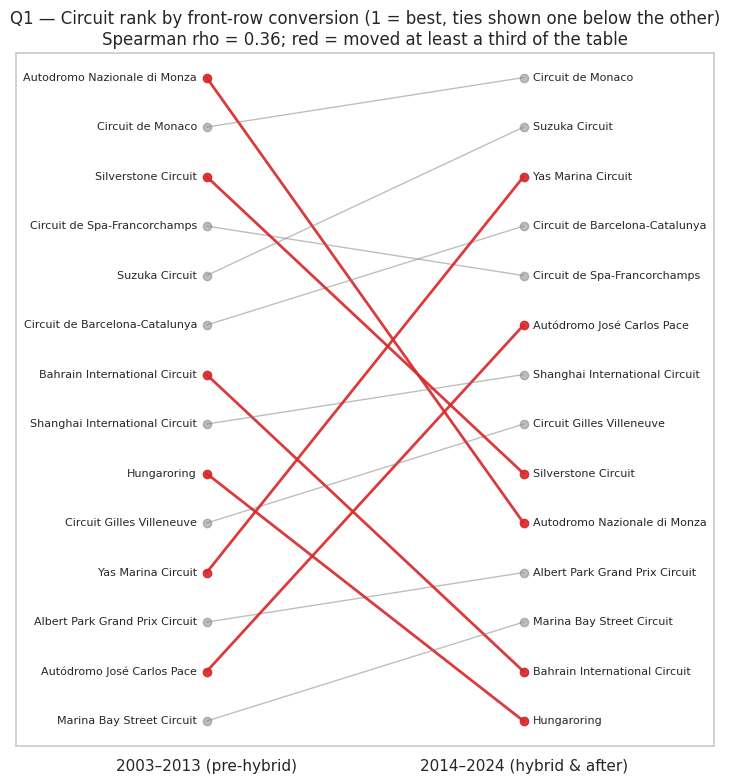

Only ranked pre-2014:  ['Circuit de Nevers Magny-Cours', 'Hockenheimring', 'Istanbul Park', 'Nürburgring', 'Sepang International Circuit', 'Valencia Street Circuit']
Only ranked post-2014: ['Autódromo Hermanos Rodríguez', 'Baku City Circuit', 'Circuit of the Americas', 'Red Bull Ring', 'Sochi Autodrom']


In [51]:
def compare_windows(conv):
    wide = conv[conv["eligible"]].pivot(index="circuit", columns="window", values="rate").dropna()
    ranks = wide.rank(ascending=False, method="min").astype(int)
    rho, p = spearmanr(wide[PRE_LABEL], wide[POST_LABEL])
    return wide, ranks, rho, p

wide_grid, ranks_grid, rho_grid, p_grid = compare_windows(conv_grid)
print(f"Circuits eligible in both windows: {len(wide_grid)}")
print(f"Spearman rank correlation pre vs post 2014: rho = {rho_grid:.2f} (p = {p_grid:.3f})")

change = ranks_grid.rename(columns={PRE_LABEL: "rank pre", POST_LABEL: "rank post"})
change["rate pre"]  = (wide_grid[PRE_LABEL] * 100).round(0)
change["rate post"] = (wide_grid[POST_LABEL] * 100).round(0)
change["rank change"] = change["rank pre"] - change["rank post"]   # positive = moved up after 2014
display(change.sort_values("rank post"))

# Plot positions: ties (equal rates) are broken by order of appearance so labels do not overlap
positions = wide_grid.rank(ascending=False, method="first").astype(int)

fig, ax = plt.subplots(figsize=(9, 9))
n = len(positions)
for circuit, row in positions.iterrows():
    moved = abs(row[PRE_LABEL] - row[POST_LABEL]) >= n / 3
    ax.plot([0, 1], [row[PRE_LABEL], row[POST_LABEL]], marker="o",
            color="tab:red" if moved else "tab:gray", alpha=0.9 if moved else 0.5, linewidth=2 if moved else 1)
    ax.text(-0.03, row[PRE_LABEL], circuit, ha="right", va="center", fontsize=8)
    ax.text(1.03, row[POST_LABEL], circuit, ha="left", va="center", fontsize=8)

ax.set_xlim(-0.6, 1.6)
ax.set_ylim(n + 0.5, 0.5)
ax.set_xticks([0, 1])
ax.set_xticklabels([PRE_LABEL, POST_LABEL])
ax.set_yticks([])
ax.set_title(f"Q1 — Circuit rank by front-row conversion (1 = best, ties shown one below the other)\nSpearman rho = {rho_grid:.2f}; red = moved at least a third of the table")
ax.grid(False)
save_fig("4_1_rank_change")
plt.show()

# Circuits that are only ranked in one window (new or dropped from the calendar)
eligible_sets = conv_grid[conv_grid["eligible"]].groupby("window")["circuit"].apply(set)
print("Only ranked pre-2014: ", sorted(eligible_sets[PRE_LABEL] - eligible_sets[POST_LABEL]))
print("Only ranked post-2014:", sorted(eligible_sets[POST_LABEL] - eligible_sets[PRE_LABEL]))

**Findings.** The ranking is only **weakly preserved** across 2014. For the 14 circuits ranked in both windows, Spearman's ρ = **0.36** (p = 0.21): a weak positive relationship that is not statistically significant, so the pre-2014 order is a poor guide to the post-2014 order. Notable moves:
- **Monza** fell from joint 1st to 10th; **Silverstone** (3rd → 9th), **Bahrain** (7th → 13th) and the **Hungaroring** (9th → 14th, last) also dropped.
- **Yas Marina** rose from 10th to 3rd and **Interlagos** from 12th to 6th.
- **Monaco** stayed 1st and **Suzuka** moved from 4th to 2nd. Monaco is the circuit where overtaking is hardest, so a front-row car rarely loses its place.

The calendar also changed: 6 circuits are ranked only before 2014 (e.g. Magny-Cours, Istanbul, Sepang) and 5 only after (e.g. COTA, Sochi, Baku), so part of the "ranking" is simply which circuits were raced.

Repeat with the qualifying definition, and measure how closely it agrees with the grid definition within each window.

In [52]:
conv_quali = conversion_by_circuit(q1, "front_row_quali")
wide_quali, ranks_quali, rho_quali, p_quali = compare_windows(conv_quali)

# Agreement between the two definitions within each window
agreement = []
for w in [PRE_LABEL, POST_LABEL]:
    a = conv_grid[(conv_grid["window"] == w) & conv_grid["eligible"]].set_index("circuit")["rate"]
    b = conv_quali[(conv_quali["window"] == w) & conv_quali["eligible"]].set_index("circuit")["rate"]
    common = a.index.intersection(b.index)
    rho, _ = spearmanr(a[common], b[common])
    agreement.append({"window": w, "circuits": len(common), "Spearman rho grid vs qualifying": round(rho, 2),
                      "same #1 circuit": a[common].idxmax() == b[common].idxmax(),
                      "mean |rate difference| (pp)": round((a[common] - b[common]).abs().mean() * 100, 1)})
agreement = pd.DataFrame(agreement)
print(f"Qualifying definition, pre vs post 2014: Spearman rho = {rho_quali:.2f} (p = {p_quali:.3f}), {len(wide_quali)} circuits")
display(agreement)

top_table(conv_quali, n=5)

Qualifying definition, pre vs post 2014: Spearman rho = 0.54 (p = 0.047), 14 circuits


,window,circuits,Spearman rho grid vs qualifying,same #1 circuit,mean |rate difference| (pp)
0,2003–2013 (pre-hybrid),20,0.94,True,1.6
1,2014–2024 (hybrid & after),19,0.90,True,2.2


,2003–2013 (pre-hybrid) | circuit,2003–2013 (pre-hybrid) | conversion,2014–2024 (hybrid & after) | circuit,2014–2024 (hybrid & after) | conversion
rank,,,,
1,Circuit de Nevers Magny-Cours,91.7% (11/12),Circuit de Monaco,89.5% (17/19)
2,Istanbul Park,78.6% (11/14),Suzuka Circuit,88.9% (16/18)
3,Silverstone Circuit,77.3% (17/22),Circuit de Barcelona-Catalunya,81.8% (18/22)
4,Autodromo Nazionale di Monza,72.7% (16/22),Circuit de Spa-Francorchamps,81.8% (18/22)
5,Circuit de Spa-Francorchamps,72.2% (13/18),Yas Marina Circuit,81.8% (18/22)


Grid vs qualifying definition, circuit by circuit: each point is one circuit, x = conversion with the grid definition, y = with the qualifying definition. Points on the dashed line convert equally under both definitions.

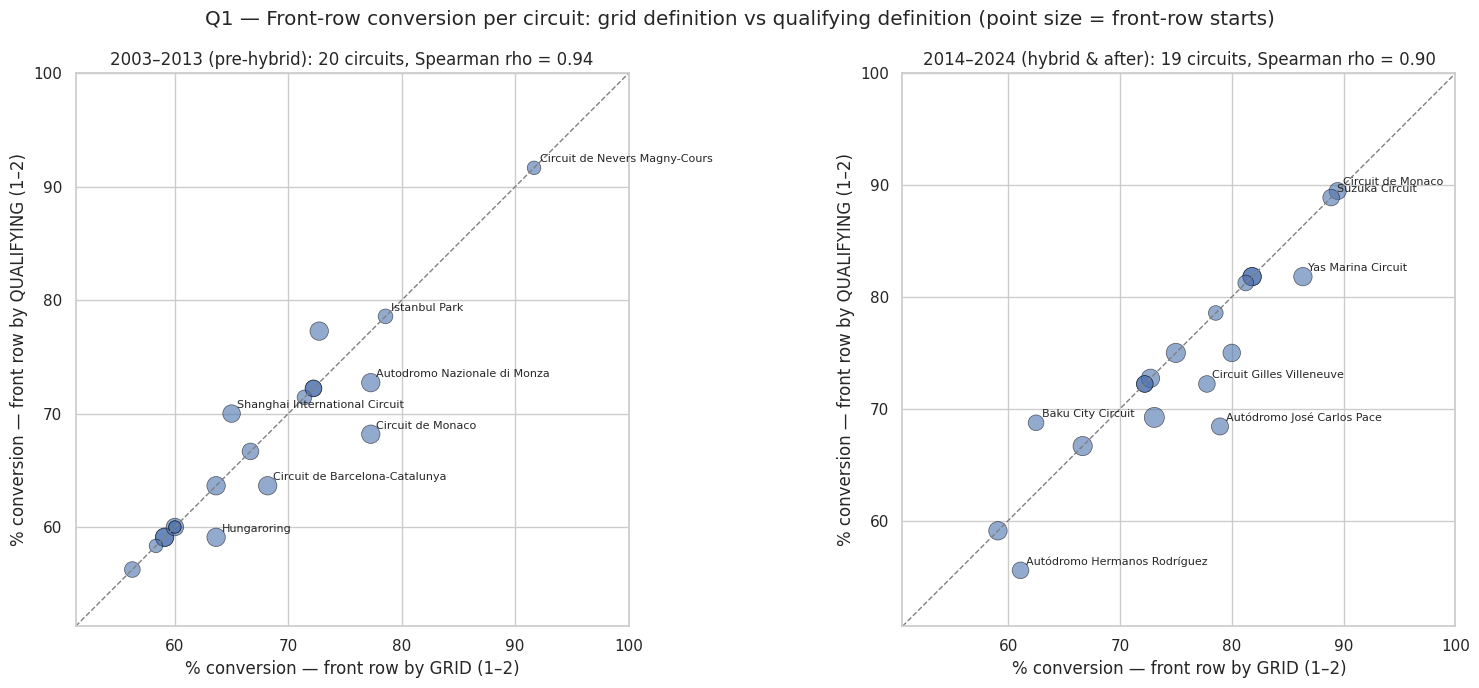

In [53]:
# ---- Q1: grid vs qualifying definition per circuit (circuits eligible under both definitions) ----
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, w in zip(axes, [PRE_LABEL, POST_LABEL]):
    a = conv_grid[(conv_grid["window"] == w) & conv_grid["eligible"]].set_index("circuit")
    b = conv_quali[(conv_quali["window"] == w) & conv_quali["eligible"]].set_index("circuit")
    common = a.index.intersection(b.index)
    x, y = a.loc[common, "rate"] * 100, b.loc[common, "rate"] * 100
    ax.scatter(x, y, s=a.loc[common, "front_row_starts"] * 8, alpha=0.6, edgecolor="black", linewidth=0.5)
    lo, hi = min(x.min(), y.min()) - 5, 100
    ax.plot([lo, hi], [lo, hi], "--", color="gray", linewidth=1)
    # label the circuits where the two definitions differ most, and the top converters
    label = set((y - x).abs().sort_values(ascending=False).index[:4]) | set(x.sort_values(ascending=False).index[:3])
    for c in label:
        ax.annotate(c, (x[c], y[c]), xytext=(4, 4), textcoords="offset points", fontsize=8)
    rho = agreement.set_index("window").loc[w, "Spearman rho grid vs qualifying"]
    ax.set(xlim=(lo, hi), ylim=(lo, hi), xlabel="% conversion — front row by GRID (1–2)",
           ylabel="% conversion — front row by QUALIFYING (1–2)",
           title=f"{w}: {len(common)} circuits, Spearman rho = {rho:.2f}")
    ax.set_aspect("equal")
fig.suptitle("Q1 — Front-row conversion per circuit: grid definition vs qualifying definition (point size = front-row starts)")
plt.tight_layout()
save_fig("4_1_grid_vs_quali_by_circuit")
plt.show()

**Findings.** Within each window, rankings by the qualifying definition are almost identical to the grid rankings (Spearman ρ = **0.94** before 2014 and **0.90** after, with an average difference of 1.6–2.2 percentage points per circuit), and the #1 circuit is the same under both definitions (Magny-Cours before 2014, Monaco after).

Across 2014, the qualifying definition gives a somewhat **stronger** correlation (ρ = **0.54**, p = 0.047, just below 0.05) than the grid definition (ρ = 0.36, p = 0.21). With only 14 circuits, both point to the same picture: **the top of the table (Monaco, Suzuka, Spa) is fairly stable, while the middle and bottom reshuffle substantially.** Because the strength of the correlation depends on the definition, we do not claim that the two eras' rankings are unrelated, only that they differ noticeably.

The scatter plot shows the same thing circuit by circuit: most circuits sit on or near the diagonal (14 of 20 before 2014 and 12 of 19 after are within 3 percentage points). The largest gaps come from one or two races with a grid penalty: **Monaco 2003–2013** (77% by grid vs 68% by qualifying) and **Interlagos 2014–2024** (79% vs 68%) convert better for the cars that actually *started* on the front row than for those that *qualified* there.


Robustness check: all seasons 1950–2013 vs 2014–2024 (grid definition, which is not limited by qualifying coverage).

In [54]:
q1_full = de.copy()
q1_full["window"] = np.where(q1_full["year"] >= HYBRID_START, POST_LABEL, PRE_LABEL)
q1_full["front_row_grid"] = q1_full["grid"].isin([1, 2])
conv_full = conversion_by_circuit(q1_full, "front_row_grid")
wide_full, ranks_full, rho_full, p_full = compare_windows(conv_full)

pre_full = q1_full.loc[q1_full["front_row_grid"] & (q1_full["window"] == PRE_LABEL), "podium"].mean()
print(f"All-seasons pre-2014 front-row conversion: {pre_full:.1%}")
print(f"Spearman 1950–2013 vs 2014–2024: rho = {rho_full:.2f} (p = {p_full:.3f}), {len(wide_full)} circuits")

All-seasons pre-2014 front-row conversion: 56.2%
Spearman 1950–2013 vs 2014–2024: rho = -0.08 (p = 0.759), 16 circuits


**Findings.** Using every season before 2014 does not change the conclusion: the correlation with the post-2014 ranking is about zero (ρ ≈ −0.08). Front-row conversion over 1950–2013 was only about **56%**, far below the ~76% after 2014. That reflects the low reliability of early cars (Section 1.4), so a full-history comparison mostly measures reliability rather than circuits, which is why 2003–2013 is the main comparison window.

---
**Answer to Q1.** In 2014–2024 the circuits that convert a front-row start into a podium most often are **Monaco (89.5%), Suzuka (88.9%) and Yas Marina (86.4%)**, followed by Barcelona and Spa (81.8%). In 2003–2013 the leaders were **Magny-Cours (91.7%, only 6 races), Istanbul Park (78.6%), and Monza and Monaco (77.3%)**.

**The ranking partly changes after 2014.** The rank correlation between the two windows is weak to moderate (grid definition ρ = 0.36, p = 0.21; qualifying definition ρ = 0.54, p = 0.047). Monaco stays at the top and Suzuka and Spa stay near it, but Monza falls from joint 1st to 10th, Silverstone, Bahrain and the Hungaroring drop, and Yas Marina and Interlagos climb. Overall conversion rises from 68.3% to 76.2%.

Using qualifying position instead of grid gives almost the same ranking within each window (ρ ≈ 0.9). Drivers demoted from the front row by a penalty convert far less often (30.6%, against 63.9% for drivers promoted onto it), so where the car starts matters more than where it qualified.

**Grain.** The unit is one front-row start (one driver in one race), aggregated to circuit × window. Circuits are identified by `circuitId`, so different Grand Prix names held at the same track (e.g. San Marino and Emilia Romagna GPs at Imola) are pooled, and layout changes at the same track are not separated.

**Missingness.** Qualifying is recorded for 99.8% of rows in 2003–2024 and for every grid front-row starter. Before 2003 qualifying is missing or patchy (Section 1.3), so the qualifying definition is only used from 2003. Circuits with fewer than 10 front-row starts in a window are not ranked, and all rates carry wide confidence intervals.

**Pre-race cutoff.** The groups are defined by `grid` and qualifying position, both known before the race, and the podium is the post-race outcome being studied. A circuit's *historical* front-row conversion rate, computed from previous races only, would be a valid pre-race feature.

## 4.2 Q2 — Do drivers podium more often at home, after controlling for starting position?

**Home race:** the circuit is in a country the driver's nationality belongs to. We use the circuit's country, not the race name, so the *European GP* at the Nürburgring counts as a German race. `drivers.nationality` is an adjective ("British") and `circuits.country` a country ("UK"), so we use a documented mapping: every nationality is mapped (including countries that never hosted a race), dual nationalities (*American-Italian*, *Argentine-Italian*) are home in both countries, *East German* maps to Germany, and circuit country "United States" is the same as "USA".

**Why control for starting position?** If home drivers start further forward or further back than other drivers, a raw comparison mostly measures that. We therefore compare home and away drivers **who started from similar grid positions**. Pit-lane starters have no grid slot to compare and are left out.

Map nationality → country, build the `is_home` flag, and show which nationalities contribute the home starts.

In [55]:
NATIONALITY_TO_COUNTRIES = {
    "American": ["USA"], "American-Italian": ["USA", "Italy"], "Argentine": ["Argentina"],
    "Argentine-Italian": ["Argentina", "Italy"], "Australian": ["Australia"], "Austrian": ["Austria"],
    "Belgian": ["Belgium"], "Brazilian": ["Brazil"], "British": ["UK"], "Canadian": ["Canada"],
    "Chilean": ["Chile"], "Chinese": ["China"], "Colombian": ["Colombia"], "Czech": ["Czech Republic"],
    "Danish": ["Denmark"], "Dutch": ["Netherlands"], "East German": ["Germany"], "Finnish": ["Finland"],
    "French": ["France"], "German": ["Germany"], "Hungarian": ["Hungary"], "Indian": ["India"],
    "Indonesian": ["Indonesia"], "Irish": ["Ireland"], "Italian": ["Italy"], "Japanese": ["Japan"],
    "Liechtensteiner": ["Liechtenstein"], "Malaysian": ["Malaysia"], "Mexican": ["Mexico"],
    "Monegasque": ["Monaco"], "New Zealander": ["New Zealand"], "Polish": ["Poland"],
    "Portuguese": ["Portugal"], "Rhodesian": ["Rhodesia"], "Russian": ["Russia"],
    "South African": ["South Africa"], "Spanish": ["Spain"], "Swedish": ["Sweden"], "Swiss": ["Switzerland"],
    "Thai": ["Thailand"], "Uruguayan": ["Uruguay"], "Venezuelan": ["Venezuela"],
}
COUNTRY_ALIASES = {"United States": "USA"}

unmapped = set(de["nationality"].dropna()) - set(NATIONALITY_TO_COUNTRIES)
assert not unmapped, f"Nationalities without a mapping: {unmapped}"

q2 = de.copy()
q2["circuit_country"] = q2["country"].replace(COUNTRY_ALIASES)
q2["is_home"] = [c in NATIONALITY_TO_COUNTRIES[n] for n, c in zip(q2["nationality"], q2["circuit_country"])]
q2["is_home"] = q2["is_home"].astype(int)

hosting = set(q2["circuit_country"])
never_home = sorted(n for n, cs in NATIONALITY_TO_COUNTRIES.items() if not set(cs) & hosting)
print(f"Home-race starts: {q2['is_home'].sum()} of {len(q2)} ({q2['is_home'].mean():.1%})")
print("Nationalities whose country never hosted a race (never 'home'):", never_home)

home_by_nat = (q2[q2["is_home"] == 1].groupby("nationality")
               .agg(home_starts=("is_home", "size"), drivers=("driverId", "nunique"), home_podiums=("podium", "sum"))
               .sort_values("home_starts", ascending=False))
home_by_nat.head(12)

Home-race starts: 1929 of 24551 (7.9%)
Nationalities whose country never hosted a race (never 'home'): ['Chilean', 'Colombian', 'Czech', 'Danish', 'Finnish', 'Indonesian', 'Irish', 'Liechtensteiner', 'New Zealander', 'Polish', 'Rhodesian', 'Thai', 'Uruguayan', 'Venezuelan']


,home_starts,drivers,home_podiums
nationality,,,
British,446,123,68
Italian,397,77,28
French,206,50,26
German,198,42,29
Brazilian,114,27,20
American,112,36,9
Spanish,60,11,9
Belgian,60,19,3
Japanese,53,17,2


Group grid positions into buckets and compare home vs away **without** any control: podium rate and where each group starts.

Pit-lane starters left out: 72 | rows used: 24479


,starts,podium_rate,mean_grid,median_grid
is_home,,,,
away,22551,13.85,11.683606,11.0
home,1928,11.72,12.656120,13.0


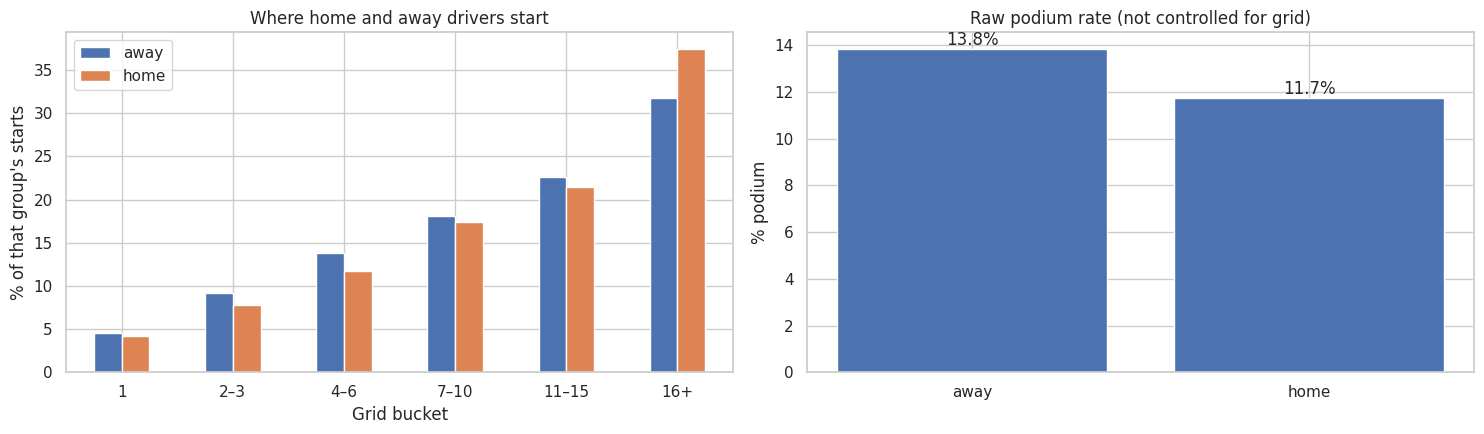

In [56]:
GRID_BINS   = [1, 2, 4, 7, 11, 16, np.inf]
GRID_LABELS = ["1", "2–3", "4–6", "7–10", "11–15", "16+"]

n_pitlane = (q2["grid"] == 0).sum()
q2 = q2[q2["grid"] > 0].copy()
q2["grid_bucket"] = pd.cut(q2["grid"], bins=GRID_BINS, labels=GRID_LABELS, right=False)
q2["decade"] = (q2["year"] // 10) * 10
print(f"Pit-lane starters left out: {n_pitlane} | rows used: {len(q2)}")

raw_cmp = q2.groupby("is_home").agg(starts=("podium", "size"), podium_rate=("podium", "mean"),
                                    mean_grid=("grid", "mean"), median_grid=("grid", "median"))
raw_cmp.index = raw_cmp.index.map({0: "away", 1: "home"})
raw_cmp["podium_rate"] = (raw_cmp["podium_rate"] * 100).round(2)
display(raw_cmp)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

share = pd.crosstab(q2["grid_bucket"], q2["is_home"], normalize="columns") * 100
share.columns = ["away", "home"]
share.plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("Where home and away drivers start")
axes[0].set_xlabel("Grid bucket")
axes[0].set_ylabel("% of that group's starts")

axes[1].bar(["away", "home"], raw_cmp["podium_rate"])
for i, v in enumerate(raw_cmp["podium_rate"]):
    axes[1].text(i, v, f"{v:.1f}%", ha="center", va="bottom")
axes[1].set_title("Raw podium rate (not controlled for grid)")
axes[1].set_ylabel("% podium")

plt.tight_layout()
save_fig("4_2_raw_home_vs_away")
plt.show()

**Findings.** Without any control, home drivers reach the podium **less** often than away drivers (11.7% vs 13.9%). But they also **start further back**: the median home starter starts 13th against 11th for away starters, and a larger share of home starts come from the back of the grid (16th or worse). Many home entries were one-off local drivers in their only race, typically in uncompetitive cars. A raw comparison therefore mixes the home effect with *where home drivers start*, which is why we must control for grid position.

Home vs away podium rate **within** each grid bucket, with 95% confidence intervals.

,starts (away),starts (home),podium_rate (away),podium_rate (home),difference (pp)
grid_bucket,,,,,
1,1030,80,64.8,61.3,-3.5
2–3,2069,150,51.1,54.0,2.9
4–6,3108,226,26.1,26.5,0.5
7–10,4093,335,9.4,7.2,-2.2
11–15,5092,414,3.0,2.4,-0.6
16+,7159,723,0.7,0.3,-0.5


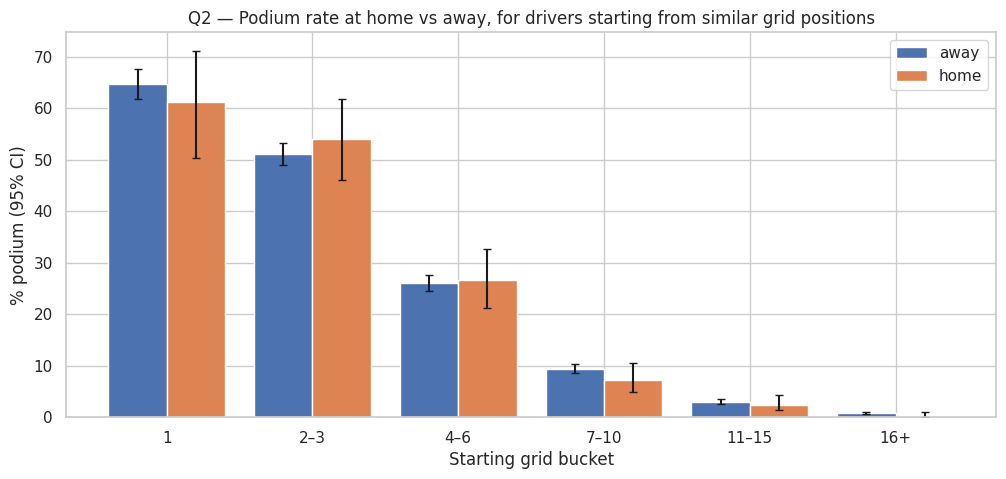

In [57]:
within = (q2.groupby(["grid_bucket", "is_home"], observed=True)["podium"]
            .agg(starts="size", podium_rate="mean").unstack("is_home"))
within.columns = [f"{m} ({'home' if h else 'away'})" for m, h in within.columns]
within["difference (pp)"] = (within["podium_rate (home)"] - within["podium_rate (away)"]) * 100
for c in ["podium_rate (away)", "podium_rate (home)"]:
    within[c] = (within[c] * 100).round(1)
within["difference (pp)"] = within["difference (pp)"].round(1)
display(within)

x = np.arange(len(GRID_LABELS))
fig, ax = plt.subplots(figsize=(12, 5))
for offset, h, label in [(-0.2, 0, "away"), (0.2, 1, "home")]:
    sub = q2[q2["is_home"] == h].groupby("grid_bucket", observed=False)["podium"]
    rate, n = sub.mean(), sub.size()
    lo, hi = proportion_confint(sub.sum(), n, method="wilson")
    ax.bar(x + offset, rate * 100, width=0.4, label=label,
           yerr=[(rate - lo) * 100, (hi - rate) * 100], capsize=3)
ax.set_xticks(x)
ax.set_xticklabels(GRID_LABELS)
ax.set_xlabel("Starting grid bucket")
ax.set_ylabel("% podium (95% CI)")
ax.set_title("Q2 — Podium rate at home vs away, for drivers starting from similar grid positions")
ax.legend()
save_fig("4_2_home_within_grid")
plt.show()

**Findings.** Once drivers who start from similar positions are compared, the gap almost disappears. Within each grid bucket the home-minus-away difference is small (between −3.5 and +2.9 percentage points) and **changes sign** from bucket to bucket, with no consistent advantage at home. The home samples are small (e.g. 80 home starts from pole), so the confidence intervals of home and away overlap in every bucket.

Pool the buckets into one answer in two ways: the **Cochran–Mantel–Haenszel** odds ratio (a 2×2 table per bucket, pooled; 1 = no home effect; the Breslow–Day test checks whether the effect is equal across buckets) and **logistic regression** `podium ~ is_home + grid + decade` (the decade term controls for era), also on 1980+ only as a robustness check.

CMH pooled odds ratio (home vs away): 0.93  95% CI [0.78, 1.10]
CMH test of 'no home effect':        p = 0.4074
Breslow–Day test of equal effect across buckets: p = 0.4582


,odds ratio,CI low,CI high,p-value,rows
Raw (no control),0.83,0.72,0.95,0.0092,24479.0
CMH (within grid buckets),0.93,0.78,1.10,0.4074,24479.0
Logit: + grid bucket + decade,0.92,0.78,1.10,0.3707,24479.0
Logit: + exact grid (1–20) + decade,0.94,0.79,1.12,0.4862,21733.0
"Logit: + grid bucket + decade, 1980+",0.92,0.73,1.15,0.4539,17700.0


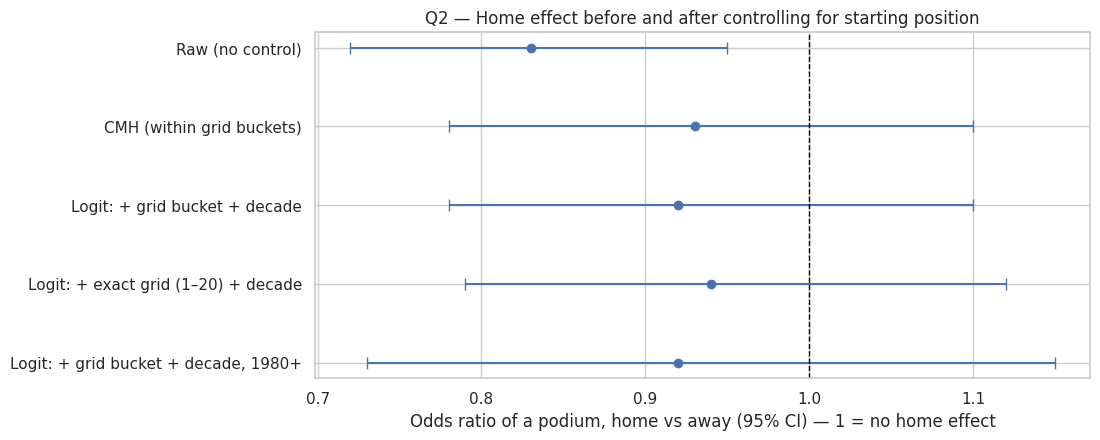

In [58]:
strata = []
for b in GRID_LABELS:
    s = q2[q2["grid_bucket"] == b]
    strata.append(np.array([
        [((s["is_home"] == 1) & (s["podium"] == 1)).sum(), ((s["is_home"] == 1) & (s["podium"] == 0)).sum()],
        [((s["is_home"] == 0) & (s["podium"] == 1)).sum(), ((s["is_home"] == 0) & (s["podium"] == 0)).sum()],
    ]))
cmh = StratifiedTable(strata)
cmh_low, cmh_high = cmh.oddsratio_pooled_confint()

print(f"CMH pooled odds ratio (home vs away): {cmh.oddsratio_pooled:.2f}  95% CI [{cmh_low:.2f}, {cmh_high:.2f}]")
print(f"CMH test of 'no home effect':        p = {cmh.test_null_odds().pvalue:.4f}")
print(f"Breslow–Day test of equal effect across buckets: p = {cmh.test_equal_odds().pvalue:.4f}")

def home_odds_ratio(formula, data):
    m = smf.logit(formula, data=data).fit(disp=0)
    low, high = np.exp(m.conf_int().loc["is_home"])
    return {"odds ratio": np.exp(m.params["is_home"]), "CI low": low, "CI high": high,
            "p-value": m.pvalues["is_home"], "rows": int(m.nobs)}

or_rows = {
    "Raw (no control)":                         home_odds_ratio("podium ~ is_home", q2),
    "CMH (within grid buckets)":                {"odds ratio": cmh.oddsratio_pooled, "CI low": cmh_low, "CI high": cmh_high,
                                                 "p-value": cmh.test_null_odds().pvalue, "rows": len(q2)},
    "Logit: + grid bucket + decade":            home_odds_ratio("podium ~ is_home + C(grid_bucket) + C(decade)", q2),
    "Logit: + exact grid (1–20) + decade":      home_odds_ratio("podium ~ is_home + C(grid) + C(decade)", q2[q2["grid"] <= 20]),
    "Logit: + grid bucket + decade, 1980+":     home_odds_ratio("podium ~ is_home + C(grid_bucket) + C(decade)", q2[q2["year"] >= 1980]),
}
or_table = pd.DataFrame(or_rows).T
or_table[["odds ratio", "CI low", "CI high"]] = or_table[["odds ratio", "CI low", "CI high"]].astype(float).round(2)
or_table["p-value"] = or_table["p-value"].astype(float).round(4)
display(or_table)

fig, ax = plt.subplots(figsize=(10, 4.5))
y = np.arange(len(or_table))[::-1]
ax.errorbar(or_table["odds ratio"], y,
            xerr=[or_table["odds ratio"] - or_table["CI low"], or_table["CI high"] - or_table["odds ratio"]],
            fmt="o", capsize=4)
ax.axvline(1, color="black", linestyle="--", linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels(or_table.index)
ax.set_xlabel("Odds ratio of a podium, home vs away (95% CI) — 1 = no home effect")
ax.set_title("Q2 — Home effect before and after controlling for starting position")
save_fig("4_2_home_odds_ratios")
plt.show()

**Findings.** - **Raw:** odds ratio = **0.83** (95% CI 0.72–0.95, p = 0.009), apparently a home *disadvantage*.
- **After controlling for grid:** the odds ratio moves to **0.92–0.94** with every method (CMH, logistic regression with grid buckets or exact grid, and the 1980+ subset). Every confidence interval **includes 1**, and every p-value is far above 0.05 (0.37–0.49).
- The Breslow–Day test (p = 0.46) shows no evidence that the effect differs between grid buckets, so pooling them is justified.

The raw "home disadvantage" is therefore explained by home drivers starting further back. Once that is controlled for, there is no measurable home effect in either direction.

---
**Answer to Q2. No.** After controlling for starting position, drivers do **not** podium more often at home. The controlled odds ratio is about 0.92–0.93 (CMH: 0.93, 95% CI 0.78–1.10, p = 0.41; logistic regression: 0.92, 95% CI 0.78–1.10, p = 0.37), consistent with no effect, and this holds within every grid bucket, with exact grid positions, and for 1980 onward. The raw data even shows home drivers podiuming *less* (11.7% vs 13.9%), but only because home drivers tend to start further back.

**Grain.** One row per driver per race start. Pit-lane starters (72 rows) are left out because they have no grid slot to compare. Home is defined per row from the driver's nationality and the circuit's country.

**Missingness.** Nationality and circuit country are never missing. Every nationality is mapped explicitly. 14 nationalities (e.g. Finnish, Danish, New Zealander) never had a home race because their country never hosted one, so these drivers only contribute "away" rows. Home starts are only about 8% of rows and are dominated by British, Italian, French and German drivers, so the test has limited power for small effects, and the result mainly reflects those countries.

**Pre-race cutoff.** `is_home` is known before the race, so it would be a valid feature. This analysis suggests it adds little beyond grid position; the ablation in Section 8.5 can confirm that. This is an association, not a causal estimate: controlling for grid does not remove every difference between home and away drivers (e.g. car quality within a grid bucket).

## 4.3 Q3 — Which constructors have the highest mechanical-retirement rate in 2014–2021 vs 2022–2024?

**Definition (from the brief).** A mechanical retirement is a **race start** that ended early because **a car component failed**; crashes, driver errors, driver health and regulation decisions do not count. **Rate** = mechanical retirements ÷ race starts, per constructor and era (non-starters were already removed in 2.3).

**Status mapping.** All 139 status values are assigned explicitly to one category. Codes that do not say whether a component failed (*Retired*, *Puncture*, *Tyre*, *Wheel*, *wing* failures, *Wheel nut*, …) form an **ambiguous** group. Main rule: ambiguous counts as *not* mechanical, because the brief only counts failures we can attribute to a car component; a sensitivity check counts them as mechanical instead.

The status → category mapping, with checks that every status value is mapped exactly once.

In [59]:
STATUS_CATEGORIES = {
    "mechanical": [
        "Engine", "Gearbox", "Transmission", "Clutch", "Hydraulics", "Electrical", "Radiator", "Suspension",
        "Brakes", "Differential", "Overheating", "Mechanical", "Driver Seat", "Driveshaft", "Fuel pressure",
        "Water pressure", "Throttle", "Steering", "Technical", "Electronics", "Heat shield fire", "Exhaust",
        "Oil leak", "Water leak", "Fuel pump", "Track rod", "Oil pressure", "Engine fire", "Engine misfire",
        "Pneumatics", "Wheel bearing", "Fuel system", "Oil line", "Launch control", "Fuel", "Power loss",
        "Drivetrain", "Ignition", "Chassis", "Battery", "Halfshaft", "Crankshaft", "Alternator", "Oil pump",
        "Fuel leak", "Injection", "Distributor", "Turbo", "CV joint", "Water pump", "Spark plugs", "Fuel pipe",
        "Oil pipe", "Axle", "Water pipe", "Magneto", "Supercharger", "Power Unit", "ERS", "Brake duct", "Seat",
        "Undertray", "Cooling system",
    ],
    "accident / driver": ["Accident", "Collision", "Spun off", "Fatal accident", "Collision damage", "Damage", "Debris"],
    "ambiguous": ["Retired", "Tyre", "Puncture", "Tyre puncture", "Wheel", "Wheel rim", "Wheel nut", "Front wing",
                  "Rear wing", "Broken wing", "Vibrations", "Stalled", "Handling", "Fire", "Safety belt", "Not restarted"],
    "driver health": ["Physical", "Injured", "Injury", "Eye injury", "Driver unwell", "Illness"],
    "regulation / withdrawal": ["Disqualified", "Excluded", "Withdrew", "Underweight", "107% Rule", "Did not qualify",
                                "Did not prequalify", "Safety", "Safety concerns"],
    "other (not a component failure)": ["Not classified", "Refuelling", "Fuel rig", "Out of fuel"],
}

status_to_category = {s: cat for cat, values in STATUS_CATEGORIES.items() for s in values}

def categorise(status):
    if status == "Finished" or pd.Series([status]).str.fullmatch(r"\+\d+ Laps?").iloc[0]:
        return "finished"
    return status_to_category.get(status, "UNMAPPED")

status_map = clean["status"].assign(category=clean["status"]["status"].map(categorise))
assert not (status_map["category"] == "UNMAPPED").any(), status_map.loc[status_map["category"] == "UNMAPPED", "status"].tolist()
assert status_map["status"].isin([s for v in STATUS_CATEGORIES.values() for s in v]).sum() + (status_map["category"] == "finished").sum() == len(status_map)

status_map["category"].value_counts().to_frame("status values")

,status values
category,
mechanical,63
finished,34
ambiguous,16
regulation / withdrawal,9
accident / driver,7
driver health,6
other (not a component failure),4


Select 2014–2024, flag mechanical retirements, and show how races ended in each era and which components failed most often.

In [60]:
Q3_ERAS = {"2014–2021": (2014, 2021), "2022–2024": (2022, 2024)}
MIN_STARTS = 40   # about one full season for a two-car team

q3 = de[de["year"].between(2014, 2024)].merge(status_map[["statusId", "category"]], on="statusId", how="left")
q3["era"] = np.where(q3["year"] <= 2021, "2014–2021", "2022–2024")
q3["mechanical"] = (q3["category"] == "mechanical").astype(int)
q3["mechanical_incl_ambiguous"] = q3["category"].isin(["mechanical", "ambiguous"]).astype(int)

how_races_ended = pd.crosstab(q3["category"], q3["era"], margins=True, margins_name="total")
display(how_races_ended)

# The most frequent mechanical statuses in each era (what actually breaks)
q3[q3["mechanical"] == 1].groupby("era")["status"].value_counts().groupby(level=0).head(6).to_frame("retirements")

era,2014–2021,2022–2024,total
category,,,
accident / driver,219,89,308
ambiguous,67,15,82
driver health,1,1,2
finished,2660,1165,3825
mechanical,287,77,364
other (not a component failure),1,0,1
regulation / withdrawal,8,4,12
total,3243,1351,4594


retirements
era       status                 
2014–2021 Engine               58
          Brakes               44
          Gearbox              32
          Power Unit           32
          Suspension           24
          Electrical           13
2022–2024 Engine               21
          Gearbox               8
          Power Unit            7
          Hydraulics            5
          Brakes                4
          Undertray             4

How 2014–2024 race starts ended in each era (as % of all starts in the era), and the components that failed most often, normalised by the number of starts so the 8-season and 3-season eras are comparable.

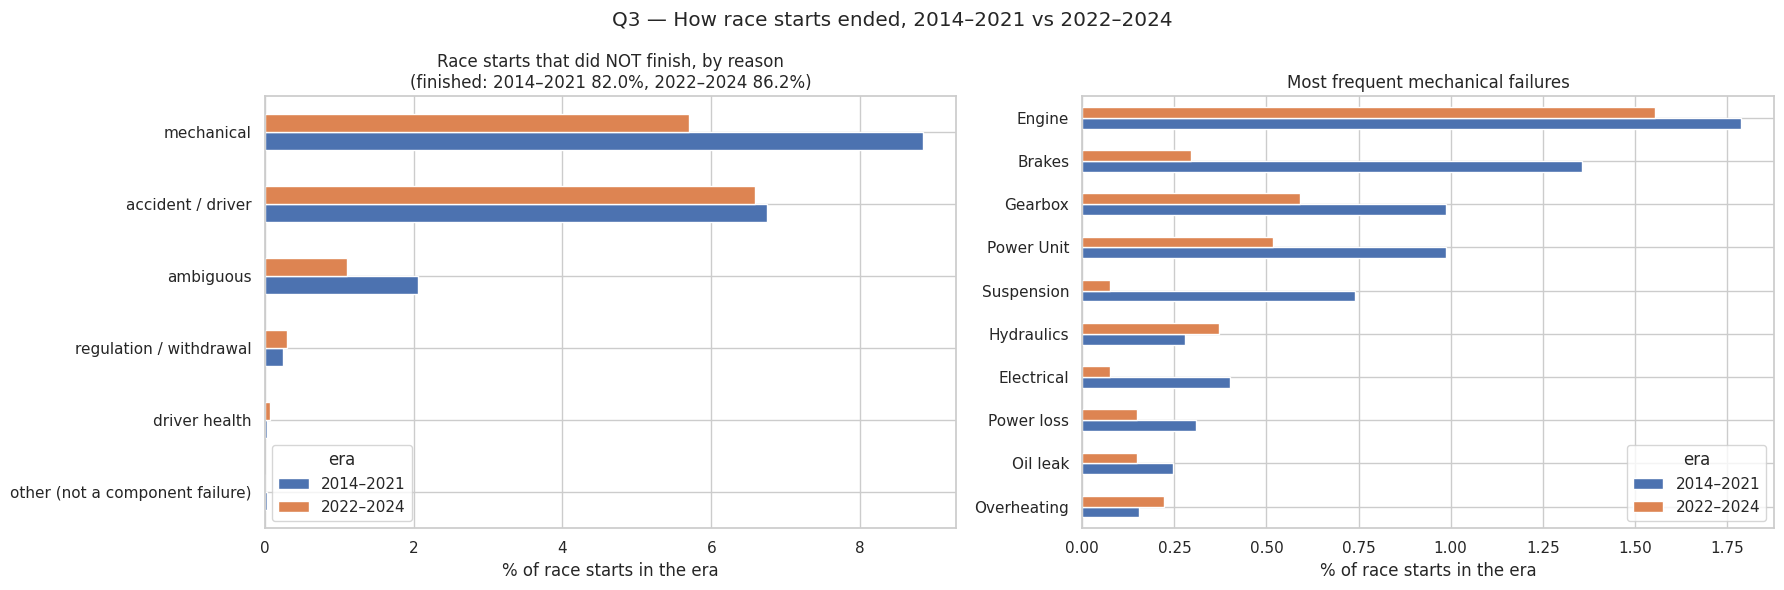

In [61]:
# ---- Q3: how races ended per era, and which components failed (both as % of race starts in the era) ----
retire_cats = ["mechanical", "accident / driver", "ambiguous", "regulation / withdrawal", "driver health",
               "other (not a component failure)"]
starts_per_era = q3.groupby("era").size()
share = pd.crosstab(q3["category"], q3["era"]).div(starts_per_era, axis=1).mul(100)
finished_share = share.loc["finished"]

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
share.reindex(retire_cats)[::-1].plot.barh(ax=axes[0])
axes[0].set_title("Race starts that did NOT finish, by reason\n(finished: "
                  + ", ".join(f"{e} {v:.1f}%" for e, v in finished_share.items()) + ")")
axes[0].set_xlabel("% of race starts in the era")
axes[0].set_ylabel("")

comp = q3[q3["mechanical"] == 1].groupby(["status", "era"]).size().unstack(fill_value=0)
comp_rate = comp.div(starts_per_era, axis=1).mul(100)
top_parts = comp_rate.sum(axis=1).sort_values(ascending=False).index[:10]
comp_rate.loc[top_parts[::-1]].plot.barh(ax=axes[1])
axes[1].set_title("Most frequent mechanical failures")
axes[1].set_xlabel("% of race starts in the era")
axes[1].set_ylabel("")
fig.suptitle("Q3 — How race starts ended, 2014–2021 vs 2022–2024")
plt.tight_layout()
save_fig("4_3_how_races_ended")
plt.show()

Mechanical-retirement rate per constructor and era with Wilson CIs (constructors need at least 40 starts in an era, about one season for a two-car team).

Overall mechanical-retirement rate per start: {'2014–2021': 8.85, '2022–2024': 5.7}
Constructors below the minimum of 40 starts (not ranked): [['2014–2021', 'Caterham', 33], ['2014–2021', 'Marussia', 31]]


,2014–2021 | constructor,2014–2021 | value,2022–2024 | constructor,2022–2024 | value
rank,,,,
1,Lotus F1,17.3% (13/75),Alfa Romeo,12.5% (11/88)
2,Toro Rosso,16.1% (39/242),Alpine F1 Team,10.4% (14/135)
3,Renault,13.1% (26/199),AlphaTauri,8.0% (7/88)
4,McLaren,12.7% (40/315),Williams,6.0% (8/134)
5,Red Bull,10.7% (34/318),Ferrari,5.2% (7/134)
6,Sauber,10.6% (21/199),Haas F1 Team,4.4% (6/135)
7,AlphaTauri,9.1% (7/77),Mercedes,4.4% (6/136)
8,Racing Point,8.0% (6/75),RB F1 Team,4.2% (2/48)
9,Haas F1 Team,7.5% (18/240),Aston Martin,3.8% (5/133)


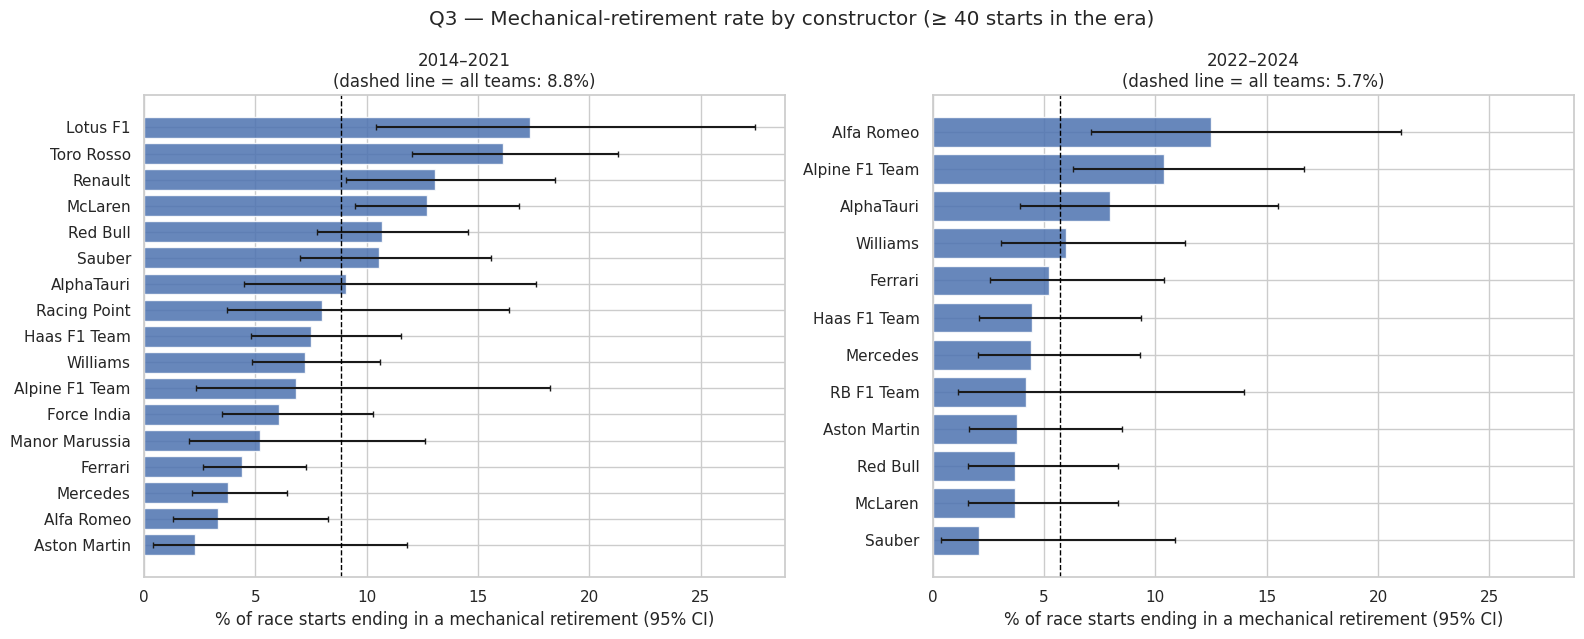

In [62]:
def mech_rate(df, flag):
    g = df.groupby(["era", "constructor"])[flag].agg(starts="size", mech_retirements="sum").reset_index()
    g["rate"] = g["mech_retirements"] / g["starts"]
    g["ci_low"], g["ci_high"] = proportion_confint(g["mech_retirements"], g["starts"], method="wilson")
    g["eligible"] = g["starts"] >= MIN_STARTS
    return g

q3_rates = mech_rate(q3, "mechanical")
era_overall = q3.groupby("era")["mechanical"].mean().mul(100).round(2)
print("Overall mechanical-retirement rate per start:", era_overall.to_dict())
print("Constructors below the minimum of", MIN_STARTS, "starts (not ranked):",
      q3_rates.loc[~q3_rates["eligible"], ["era", "constructor", "starts"]].values.tolist())

def era_ranking(rates):
    out = []
    for era in Q3_ERAS:
        t = rates[(rates["era"] == era) & rates["eligible"]].sort_values("rate", ascending=False)
        t = t.assign(rank=range(1, len(t) + 1),
                     value=(t["rate"] * 100).round(1).astype(str) + "% (" + t["mech_retirements"].astype(str) + "/" + t["starts"].astype(str) + ")")
        out.append(t.set_index("rank")[["constructor", "value"]].add_prefix(era + " | "))
    return pd.concat(out, axis=1).fillna("")

display(era_ranking(q3_rates))

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), sharex=True)
for ax, era in zip(axes, Q3_ERAS):
    t = q3_rates[(q3_rates["era"] == era) & q3_rates["eligible"]].sort_values("rate")
    err = [(t["rate"] - t["ci_low"]) * 100, (t["ci_high"] - t["rate"]) * 100]
    ax.barh(t["constructor"], t["rate"] * 100, xerr=err, capsize=2, alpha=0.85)
    ax.axvline(era_overall[era], color="black", linestyle="--", linewidth=1)
    ax.set_title(f"{era}\n(dashed line = all teams: {era_overall[era]:.1f}%)")
    ax.set_xlabel("% of race starts ending in a mechanical retirement (95% CI)")
fig.suptitle(f"Q3 — Mechanical-retirement rate by constructor (≥ {MIN_STARTS} starts in the era)")
plt.tight_layout()
save_fig("4_3_mech_rate_by_constructor")
plt.show()

Teams that raced in both eras under the same `constructorId`: how their rate changed.

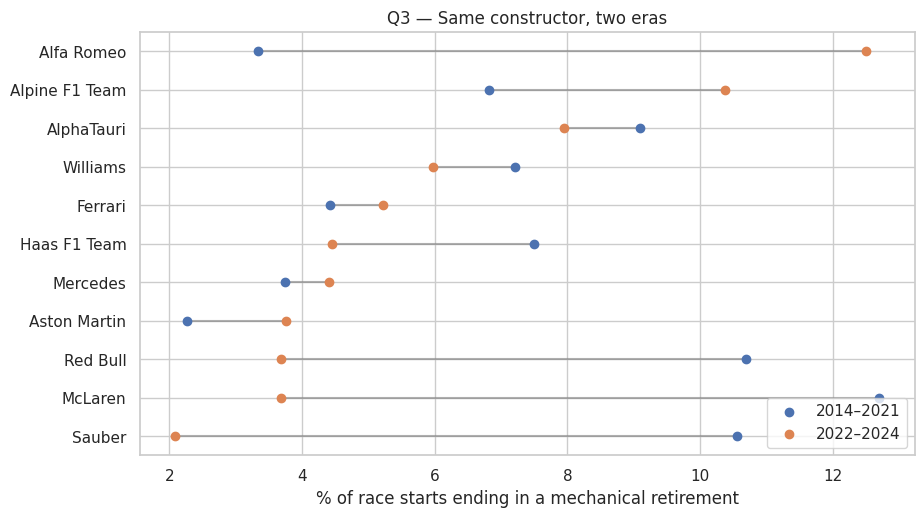

In [63]:
# Constructors that raced in both eras under the same constructorId: how did they change?
both = q3_rates[q3_rates["eligible"]].pivot(index="constructor", columns="era", values="rate").dropna().sort_values("2022–2024")

fig, ax = plt.subplots(figsize=(10, 5.5))
y = np.arange(len(both))
ax.hlines(y, both["2014–2021"] * 100, both["2022–2024"] * 100, color="gray", alpha=0.6)
ax.scatter(both["2014–2021"] * 100, y, label="2014–2021", zorder=3)
ax.scatter(both["2022–2024"] * 100, y, label="2022–2024", zorder=3)
ax.set_yticks(y)
ax.set_yticklabels(both.index)
ax.set_xlabel("% of race starts ending in a mechanical retirement")
ax.set_title("Q3 — Same constructor, two eras")
ax.legend()
save_fig("4_3_mech_rate_dumbbell")
plt.show()

**Findings.** Mechanical retirements became **rarer**: from **8.9%** of starts in 2014–2021 to **5.7%** in 2022–2024. Engine and power-unit failures are the most common cause in both eras.

- **2014–2021:** the highest rates belong to **Lotus F1** (17.3%, 2014–15 only), **Toro Rosso** (16.1%), **Renault** (13.1%) and **McLaren** (12.7%). 25 of McLaren's 40 mechanical retirements came in 2015–2017, its Honda power-unit years. The most reliable were **Mercedes** (3.8%) and **Ferrari** (4.4%), plus Alfa Romeo (3.3%) and Aston Martin (2.3%), whose figures cover only 2019–2021 and 2021.
- **2022–2024:** **Alfa Romeo** (12.5%) and **Alpine** (10.4%) stand out, ahead of AlphaTauri (8.0%). The other teams sit between 3.7% and 6.0%. The lowest rate, Sauber's 2.1%, is a single retirement in its one season under that name (2024, 48 starts).
- **Same team, two eras:** McLaren (12.7% → 3.7%) and Red Bull (10.7% → 3.7%) became much more reliable, while Alfa Romeo went from one of the most reliable teams (3.3%) to the least reliable (12.5%).

The 2022–2024 counts are small (1–14 retirements per team), so apart from the top two the teams' confidence intervals overlap and their order is not statistically meaningful.

- **How races ended (plot above):** the share of starts that finished rose from **82.0% to 86.2%**. Almost all of the gain comes from mechanical failures (8.9% → 5.7% of starts); accidents and driver errors stayed at about 6.6–6.8%. Brakes (1.4% → 0.3% of starts), suspension (0.7% → 0.1%) and power-unit failures fell most, while engine failures stayed the most common cause in both eras (1.8% → 1.6%).


Robustness: group renamed teams into lineages (e.g. Toro Rosso → AlphaTauri → RB) and recompute the rates.

In [64]:
LINEAGE = {
    "Toro Rosso": "Toro Rosso / AlphaTauri / RB", "AlphaTauri": "Toro Rosso / AlphaTauri / RB", "RB F1 Team": "Toro Rosso / AlphaTauri / RB",
    "Force India": "Force India / Racing Point / Aston Martin", "Racing Point": "Force India / Racing Point / Aston Martin",
    "Aston Martin": "Force India / Racing Point / Aston Martin",
    "Sauber": "Sauber / Alfa Romeo", "Alfa Romeo": "Sauber / Alfa Romeo",
    "Lotus F1": "Lotus F1 / Renault / Alpine", "Renault": "Lotus F1 / Renault / Alpine", "Alpine F1 Team": "Lotus F1 / Renault / Alpine",
    "Marussia": "Marussia / Manor", "Manor Marussia": "Marussia / Manor",
}
q3_lineage = q3.assign(constructor=q3["constructor"].replace(LINEAGE))
lineage_rates = mech_rate(q3_lineage, "mechanical")
era_ranking(lineage_rates)

,2014–2021 | constructor,2014–2021 | value,2022–2024 | constructor,2022–2024 | value
rank,,,,
1,Toro Rosso / AlphaTauri / RB,14.4% (46/319),Lotus F1 / Renault / Alpine,10.4% (14/135)
2,Lotus F1 / Renault / Alpine,13.2% (42/318),Sauber / Alfa Romeo,8.8% (12/136)
3,McLaren,12.7% (40/315),Toro Rosso / AlphaTauri / RB,6.6% (9/136)
4,Red Bull,10.7% (34/318),Williams,6.0% (8/134)
5,Sauber / Alfa Romeo,7.8% (25/319),Ferrari,5.2% (7/134)
6,Haas F1 Team,7.5% (18/240),Haas F1 Team,4.4% (6/135)
7,Williams,7.2% (23/319),Mercedes,4.4% (6/136)
8,Marussia / Manor,6.5% (7/108),Force India / Racing Point / Aston Martin,3.8% (5/133)
9,Force India / Racing Point / Aston Martin,6.0% (19/317),McLaren,3.7% (5/136)


The lineage view as a plot: the same team (across renames) in both eras.

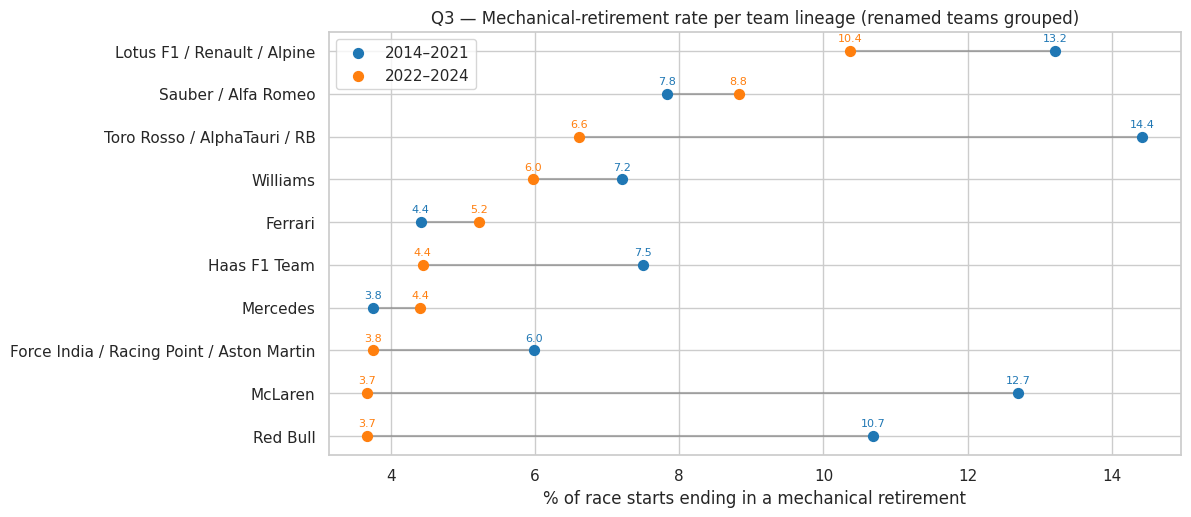

In [65]:
# ---- Q3 robustness: mechanical-retirement rate per team LINEAGE, both eras ----
lin = (lineage_rates[lineage_rates["eligible"]].pivot(index="constructor", columns="era", values="rate")
       .dropna().mul(100).sort_values("2022–2024"))
fig, ax = plt.subplots(figsize=(11, 5.5))
yy = np.arange(len(lin))
ax.hlines(yy, lin["2014–2021"], lin["2022–2024"], color="gray", alpha=0.6)
for era, color in [("2014–2021", "tab:blue"), ("2022–2024", "tab:orange")]:
    ax.scatter(lin[era], yy, color=color, label=era, zorder=3, s=50)
    for yi, v in zip(yy, lin[era]):
        ax.text(v, yi + 0.22, f"{v:.1f}", ha="center", fontsize=8, color=color)
ax.set_yticks(yy)
ax.set_yticklabels(lin.index)
ax.set_xlabel("% of race starts ending in a mechanical retirement")
ax.set_title("Q3 — Mechanical-retirement rate per team lineage (renamed teams grouped)")
ax.legend()
save_fig("4_3_lineage_dumbbell")
plt.show()

Sensitivity: count the ambiguous statuses as mechanical, and check how many failures happened before the first lap.

In [66]:
rates_incl = mech_rate(q3, "mechanical_incl_ambiguous")

sens = []
for era in Q3_ERAS:
    a = q3_rates[(q3_rates["era"] == era) & q3_rates["eligible"]].set_index("constructor")["rate"]
    b = rates_incl[(rates_incl["era"] == era) & rates_incl["eligible"]].set_index("constructor")["rate"]
    rho, _ = spearmanr(a, b[a.index])
    sens.append({"era": era, "Spearman rho (main vs incl. ambiguous)": round(rho, 2),
                 "top 3 — main rule": ", ".join(a.sort_values(ascending=False).index[:3]),
                 "top 3 — incl. ambiguous": ", ".join(b.sort_values(ascending=False).index[:3])})
display(pd.DataFrame(sens))

# Edge case: mechanical failures before completing a single lap (e.g. on the formation lap)
zero_lap = q3[(q3["mechanical"] == 1) & (q3["laps"] == 0)]
print(f"Mechanical retirements with 0 laps completed: {len(zero_lap)} of {q3['mechanical'].sum()}")

,era,Spearman rho (main vs incl. ambiguous),top 3 — main rule,top 3 — incl. ambiguous
0,2014–2021,0.97,"Lotus F1, Toro Rosso, Renault","Lotus F1, Toro Rosso, McLaren"
1,2022–2024,0.68,"Alfa Romeo, Alpine F1 Team, AlphaTauri","Alfa Romeo, RB F1 Team, Alpine F1 Team"


Mechanical retirements with 0 laps completed: 8 of 364


**Findings.** - **Lineages:** grouping renamed teams gives the same picture. The **Toro Rosso / AlphaTauri / RB** lineage is the least reliable in 2014–2021 (14.4%), followed by the **Lotus / Renault / Alpine** lineage (13.2%). In 2022–2024 the **Lotus / Renault / Alpine** (10.4%) and **Sauber / Alfa Romeo** (8.8%) lineages are the least reliable. Mercedes and Ferrari are the most reliable in 2014–2021.
- **Ambiguous statuses:** for **2014–2021** the ranking barely changes (Spearman ρ = 0.97; McLaren replaces Renault at #3). For **2022–2024** it changes more (ρ = 0.68): Alfa Romeo stays #1 and Alpine stays in the top three, but RB F1 Team (48 starts, 2024 only) moves up to #2 and AlphaTauri drops out. **The 2014–2021 answer is robust to this choice; for 2022–2024 only the top of the table (Alfa Romeo, Alpine) is robust**, which is expected given how few retirements each team has in three seasons.
- **Formation-lap failures:** only 8 of 364 mechanical retirements happened before a single lap was completed, so whether these count as race starts does not affect the result.
- **Lineage plot:** the largest improvements are the **Toro Rosso / AlphaTauri / RB** lineage (14.4% → 6.6%), **McLaren** (12.7% → 3.7%) and **Red Bull** (10.7% → 3.7%); **Sauber / Alfa Romeo** (7.8% → 8.8%), Ferrari (4.4% → 5.2%) and Mercedes (3.8% → 4.4%) became slightly *less* reliable.


---
**Answer to Q3.**
- **2014–2021:** the highest mechanical-retirement rates per start belong to **Lotus F1 (17.3%)**, **Toro Rosso (16.1%)**, **Renault (13.1%)** and **McLaren (12.7%, mostly its 2015–2017 Honda seasons)**. Mercedes (3.8%) and Ferrari (4.4%) were the most reliable full-time teams.
- **2022–2024:** **Alfa Romeo (12.5%)** and **Alpine (10.4%)** have the highest rates, followed by AlphaTauri (8.0%). Most other teams are between 3.7% and 6.0%.
- Reliability improved overall (8.9% → 5.7% of starts). The ranking changed between eras, with Alfa Romeo getting much worse and McLaren and Red Bull much better. The 2014–2021 result holds when renamed teams are grouped into lineages and when ambiguous statuses are counted as mechanical; for 2022–2024, Alfa Romeo and Alpine stay at the top under both checks, while the order below them is sensitive to these choices.

**Grain.** The unit is one race start (one driver, one car, one race), aggregated to constructor × era. Teams are identified by `constructorId`, so renamed teams are separate rows (lineage view in 4.3). Constructors with fewer than 40 starts in an era are not ranked.

**Missingness.** `status` is never missing. The denominator is race starts only (non-starters removed in Section 2.3). The status mapping is a documented judgement: ambiguous codes are excluded from "mechanical", and the sensitivity check shows this choice does not drive the answer. The dataset contains all 24 races of 2024 (Section 2.2), so the 2022–2024 window is complete.

**Pre-race cutoff.** `status` is **post-race**, so it is only used here as the outcome being analysed and is **never a model feature**. A leakage-safe version would be a constructor's mechanical-retirement rate over *previous* races only (shifted rolling window), a candidate reliability feature for Section 5.

<a id="5"></a>
# 5. Feature Selection

Every feature must be known **before the race starts** (after qualifying, once the grid is fixed). Features are organised in six groups — grid, qualifying, driver form, constructor form, standings, context — and the same groups are used for the ablation in 8.5.

Each feature is justified in one of the two ways the brief allows:
- **hypothesis-driven** — the EDA (Sections 1, 3, 4 and the evidence plots in 5.4) shows a relationship with the podium;
- **empirical** — a controlled experiment kept in this notebook (5.5) shows that it improves validation performance.

| Step | What happens |
|---|---|
| 5.1 | build `model_df` (one row per driver per race) and audit every source column for leakage |
| 5.2 | build the candidate features group by group, using past information only |
| 5.3 | prove with assertions that no feature uses current-race or future information |
| 5.4 | evidence: podium rate by feature value, distributions, correlation, mutual information (training seasons only) |
| 5.5 | experiments: rolling window *N*, training window (full history vs modern), optional/redundant features |
| 5.6 | final feature table: group, evidence, pre-race validity, missingness handling |

## 5.1 Modeling table and leakage audit

`model_df` starts from `results_clean` (Section 2: real starts only, Indy 500 excluded, shared drives resolved), adds the race calendar (`year`, `round`, `circuitId`, `date`) and the target `podium = positionOrder ≤ 3`, and is sorted chronologically **before** any history feature is computed. `positionOrder` and `statusId` stay in the table only to build the target and the *lagged* history features — they are never features themselves.

,model_df
rows (driver-race starts),24551
races,1114
drivers,681
constructors,166
seasons,1950–2024 (75)
podium rows,3349
podium rate (%),13.64
"duplicated (raceId, driverId)",0


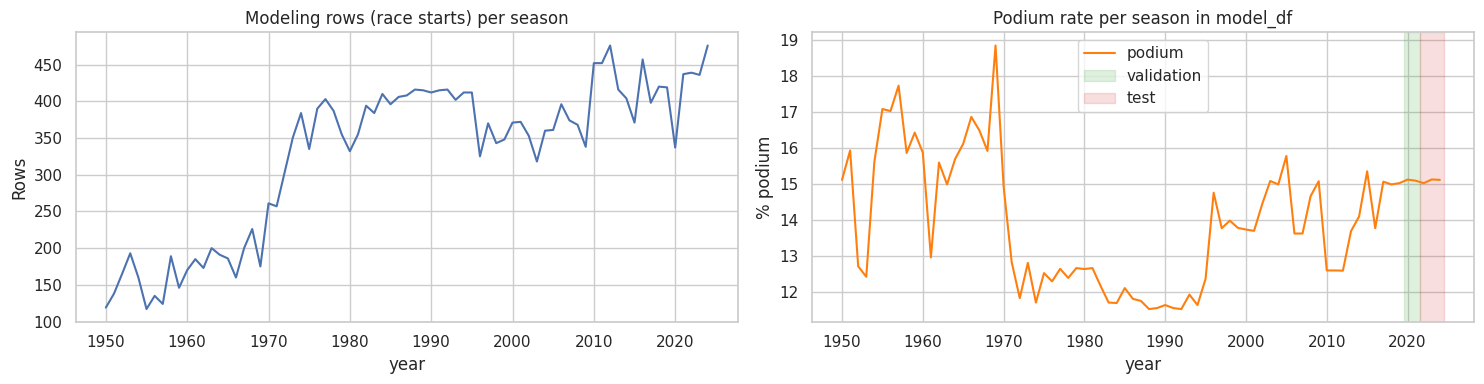

In [67]:
# ---- 5.1 Modeling table: one row per (raceId, driverId) --------------------------------------
# Start from the cleaned backbone (real starts only, Indy 500 excluded, shared drives resolved).
# positionOrder and statusId are POST-RACE columns: they are kept only to build the target and the
# *lagged* (previous-races) history features below. They are never used as features themselves.
model_df = (
    results_clean[["raceId", "driverId", "constructorId", "grid", "positionOrder", "statusId"]]
    .merge(clean["races"][["raceId", "year", "round", "circuitId", "date"]], on="raceId", how="left")
    .sort_values(["date", "raceId", "driverId"])          # chronological order before any history feature
    .reset_index(drop=True)
)
model_df["podium"] = (model_df["positionOrder"] <= 3).astype(int)   # the target

# Grain and completeness checks
assert not model_df.duplicated(["raceId", "driverId"]).any(), "grain broken"
assert model_df["date"].notna().all() and model_df["year"].notna().all()
assert len(model_df) == len(results_clean)

overview = pd.Series({
    "rows (driver-race starts)": len(model_df),
    "races": model_df["raceId"].nunique(),
    "drivers": model_df["driverId"].nunique(),
    "constructors": model_df["constructorId"].nunique(),
    "seasons": f"{model_df['year'].min()}–{model_df['year'].max()} ({model_df['year'].nunique()})",
    "podium rows": int(model_df["podium"].sum()),
    "podium rate (%)": round(model_df["podium"].mean() * 100, 2),
    "duplicated (raceId, driverId)": int(model_df.duplicated(["raceId", "driverId"]).sum()),
}).to_frame("model_df")
display(overview)

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
model_df.groupby("year").size().plot(ax=axes[0])
axes[0].set_title("Modeling rows (race starts) per season")
axes[0].set_ylabel("Rows")
(model_df.groupby("year")["podium"].mean() * 100).plot(ax=axes[1], color="tab:orange")
axes[1].axvspan(2019.5, 2021.5, color="tab:green", alpha=0.15, label="validation")
axes[1].axvspan(2021.5, 2024.5, color="tab:red", alpha=0.15, label="test")
axes[1].set_title("Podium rate per season in model_df")
axes[1].set_ylabel("% podium")
axes[1].legend()
plt.tight_layout()
save_fig("5_1_model_df_overview")
plt.show()

**Findings.** `model_df` has **24,551 rows** (one per driver-race start; 0 duplicated `(raceId, driverId)` pairs), **1,114 races**, **681 drivers** and **166 constructors** over **75 seasons (1950–2024)**. **3,349 rows (13.6%)** are podiums. The per-season podium rate moves between roughly 10% (big fields of the late 1980s) and 15% (about 20 cars today); the validation (2020–21) and test (2022–24) seasons are at the modern ~15% level.

**Leakage audit.** For every source table and column: when does the information become known, and how is it used? Anything that is only known during or after the race is either the target, used only as *lagged history* (previous races), or never used. The set `FORBIDDEN_FEATURES` is checked by an assertion in 5.3 and again when the final feature list is created.

**Decision on `sprint_results` — excluded.** Sprint results are technically pre-race information (the sprint runs on Saturday), but:
- only **18 of 1,114 races** have a sprint (2021–2024) and **none** is in the training seasons, so the model could never learn what a sprint feature means;
- the format changed: in 2021–22 the sprint result *set the main-race grid*, so that information is **already inside `grid`**; from 2023 the sprint has its own qualifying and does not affect the grid;
- a sprint feature would be missing for 98% of rows and need season-specific logic.

Excluding sprints keeps the feature definition identical across all seasons and loses no information that `grid` does not already carry.

In [68]:
# ---- Leakage audit: every source column, when it becomes known, and how we use it -----------
leakage_audit = pd.DataFrame([
    # (source, column(s), known when?, decision)
    ("results",      "grid",                                   "pre-race (grid fixed)",        "feature"),
    ("qualifying",   "position, q1, q2, q3",                   "pre-race (after qualifying)",  "feature (derived)"),
    ("races",        "year, round, circuitId, date",           "pre-race (calendar)",          "context / split key"),
    ("drivers",      "dob, nationality",                       "pre-race (static)",            "feature (age, home flag)"),
    ("circuits",     "country",                                "pre-race (static)",            "feature (home flag)"),
    ("results",      "positionOrder",                          "post-race",                    "TARGET only + lagged history"),
    ("results",      "statusId / status",                      "post-race",                    "lagged history only"),
    ("results",      "position, positionText, points, laps",   "post-race",                    "never used"),
    ("results",      "time, milliseconds, fastestLap*, rank",  "post-race",                    "never used"),
    ("lap_times",    "all columns",                            "during race",                  "never used"),
    ("pit_stops",    "all columns",                            "during race",                  "never used"),
    ("constructor_results", "points, status",                  "post-race",                    "never used"),
    ("driver_standings",    "points, position, wins",          "post-race (after each round)", "previous round only"),
    ("constructor_standings","points, position, wins",         "post-race (after each round)", "previous round only"),
    ("sprint_results","all columns",                           "pre-race (Saturday)",          "excluded (decision below)"),
], columns=["source table", "column(s)", "known when?", "how we use it"])
display(leakage_audit)

# Columns that may NEVER appear in the feature matrix X (checked by an assertion in 5.3)
FORBIDDEN_FEATURES = {"positionOrder", "position", "positionText", "points", "laps", "time", "milliseconds",
                      "fastestLap", "fastestLapTime", "fastestLapSpeed", "rank", "statusId", "status",
                      "podium", "finish_pct", "finished", "mech_dnf"}

# ---- Sprint decision: evidence -------------------------------------------------------------
sprint_races = clean["sprint_results"].merge(clean["races"][["raceId", "year"]], on="raceId")
sprint_summary = sprint_races.groupby("year")["raceId"].nunique().rename("sprint weekends").to_frame()
sprint_summary["races in season"] = model_df.groupby("year")["raceId"].nunique().reindex(sprint_summary.index)
sprint_summary["share of modeling rows (%)"] = (
    model_df[model_df["raceId"].isin(sprint_races["raceId"])].groupby("year").size()
    / model_df.groupby("year").size()).reindex(sprint_summary.index).mul(100).round(1)
display(sprint_summary)
print(f"Sprint weekends: {sprint_races['raceId'].nunique()} of {model_df['raceId'].nunique()} races "
      f"({sprint_races['raceId'].nunique() / model_df['raceId'].nunique():.1%}); none in the training seasons (<= 2019).")

,source table,column(s),known when?,how we use it
0,results,grid,pre-race (grid fixed),feature
1,qualifying,"position, q1, q2, q3",pre-race (after qualifying),feature (derived)
2,races,"year, round, circuitId, date",pre-race (calendar),context / split key
3,drivers,"dob, nationality",pre-race (static),"feature (age, home flag)"
4,circuits,country,pre-race (static),feature (home flag)
5,results,positionOrder,post-race,TARGET only + lagged history
6,results,statusId / status,post-race,lagged history only
7,results,"position, positionText, points, laps",post-race,never used
8,results,"time, milliseconds, fastestLap*, rank",post-race,never used
9,lap_times,all columns,during race,never used


,sprint weekends,races in season,share of modeling rows (%)
year,,,
2021,3,22,13.5
2022,3,22,13.7
2023,6,22,27.1
2024,6,24,24.8


Sprint weekends: 18 of 1114 races (1.6%); none in the training seasons (<= 2019).


## 5.2 Leakage-safe features

| Group | Features | Leakage rule |
|---|---|---|
| Grid | `grid_pos`, `grid_rel` (= grid / field size), `pit_lane_start` (+ candidate `front_row`) | fixed before the race |
| Qualifying | `quali_pos`, `quali_gap_pct` (% gap to the fastest qualifier), `grid_minus_quali` (penalty), `has_quali` | known after qualifying |
| Driver form | podium rate, mean finishing position (0 = won, 1 = last) and finish rate over the last *N* starts; career podium rate | `shift(1)` **before** rolling → only **past** races |
| Constructor form | podiums per car, mean finishing position and mechanical-DNF rate over the last *N* races | aggregate to **one row per constructor per race first**, then `shift(1)` → a teammate's result in the same race cannot leak |
| Standings | driver / constructor championship rank, share of the leader's points, season wins | standings after the **previous round** of the same season |
| Context | field size, home race, driver age, career starts | known before the weekend |

Grid and qualifying features first. Two design choices: a **pit-lane starter** (`grid = 0`) is given the last slot (`grid_pos = field_size`) plus a flag, because he starts behind every car; and raw qualifying lap times are **not** used, because they are not comparable between circuits (Monaco ≈ 70 s, Spa ≈ 105 s) — the % gap to the fastest qualifier of the same race is comparable.

In [69]:
# ---- Grid features (known once the grid is fixed) ------------------------------------------
# field_size = number of cars that actually start this race (known when the grid is published)
model_df["field_size"] = model_df.groupby("raceId")["driverId"].transform("size")

model_df["pit_lane_start"] = (model_df["grid"] == 0).astype(int)
# A pit-lane starter starts behind every car on the grid, so his effective slot is the last one
model_df["grid_pos"] = np.where(model_df["grid"] == 0, model_df["field_size"], model_df["grid"]).astype(float)
model_df["front_row"] = ((model_df["grid_pos"] <= 2) & (model_df["pit_lane_start"] == 0)).astype(int)
# Relative slot (0 = front, 1 = back): makes P10 in a 34-car field comparable with P10 in a 20-car field
model_df["grid_rel"] = (model_df["grid_pos"] / model_df["field_size"]).clip(upper=1.0)

# ---- Qualifying features (known after qualifying) ------------------------------------------
quali = clean["qualifying"][["raceId", "driverId", "position", "q1", "q2", "q3"]].rename(columns={"position": "quali_pos"})
# Best lap of the sessions the driver actually took part in: a driver knocked out in Q1 has no Q2/Q3 time
# (structural missingness), so we never require Q2/Q3.
quali["quali_best_time"] = quali[["q1", "q2", "q3"]].min(axis=1)
# Raw lap times are not comparable between circuits (Monaco ~70 s, Spa ~105 s), so we use the % gap to the
# fastest qualifier of the same race instead.
quali["pole_time"] = quali.groupby("raceId")["quali_best_time"].transform("min")
quali["quali_gap_pct"] = 100 * (quali["quali_best_time"] - quali["pole_time"]) / quali["pole_time"]

model_df = model_df.merge(quali[["raceId", "driverId", "quali_pos", "quali_gap_pct"]], on=["raceId", "driverId"], how="left")
model_df["has_quali"] = model_df["quali_pos"].notna().astype(int)
# Positive = started further back than qualified (grid penalty, pit-lane start); negative = promoted
model_df["grid_minus_quali"] = model_df["grid_pos"] - model_df["quali_pos"]

grid_quali_cols = ["grid", "grid_pos", "pit_lane_start", "front_row", "grid_rel", "field_size",
                   "quali_pos", "quali_gap_pct", "grid_minus_quali", "has_quali"]
display(model_df[grid_quali_cols].describe().T.round(2))
print("Rows with a qualifying record:", f"{model_df['has_quali'].mean():.1%}",
      "| from 2003 on:", f"{model_df.loc[model_df['year'] >= 2003, 'has_quali'].mean():.1%}")

,count,mean,std,min,25%,50%,75%,max
grid,24551.0,11.73,6.76,0.00,6.00,12.00,17.00,34.0
grid_pos,24551.0,11.78,6.74,1.00,6.00,12.00,17.00,34.0
pit_lane_start,24551.0,0.00,0.05,0.00,0.00,0.00,0.00,1.0
front_row,24551.0,0.09,0.29,0.00,0.00,0.00,0.00,1.0
grid_rel,24551.0,0.52,0.29,0.03,0.27,0.53,0.77,1.0
field_size,24551.0,22.47,3.00,6.00,20.00,22.00,25.00,34.0
quali_pos,10411.0,11.17,6.25,1.00,6.00,11.00,16.00,26.0
quali_gap_pct,10259.0,2.39,2.56,0.00,0.90,1.84,3.06,45.6
grid_minus_quali,10411.0,0.01,1.52,-9.00,0.00,0.00,0.00,23.0
has_quali,24551.0,0.42,0.49,0.00,0.00,0.00,1.00,1.0


Rows with a qualifying record: 42.4% | from 2003 on: 99.8%


**Findings.** `grid_pos` and `field_size` are never missing. Qualifying features exist for **42.4%** of all rows but for **99.8%** of rows from 2003 on — the coverage drift found in 1.3. Missing qualifying is **kept as missing** (no zero, no guess): it is imputed later inside the training-only pipeline, and `has_quali` tells the model that the value was absent. `grid_minus_quali` is 0 for most drivers and positive after a grid penalty (up to +23 places).

**Driver and constructor form (past races only).** The key line is `series.shift(1).rolling(N)`: `shift(1)` moves every value one race down, so the statistic for race *t* is computed from races *t−1, t−2, …* and **never** includes race *t* itself. Form carries over between seasons (a driver's last race of 2019 counts for his first race of 2020).

For the constructor the order matters even more: the two cars are first **aggregated into one constructor-race row** (podiums, cars, mean finishing position, mechanical DNFs — the Q3 status mapping is reused), then shifted and rolled per `constructorId`, then merged back to *both* drivers. Computing it row by row would let one teammate's current-race result leak into the other teammate's feature. Constructor history follows `constructorId`, so a renamed team starts a new history (documented limitation).

All candidate windows *N* = 3, 5, 10, 20 are built now; the final *N* is chosen on validation in 5.5. A driver's first career start (and a constructor's first race) has no form → `NaN`, imputed later.

In [70]:
# ---- Driver and constructor form: PAST races only ---------------------------------------------
FORM_WINDOWS = [3, 5, 10, 20]      # candidate rolling windows N; the final N is chosen on validation (5.5)

# Per-race outcomes used ONLY as history (they are post-race for the current row, so they are never features)
finished_ids   = status_map.loc[status_map["category"] == "finished", "statusId"]
mechanical_ids = status_map.loc[status_map["category"] == "mechanical", "statusId"]      # Q3 mapping
model_df["finish_pct"] = (model_df["positionOrder"] / model_df["field_size"]).clip(upper=1.0)  # 0 = won, 1 = last
model_df["finished"]   = model_df["statusId"].isin(finished_ids).astype(int)
model_df["mech_dnf"]   = model_df["statusId"].isin(mechanical_ids).astype(int)


def past_rolling(series, n, how="mean"):
    """Rolling statistic over the previous n values. shift(1) FIRST, so the current race is never included."""
    shifted = series.shift(1)
    roll = shifted.rolling(n, min_periods=1)
    return roll.mean() if how == "mean" else roll.sum()


def add_driver_form(df, windows=FORM_WINDOWS):
    """Driver form from the driver's previous starts (across seasons). First career start -> NaN."""
    df = df.sort_values(["driverId", "date", "raceId"]).copy()
    g = df.groupby("driverId", sort=False)
    df["career_starts"] = g.cumcount()                                    # starts BEFORE this race
    df["drv_career_podium_rate"] = g["podium"].transform(lambda s: s.shift(1).expanding().mean())
    for n in windows:
        df[f"drv_podium_rate_{n}"] = g["podium"].transform(lambda s: past_rolling(s, n))
        df[f"drv_finish_pct_{n}"]  = g["finish_pct"].transform(lambda s: past_rolling(s, n))
        df[f"drv_finish_rate_{n}"] = g["finished"].transform(lambda s: past_rolling(s, n))
    return df.sort_values(["date", "raceId", "driverId"]).reset_index(drop=True)


def build_constructor_race_table(df):
    """Step 1: aggregate to ONE row per constructor per race (both cars together)."""
    return (df.groupby(["constructorId", "raceId", "date"], as_index=False)
              .agg(cars=("driverId", "size"), podiums=("podium", "sum"),
                   finish_pct=("finish_pct", "mean"), mech_dnf=("mech_dnf", "sum"))
              .sort_values(["constructorId", "date", "raceId"])
              .reset_index(drop=True))


def add_constructor_form(df, windows=FORM_WINDOWS):
    """Steps 2-4: shift(1) per constructor, roll over previous N races, merge back to BOTH drivers."""
    con = build_constructor_race_table(df)
    g = con.groupby("constructorId", sort=False)
    new_cols = []
    for n in windows:
        cars    = g["cars"].transform(lambda s: past_rolling(s, n, "sum"))
        podiums = g["podiums"].transform(lambda s: past_rolling(s, n, "sum"))
        mech    = g["mech_dnf"].transform(lambda s: past_rolling(s, n, "sum"))
        con[f"con_podium_rate_{n}"]   = podiums / cars          # podiums per car start
        con[f"con_finish_pct_{n}"]    = g["finish_pct"].transform(lambda s: past_rolling(s, n))
        con[f"con_mech_dnf_rate_{n}"] = mech / cars             # reliability (links to Q3)
        new_cols += [f"con_podium_rate_{n}", f"con_finish_pct_{n}", f"con_mech_dnf_rate_{n}"]
    df = df.drop(columns=[c for c in new_cols if c in df.columns])
    return df.merge(con[["constructorId", "raceId"] + new_cols], on=["constructorId", "raceId"], how="left"), con


model_df = add_driver_form(model_df)
model_df, constructor_race = add_constructor_form(model_df)

DRIVER_FORM_ALL = [c for c in model_df.columns if c.startswith("drv_")]
CON_FORM_ALL    = [c for c in model_df.columns if c.startswith("con_") and c[-1].isdigit()]
print("Driver-form columns:", DRIVER_FORM_ALL)
print("Constructor-form columns:", CON_FORM_ALL)
print("Constructor-race table:", constructor_race.shape, "(one row per constructor per race)")

# Example: one driver's last races, showing that the feature only uses earlier rows
example_driver = model_df.loc[model_df["year"] == 2019, "driverId"].value_counts().index[0]
display(model_df.loc[model_df["driverId"] == example_driver,
                     ["year", "round", "podium", "career_starts", "drv_podium_rate_5", "con_podium_rate_5"]].tail(8))

Driver-form columns: ['drv_career_podium_rate', 'drv_podium_rate_3', 'drv_finish_pct_3', 'drv_finish_rate_3', 'drv_podium_rate_5', 'drv_finish_pct_5', 'drv_finish_rate_5', 'drv_podium_rate_10', 'drv_finish_pct_10', 'drv_finish_rate_10', 'drv_podium_rate_20', 'drv_finish_pct_20', 'drv_finish_rate_20']
Constructor-form columns: ['con_podium_rate_3', 'con_finish_pct_3', 'con_mech_dnf_rate_3', 'con_podium_rate_5', 'con_finish_pct_5', 'con_mech_dnf_rate_5', 'con_podium_rate_10', 'con_finish_pct_10', 'con_mech_dnf_rate_10', 'con_podium_rate_20', 'con_finish_pct_20', 'con_mech_dnf_rate_20']
Constructor-race table: (12309, 19) (one row per constructor per race)


,year,round,podium,career_starts,drv_podium_rate_5,con_podium_rate_5
24393,2024,17,0,348,0.6,0.3
24413,2024,18,0,349,0.4,0.3
24433,2024,19,0,350,0.2,0.2
24453,2024,20,0,351,0.0,0.1
24473,2024,21,0,352,0.0,0.1
24491,2024,22,1,353,0.0,0.1
24511,2024,23,0,354,0.2,0.2
24531,2024,24,0,355,0.2,0.2


**Standings and context.** Standings in the source tables are recorded **after** each race, so the row with the *same* `raceId` already contains this race's points. We join the standings of the **previous round of the same season** (`round − 1`). Choices:
- **points → share of the leader's points** (points systems changed: 8, 9, 10 or 25 for a win), so the value is comparable across eras;
- **round 1** has no standings yet → left `NaN` (imputed) plus an `is_season_opener` flag; the previous season's final table is deliberately *not* carried over;
- a driver/team **not yet in the standings** after round *r−1* (mid-season debut) has 0 points → share 0, wins 0, rank = behind everyone ranked;
- there was no constructors' championship before 1958 → constructor standings stay `NaN` (structural);
- the driver rank is capped at 30: in the 1950s every Indy 500 entrant is ranked (up to ~100 places), and beyond P30 the rank means "no points".

Context: driver age on race day (from `dob`), `is_home` (the documented nationality → country mapping from Q2), field size and career starts.

In [71]:
# ---- Championship standings BEFORE the race = standings after the PREVIOUS round ------------
race_keys = clean["races"][["raceId", "year", "round"]]
prev_round = (race_keys.assign(round=race_keys["round"] + 1)
                       .rename(columns={"raceId": "prev_raceId"}))           # race (year, r-1) -> row for round r
model_df = model_df.drop(columns=["prev_raceId"], errors="ignore").merge(prev_round, on=["year", "round"], how="left")
model_df["is_season_opener"] = model_df["prev_raceId"].isna().astype(int)     # round 1: no standings yet


def previous_round_standings(df, standings, key, prefix):
    """Join standings recorded after race prev_raceId. Points become a share of the leader's points
    (points systems changed over the eras, so raw points are not comparable)."""
    s = standings[["raceId", key, "points", "position", "wins"]].copy()
    s["leader_points"] = s.groupby("raceId")["points"].transform("max")
    s["n_ranked"] = s.groupby("raceId")["position"].transform("max")
    s[f"{prefix}_champ_pts_share"] = np.where(s["leader_points"] > 0, s["points"] / s["leader_points"], 0.0)
    s = s.rename(columns={"raceId": "prev_raceId", "position": f"{prefix}_champ_pos", "wins": f"{prefix}_season_wins"})
    out = df.merge(s[["prev_raceId", key, f"{prefix}_champ_pos", f"{prefix}_champ_pts_share", f"{prefix}_season_wins"]],
                   on=["prev_raceId", key], how="left")
    # Not yet in the standings after round r-1 (e.g. a mid-season debut): 0 points, ranked behind everyone
    ranked = s.groupby("prev_raceId")["n_ranked"].max()
    not_ranked = out["prev_raceId"].notna() & out[f"{prefix}_champ_pos"].isna() & out["prev_raceId"].isin(ranked.index)
    out.loc[not_ranked, f"{prefix}_champ_pos"] = out.loc[not_ranked, "prev_raceId"].map(ranked) + 1
    out.loc[not_ranked, f"{prefix}_champ_pts_share"] = 0.0
    out.loc[not_ranked, f"{prefix}_season_wins"] = 0
    return out, int(not_ranked.sum())


model_df, n_new_drv = previous_round_standings(model_df, clean["driver_standings"], "driverId", "drv")
model_df, n_new_con = previous_round_standings(model_df, clean["constructor_standings"], "constructorId", "con")
model_df = model_df.drop(columns=["con_season_wins"])     # constructor wins duplicate the driver-level signal
# 1950s standings rank up to ~100 drivers (every Indy 500 entrant is ranked); beyond P30 the rank carries no
# extra meaning ("no points"), so the rank is capped at 30. This is a fixed domain rule, not learned from data.
model_df["drv_champ_pos"] = model_df["drv_champ_pos"].clip(upper=30)
print(f"Rows filled as 'not yet ranked' (0 points): drivers {n_new_drv}, constructors {n_new_con}")
print("Constructor standings missing before 1958 (no constructors' championship):",
      int(model_df.loc[model_df["year"] < 1958, "con_champ_pos"].isna().sum()), "rows")

# ---- Context features -----------------------------------------------------------------------
drv_info = clean["drivers"][["driverId", "dob", "nationality"]]
circ_country = clean["circuits"][["circuitId", "country"]].assign(country=lambda d: d["country"].replace(COUNTRY_ALIASES))
model_df = model_df.drop(columns=["dob", "nationality", "country"], errors="ignore") \
                   .merge(drv_info, on="driverId", how="left").merge(circ_country, on="circuitId", how="left")
model_df["driver_age"] = (model_df["date"] - model_df["dob"]).dt.days / 365.25
model_df["is_home"] = [int(c in NATIONALITY_TO_COUNTRIES[n]) for n, c in zip(model_df["nationality"], model_df["country"])]
# career_starts (driver experience) was created together with the driver form; field_size with the grid features

model_df = model_df.sort_values(["date", "raceId", "driverId"]).reset_index(drop=True)
assert not model_df.duplicated(["raceId", "driverId"]).any()
display(model_df[["drv_champ_pos", "drv_champ_pts_share", "drv_season_wins", "con_champ_pos", "con_champ_pts_share",
                  "is_season_opener", "field_size", "is_home", "driver_age", "career_starts"]].describe().T.round(2))

Rows filled as 'not yet ranked' (0 points): drivers 1295, constructors 295
Constructor standings missing before 1958 (no constructors' championship): 1151 rows


,count,mean,std,min,25%,50%,75%,max
drv_champ_pos,22960.0,13.18,8.21,1.00,6.00,12.00,19.00,30.0
drv_champ_pts_share,22960.0,0.20,0.29,0.00,0.00,0.07,0.30,1.0
drv_season_wins,22960.0,0.36,1.15,0.00,0.00,0.00,0.00,18.0
con_champ_pos,21958.0,6.17,3.68,1.00,3.00,6.00,9.00,21.0
con_champ_pts_share,21958.0,0.29,0.34,0.00,0.02,0.14,0.49,1.0
is_season_opener,24551.0,0.06,0.25,0.00,0.00,0.00,0.00,1.0
field_size,24551.0,22.47,3.00,6.00,20.00,22.00,25.00,34.0
is_home,24551.0,0.08,0.27,0.00,0.00,0.00,0.00,1.0
driver_age,24551.0,29.91,5.24,17.45,26.07,29.36,33.24,55.8
career_starts,24551.0,67.92,68.77,0.00,15.00,45.00,99.00,400.0


## 5.3 Leakage sanity checks

Each check is an `assert`, so the notebook stops if any of them fails:
1. a driver's first career start and a constructor's first race have **no** form value;
2. **brute force**: for 300 random rows, driver form is recomputed from scratch using only races *strictly before the race date* and compared with the vectorised feature;
3. the same brute-force recomputation for constructor form (both cars aggregated);
4. **perturbation test**: the results of one race are deliberately changed — that race's form features must **not** move (no current-race or teammate leak), while later races' features **must** move (history is really used);
5. standings come from round − 1 of the same season; round 1 has none; a race winner's pre-race win count does **not** include that win;
6. no forbidden (post-race) column is a candidate, and no single feature separates podiums almost perfectly (single-feature ROC-AUC < 0.95 — near-perfect predictors are treated as leakage until proven otherwise).

In [72]:
# ---- 5.3 Leakage sanity checks (each one is an assertion: the notebook stops if a check fails) ----
rng = np.random.default_rng(SEED)
checks = []

# 1) A driver's first career start has no form; a constructor's first race has no constructor form
first = model_df["career_starts"] == 0
assert model_df.loc[first, DRIVER_FORM_ALL].isna().all().all()
first_con_race = constructor_race.groupby("constructorId")["raceId"].transform("first") == constructor_race["raceId"]
first_con_keys = constructor_race.loc[first_con_race, ["constructorId", "raceId"]]
assert model_df.merge(first_con_keys, on=["constructorId", "raceId"])[CON_FORM_ALL].isna().all().all()
checks.append(("first career start / first constructor race have no form", "passed"))

# 2) Brute force: recompute driver form for random rows using ONLY races strictly before the race date
sample = model_df[model_df["career_starts"] > 0].sample(300, random_state=SEED)
max_diff = 0.0
for _, row in sample.iterrows():
    past = model_df[(model_df["driverId"] == row["driverId"]) & (model_df["date"] < row["date"])].sort_values("date")
    for n in FORM_WINDOWS:
        last = past.tail(n)
        max_diff = max(max_diff,
                       abs(last["podium"].mean() - row[f"drv_podium_rate_{n}"]),
                       abs(last["finish_pct"].mean() - row[f"drv_finish_pct_{n}"]),
                       abs(last["finished"].mean() - row[f"drv_finish_rate_{n}"]))
    max_diff = max(max_diff, abs(past["podium"].mean() - row["drv_career_podium_rate"]))
assert max_diff < 1e-9, max_diff
checks.append(("driver form == brute-force recomputation from races before the date (300 rows)", f"max |diff| = {max_diff:.1e}"))

# 3) Brute force for constructor form: aggregate past races of the constructor, both cars together
sample_c = model_df[model_df["con_podium_rate_5"].notna()].sample(300, random_state=SEED)
max_diff_c = 0.0
for _, row in sample_c.iterrows():
    past = model_df[(model_df["constructorId"] == row["constructorId"]) & (model_df["date"] < row["date"])]
    per_race = past.groupby(["date", "raceId"]).agg(cars=("driverId", "size"), podiums=("podium", "sum"),
                                                    mech=("mech_dnf", "sum")).sort_index()
    for n in FORM_WINDOWS:
        last = per_race.tail(n)
        max_diff_c = max(max_diff_c, abs(last["podiums"].sum() / last["cars"].sum() - row[f"con_podium_rate_{n}"]),
                         abs(last["mech"].sum() / last["cars"].sum() - row[f"con_mech_dnf_rate_{n}"]))
assert max_diff_c < 1e-9, max_diff_c
checks.append(("constructor form == brute-force recomputation (300 rows)", f"max |diff| = {max_diff_c:.1e}"))

# 4) Perturbation test: change the RESULTS of one race. The features of that race must not move
#    (no current-race / teammate leak), while the features of later races must move (history is used).
base_cols = ["raceId", "driverId", "constructorId", "date", "year", "round", "podium", "finish_pct", "finished", "mech_dnf"]
test_race = model_df.loc[model_df["year"] == 2019, "raceId"].iloc[0]
perturbed = model_df[base_cols].copy()
mask = perturbed["raceId"] == test_race
perturbed.loc[mask, "podium"] = 1 - perturbed.loc[mask, "podium"]
perturbed.loc[mask, ["finish_pct", "finished", "mech_dnf"]] = [1.0, 0, 1]
pert = add_constructor_form(add_driver_form(perturbed))[0].set_index(["raceId", "driverId"]).sort_index()
orig = model_df.set_index(["raceId", "driverId"]).sort_index()
form_cols = DRIVER_FORM_ALL + CON_FORM_ALL
same_race_unchanged = np.allclose(orig.loc[test_race, form_cols].values, pert.loc[test_race, form_cols].values, equal_nan=True)
later = model_df.loc[(model_df["date"] > model_df.loc[mask, "date"].iloc[0]) & (model_df["year"] == 2019), "raceId"].unique()
later_changed = not np.allclose(orig.loc[later, form_cols].values, pert.loc[later, form_cols].values, equal_nan=True)
assert same_race_unchanged and later_changed
checks.append(("perturbing a race's results leaves that race's form unchanged, changes later races", "passed"))

# 5) Standings come from the previous round of the same season
s_check = model_df[model_df["prev_raceId"].notna()].sample(500, random_state=SEED)
prev_info = clean["races"].set_index("raceId")[["year", "round"]]
assert (prev_info.loc[s_check["prev_raceId"].astype(int), "round"].values == s_check["round"].values - 1).all()
assert (prev_info.loc[s_check["prev_raceId"].astype(int), "year"].values == s_check["year"].values).all()
assert (model_df["prev_raceId"] != model_df["raceId"]).all()
assert model_df.loc[model_df["round"] == 1, ["drv_champ_pos", "con_champ_pos"]].isna().all().all()
# The SAME-race standings would contain this race's points: they must differ from what we use
same_race = model_df[["raceId", "driverId"]].merge(
    clean["driver_standings"][["raceId", "driverId", "wins"]], on=["raceId", "driverId"], how="left")
winners = (model_df["positionOrder"] == 1) & (model_df["round"] > 1)
assert (same_race.loc[winners, "wins"].values > model_df.loc[winners, "drv_season_wins"].values).all()
checks.append(("standings = previous round of the same season; round 1 has none; a race winner's "
               "pre-race win count excludes that win", "passed"))

# 6) Single-feature screening: no candidate feature may separate podiums almost perfectly
CANDIDATE_FEATURES = ["grid_pos", "grid_rel", "pit_lane_start", "front_row", "quali_pos", "quali_gap_pct",
                      "grid_minus_quali", "has_quali"] + DRIVER_FORM_ALL + CON_FORM_ALL + \
                     ["drv_champ_pos", "drv_champ_pts_share", "drv_season_wins", "con_champ_pos", "con_champ_pts_share",
                      "is_season_opener", "field_size", "is_home", "driver_age", "career_starts", "year", "round"]
assert not set(CANDIDATE_FEATURES) & FORBIDDEN_FEATURES
from sklearn.metrics import roc_auc_score
train_rows = model_df["year"] <= TRAIN_END
single_auc = {}
for f in CANDIDATE_FEATURES:
    ok = train_rows & model_df[f].notna()
    auc = roc_auc_score(model_df.loc[ok, "podium"], model_df.loc[ok, f])
    single_auc[f] = max(auc, 1 - auc)           # direction-free separability
single_auc = pd.Series(single_auc).sort_values(ascending=False)
assert single_auc.max() < 0.95, single_auc.head()
checks.append((f"no forbidden column among candidates; best single-feature AUC = {single_auc.max():.3f} "
               f"({single_auc.index[0]}) < 0.95", "passed"))

display(pd.DataFrame(checks, columns=["leakage check", "result"]))

,leakage check,result
0,first career start / first constructor race ha...,passed
1,driver form == brute-force recomputation from ...,max |diff| = 3.3e-16
2,constructor form == brute-force recomputation ...,max |diff| = 0.0e+00
3,perturbing a race's results leaves that race's...,passed
4,standings = previous round of the same season;...,passed
5,no forbidden column among candidates; best sin...,passed


**Findings.** All six checks pass. The brute-force recomputations agree to machine precision (differences ≈ 1e-16), the perturbation test confirms that a race's own results never reach its features, and the strongest single feature (`quali_pos`, AUC 0.905) is strong but far from perfect — the plausible level for the starting position in F1.

## 5.4 Evidence for each feature (training seasons only)

All evidence in this section is computed on the **training seasons (≤ 2019)** only, so validation and test seasons never influence which features are kept. First, the podium rate across the values of each candidate feature (one panel per feature, coloured by group).

Evidence rows (train seasons): 22,426 | podium rate 13.5%


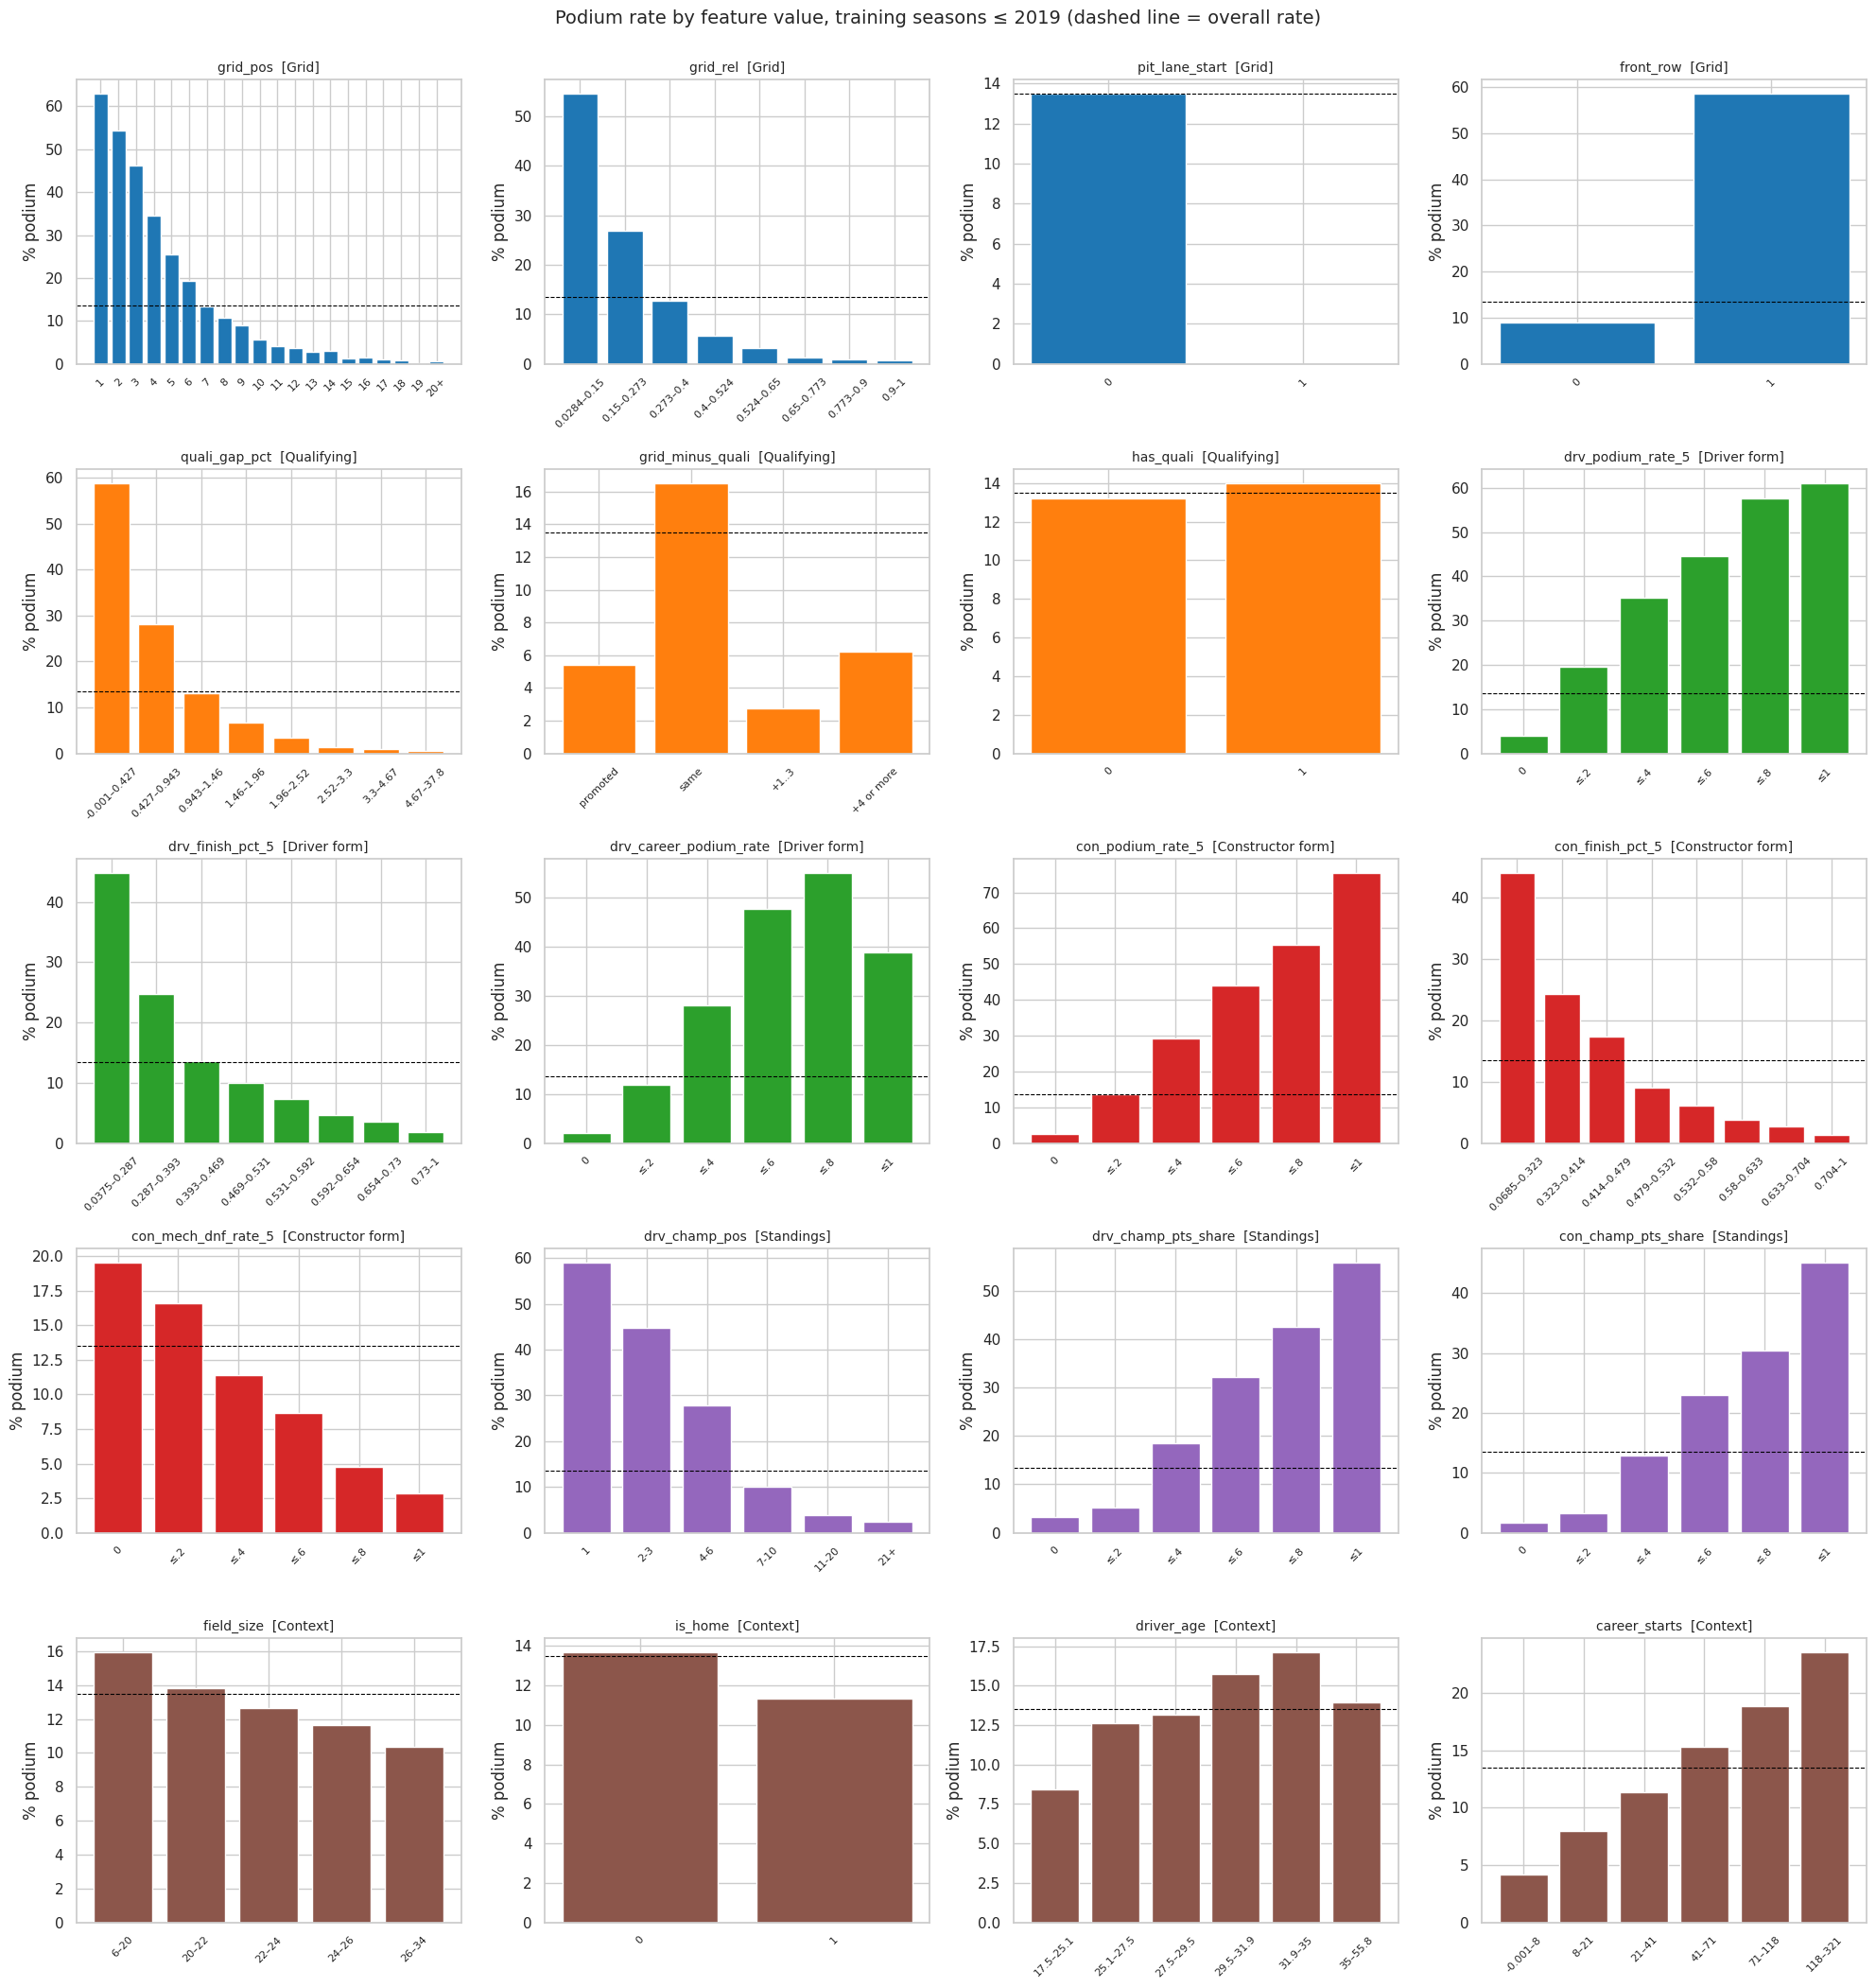

In [73]:
# ---- 5.4 Evidence: podium rate across the values of each candidate feature (TRAINING seasons only) ----
# Feature evidence is computed on seasons <= 2019 only, so validation and test seasons never influence
# which features we keep.
ev = model_df[model_df["year"] <= TRAIN_END].copy()
print(f"Evidence rows (train seasons): {len(ev):,} | podium rate {ev['podium'].mean():.1%}")

EVIDENCE_PLOTS = [  # (feature, group, binning)
    ("grid_pos", "Grid", "cat20"), ("grid_rel", "Grid", 8), ("pit_lane_start", "Grid", "cat"), ("front_row", "Grid", "cat"),
    ("quali_gap_pct", "Qualifying", 8), ("grid_minus_quali", "Qualifying", "penalty"), ("has_quali", "Qualifying", "cat"),
    ("drv_podium_rate_5", "Driver form", "rate"), ("drv_finish_pct_5", "Driver form", 8), ("drv_career_podium_rate", "Driver form", "rate"),
    ("con_podium_rate_5", "Constructor form", "rate"), ("con_finish_pct_5", "Constructor form", 8), ("con_mech_dnf_rate_5", "Constructor form", "rate"),
    ("drv_champ_pos", "Standings", "pos"), ("drv_champ_pts_share", "Standings", "rate"), ("con_champ_pts_share", "Standings", "rate"),
    ("field_size", "Context", 6), ("is_home", "Context", "cat"), ("driver_age", "Context", 6), ("career_starts", "Context", 6),
]


def binned(series, how):
    if how == "cat":
        return series.astype(int)
    if how == "cat20":                                   # ordered slots 1..19, then "20+"
        labels = [str(i) for i in range(1, 20)] + ["20+"]
        return pd.Categorical(series.clip(upper=20).astype(int).map(lambda v: labels[v - 1]), categories=labels, ordered=True)
    if how == "penalty":
        return pd.cut(series, [-np.inf, -1, 0, 3, np.inf], labels=["promoted", "same", "+1..3", "+4 or more"])
    if how == "rate":
        return pd.cut(series, [-0.001, 0, 0.2, 0.4, 0.6, 0.8, 1.0], labels=["0", "≤.2", "≤.4", "≤.6", "≤.8", "≤1"])
    if how == "pos":
        return pd.cut(series, [0, 1, 3, 6, 10, 20, 30], labels=["1", "2-3", "4-6", "7-10", "11-20", "21+"])
    q = pd.qcut(series, how, duplicates="drop")
    return q.cat.rename_categories([f"{iv.left:.3g}–{iv.right:.3g}" for iv in q.cat.categories])


fig, axes = plt.subplots(5, 4, figsize=(20, 21))
group_colors = dict(zip(["Grid", "Qualifying", "Driver form", "Constructor form", "Standings", "Context"], sns.color_palette("tab10", 6)))
for ax, (feat, group, how) in zip(axes.ravel(), EVIDENCE_PLOTS):
    d = ev[[feat, "podium"]].dropna()
    rate = d.groupby(binned(d[feat], how), observed=True)["podium"].agg(["mean", "size"])
    ax.bar(rate.index.astype(str), rate["mean"] * 100, color=group_colors[group])
    ax.axhline(ev["podium"].mean() * 100, color="black", linestyle="--", linewidth=0.8)
    ax.set_title(f"{feat}  [{group}]", fontsize=10)
    ax.set_ylabel("% podium")
    ax.tick_params(axis="x", rotation=45, labelsize=8)
fig.suptitle("Podium rate by feature value, training seasons ≤ 2019 (dashed line = overall rate)", y=1.0, fontsize=14)
plt.tight_layout()
save_fig("5_4_podium_rate_by_feature")
plt.show()

Distributions of the numeric candidates for podium vs non-podium rows (box = middle 50%, line = median).

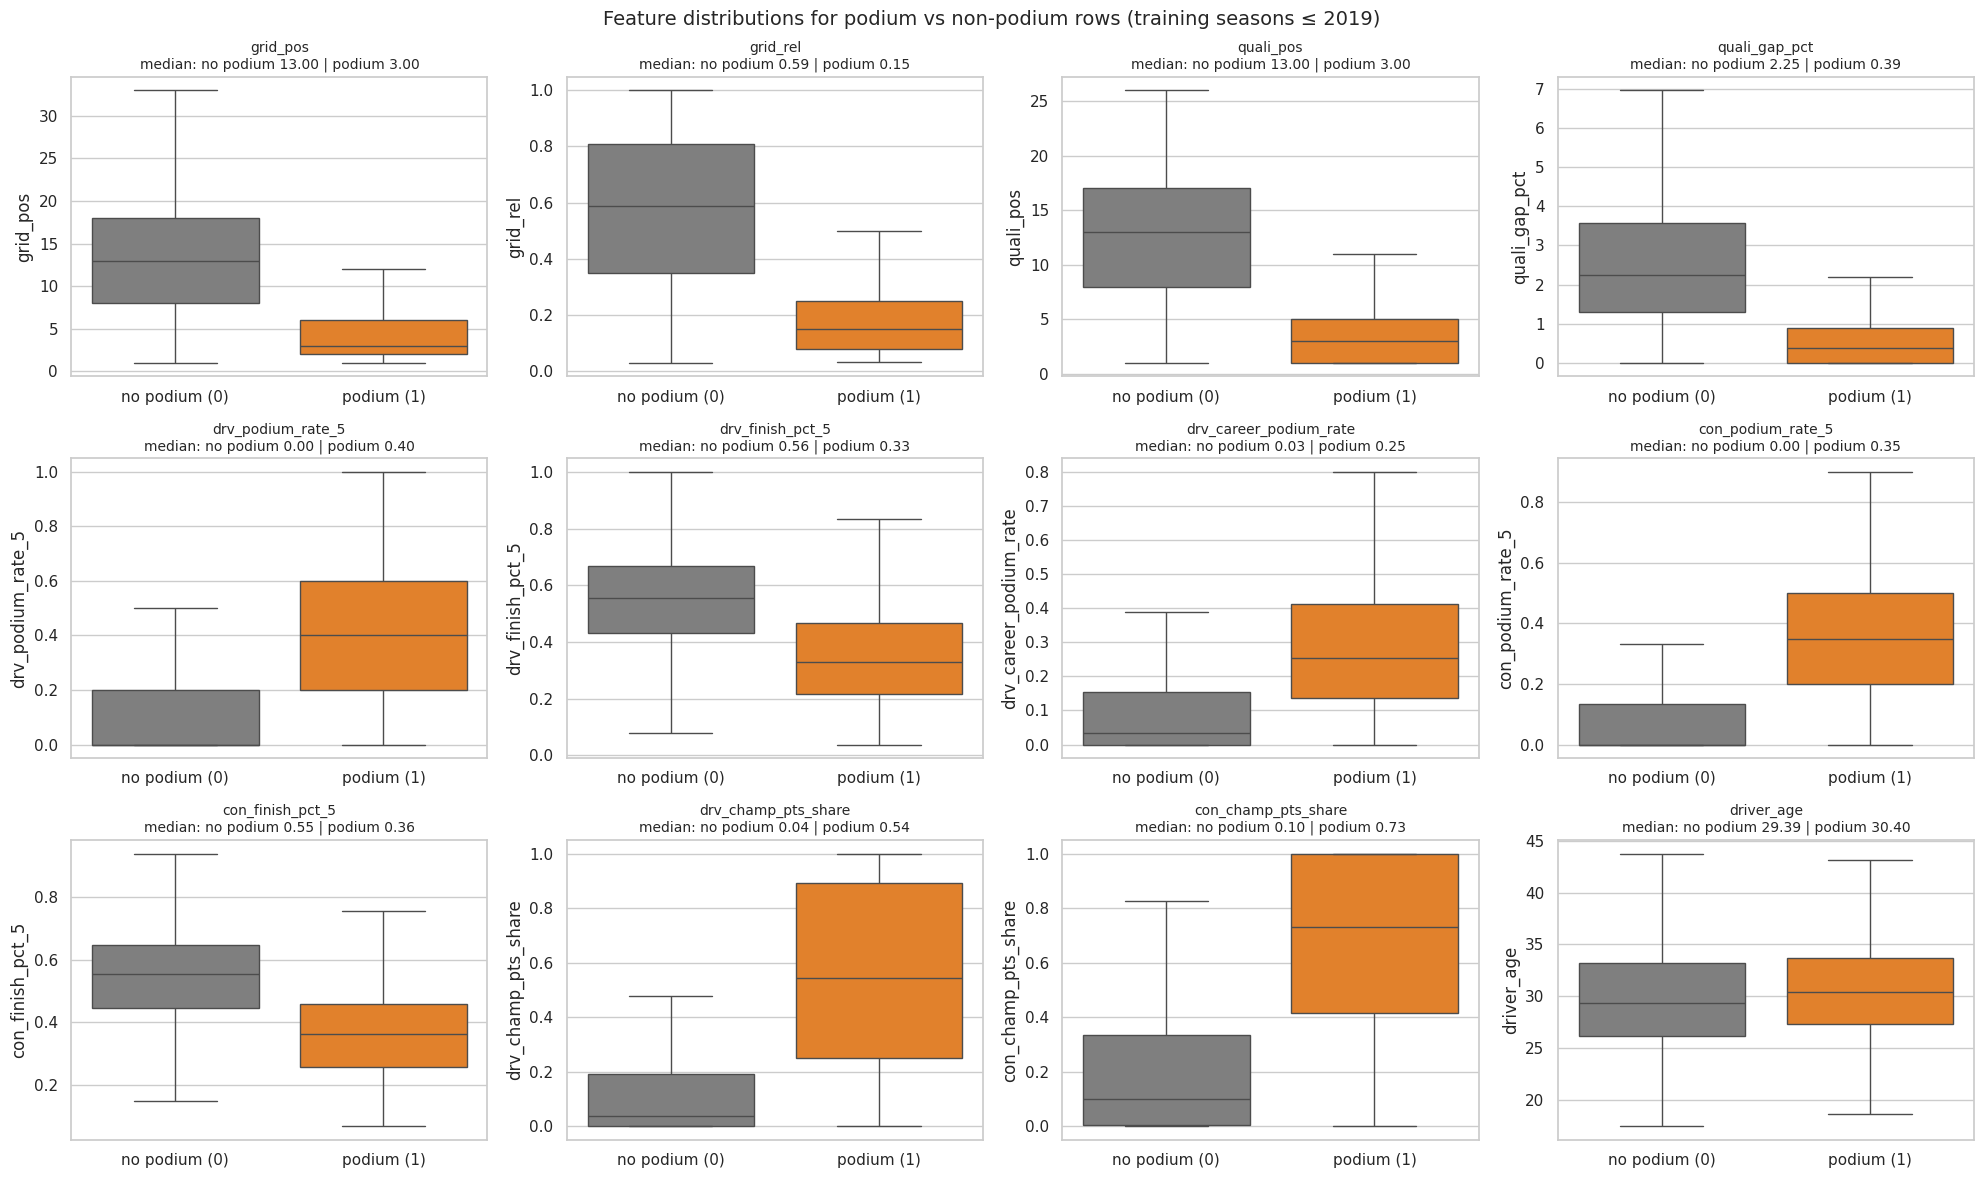

In [74]:
# ---- Distributions of numeric candidate features: podium vs non-podium (training seasons) ----
dist_feats = ["grid_pos", "grid_rel", "quali_pos", "quali_gap_pct", "drv_podium_rate_5", "drv_finish_pct_5",
              "drv_career_podium_rate", "con_podium_rate_5", "con_finish_pct_5", "drv_champ_pts_share",
              "con_champ_pts_share", "driver_age"]
fig, axes = plt.subplots(3, 4, figsize=(20, 12))
for ax, feat in zip(axes.ravel(), dist_feats):
    d = ev[[feat, "podium"]].dropna()
    sns.boxplot(data=d, x="podium", y=feat, ax=ax, showfliers=False, palette=["tab:gray", "tab:orange"])
    med = d.groupby("podium")[feat].median()
    ax.set_title(f"{feat}\nmedian: no podium {med.get(0, np.nan):.2f} | podium {med.get(1, np.nan):.2f}", fontsize=10)
    ax.set_xticklabels(["no podium (0)", "podium (1)"])
    ax.set_xlabel("")
fig.suptitle("Feature distributions for podium vs non-podium rows (training seasons ≤ 2019)", fontsize=14)
plt.tight_layout()
save_fig("5_4_distributions_podium_vs_not")
plt.show()

Redundancy (Spearman correlation between candidates) and association with the target (mutual information, which also captures non-linear relationships, and the single-feature ROC-AUC).

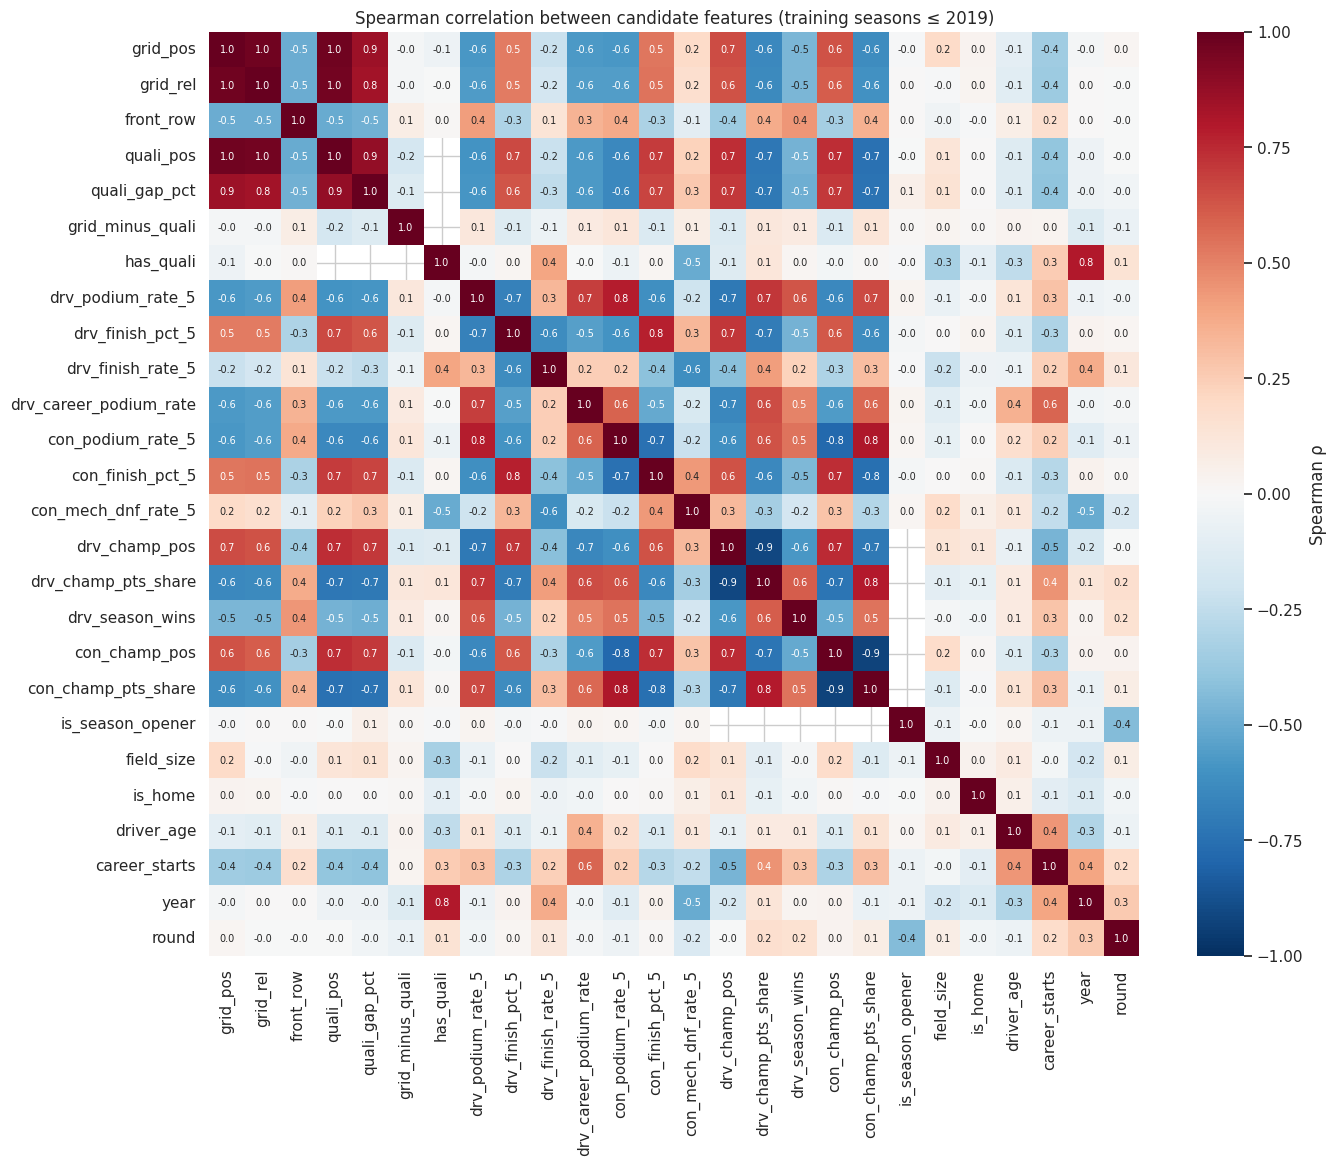

Highly redundant pairs (|ρ| ≥ 0.85):


,feature A,feature B,rho
2,grid_pos,quali_pos,0.976
0,grid_pos,grid_rel,0.970
26,grid_rel,quali_pos,0.962
283,con_champ_pos,con_champ_pts_share,-0.923
256,drv_champ_pos,drv_champ_pts_share,-0.913
72,quali_pos,quali_gap_pct,0.879
3,grid_pos,quali_gap_pct,0.857


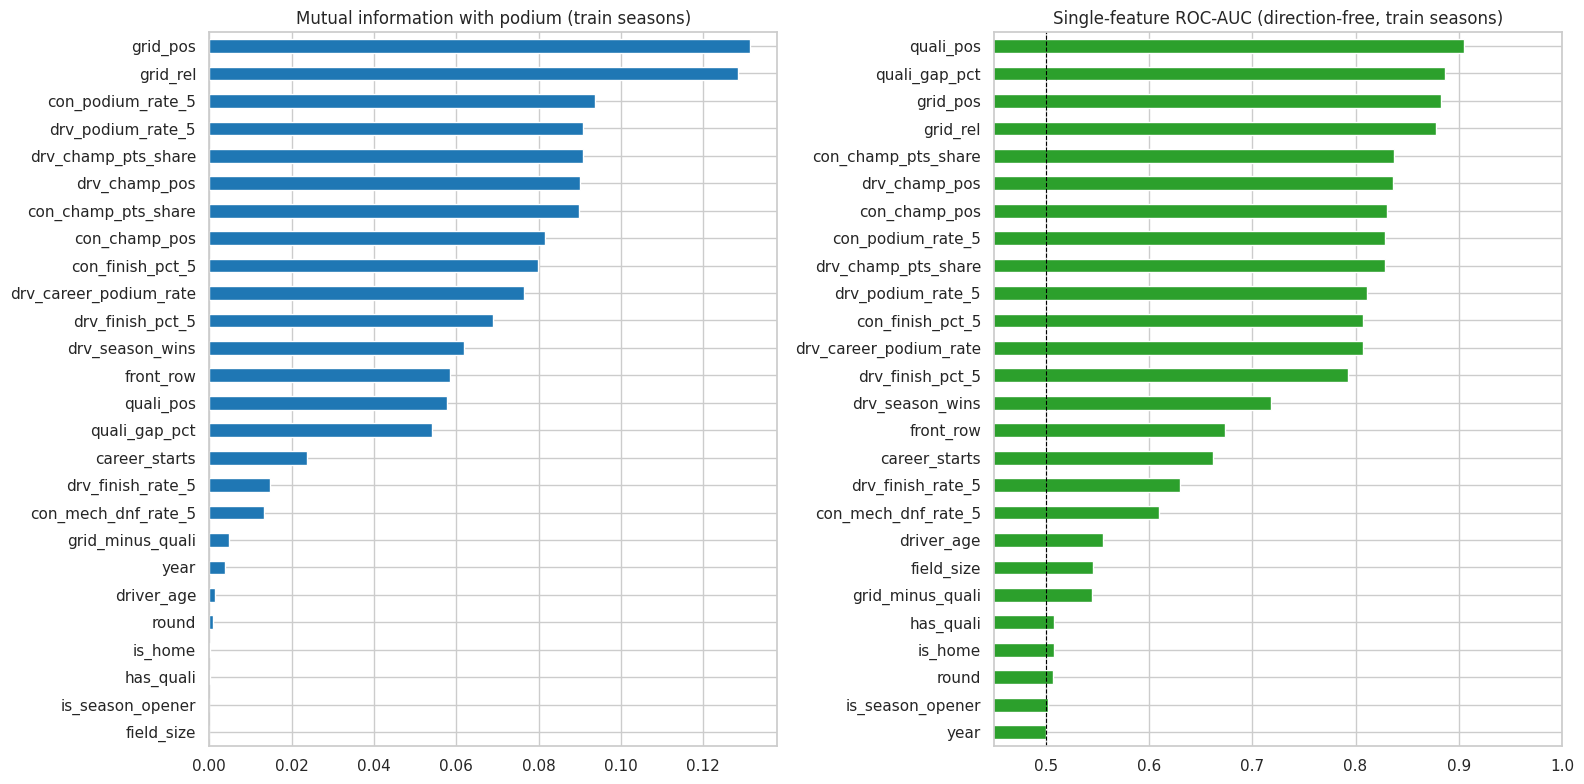

,mutual information,single-feature AUC,Spearman ρ with podium
grid_pos,0.131,0.883,-0.454
grid_rel,0.129,0.878,-0.448
con_podium_rate_5,0.094,0.829,0.424
drv_podium_rate_5,0.091,0.811,0.444
drv_champ_pts_share,0.091,0.828,0.399
drv_champ_pos,0.090,0.836,-0.397
con_champ_pts_share,0.090,0.837,0.400
con_champ_pos,0.082,0.830,-0.391
con_finish_pct_5,0.080,0.807,-0.365
drv_career_podium_rate,0.076,0.807,0.377


In [75]:
# ---- Redundancy (Spearman correlation) and association with the target (mutual information) ----
from sklearn.feature_selection import mutual_info_classif

corr_feats = ["grid_pos", "grid_rel", "front_row", "quali_pos", "quali_gap_pct", "grid_minus_quali", "has_quali",
              "drv_podium_rate_5", "drv_finish_pct_5", "drv_finish_rate_5", "drv_career_podium_rate",
              "con_podium_rate_5", "con_finish_pct_5", "con_mech_dnf_rate_5",
              "drv_champ_pos", "drv_champ_pts_share", "drv_season_wins", "con_champ_pos", "con_champ_pts_share",
              "is_season_opener", "field_size", "is_home", "driver_age", "career_starts", "year", "round"]
corr = ev[corr_feats].corr(method="spearman")

plt.figure(figsize=(15, 12))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f", annot_kws={"size": 7},
            cbar_kws={"label": "Spearman ρ"})
plt.title("Spearman correlation between candidate features (training seasons ≤ 2019)")
save_fig("5_4_correlation_heatmap")
plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
             .rename("rho").reset_index().rename(columns={"level_0": "feature A", "level_1": "feature B"}))
print("Highly redundant pairs (|ρ| ≥ 0.85):")
display(pairs[pairs["rho"].abs() >= 0.85].sort_values("rho", key=abs, ascending=False).round(3))

# Mutual information needs complete rows: missing values are filled with the TRAINING median for this
# measurement only (the real imputation happens inside the pipeline in Section 7).
X_mi = ev[corr_feats].fillna(ev[corr_feats].median())
discrete = [X_mi[c].nunique() <= 2 for c in corr_feats]
mi = pd.Series(mutual_info_classif(X_mi, ev["podium"], discrete_features=discrete, random_state=SEED), index=corr_feats)
evidence_table = pd.DataFrame({"mutual information": mi, "single-feature AUC": single_auc.reindex(corr_feats),
                               "Spearman ρ with podium": ev[corr_feats].corrwith(ev["podium"], method="spearman")})
evidence_table = evidence_table.sort_values("mutual information", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
evidence_table["mutual information"].sort_values().plot.barh(ax=axes[0], color="tab:blue")
axes[0].set_title("Mutual information with podium (train seasons)")
evidence_table["single-feature AUC"].sort_values().plot.barh(ax=axes[1], color="tab:green")
axes[1].axvline(0.5, color="black", linestyle="--", linewidth=0.8)
axes[1].set_xlim(0.45, 1)
axes[1].set_title("Single-feature ROC-AUC (direction-free, train seasons)")
plt.tight_layout()
save_fig("5_4_mutual_information")
plt.show()
display(evidence_table.round(3))

**Findings (hypothesis-driven evidence).**
- **Grid** is the strongest group: the podium rate falls from ~63% on pole to under 5% beyond P10 (`grid_pos` MI 0.13, AUC 0.88). Pit-lane starters never podium in the training seasons (0 of 19 rows).
- **Qualifying** carries the same starting-position signal: within 0.4% of pole → 59% podiums, beyond 3.3% → under 1%. `has_quali` itself is unrelated to the podium (13.2% vs 14.0%), so the missingness is driven by era, not by the outcome — imputation plus a flag is appropriate.
- **Driver form**: the podium rate rises monotonically with the recent podium rate (4% → 61%) and with a better recent finishing position.
- **Constructor form**: the strongest form signal (podium rate 3% → 75% across bins). Teams with many recent mechanical DNFs podium less (20% → 3%), linking Q3's reliability analysis to prediction.
- **Standings**: the championship leader podiums ~59% of the time; the points share shows a clean monotone relationship.
- **Context**: weak on its own — field size (16% → 10% as fields grow), experience (4% for rookies → 24% for veterans); `is_home` shows no effect (MI ≈ 0), as Q2 found after controlling for grid; `year` and `round` have MI ≈ 0.
- **Redundancy**: `grid_pos`, `grid_rel` and `quali_pos` are highly correlated (ρ 0.96–0.98), as are each championship rank and its points share (ρ ≈ −0.92). Whether to drop one of each pair is tested empirically in 5.5b rather than decided by correlation alone.

## 5.5 Empirical feature decisions (experiments kept for verification)

A small helper trains two reference models — Logistic Regression and HistGradientBoosting, inside a median-imputation + scaling pipeline — on training seasons and scores them on the **validation seasons (2020–21)**. The primary metric is PR-AUC (justified in Section 8). Using two different model types guards against a decision that only suits one algorithm; decisions use their **mean** PR-AUC.

In [76]:
# ---- 5.5 Empirical feature decisions: a quick, leakage-safe evaluation helper ------------------
# The split boundaries were fixed in Section 0 (train <= 2019, validation 2020-2021, test >= 2022),
# so these experiments train on training seasons and score on VALIDATION seasons only. The test
# seasons are never touched here. The full split is reported in Section 6.
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

VAL_MASK = model_df["year"].between(TRAIN_END + 1, VAL_END)


def quick_pipeline(num, cat, model):
    steps = [("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), list(num))]
    if cat:
        steps.append(("cat", OneHotEncoder(handle_unknown="ignore"), list(cat)))
    clf = (LogisticRegression(max_iter=5000) if model == "LR"
           else HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=SEED))
    return Pipeline([("prep", ColumnTransformer(steps, sparse_threshold=0)), ("model", clf)])


def quick_eval(num, cat=(), train_from=1950, models=("LR", "HGB")):
    """Fit on training seasons [train_from, 2019]; return validation PR-AUC / ROC-AUC (2020-2021)."""
    tr = model_df[model_df["year"].between(train_from, TRAIN_END)]
    va = model_df[VAL_MASK]
    cols = list(num) + list(cat)
    out = {}
    for m in models:
        p = quick_pipeline(num, cat, m).fit(tr[cols], tr["podium"]).predict_proba(va[cols])[:, 1]
        out[f"{m} PR-AUC"] = average_precision_score(va["podium"], p)
        out[f"{m} ROC-AUC"] = roc_auc_score(va["podium"], p)
    out["mean PR-AUC"] = np.mean([out[f"{m} PR-AUC"] for m in models])
    return out


def candidate_features(n):
    """The candidate set for rolling window n (grid, qualifying, form, standings, context)."""
    return (["grid_pos", "grid_rel", "pit_lane_start", "quali_pos", "quali_gap_pct", "grid_minus_quali", "has_quali",
             f"drv_podium_rate_{n}", f"drv_finish_pct_{n}", f"drv_finish_rate_{n}", "drv_career_podium_rate",
             f"con_podium_rate_{n}", f"con_finish_pct_{n}", f"con_mech_dnf_rate_{n}",
             "drv_champ_pos", "drv_champ_pts_share", "drv_season_wins", "con_champ_pos", "con_champ_pts_share",
             "is_season_opener", "field_size", "is_home", "driver_age", "career_starts"])

print("Validation rows:", int(VAL_MASK.sum()), "| podiums:", int(model_df.loc[VAL_MASK, "podium"].sum()))

Validation rows: 774 | podiums: 117


**Experiment 5.5a — rolling window *N* × training window.** Two open decisions are tested together:
- *N* for the form features: 3, 5, 10 or 20 previous races;
- which seasons to **train** on: the full cleaned history (1950+), 1980+, or the modern window 2003+ where qualifying coverage is complete. Features are always computed on the full history, so a 2003 row still has form from 2002; only the training rows change, and the validation rows are identical in all 12 runs.

,N,training window,train rows,LR PR-AUC,LR ROC-AUC,HGB PR-AUC,HGB ROC-AUC,mean PR-AUC
0,3,full history (1950+),22426,0.7274,0.9293,0.7230,0.9289,0.7252
1,3,1980+,15647,0.7260,0.9290,0.7070,0.9268,0.7165
2,3,modern (2003+),6780,0.7158,0.9278,0.6764,0.9248,0.6961
3,5,full history (1950+),22426,0.7285,0.9302,0.7224,0.9308,0.7255
4,5,1980+,15647,0.7348,0.9303,0.7153,0.9273,0.7251
5,5,modern (2003+),6780,0.7241,0.9296,0.6701,0.9254,0.6971
6,10,full history (1950+),22426,0.7339,0.9311,0.7435,0.9326,0.7387
7,10,1980+,15647,0.7302,0.9314,0.7251,0.9272,0.7277
8,10,modern (2003+),6780,0.7258,0.9316,0.7147,0.9264,0.7203
9,20,full history (1950+),22426,0.7418,0.9310,0.7533,0.9302,0.7475


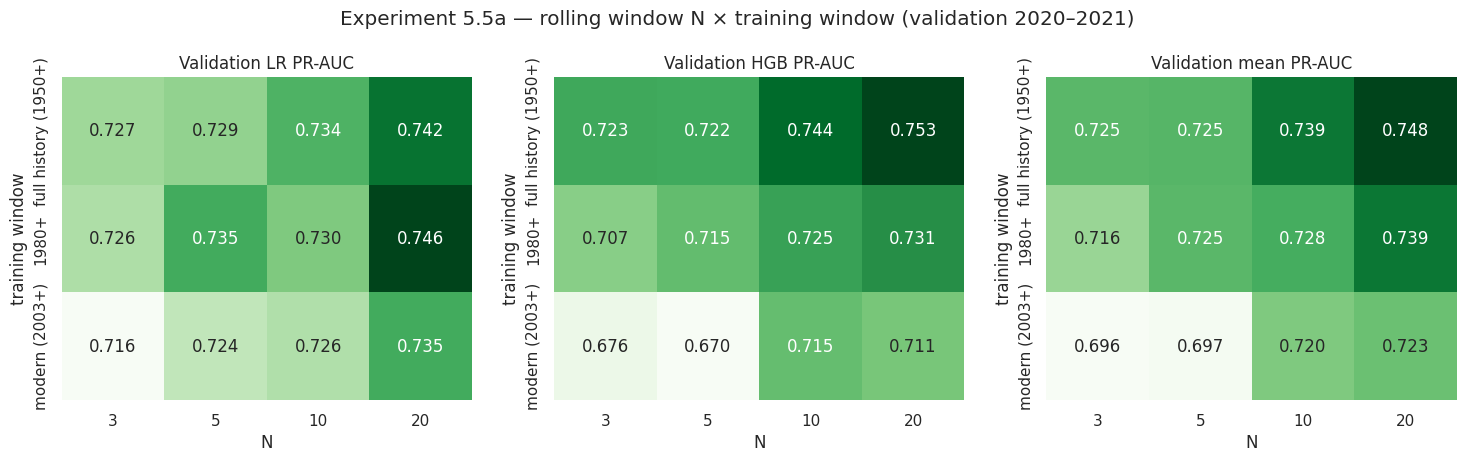

Selected by mean validation PR-AUC: N = 20, training window = full history (1950+) (LR 0.742, HGB 0.753)


In [77]:
# ---- Experiment 5.5a: rolling window N (3 / 5 / 10 / 20) x modeling window (full history / 1980+ / 2003+) ----
# Features are always computed on the FULL history (so a 2003 row still has form from 2002); only the
# set of TRAINING rows changes. The validation rows (2020-2021) are identical in every run, so the
# scores are directly comparable.
TRAIN_WINDOWS = {"full history (1950+)": 1950, "1980+": 1980, "modern (2003+)": 2003}
exp_rows = []
for n in FORM_WINDOWS:
    for wname, start in TRAIN_WINDOWS.items():
        n_rows = int(model_df["year"].between(start, TRAIN_END).sum())
        exp_rows.append({"N": n, "training window": wname, "train rows": n_rows, **quick_eval(candidate_features(n), train_from=start)})
exp_window_n = pd.DataFrame(exp_rows)
display(exp_window_n.round(4))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
for ax, metric in zip(axes, ["LR PR-AUC", "HGB PR-AUC", "mean PR-AUC"]):
    pivot = exp_window_n.pivot(index="training window", columns="N", values=metric).reindex(TRAIN_WINDOWS)
    sns.heatmap(pivot, annot=True, fmt=".3f", cmap="Greens", ax=ax, cbar=False)
    ax.set_title(f"Validation {metric}")
plt.suptitle("Experiment 5.5a — rolling window N × training window (validation 2020–2021)", y=1.04)
save_fig("5_5_window_and_N")
plt.show()

best = exp_window_n.sort_values("mean PR-AUC", ascending=False).iloc[0]
FORM_N = int(best["N"])
TRAIN_START = TRAIN_WINDOWS[best["training window"]]
print(f"Selected by mean validation PR-AUC: N = {FORM_N}, training window = {best['training window']} "
      f"(LR {best['LR PR-AUC']:.3f}, HGB {best['HGB PR-AUC']:.3f})")

**Findings.**
- **Training window: full history wins for every *N*.** Restricting training to 2003+ (near-complete qualifying) is consistently worse (e.g. *N* = 20: mean PR-AUC 0.748 full history vs 0.739 for 1980+ and 0.723 for 2003+). Older seasons add 15,000+ training rows of grid–form–standings relationships, and the missing qualifying values are handled safely by imputation + `has_quali`. **Decision: train on the full cleaned history (1950–2019)**; the modern-window alternative is kept here as evidence.
- **Rolling window: *N* = 20 is best** (mean PR-AUC 0.748 vs 0.739 for 10, 0.726 for 5 and 0.725 for 3). Longer windows are less noisy (a podium rate over 3 races can only be 0, ⅓, ⅔ or 1). 20 races ≈ one season, so the feature still reacts to a team's new car each year. **Decision: *N* = 20.**
- The validation set has only 774 rows (117 podiums), so differences below ~0.01 are within noise; the decisions above are supported by both models and by every row/column of the grid.

**Experiment 5.5b — optional and redundant features.** Starting from the base set (*N* = 20, full history), each change is tested on its own. The acceptance rules were fixed *before* running: an optional feature is added only if mean validation PR-AUC improves by ≥ 0.005; a redundant feature is removed if dropping it does not lower mean PR-AUC.

,LR PR-AUC,LR ROC-AUC,HGB PR-AUC,HGB ROC-AUC,mean PR-AUC,Δ mean PR-AUC vs base,decision
variant,,,,,,,
base set,0.7418,0.9310,0.7533,0.9302,0.7475,0.0000,—
+ front_row (redundant with grid?),0.7409,0.9310,0.7533,0.9302,0.7471,-0.0004,do not add
+ year (numeric era),0.7414,0.9318,0.7545,0.9311,0.7480,0.0004,do not add
+ round,0.7408,0.9314,0.7532,0.9294,0.7470,-0.0005,do not add
+ circuitId (one-hot),0.7378,0.9312,0.7473,0.9267,0.7425,-0.0050,do not add
+ constructorId (one-hot identity),0.7398,0.9293,0.7480,0.9298,0.7439,-0.0037,do not add
− grid_rel (ρ=0.97 with grid_pos),0.7416,0.9310,0.7376,0.9265,0.7396,-0.0079,keep
− quali_pos (ρ=0.98 with grid_pos),0.7411,0.9308,0.7498,0.9290,0.7454,-0.0021,keep
− championship ranks (ρ≈−0.92 with shares),0.7414,0.9308,0.7424,0.9272,0.7419,-0.0057,keep


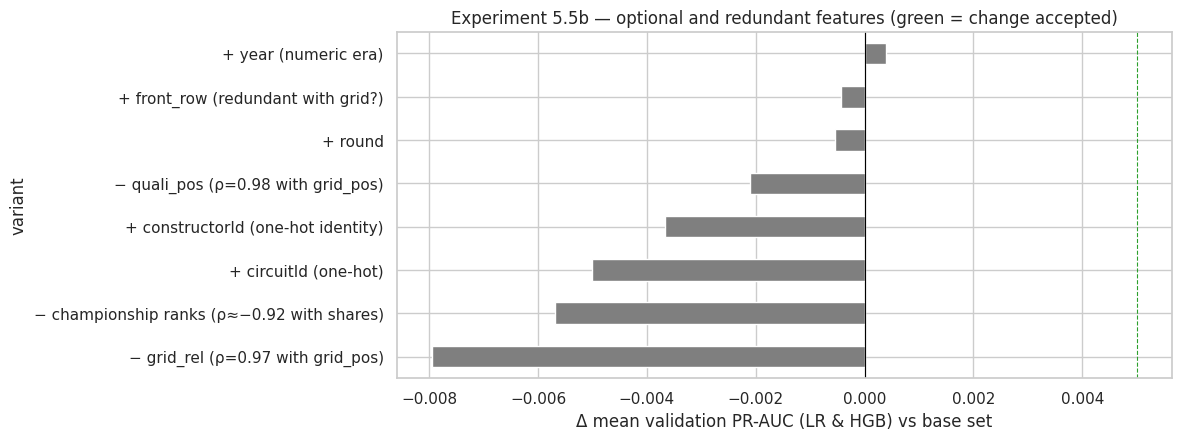

Accepted additions: none
Accepted removals: none


In [78]:
# ---- Experiment 5.5b: optional / redundant features, tested one at a time against the base set ----
# Rules decided BEFORE looking at the numbers:
#   * an optional feature is ADDED only if it improves mean validation PR-AUC by at least +0.005
#     (smaller gains are within the noise of a 774-row validation set);
#   * a redundant feature (|ρ| >= 0.85 in 5.4) is REMOVED if dropping it does not lower mean PR-AUC (simpler model).
base = candidate_features(FORM_N)
base_score = quick_eval(base, train_from=TRAIN_START)

variants = {
    "+ front_row (redundant with grid?)":          (base + ["front_row"], []),
    "+ year (numeric era)":                        (base + ["year"], []),
    "+ round":                                     (base + ["round"], []),
    "+ circuitId (one-hot)":                       (base, ["circuitId"]),
    "+ constructorId (one-hot identity)":          (base, ["constructorId"]),
    "− grid_rel (ρ=0.97 with grid_pos)":           ([f for f in base if f != "grid_rel"], []),
    "− quali_pos (ρ=0.98 with grid_pos)":          ([f for f in base if f != "quali_pos"], []),
    "− championship ranks (ρ≈−0.92 with shares)":  ([f for f in base if f not in ("drv_champ_pos", "con_champ_pos")], []),
}
rows = [{"variant": "base set", **base_score}]
for name, (num, cat) in variants.items():
    rows.append({"variant": name, **quick_eval(num, cat, train_from=TRAIN_START)})
exp_optional = pd.DataFrame(rows).set_index("variant")
exp_optional["Δ mean PR-AUC vs base"] = exp_optional["mean PR-AUC"] - base_score["mean PR-AUC"]
exp_optional["decision"] = [
    "—" if v == "base set" else
    ("ADD" if d >= 0.005 else "do not add") if v.startswith("+") else
    ("REMOVE" if d >= 0 else "keep")
    for v, d in zip(exp_optional.index, exp_optional["Δ mean PR-AUC vs base"])]
display(exp_optional.round(4))

ax = exp_optional["Δ mean PR-AUC vs base"].drop("base set").sort_values().plot.barh(
    figsize=(10, 4.5), color=["tab:green" if d in ("ADD", "REMOVE") else "tab:gray"
                              for d in exp_optional.drop("base set").sort_values("Δ mean PR-AUC vs base")["decision"]])
ax.axvline(0, color="black", linewidth=0.8)
ax.axvline(0.005, color="tab:green", linestyle="--", linewidth=0.8)
ax.set_xlabel("Δ mean validation PR-AUC (LR & HGB) vs base set")
ax.set_title("Experiment 5.5b — optional and redundant features (green = change accepted)")
save_fig("5_5_optional_features")
plt.show()

ADDED   = [v for v, d in exp_optional["decision"].items() if d == "ADD"]
REMOVED = [v for v, d in exp_optional["decision"].items() if d == "REMOVE"]
print("Accepted additions:", ADDED or "none")
print("Accepted removals:", REMOVED or "none")

**Findings.** **No change is accepted.**
- No optional addition comes close to the +0.005 rule: `front_row` (−0.0004, redundant with `grid_pos`), `year` (+0.0004, far below the rule and within noise; it would also force the model to extrapolate to unseen seasons), `round` (−0.0005), circuit one-hot (−0.0050) and constructor one-hot (−0.0037). Identity encodings add many sparse columns and let the model memorise teams and tracks whose performance changes from era to era; form features describe the *current* strength instead.
- Removing a correlated feature also hurts: `grid_rel` (−0.0079), `quali_pos` (−0.0021), the two championship ranks (−0.0057). They carry complementary information (`grid_rel` normalises big fields; `quali_pos` differs from the grid after penalties; the rank and the points share differ when the championship is close or one-sided).

## 5.6 Final feature set

The final set is the base set confirmed by 5.5: **24 features in 6 groups**, rolling window ***N* = 20**, trained on the full history. The table lists, for every feature: group, type, training-set evidence (mutual information and single-feature AUC), the observation that justifies it, why it is valid at the pre-race cutoff and how its missing values are handled.

In [79]:
# ---- 5.6 Final feature set (grouped; the same groups are used in the ablation, Section 8.5) ----
n = FORM_N
FEATURE_GROUPS = {
    "Grid":             ["grid_pos", "grid_rel", "pit_lane_start"],
    "Qualifying":       ["quali_pos", "quali_gap_pct", "grid_minus_quali", "has_quali"],
    "Driver form":      [f"drv_podium_rate_{n}", f"drv_finish_pct_{n}", f"drv_finish_rate_{n}", "drv_career_podium_rate"],
    "Constructor form": [f"con_podium_rate_{n}", f"con_finish_pct_{n}", f"con_mech_dnf_rate_{n}"],
    "Standings":        ["drv_champ_pos", "drv_champ_pts_share", "drv_season_wins", "con_champ_pos", "con_champ_pts_share",
                         "is_season_opener"],
    "Context":          ["field_size", "is_home", "driver_age", "career_starts"],
}
# Apply the accepted changes of Experiment 5.5b (none were accepted in our run, but the code honours them).
# The features a variant removes are taken from its feature list (exact names), not from its text label.
for variant in REMOVED:
    dropped = set(base) - set(variants[variant][0])
    for g in FEATURE_GROUPS.values():
        g[:] = [f for f in g if f not in dropped]
FEATURES = [f for g in FEATURE_GROUPS.values() for f in g]
assert FEATURES == [f for f in candidate_features(n) if f in FEATURES] and not set(FEATURES) & FORBIDDEN_FEATURES
BINARY_FEATURES  = [f for f in FEATURES if set(model_df[f].dropna().unique()) <= {0, 1}]
NUMERIC_FEATURES = [f for f in FEATURES if f not in BINARY_FEATURES]

EVIDENCE_TEXT = {
    "grid_pos": "podium rate falls from ~63% (P1) to <5% beyond P10 (1.4, 5.4)",
    "grid_rel": "same signal, comparable across field sizes; removing it costs PR-AUC (5.5b)",
    "pit_lane_start": "pit-lane starters: 0 podiums in 19 training rows (5.4)",
    "quali_pos": "best single-feature AUC 0.905; removing it costs PR-AUC (5.5b)",
    "quali_gap_pct": "podium rate 59% within 0.4% of pole vs <1% beyond 3.3% (5.4)",
    "grid_minus_quali": "penalised front-row qualifiers podium 31% vs 64% (Q1, 4.1)",
    "has_quali": "structural flag: qualifying absent before 1994 / patchy 1996–2002 (1.3)",
    f"drv_podium_rate_{n}": f"rate rises monotonically with past podium share; N={n} best on validation (5.5a)",
    f"drv_finish_pct_{n}": "drivers who recently finished near the front podium far more often (5.4)",
    f"drv_finish_rate_{n}": "reliability/consistency of the driver; moderate association (5.4)",
    "drv_career_podium_rate": "long-run ability; complements the short window (5.4)",
    f"con_podium_rate_{n}": "car performance: podium rate 3% → 75% across bins (5.4)",
    f"con_finish_pct_{n}": "team's average finishing position; strong monotone relation (5.4)",
    f"con_mech_dnf_rate_{n}": "reliability: podium rate drops as past mechanical DNFs rise (Q3, 5.4)",
    "drv_champ_pos": "championship leader podiums ~59% vs <5% outside top 10 (5.4)",
    "drv_champ_pts_share": "share of leader's points; strong monotone relation (5.4)",
    "drv_season_wins": "season wins so far; MI 0.06 (5.4)",
    "con_champ_pos": "team rank before the race; strong relation (5.4)",
    "con_champ_pts_share": "team points share; podium rate 2% → 45% (5.4)",
    "is_season_opener": "structural flag: no standings exist before round 1",
    "field_size": "structural context: podium base rate falls in big fields (16% → 10%, 5.4)",
    "is_home": "kept to test Q2 inside the model (Q2 found no effect after grid control)",
    "driver_age": "weak, non-linear (peaks at 30–35, 5.4)",
    "career_starts": "experience: podium rate 4% (rookies) → 24% (veterans) (5.4)",
}
MISSING_TEXT = {
    "Grid": "never missing", "Qualifying": "missing before 1994 / 1996–2002 → median imputation + has_quali flag",
    "Driver form": "first career start → median imputation (career_starts = 0 tells the model)",
    "Constructor form": "first race of a constructorId → median imputation",
    "Standings": "round 1 → median imputation + is_season_opener; constructors before 1958 → median",
    "Context": "never missing",
}
train_ev = model_df[model_df["year"].between(TRAIN_START, TRAIN_END)]
X_ev = train_ev[FEATURES].fillna(train_ev[FEATURES].median())
mi_final = mutual_info_classif(X_ev, train_ev["podium"], discrete_features=[f in BINARY_FEATURES for f in FEATURES],
                               random_state=SEED)
final_feature_table = pd.DataFrame({
    "feature": FEATURES,
    "group": [g for g, fs in FEATURE_GROUPS.items() for _ in fs],
    "type": ["binary" if f in BINARY_FEATURES else "numeric" for f in FEATURES],
    "MI (train)": mi_final.round(3),
    "single AUC (train)": [round(max(a, 1 - a), 3) for a in
                           (roc_auc_score(train_ev.loc[train_ev[f].notna(), "podium"], train_ev.loc[train_ev[f].notna(), f]) for f in FEATURES)],
    "% missing (all rows)": (model_df[FEATURES].isna().mean() * 100).round(1).values,
    "evidence": [EVIDENCE_TEXT[f] for f in FEATURES],
    "pre-race validity": ["known once the grid is fixed" if g == "Grid" or f == "field_size" else "known after qualifying"
                          if g == "Qualifying" else "previous races only (shift(1) then rolling)" if "form" in g
                          else "previous round's standings" if g == "Standings" else "known before the weekend"
                          for g, fs in FEATURE_GROUPS.items() for f in fs],
    "missingness handling": [MISSING_TEXT[g] for g, fs in FEATURE_GROUPS.items() for _ in fs],
})
print(f"Final feature set: {len(FEATURES)} features in {len(FEATURE_GROUPS)} groups "
      f"({len(NUMERIC_FEATURES)} numeric, {len(BINARY_FEATURES)} binary). Rolling window N = {FORM_N}, "
      f"training window starts {TRAIN_START}.")
with pd.option_context("display.max_colwidth", 80):
    display(final_feature_table)

Final feature set: 24 features in 6 groups (20 numeric, 4 binary). Rolling window N = 20, training window starts 1950.


,feature,group,type,MI (train),single AUC (train),% missing (all rows),evidence,pre-race validity,missingness handling
0,grid_pos,Grid,numeric,0.130,0.883,0.0,"podium rate falls from ~63% (P1) to <5% beyond P10 (1.4, 5.4)",known once the grid is fixed,never missing
1,grid_rel,Grid,numeric,0.131,0.878,0.0,"same signal, comparable across field sizes; removing it costs PR-AUC (5.5b)",known once the grid is fixed,never missing
2,pit_lane_start,Grid,binary,0.000,0.500,0.0,pit-lane starters: 0 podiums in 19 training rows (5.4),known once the grid is fixed,never missing
3,quali_pos,Qualifying,numeric,0.058,0.905,57.6,best single-feature AUC 0.905; removing it costs PR-AUC (5.5b),known after qualifying,missing before 1994 / 1996–2002 → median imputation + has_quali flag
4,quali_gap_pct,Qualifying,numeric,0.053,0.887,58.2,podium rate 59% within 0.4% of pole vs <1% beyond 3.3% (5.4),known after qualifying,missing before 1994 / 1996–2002 → median imputation + has_quali flag
5,grid_minus_quali,Qualifying,numeric,0.007,0.544,57.6,"penalised front-row qualifiers podium 31% vs 64% (Q1, 4.1)",known after qualifying,missing before 1994 / 1996–2002 → median imputation + has_quali flag
6,has_quali,Qualifying,binary,0.000,0.508,0.0,structural flag: qualifying absent before 1994 / patchy 1996–2002 (1.3),known after qualifying,missing before 1994 / 1996–2002 → median imputation + has_quali flag
7,drv_podium_rate_20,Driver form,numeric,0.098,0.839,2.8,rate rises monotonically with past podium share; N=20 best on validation (5.5a),previous races only (shift(1) then rolling),first career start → median imputation (career_starts = 0 tells the model)
8,drv_finish_pct_20,Driver form,numeric,0.081,0.808,2.8,drivers who recently finished near the front podium far more often (5.4),previous races only (shift(1) then rolling),first career start → median imputation (career_starts = 0 tells the model)
9,drv_finish_rate_20,Driver form,numeric,0.024,0.638,2.8,reliability/consistency of the driver; moderate association (5.4),previous races only (shift(1) then rolling),first career start → median imputation (career_starts = 0 tells the model)


**Summary.** Features with MI ≈ 0 are kept only for a documented reason: `has_quali` and `is_season_opener` mark *structural* missingness (so imputed values are recognisable), `field_size` puts the grid position into context across eras, `pit_lane_start` identifies a rare but extreme case, and `is_home` is kept on purpose so the trained model can confirm or refute the Q2 conclusion (its contribution is measured in 8.5 and 9.1). No feature is selected with the test set.

<a id="6"></a>
# 6. Proper Dataset Splitting

**Time-based split by season: train 1950–2019, validation 2020–2021, test 2022–2024.**

Why this split:
- **No look-ahead.** Form and standings features come from the past; a random row split would put a driver's 2023 race in training and his 2022 race in test, so the model would learn from the future. Splitting by season mirrors real use: train on the past, predict the next seasons.
- **Whole races stay together.** All drivers of one race are in the same split, so the model is never evaluated on a race whose other finishers it has seen (the podium is a competition between the drivers of one race).
- **A realistic stress test.** The test seasons are the 2022+ ground-effect era — new cars and a new competitive order — so the test score shows how the model copes with a rules change it was never trained on.
- **Validation is recent and separate.** All tuning (features, *N*, pre-processing, hyper-parameters, thresholds, model choice) uses 2020–21 only; the test seasons are never used for any of these choices, and the models are scored on them only once, in 8.4.

,seasons,n seasons,races,rows,podiums,podium rate (%),% rows with qualifying,% of all rows
train,1950–2019,70,1007,22426,3028,13.5,37.0,91.3
validation,2020–2021,2,39,774,117,15.12,99.9,3.2
test,2022–2024,3,68,1351,204,15.1,100.0,5.5


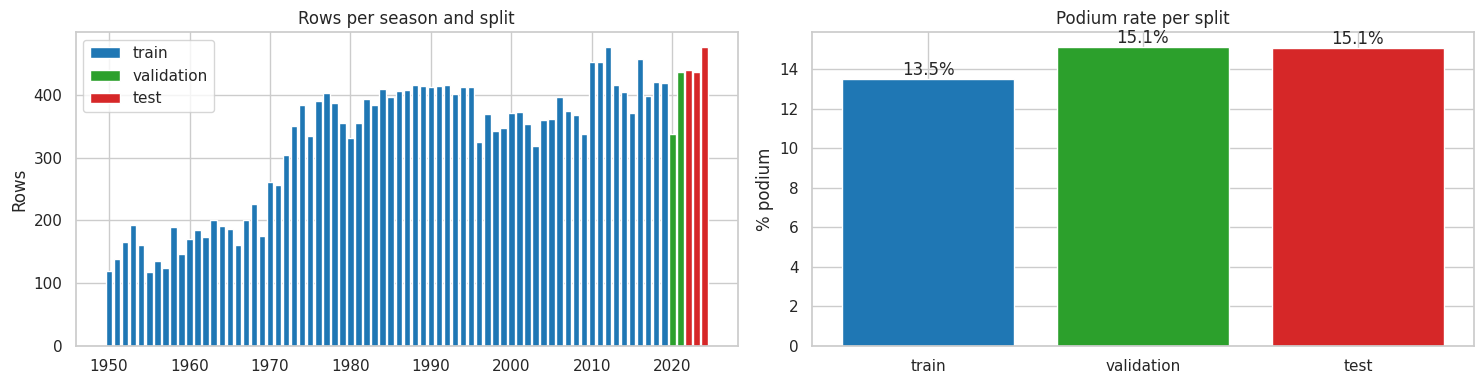

In [80]:
# ---- 6. Chronological split by season --------------------------------------------------------
train_df = model_df[model_df["year"].between(TRAIN_START, TRAIN_END)].copy()
val_df   = model_df[model_df["year"].between(TRAIN_END + 1, VAL_END)].copy()
test_df  = model_df[model_df["year"] > VAL_END].copy()

X_train, y_train = train_df[FEATURES], train_df["podium"].values
X_val,   y_val   = val_df[FEATURES],   val_df["podium"].values
X_test,  y_test  = test_df[FEATURES],  test_df["podium"].values

# Every race (and so every driver of that race) is in exactly one split, and the splits do not overlap in time
assert not (set(train_df["raceId"]) & set(val_df["raceId"])) and not (set(val_df["raceId"]) & set(test_df["raceId"]))
assert train_df["date"].max() < val_df["date"].min() and val_df["date"].max() < test_df["date"].min()
assert len(train_df) + len(val_df) + len(test_df) == len(model_df[model_df["year"] >= TRAIN_START])

split_summary = pd.DataFrame({
    name: {"seasons": f"{d['year'].min()}–{d['year'].max()}", "n seasons": d["year"].nunique(),
           "races": d["raceId"].nunique(), "rows": len(d), "podiums": int(d["podium"].sum()),
           "podium rate (%)": round(d["podium"].mean() * 100, 2),
           "% rows with qualifying": round(d["has_quali"].mean() * 100, 1),
           "% of all rows": round(len(d) / len(model_df) * 100, 1)}
    for name, d in [("train", train_df), ("validation", val_df), ("test", test_df)]}).T
display(split_summary)

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
colors = {"train": "tab:blue", "validation": "tab:green", "test": "tab:red"}
for name, d in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    per_season = d.groupby("year").size()
    axes[0].bar(per_season.index, per_season.values, color=colors[name], label=name)
axes[0].set_title("Rows per season and split")
axes[0].set_ylabel("Rows")
axes[0].legend()
axes[1].bar(split_summary.index, split_summary["podium rate (%)"].astype(float), color=list(colors.values()))
for i, v in enumerate(split_summary["podium rate (%)"].astype(float)):
    axes[1].text(i, v, f"{v:.1f}%", ha="center", va="bottom")
axes[1].set_title("Podium rate per split")
axes[1].set_ylabel("% podium")
plt.tight_layout()
save_fig("6_split")
plt.show()

**Findings.** The three splits are disjoint in time and by race (asserted). Training holds 91% of the rows; validation and test are small but complete seasons (39 and 68 races). Validation and test have a higher podium rate (~15%) than training (13.5%) because modern fields are smaller, and they have essentially complete qualifying data while most training seasons do not — one more reason to report test performance per season in 8.4.

<a id="7"></a>
# 7. Data Pre-processing and Feature Engineering

The feature engineering itself (deriving the 24 features from the raw tables) was done in Section 5. This section turns those features into model inputs. Everything that **learns from data** — imputation values, scaling means and standard deviations — is fitted on the **training rows only**, inside a scikit-learn `Pipeline`/`ColumnTransformer`, and then applied unchanged to validation, test and the inference function.

## 7.1 Pre-processing pipeline

| Feature type | Steps | Why |
|---|---|---|
| 20 numeric features | `SimpleImputer(median)` → `StandardScaler` | the median is robust to skewed features (career starts, gaps); scaling puts features with ranges 0–1 and 0–400 on one scale, which Logistic Regression and the neural network need |
| 4 binary flags (`pit_lane_start`, `has_quali`, `is_season_opener`, `is_home`) | `SimpleImputer(most_frequent)` | already 0/1 and never missing; no scaling needed |

There are no categorical features left after 5.5b (circuit and constructor identity were rejected), so no one-hot encoding is needed. The same pipeline is used by all four models, so they see **identical rows and inputs** (scaling does not change tree models, so the comparison stays fair). The factory takes two options that are tested in 7.2: the order of imputation and scaling, and whether a "was missing" indicator is added.

In [81]:
# ---- 7.1 Pre-processing pipeline factory -------------------------------------------------------
from sklearn.preprocessing import FunctionTransformer
from sklearn.base import clone


def make_preprocessor(features=None, num_order="impute_then_scale", add_indicator=False):
    """ColumnTransformer for a feature list.
    numeric: median imputation + StandardScaler (order configurable for Experiment 2)
    binary : most-frequent imputation, no scaling (already 0/1)
    add_indicator: append a 0/1 'was missing' column per numeric feature with missing values (Experiment 3)."""
    features = FEATURES if features is None else features
    numeric = [f for f in features if f in NUMERIC_FEATURES]
    binary = [f for f in features if f in BINARY_FEATURES]
    imputer = SimpleImputer(strategy="median", add_indicator=add_indicator)
    if num_order == "impute_then_scale":
        num_pipe = Pipeline([("impute", imputer), ("scale", StandardScaler())])
    elif num_order == "scale_then_impute":
        num_pipe = Pipeline([("scale", StandardScaler()), ("impute", imputer)])
    else:
        raise ValueError(num_order)
    transformers = [("num", num_pipe, numeric)]
    if binary:
        transformers.append(("bin", SimpleImputer(strategy="most_frequent"), binary))
    return ColumnTransformer(transformers, sparse_threshold=0, verbose_feature_names_out=False)


demo_prep = make_preprocessor().fit(X_train)          # fitted on the TRAINING rows only
print(demo_prep)
print(f"\nColumns: {X_train.shape[1]} raw features -> {len(demo_prep.get_feature_names_out())} model inputs")

ColumnTransformer(sparse_threshold=0,
                  transformers=[('num',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='median')),
                                                 ('scale', StandardScaler())]),
                                 ['grid_pos', 'grid_rel', 'quali_pos',
                                  'quali_gap_pct', 'grid_minus_quali',
                                  'drv_podium_rate_20', 'drv_finish_pct_20',
                                  'drv_finish_rate_20',
                                  'drv_career_podium_rate',
                                  'con_podium_rate_20', 'con_finish_pct_20',
                                  'con_mech_dnf_rate_20', 'drv_champ_pos',
                                  'drv_champ_pts_share', 'drv_season_wins',
                                  'con_champ_pos', 'con_champ_pts_share',
                                  'field_size', 'driver_age'

## 7.2 Pre-processing-order experiments

Three experiments, each with the same rows, features and two fixed reference models (Logistic Regression C = 1, HistGradientBoosting defaults), scored on validation:
1. **When is the pre-processing fitted?** fit on the training rows only (correct) vs fit on training + validation rows (intentionally leaky), both scored on validation. The test seasons are deliberately left out of this experiment, so they stay completely unseen until the final evaluation in 8.4;
2. **Order of the numeric steps:** impute → scale vs scale → impute;
3. **Order of indicator and imputation:** no indicator / indicator created before imputing / indicator created after imputing.

**Experiment 1 — fit on training rows only vs on training + validation rows.**

In [82]:
# ---- 7.2 Pre-processing-order experiments ------------------------------------------------------
# Every experiment uses the same rows, features and two fixed reference models, and is scored on VALIDATION.
PREP_EXP_MODELS = {
    "LogReg (C=1)": LogisticRegression(max_iter=5000),
    "HistGB (default)": HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=SEED),
}


def score_prep(prep_fit_on, prep, model, X_fit=None, y_fit=None):
    """Fit `prep` on `prep_fit_on`, fit `model` on transformed training rows, score on validation."""
    prep = clone(prep).fit(prep_fit_on)
    model = clone(model).fit(prep.transform(X_train if X_fit is None else X_fit), y_train if y_fit is None else y_fit)
    p = model.predict_proba(prep.transform(X_val))[:, 1]
    return {"val PR-AUC": average_precision_score(y_val, p), "val ROC-AUC": roc_auc_score(y_val, p)}, prep


# ---- Experiment 1: fit pre-processing on TRAIN only   vs   on TRAIN + VALIDATION (intentionally leaky) ----
# The leaky variant lets the imputer/scaler see the validation rows it is then scored on. The test seasons are
# NOT used here at all, so they stay completely unseen until the final evaluation (8.4).
X_train_val = pd.concat([X_train, X_val])
exp1_rows, fitted = [], {}
for label, fit_rows in [("A) fit on train only (correct)", X_train), ("B) fit on train+val (leaky)", X_train_val)]:
    for mname, model in PREP_EXP_MODELS.items():
        scores, fitted[label] = score_prep(fit_rows, make_preprocessor(), model)
        exp1_rows.append({"variant": label, "model": mname, **scores})
exp1 = pd.DataFrame(exp1_rows)
display(exp1.pivot(index="variant", columns="model", values=["val PR-AUC", "val ROC-AUC"]).round(4))

# What exactly leaks: the statistics the imputer/scaler learn change when the validation seasons are included
num_A = fitted["A) fit on train only (correct)"].named_transformers_["num"]
num_B = fitted["B) fit on train+val (leaky)"].named_transformers_["num"]
numeric_in = [f for f in FEATURES if f in NUMERIC_FEATURES]
leak_stats = pd.DataFrame({
    "median (train only)": num_A.named_steps["impute"].statistics_,
    "median (train+val)": num_B.named_steps["impute"].statistics_,
    "mean after impute (train only)": num_A.named_steps["scale"].mean_,
    "mean after impute (train+val)": num_B.named_steps["scale"].mean_,
}, index=numeric_in)
leak_stats["median shift"] = leak_stats["median (train+val)"] - leak_stats["median (train only)"]
display(leak_stats[leak_stats["median shift"].abs() > 1e-9].round(3))

val PR-AUC                   val ROC-AUC             
model                          HistGB (default) LogReg (C=1) HistGB (default) LogReg (C=1)
variant                                                                                   
A) fit on train only (correct)           0.7533       0.7410           0.9302       0.9307
B) fit on train+val (leaky)              0.7527       0.7418           0.9302       0.9308

,median (train only),median (train+val),mean after impute (train only),mean after impute (train+val),median shift
quali_gap_pct,1.961,1.923,2.159,2.130,-0.039
drv_finish_pct_20,0.532,0.532,0.521,0.521,0.000
con_finish_pct_20,0.535,0.535,0.520,0.521,0.000
con_mech_dnf_rate_20,0.270,0.256,0.272,0.265,-0.014
drv_champ_pos,13.000,12.000,13.396,13.243,-1.000
drv_champ_pts_share,0.062,0.066,0.191,0.193,0.003
con_champ_pts_share,0.135,0.138,0.273,0.274,0.003
driver_age,29.544,29.481,30.045,29.973,-0.063
career_starts,41.000,42.000,61.424,63.405,1.000


**Findings (Exp 1).** Fitting on training + validation rows changes what the pipeline learns: for example the median of `quali_gap_pct` moves from 1.96% to 1.92%, the median career starts from 41 to 42 and the median championship position from 13 to 12, because the 2020–21 seasons have essentially complete qualifying data and longer careers. These are statistics of the **validation** seasons leaking into the transformation of the training data, the same rows the model is then scored on. The score change is tiny (LogReg 0.7410 → 0.7418, HistGB 0.7533 → 0.7527; mean 0.7472 → 0.7473), because the validation seasons add only 774 rows to 22,426 and imputation/scaling are simple. The leaky version is **invalid regardless of its score**: the validation set would no longer be an honest estimate, and at prediction time future rows do not exist. The test seasons are not used in this experiment at all, so they stay completely unseen until the final evaluation (8.4). The final pipeline is fitted on training rows only.


**Experiment 2 — impute → scale vs scale → impute.**

val PR-AUC                   val ROC-AUC             
model             HistGB (default) LogReg (C=1) HistGB (default) LogReg (C=1)
order                                                                        
impute_then_scale           0.7533       0.7410           0.9302       0.9307
scale_then_impute           0.7560       0.7417           0.9305       0.9308

impute_then_scale      scale_then_impute        % missing in train
                                    mean  std              mean    std                   
quali_pos                            0.0  1.0            -0.034  0.608               63.0
quali_gap_pct                        0.0  1.0            -0.134  0.612               63.6
grid_minus_quali                    -0.0  1.0             0.001  0.608               63.0
drv_podium_rate_20                   0.0  1.0            -0.013  0.988                3.0
drv_finish_pct_20                   -0.0  1.0             0.002  0.985                3.0
drv_finish_rate_20                  -0.0  1.0             0.003  0.985                3.0
drv_career_podium_rate              -0.0  1.0            -0.014  0.988                3.0
con_podium_rate_20                  -0.0  1.0            -0.006  0.996                1.1
con_finish_pct_20                    0.0  1.0             0.001  0.994                1.1
con_mech_dnf_rate_20                -0.0  1.0            -0.000  0.994                1.1
drv_champ_pos                       -0.0  1.0            -0.003  0.966                6.6
drv_champ_pts_share                  0.0  1.0            -0.032  0.974                6.6
drv_season_wins                     -0.0  1.0            -0.021  0.969                6.6
con_champ_pos                       -0.0  1.0            -0.007  0.943               11.1
con_champ_pts_share                 -0.0  1.0            -0.051  0.954               11.1

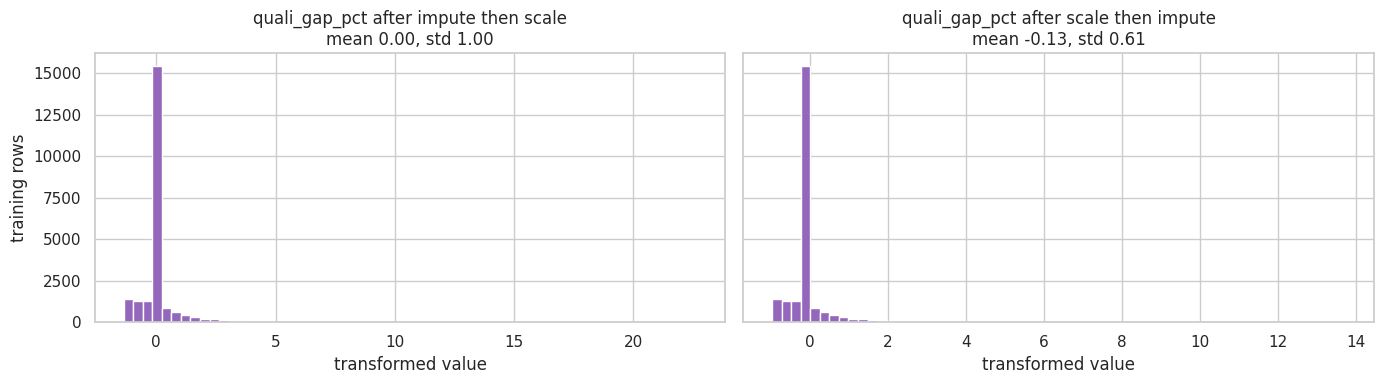

In [83]:
# ---- Experiment 2: impute -> scale   vs   scale -> impute ----------------------------------------
# Both orders run without error (StandardScaler ignores NaN when fitting), but they produce different data:
# scale -> impute computes mean/std on the observed values only, and then fills the gaps with the median of the
# SCALED column, so the final column is no longer centred at 0 with unit variance.
exp2_rows, exp2_prep = [], {}
for order in ["impute_then_scale", "scale_then_impute"]:
    for mname, model in PREP_EXP_MODELS.items():
        scores, exp2_prep[order] = score_prep(X_train, make_preprocessor(num_order=order), model)
        exp2_rows.append({"order": order, "model": mname, **scores})
exp2 = pd.DataFrame(exp2_rows)
display(exp2.pivot(index="order", columns="model", values=["val PR-AUC", "val ROC-AUC"]).round(4))

# Effect on the transformed training data for the features with missing values
miss_feats = [f for f in numeric_in if X_train[f].isna().any()]
moments = {}
for order, prep in exp2_prep.items():
    Z = pd.DataFrame(prep.transform(X_train), columns=prep.get_feature_names_out())
    moments[(order, "mean")] = Z[miss_feats].mean()
    moments[(order, "std")] = Z[miss_feats].std()
display(pd.DataFrame(moments).round(3).assign(**{"% missing in train": (X_train[miss_feats].isna().mean() * 100).round(1)}))

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, (order, prep) in zip(axes, exp2_prep.items()):
    Z = pd.DataFrame(prep.transform(X_train), columns=prep.get_feature_names_out())
    ax.hist(Z["quali_gap_pct"], bins=60, color="tab:purple")
    ax.set_title(f"quali_gap_pct after {order.replace('_', ' ')}\nmean {Z['quali_gap_pct'].mean():.2f}, std {Z['quali_gap_pct'].std():.2f}")
    ax.set_xlabel("transformed value")
axes[0].set_ylabel("training rows")
plt.tight_layout()
save_fig("7_2_exp2_order")
plt.show()

**Findings (Exp 2).** Both orders run, but they produce different data. With scale → impute the scaler learns mean/std from the *observed* values only and the gaps are filled afterwards, so the final columns are **no longer standardised**: the qualifying features end with standard deviation ≈ 0.61 and mean ≈ −0.13 instead of 1 and 0 (63% of training rows are imputed into one spike). Scores are practically identical (LogReg 0.7410 vs 0.7417; HistGB 0.7533 vs 0.7560; mean 0.7472 vs 0.7488, +0.0016). Trees do not depend on scaling in principle; the small HistGB difference comes from its automatic early stopping (an internal 10% hold-out), which reacts to tiny numerical differences in the inputs and stops at a slightly different number of trees. Under the fixed rule (switch only for ≥ +0.005) we keep the conventional **impute → scale**, which guarantees that every model input has mean 0 and standard deviation 1.

**Experiment 3 — missing-value indicator before vs after imputation.**

In [84]:
# ---- Experiment 3: where the "was missing" indicator is created relative to imputation ------------
# (a) no indicator at all (the explicit flags has_quali / is_season_opener / career_starts already exist)
# (b) indicator BEFORE imputation  -> SimpleImputer(add_indicator=True) records which values were missing
# (c) indicator AFTER imputation   -> the wrong order: nothing is missing any more, so the indicator is all zeros
def indicator_after_imputation():
    numeric = [f for f in FEATURES if f in NUMERIC_FEATURES]
    binary = [f for f in FEATURES if f in BINARY_FEATURES]
    add_flags_late = FunctionTransformer(lambda Z: np.hstack([Z, np.isnan(Z).astype(float)]))
    num_pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("indicator_after", add_flags_late),
                         ("scale", StandardScaler())])
    return ColumnTransformer([("num", num_pipe, numeric), ("bin", SimpleImputer(strategy="most_frequent"), binary)],
                             sparse_threshold=0)

exp3_variants = {
    "(a) no indicator": make_preprocessor(add_indicator=False),
    "(b) indicator before imputation": make_preprocessor(add_indicator=True),
    "(c) indicator after imputation (wrong order)": indicator_after_imputation(),
}
exp3_rows, n_inputs = [], {}
for label, prep in exp3_variants.items():
    n_inputs[label] = clone(prep).fit(X_train).transform(X_train).shape[1]
    for mname, model in PREP_EXP_MODELS.items():
        scores, _ = score_prep(X_train, prep, model)
        exp3_rows.append({"variant": label, "model": mname, **scores})
exp3 = pd.DataFrame(exp3_rows)
display(exp3.pivot(index="variant", columns="model", values=["val PR-AUC", "val ROC-AUC"]).round(4))

# Does the indicator actually record anything? Count the 1s it contains on the training rows.
numeric = [f for f in FEATURES if f in NUMERIC_FEATURES]
ind_before = SimpleImputer(strategy="median", add_indicator=True).fit(X_train[numeric]).transform(X_train[numeric])[:, len(numeric):]
ind_after = np.isnan(SimpleImputer(strategy="median").fit_transform(X_train[numeric])).astype(float)
display(pd.DataFrame({
    "model inputs": [n_inputs[v] for v in exp3_variants],
    "indicator columns": [0, ind_before.shape[1], ind_after.shape[1]],
    "1s in the indicator columns (train)": [0, int(ind_before.sum()), int(ind_after.sum())],
}, index=list(exp3_variants)))

val PR-AUC                   val ROC-AUC             
model                                        HistGB (default) LogReg (C=1) HistGB (default) LogReg (C=1)
variant                                                                                                 
(a) no indicator                                       0.7533       0.7410           0.9302       0.9307
(b) indicator before imputation                        0.7420       0.7422           0.9288       0.9333
(c) indicator after imputation (wrong order)           0.7533       0.7410           0.9302       0.9307

,model inputs,indicator columns,1s in the indicator columns (train)
(a) no indicator,24,0,0
(b) indicator before imputation,39,15,55440
(c) indicator after imputation (wrong order),44,20,0


**Findings (Exp 3).** Creating the indicator **after** imputation is the wrong order: nothing is missing any more, so all 20 indicator columns are constant zeros (0 ones) and the result is identical to having no indicator — the information "this value was missing" is lost. Created **before** imputation (correct order), the 15 indicator columns record all 55,440 imputed values, but they do not help: mean PR-AUC 0.742 vs 0.747 without them (LogReg +0.001, HistGB −0.011). The explicit flags (`has_quali`, `is_season_opener`, `career_starts = 0`) already tell the model when a value was imputed, so extra indicators only add noise. **Decision: no indicator.**

**Summary and final configuration.**

,experiment,variant,mean val PR-AUC (LR & HGB)
0,Exp 1,fit on train only,0.7472
1,Exp 1,fit on train+val (leaky),0.7473
2,Exp 2,impute → scale,0.7472
3,Exp 2,scale → impute,0.7488
4,Exp 3,no indicator,0.7472
5,Exp 3,indicator before imputation,0.7421
6,Exp 3,indicator after imputation,0.7472


Final pre-processing: fitted on TRAIN only | numeric order = impute_then_scale | add_indicator = False


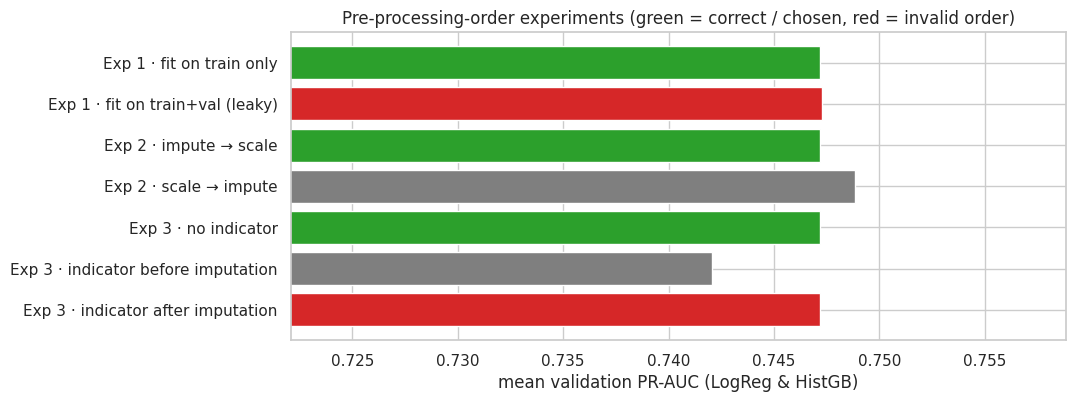

In [85]:
# ---- Summary of the three experiments and the resulting final pre-processing configuration ----
def mean_pr(df, col, value):
    return df.loc[df[col] == value, "val PR-AUC"].mean()

summary_rows = [
    ("Exp 1", "fit on train only", mean_pr(exp1, "variant", "A) fit on train only (correct)")),
    ("Exp 1", "fit on train+val (leaky)", mean_pr(exp1, "variant", "B) fit on train+val (leaky)")),
    ("Exp 2", "impute → scale", mean_pr(exp2, "order", "impute_then_scale")),
    ("Exp 2", "scale → impute", mean_pr(exp2, "order", "scale_then_impute")),
    ("Exp 3", "no indicator", mean_pr(exp3, "variant", "(a) no indicator")),
    ("Exp 3", "indicator before imputation", mean_pr(exp3, "variant", "(b) indicator before imputation")),
    ("Exp 3", "indicator after imputation", mean_pr(exp3, "variant", "(c) indicator after imputation (wrong order)")),
]
prep_summary = pd.DataFrame(summary_rows, columns=["experiment", "variant", "mean val PR-AUC (LR & HGB)"])
display(prep_summary.round(4))

# Decision rules (fixed in advance):
#  Exp 1: always train-only, whatever the score (the leaky variant uses the validation rows it is scored on).
#  Exp 2: keep the conventional impute -> scale unless scale -> impute is better by >= 0.005.
#  Exp 3: add the indicator only if it beats "no indicator" by >= 0.005 (otherwise the simpler pipeline wins).
s = prep_summary.set_index("variant")["mean val PR-AUC (LR & HGB)"]
FINAL_NUM_ORDER = "scale_then_impute" if s["scale → impute"] - s["impute → scale"] >= 0.005 else "impute_then_scale"
FINAL_ADD_INDICATOR = bool(s["indicator before imputation"] - s["no indicator"] >= 0.005)
print(f"Final pre-processing: fitted on TRAIN only | numeric order = {FINAL_NUM_ORDER} | add_indicator = {FINAL_ADD_INDICATOR}")

fig, ax = plt.subplots(figsize=(10, 4))
colors = ["tab:green", "tab:red", "tab:green", "tab:gray", "tab:green", "tab:gray", "tab:red"]
ax.barh(prep_summary["experiment"] + " · " + prep_summary["variant"], prep_summary["mean val PR-AUC (LR & HGB)"], color=colors)
ax.invert_yaxis()
lo = prep_summary["mean val PR-AUC (LR & HGB)"].min()
ax.set_xlim(lo - 0.02, prep_summary["mean val PR-AUC (LR & HGB)"].max() + 0.01)
ax.set_xlabel("mean validation PR-AUC (LogReg & HistGB)")
ax.set_title("Pre-processing-order experiments (green = correct / chosen, red = invalid order)")
save_fig("7_2_prep_experiments")
plt.show()

**Conclusions.** (1) Pre-processing is fitted **after** the split, on training rows only — always; the leaky variant is shown only as evidence. (2) **Impute → scale** is kept: practically the same score (the other order is +0.0016, below the 0.005 rule) and properly standardised inputs. (3) **No missing-value indicator**: the explicit structural flags already carry that information, and indicators created after imputation would be empty anyway.

## 7.3 Final pipeline and its effect on the data

The final pipeline (median imputation → standard scaling for numeric features; most-frequent imputation for flags) is fitted on the training rows. Below: its effect on **values** (fill values learned from training), **range** (min/max before and after), **distribution** (histograms before and after) and **missingness** (missing values before and after).

,missing before,missing after,fill value learned on train,min before,max before,mean before,std before,min after,max after,mean after,std after
career_starts,0,0,41.000,0.000,321.000,61.424,61.568,-0.998,4.216,0.000,1.000
con_champ_pos,2493,0,6.000,1.000,21.000,6.233,3.743,-1.475,4.191,-0.000,1.000
con_champ_pts_share,2493,0,0.135,0.000,1.000,0.290,0.336,-0.853,2.271,-0.000,1.000
con_finish_pct_20,255,0,0.535,0.075,1.000,0.520,0.140,-3.198,3.448,0.000,1.000
con_mech_dnf_rate_20,255,0,0.270,0.000,1.000,0.272,0.170,-1.611,4.308,-0.000,1.000
con_podium_rate_20,255,0,0.050,0.000,1.000,0.138,0.180,-0.766,4.824,-0.000,1.000
driver_age,0,0,29.544,17.454,55.797,30.045,5.184,-2.429,4.968,-0.000,1.000
drv_career_podium_rate,667,0,0.050,0.000,1.000,0.122,0.158,-0.771,5.646,-0.000,1.000
drv_champ_pos,1491,0,13.000,1.000,30.000,13.424,8.352,-1.536,2.057,-0.000,1.000
drv_champ_pts_share,1491,0,0.062,0.000,1.000,0.200,0.285,-0.689,2.914,0.000,1.000


Missing values in train before: 55,440 -> after: 0; validation after: 0; test after: 0
Columns: 24 raw features -> 24 model inputs


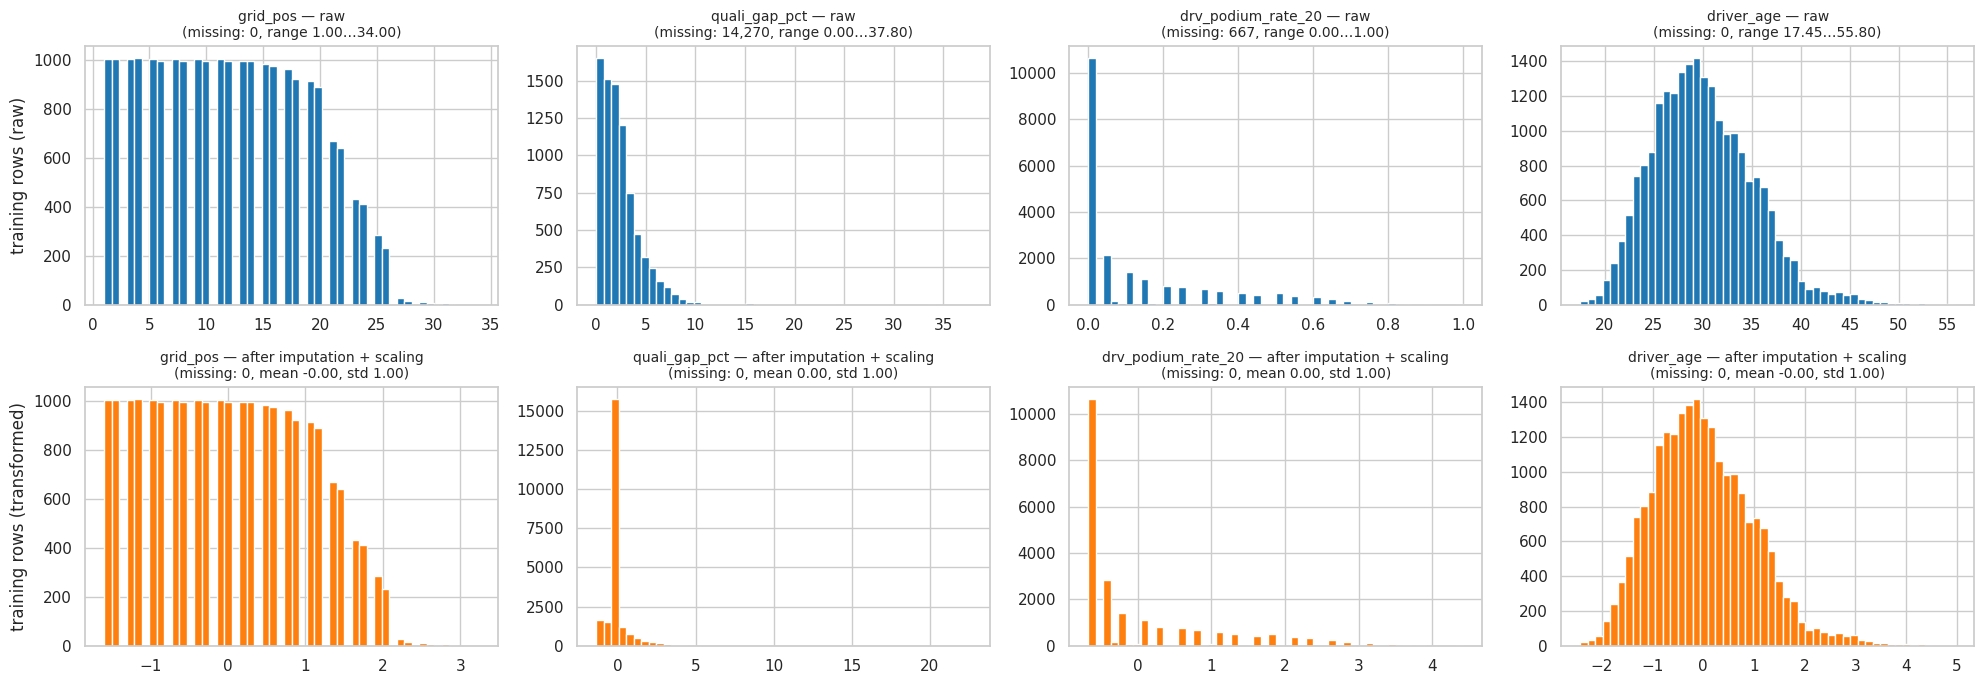

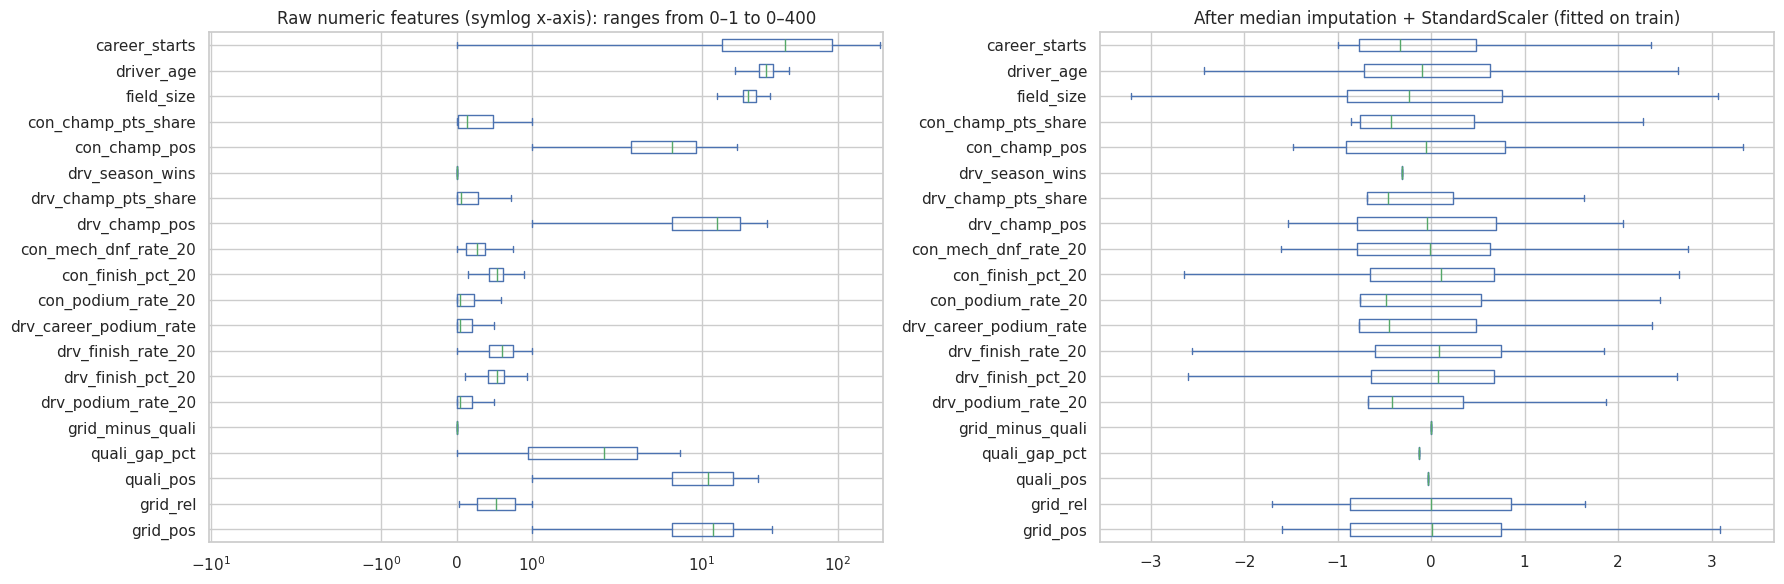

In [86]:
# ---- 7.3 Final pre-processing pipeline (fitted on TRAIN only) and its effect on the data ----------
def make_final_preprocessor(features=None):
    return make_preprocessor(features, num_order=FINAL_NUM_ORDER, add_indicator=FINAL_ADD_INDICATOR)

preprocess = make_final_preprocessor().fit(X_train)
Z_train = pd.DataFrame(preprocess.transform(X_train), columns=preprocess.get_feature_names_out(), index=X_train.index)
Z_val   = pd.DataFrame(preprocess.transform(X_val),   columns=preprocess.get_feature_names_out(), index=X_val.index)
Z_test  = pd.DataFrame(preprocess.transform(X_test),  columns=preprocess.get_feature_names_out(), index=X_test.index)

# (1) Values / range / missingness before vs after, per feature (training rows)
num_step = preprocess.named_transformers_["num"]
effect = pd.DataFrame({
    "missing before": X_train[FEATURES].isna().sum(),
    "missing after": Z_train[FEATURES].isna().sum(),
    "fill value learned on train": pd.Series(dict(zip(numeric_in, num_step.named_steps["impute"].statistics_))),
    "min before": X_train[FEATURES].min(), "max before": X_train[FEATURES].max(),
    "mean before": X_train[FEATURES].mean(), "std before": X_train[FEATURES].std(),
    "min after": Z_train[FEATURES].min(), "max after": Z_train[FEATURES].max(),
    "mean after": Z_train[FEATURES].mean(), "std after": Z_train[FEATURES].std(),
})
display(effect.round(3))
print(f"Missing values in train before: {int(X_train.isna().sum().sum()):,} -> after: {int(Z_train.isna().sum().sum())}; "
      f"validation after: {int(Z_val.isna().sum().sum())}; test after: {int(Z_test.isna().sum().sum())}")
print(f"Columns: {X_train.shape[1]} raw features -> {Z_train.shape[1]} model inputs")

# (2) Distribution before vs after for four representative features
show = ["grid_pos", "quali_gap_pct", f"drv_podium_rate_{FORM_N}", "driver_age"]
fig, axes = plt.subplots(2, 4, figsize=(20, 7))
for j, f in enumerate(show):
    axes[0, j].hist(X_train[f].dropna(), bins=50, color="tab:blue")
    axes[0, j].set_title(f"{f} — raw\n(missing: {X_train[f].isna().sum():,}, range {X_train[f].min():.2f}…{X_train[f].max():.2f})", fontsize=10)
    axes[1, j].hist(Z_train[f], bins=50, color="tab:orange")
    axes[1, j].set_title(f"{f} — after imputation + scaling\n(missing: 0, mean {Z_train[f].mean():.2f}, std {Z_train[f].std():.2f})", fontsize=10)
axes[0, 0].set_ylabel("training rows (raw)")
axes[1, 0].set_ylabel("training rows (transformed)")
plt.tight_layout()
save_fig("7_3_prep_distributions")
plt.show()

# (3) Ranges of all numeric features before vs after: very different scales become comparable
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
X_train[numeric_in].plot.box(vert=False, ax=axes[0], showfliers=False)
axes[0].set_xscale("symlog")
axes[0].set_title("Raw numeric features (symlog x-axis): ranges from 0–1 to 0–400")
Z_train[numeric_in].plot.box(vert=False, ax=axes[1], showfliers=False)
axes[1].set_title("After median imputation + StandardScaler (fitted on train)")
plt.tight_layout()
save_fig("7_3_prep_ranges")
plt.show()

**Findings.**
- **Missing values:** 55,440 missing values in the training rows (mostly qualifying before 2003, standings at round 1 and before 1958, form at debuts) → **0** after imputation; validation and test are also complete after `transform`.
- **Values:** each gap is filled with the training median (e.g. `quali_gap_pct` 1.96%, `quali_pos` 11, `drv_champ_pos` 13).
- **Range:** raw ranges differ by two orders of magnitude (`drv_podium_rate_20` 0–1, `career_starts` 0–321); after scaling every numeric input has mean 0 and standard deviation 1 on the training rows, so no feature dominates the logistic regression or the network just because of its unit.
- **Distribution:** scaling only shifts and stretches; the shape is unchanged. Imputation creates a visible spike at the median where many values were missing (`quali_gap_pct`, 64% missing in training) — the `has_quali` flag lets the models tell those rows apart.
- **Columns:** 24 raw features → 24 model inputs (no indicators, no one-hot).

<a id="8"></a>
# 8. Prediction Model

All models use the **same rows, the same 24 features, the same frozen pre-processing and the same split**. Hyper-parameters, the decision threshold and the final model are chosen on **train/validation only, never on test**.

**Metrics (all five are reported for every model):** ROC-AUC, PR-AUC, F1, Precision, Recall.
- **Primary metric: PR-AUC** (average precision). Podiums are the rare class (~14%): a model that predicts "no podium" for everyone is 86% accurate but useless. PR-AUC measures how well the model ranks the *actual* podium finishers above everyone else and is not inflated by the many easy negatives (no-skill level = the podium rate ≈ 0.15, not 0.5).
- **Secondary metric: ROC-AUC** — overall separation of the two classes, threshold-free and easy to compare across splits with different podium rates; it is less informative alone because it rewards ranking the many easy non-podium rows.
- **F1, Precision, Recall** — need a yes/no decision, i.e. a threshold. F1 balances wrongly predicted podiums (false positives) against missed podiums (false negatives).

**Threshold:** 0.5 is not automatically optimal for a rare class. For each model the threshold that **maximises F1 on the validation set** is chosen, frozen, and then applied unchanged to train and test.

## 8.0 Evaluation helpers and a no-model reference

`all_metrics` computes the five metrics, `choose_threshold` picks the validation-F1 threshold, `tune` fits every hyper-parameter configuration on train and scores it on validation (every trial is kept and shown), and `register` freezes a tuned model with its threshold.

In [87]:
# ---- 8.0 Evaluation helpers, threshold selection and a common tuning loop --------------------------
import copy, time
from sklearn.model_selection import ParameterGrid
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score, precision_recall_curve, roc_curve,
                             confusion_matrix, log_loss, ConfusionMatrixDisplay)

pd.set_option("display.max_colwidth", 150)      # show the full hyper-parameter strings in the trial tables
PRIMARY_METRIC, SECONDARY_METRIC = "PR-AUC", "ROC-AUC"
METRICS = ["ROC-AUC", "PR-AUC", "F1", "Precision", "Recall"]


def all_metrics(y, p, threshold):
    """The five metrics. ROC-AUC and PR-AUC use the scores; F1/Precision/Recall use the frozen threshold."""
    pred = (p >= threshold).astype(int)
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "F1": f1_score(y, pred, zero_division=0), "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred, zero_division=0)}


def choose_threshold(y_true, p):
    """Pick the probability threshold that maximises F1 on the VALIDATION set (never on test)."""
    prec, rec, thr = precision_recall_curve(y_true, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    best = int(np.nanargmax(f1))
    return float(thr[best]), float(f1[best])


def make_pipeline(model, features=None):
    """The frozen pre-processing (fitted on train) + a classifier, as one object."""
    return Pipeline([("prep", make_final_preprocessor(features)), ("model", model)])


def tune(model_factory, grid, label, features=None):
    """Fit every configuration on TRAIN, score on VALIDATION, keep all trials (nothing is hidden)."""
    features = FEATURES if features is None else features
    trials, fitted = [], []
    for params in ParameterGrid(grid):
        t0 = time.time()
        pipe = make_pipeline(model_factory(**params), features).fit(X_train[features], y_train)
        p_tr = pipe.predict_proba(X_train[features])[:, 1]
        p_va = pipe.predict_proba(X_val[features])[:, 1]
        trials.append({"model": label, "params": str(params), "train PR-AUC": average_precision_score(y_train, p_tr),
                       "val PR-AUC": average_precision_score(y_val, p_va), "val ROC-AUC": roc_auc_score(y_val, p_va),
                       "fit time (s)": round(time.time() - t0, 2)})
        fitted.append((params, pipe))
    trials = pd.DataFrame(trials)
    best_i = int(trials["val PR-AUC"].idxmax())
    return trials, fitted[best_i][0], fitted[best_i][1]


MODELS = {}       # name -> frozen pipeline, threshold, hyper-parameters
ALL_TRIALS = []   # every configuration we tried (Section 8.4)


def register(name, pipe, params, family):
    """Freeze a tuned model: choose its threshold on validation and show TRAIN + VALIDATION metrics only."""
    p_tr, p_va = pipe.predict_proba(X_train)[:, 1], pipe.predict_proba(X_val)[:, 1]
    thr, _ = choose_threshold(y_val, p_va)
    MODELS[name] = {"pipe": pipe, "threshold": thr, "params": params, "family": family}
    out = pd.DataFrame({"train": all_metrics(y_train, p_tr, thr), "validation": all_metrics(y_val, p_va, thr)}).T
    print(f"{name}: hyper-parameters {params} | threshold (max F1 on validation) = {thr:.3f}")
    display(out.round(4))
    return out

A reference point that needs no learning at all: rank drivers by grid slot (score = −`grid_pos`). Its threshold is chosen on validation like the models' (it becomes "predict a podium when the grid slot ≤ k"). Every model must beat this rule to justify its complexity.

In [88]:
# ---- Reference point without any model: "the better the grid slot, the likelier the podium" ----------
# Score = -grid_pos (pole = highest score). Its threshold is also chosen on validation (it becomes "grid <= k").
grid_rule_score = {"train": -X_train["grid_pos"].values, "validation": -X_val["grid_pos"].values}
grid_rule_thr, _ = choose_threshold(y_val, grid_rule_score["validation"])
grid_rule_metrics = pd.DataFrame({
    "train": all_metrics(y_train, grid_rule_score["train"], grid_rule_thr),
    "validation": all_metrics(y_val, grid_rule_score["validation"], grid_rule_thr)}).T
print(f"Grid-only rule: predict a podium when grid_pos <= {int(-grid_rule_thr)}")
display(grid_rule_metrics.round(4))

Grid-only rule: predict a podium when grid_pos <= 3


,ROC-AUC,PR-AUC,F1,Precision,Recall
train,0.8829,0.4984,0.5436,0.5452,0.5419
validation,0.9101,0.6478,0.6953,0.6983,0.6923


## 8.1 Baseline — Logistic Regression

**How it works.** Logistic regression computes a weighted sum of the (scaled) features, `z = b + w₁x₁ + … + w₂₄x₂₄`, and turns it into a probability with the sigmoid `p = 1 / (1 + e^(−z))`. The weights are learned by maximising the likelihood of the training labels, with an L2 penalty whose strength is `1/C` (small `C` = strong regularisation, which keeps correlated features such as `grid_pos`/`grid_rel` from getting extreme weights). Each weight is a change in the log-odds of a podium per one standard deviation of the feature.

**Why it is the baseline.** It is the simplest reasonable probabilistic classifier, fast, stable and directly interpretable; every more complex model must beat it to earn its complexity.

**Limitations.** The decision boundary is linear in the features: it cannot represent interactions (e.g. "a front-row start matters more in a dominant car") or thresholds (e.g. the sharp drop in podium rate after P3) unless they are engineered by hand. It is also sensitive to feature scaling (handled in Section 7).

**Tuning:** `C` ∈ {0.01, 0.1, 1, 10} × `class_weight` ∈ {none, balanced} = 8 configurations.

,model,params,train PR-AUC,val PR-AUC,val ROC-AUC,fit time (s)
6,Logistic Regression,"{'C': 10.0, 'class_weight': None}",0.5764,0.7417,0.9308,0.67
4,Logistic Regression,"{'C': 1.0, 'class_weight': None}",0.5765,0.7410,0.9307,0.58
2,Logistic Regression,"{'C': 0.1, 'class_weight': None}",0.5761,0.7401,0.9306,0.64
0,Logistic Regression,"{'C': 0.01, 'class_weight': None}",0.5746,0.7363,0.9302,0.52
3,Logistic Regression,"{'C': 0.1, 'class_weight': 'balanced'}",0.5684,0.7296,0.9291,0.52
5,Logistic Regression,"{'C': 1.0, 'class_weight': 'balanced'}",0.5683,0.7291,0.9291,0.55
7,Logistic Regression,"{'C': 10.0, 'class_weight': 'balanced'}",0.5683,0.7289,0.9291,0.59
1,Logistic Regression,"{'C': 0.01, 'class_weight': 'balanced'}",0.5689,0.7270,0.9288,0.45


Logistic Regression: hyper-parameters {'C': 10.0, 'class_weight': None} | threshold (max F1 on validation) = 0.374


,ROC-AUC,PR-AUC,F1,Precision,Recall
train,0.9013,0.5764,0.5708,0.5617,0.5803
validation,0.9308,0.7417,0.7124,0.7155,0.7094


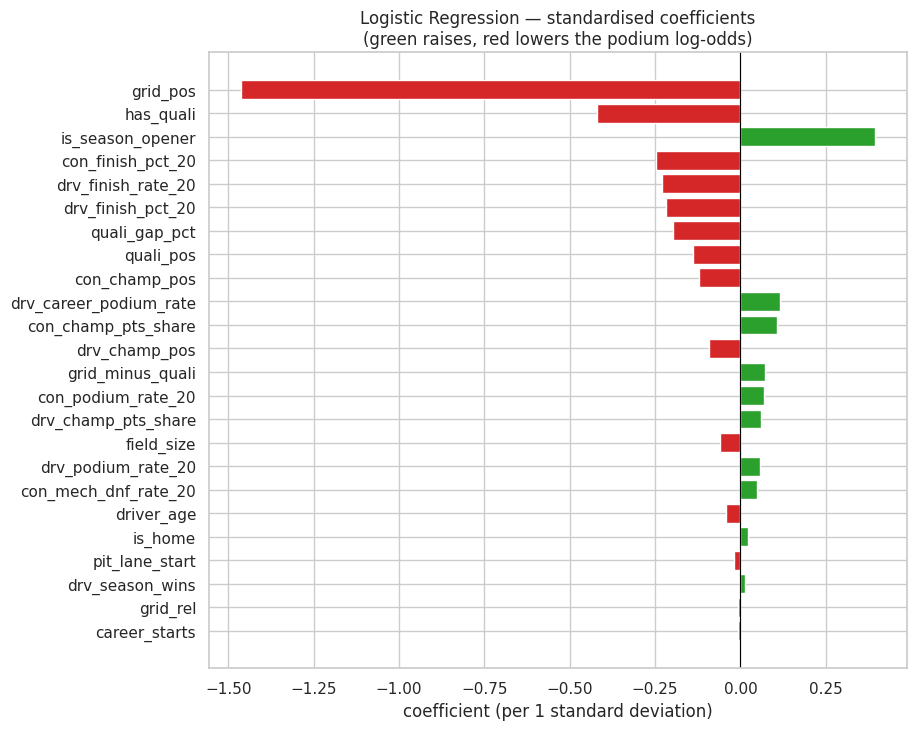

In [89]:
# ---- 8.1 Logistic Regression baseline: tune C (regularisation) and class weighting on validation ----
lr_trials, lr_params, lr_pipe = tune(
    lambda **p: LogisticRegression(max_iter=5000, **p),
    {"C": [0.01, 0.1, 1.0, 10.0], "class_weight": [None, "balanced"]}, "Logistic Regression")
ALL_TRIALS.append(lr_trials)
display(lr_trials.sort_values("val PR-AUC", ascending=False).round(4))
lr_metrics = register("Logistic Regression", lr_pipe, lr_params, "linear")

# How the baseline uses the features: standardised coefficients (log-odds change per 1 std of the feature)
coef = pd.Series(lr_pipe.named_steps["model"].coef_[0], index=lr_pipe.named_steps["prep"].get_feature_names_out())
coef = coef.reindex(coef.abs().sort_values().index)
plt.figure(figsize=(9, 8))
plt.barh(coef.index, coef.values, color=["tab:green" if v > 0 else "tab:red" for v in coef.values])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Logistic Regression — standardised coefficients\n(green raises, red lowers the podium log-odds)")
plt.xlabel("coefficient (per 1 standard deviation)")
save_fig("8_1_lr_coefficients")
plt.show()

**Findings.** The best configuration is **C = 10 without class weighting** (validation PR-AUC **0.742**, ROC-AUC 0.931). Regularisation strength barely matters (0.736–0.742). `class_weight="balanced"` is consistently *worse* (≈ 0.729): re-weighting distorts the probabilities without improving the ranking, and the threshold already handles the class imbalance. The coefficients confirm the EDA: grid position has by far the largest weight; constructor and driver form and the standings shares add positive evidence.

The **train** PR-AUC (0.576) is *lower* than validation (0.742) — not underfitting, but a different difficulty: the training seasons include eras with unreliable cars and 30-car fields (see the per-era table in 8.4).

## 8.2 Statistical models — Random Forest and Gradient Boosting

**Random Forest — how it works.** Hundreds of decision trees are grown, each on a bootstrap sample of the training rows and considering only a random subset of the features at every split; the forest's probability is the average of the trees' votes. Averaging many de-correlated trees reduces variance. *Strengths:* captures interactions and thresholds automatically, robust to outliers and to feature scale. *Limitations:* probabilities are averaged leaf frequencies (often less well calibrated), deep trees memorise the training rows (overfitting), it cannot extrapolate beyond the training range, and it is slower and less interpretable than a linear model.

**Gradient Boosting — how it works.** Trees are built **one after another**; each new small tree is fitted to the errors (the gradient of the log-loss) of the current ensemble and added with a small learning rate. We use scikit-learn's `HistGradientBoostingClassifier`, which bins the features into histograms (the LightGBM algorithm) and needs no extra library on Kaggle. *Strengths:* usually the most accurate on tabular data; models non-linear effects and interactions. *Limitations:* many interacting hyper-parameters, overfits with large learning rates or big trees, and it is a black box (hence Section 9).

**Tuning.** Random Forest (300 trees): `max_depth` ∈ {8, none} × `min_samples_leaf` ∈ {5, 20, 50} × `max_features` ∈ {√p, 0.5} = 12 configurations. Gradient Boosting (300 boosting rounds): `learning_rate` ∈ {0.03, 0.1} × `max_leaf_nodes` ∈ {15, 31} × `min_samples_leaf` ∈ {20, 80} × `l2_regularization` ∈ {0, 1} = 16 configurations.

In [90]:
# ---- 8.2a Random Forest -------------------------------------------------------------------------
rf_trials, rf_params, rf_pipe = tune(
    lambda **p: RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED, **p),
    {"max_depth": [8, None], "min_samples_leaf": [5, 20, 50], "max_features": ["sqrt", 0.5]}, "Random Forest")
ALL_TRIALS.append(rf_trials)
display(rf_trials.sort_values("val PR-AUC", ascending=False).round(4))
rf_metrics = register("Random Forest", rf_pipe, rf_params, "tree ensemble")

,model,params,train PR-AUC,val PR-AUC,val ROC-AUC,fit time (s)
2,Random Forest,"{'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 50}",0.6254,0.7427,0.9327,3.56
8,Random Forest,"{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 50}",0.6330,0.7423,0.9324,4.10
4,Random Forest,"{'max_depth': 8, 'max_features': 0.5, 'min_samples_leaf': 20}",0.6799,0.7411,0.9316,7.89
5,Random Forest,"{'max_depth': 8, 'max_features': 0.5, 'min_samples_leaf': 50}",0.6400,0.7403,0.9315,7.47
11,Random Forest,"{'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 50}",0.6484,0.7400,0.9303,9.28
1,Random Forest,"{'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 20}",0.6568,0.7386,0.9323,3.71
7,Random Forest,"{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 20}",0.6999,0.7364,0.9300,4.49
10,Random Forest,"{'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 20}",0.7346,0.7352,0.9301,10.44
0,Random Forest,"{'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 5}",0.6914,0.7241,0.9307,3.68
6,Random Forest,"{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 5}",0.9007,0.7211,0.9247,5.16


Random Forest: hyper-parameters {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 50} | threshold (max F1 on validation) = 0.341


,ROC-AUC,PR-AUC,F1,Precision,Recall
train,0.9162,0.6254,0.6056,0.5632,0.6549
validation,0.9327,0.7427,0.7131,0.6850,0.7436


In [91]:
# ---- 8.2b Gradient Boosting (scikit-learn HistGradientBoosting, the LightGBM-style algorithm) -------
gb_trials, gb_params, gb_pipe = tune(
    lambda **p: HistGradientBoostingClassifier(max_iter=300, early_stopping=False, random_state=SEED, **p),
    {"learning_rate": [0.03, 0.1], "max_leaf_nodes": [15, 31], "min_samples_leaf": [20, 80], "l2_regularization": [0.0, 1.0]},
    "Gradient Boosting")
ALL_TRIALS.append(gb_trials)
display(gb_trials.sort_values("val PR-AUC", ascending=False).round(4))
gb_metrics = register("Gradient Boosting", gb_pipe, gb_params, "tree ensemble")

,model,params,train PR-AUC,val PR-AUC,val ROC-AUC,fit time (s)
0,Gradient Boosting,"{'l2_regularization': 0.0, 'learning_rate': 0.03, 'max_leaf_nodes': 15, 'min_samples_leaf': 20}",0.6731,0.7490,0.9314,1.47
1,Gradient Boosting,"{'l2_regularization': 0.0, 'learning_rate': 0.03, 'max_leaf_nodes': 15, 'min_samples_leaf': 80}",0.6602,0.7464,0.9303,1.44
8,Gradient Boosting,"{'l2_regularization': 1.0, 'learning_rate': 0.03, 'max_leaf_nodes': 15, 'min_samples_leaf': 20}",0.6697,0.7457,0.9329,1.46
9,Gradient Boosting,"{'l2_regularization': 1.0, 'learning_rate': 0.03, 'max_leaf_nodes': 15, 'min_samples_leaf': 80}",0.6554,0.7429,0.9307,1.50
10,Gradient Boosting,"{'l2_regularization': 1.0, 'learning_rate': 0.03, 'max_leaf_nodes': 31, 'min_samples_leaf': 20}",0.7469,0.7400,0.9325,2.07
2,Gradient Boosting,"{'l2_regularization': 0.0, 'learning_rate': 0.03, 'max_leaf_nodes': 31, 'min_samples_leaf': 20}",0.7625,0.7362,0.9305,2.04
11,Gradient Boosting,"{'l2_regularization': 1.0, 'learning_rate': 0.03, 'max_leaf_nodes': 31, 'min_samples_leaf': 80}",0.7205,0.7339,0.9302,2.04
13,Gradient Boosting,"{'l2_regularization': 1.0, 'learning_rate': 0.1, 'max_leaf_nodes': 15, 'min_samples_leaf': 80}",0.7765,0.7284,0.9293,1.32
12,Gradient Boosting,"{'l2_regularization': 1.0, 'learning_rate': 0.1, 'max_leaf_nodes': 15, 'min_samples_leaf': 20}",0.7971,0.7276,0.9278,1.34
3,Gradient Boosting,"{'l2_regularization': 0.0, 'learning_rate': 0.03, 'max_leaf_nodes': 31, 'min_samples_leaf': 80}",0.7241,0.7262,0.9298,2.00


Gradient Boosting: hyper-parameters {'l2_regularization': 0.0, 'learning_rate': 0.03, 'max_leaf_nodes': 15, 'min_samples_leaf': 20} | threshold (max F1 on validation) = 0.233


,ROC-AUC,PR-AUC,F1,Precision,Recall
train,0.9329,0.6731,0.6261,0.5052,0.8230
validation,0.9314,0.7490,0.7027,0.6408,0.7778


**Gradient Boosting learning curve.** Training and validation PR-AUC and log-loss after every boosting round (tree) for the selected configuration (learning rate 0.03, 15 leaves) and, for contrast, the fast configuration from the same grid (learning rate 0.1, 31 leaves, ≥ 20 rows per leaf).

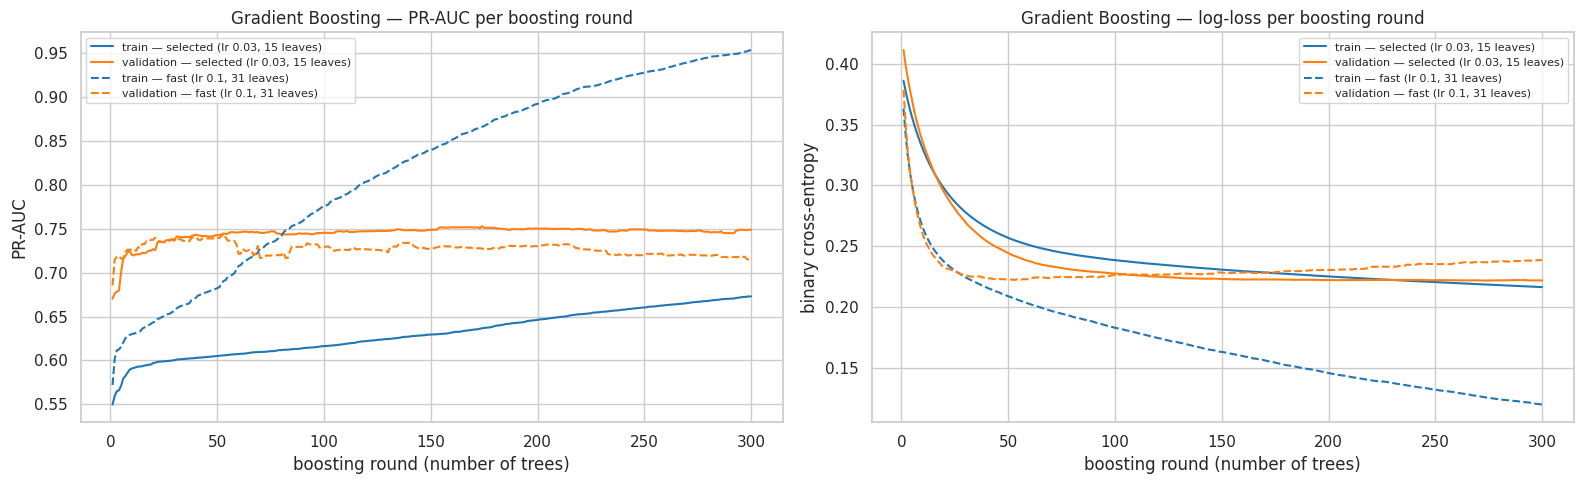

,val PR-AUC at round 300,best val PR-AUC,round of best val PR-AUC,train PR-AUC at round 300
"selected (lr 0.03, 15 leaves)",0.7490,0.7530,174.0,0.6731
"fast (lr 0.1, 31 leaves)",0.7154,0.7445,53.0,0.9538


In [92]:
# ---- 8.2c Gradient Boosting learning curves: score after every boosting round (train vs validation) ----
def boosting_curve(pipe):
    prep, model = pipe.named_steps["prep"], pipe.named_steps["model"]
    Z_tr, Z_va = prep.transform(X_train), prep.transform(X_val)
    rows = []
    for it, (p_tr, p_va) in enumerate(zip(model.staged_predict_proba(Z_tr), model.staged_predict_proba(Z_va)), 1):
        rows.append({"round": it, "train PR-AUC": average_precision_score(y_train, p_tr[:, 1]),
                     "val PR-AUC": average_precision_score(y_val, p_va[:, 1]),
                     "train loss": log_loss(y_train, p_tr[:, 1]), "val loss": log_loss(y_val, p_va[:, 1])})
    return pd.DataFrame(rows)

fast_params = {"learning_rate": 0.1, "max_leaf_nodes": 31, "min_samples_leaf": 20, "l2_regularization": 0.0}
fast_pipe = make_pipeline(HistGradientBoostingClassifier(max_iter=300, early_stopping=False, random_state=SEED,
                                                         **fast_params)).fit(X_train, y_train)
curves = {"selected (lr 0.03, 15 leaves)": boosting_curve(gb_pipe), "fast (lr 0.1, 31 leaves)": boosting_curve(fast_pipe)}

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for (label, c), style in zip(curves.items(), ["-", "--"]):
    axes[0].plot(c["round"], c["train PR-AUC"], style, color="tab:blue", label=f"train — {label}")
    axes[0].plot(c["round"], c["val PR-AUC"], style, color="tab:orange", label=f"validation — {label}")
    axes[1].plot(c["round"], c["train loss"], style, color="tab:blue", label=f"train — {label}")
    axes[1].plot(c["round"], c["val loss"], style, color="tab:orange", label=f"validation — {label}")
sel = curves["selected (lr 0.03, 15 leaves)"]
best_round = int(sel.loc[sel["val PR-AUC"].idxmax(), "round"])
for ax in axes:
    ax.set_xlabel("boosting round (number of trees)")
    ax.legend(fontsize=8)
axes[0].set(title="Gradient Boosting — PR-AUC per boosting round", ylabel="PR-AUC")
axes[1].set(title="Gradient Boosting — log-loss per boosting round", ylabel="binary cross-entropy")
plt.tight_layout()
save_fig("8_2_gb_learning_curves")
plt.show()

summary_curves = pd.DataFrame({label: {"val PR-AUC at round 300": c["val PR-AUC"].iloc[-1],
                                       "best val PR-AUC": c["val PR-AUC"].max(),
                                       "round of best val PR-AUC": int(c.loc[c["val PR-AUC"].idxmax(), "round"]),
                                       "train PR-AUC at round 300": c["train PR-AUC"].iloc[-1]}
                               for label, c in curves.items()}).T
display(summary_curves.round(4))

**Findings.**
- **Random Forest:** the best forest is the most *regularised* one (depth 8, √p features, ≥ 50 rows per leaf; validation PR-AUC **0.743**). Fully grown trees with small leaves reach a training PR-AUC of 0.94 but only 0.71 on validation — classic overfitting, visible directly in the trial table.
- **Gradient Boosting:** best with the slow learning rate 0.03 and small trees (15 leaves, ≥ 20 rows per leaf; validation PR-AUC **0.749**, the best of all models). The fast/large configurations (learning rate 0.1, 31 leaves) overfit in the same way (train 0.90–0.95, validation 0.68–0.72).
- Both tree ensembles beat the logistic baseline only slightly on validation (+0.001 and +0.007). The relationships are mostly monotone (better grid / form / standings → more podiums), which a linear model already represents well.
- **Gradient Boosting learning curves:** with the selected slow configuration, validation PR-AUC rises during the first ~50 trees and then stays flat (0.749 after 300 trees; the best single round, 0.753 at round 174, is within the noise of a 774-row validation set), while the training curve rises slowly — no overfitting. The fast configuration reaches a training PR-AUC of 0.95, but its validation PR-AUC peaks at round 53 and then *falls* to 0.715 and its validation log-loss rises again: the classic overfitting pattern, and the reason the slow configuration was chosen.


## 8.3 Shallow Neural Network

**Architecture.** A feed-forward network (multi-layer perceptron) built with scikit-learn's `MLPClassifier`: input (24 scaled features) → **1 or 2 hidden layers** with ReLU activation → 1 sigmoid output (podium probability). It is trained with the Adam optimiser on mini-batches of 256 rows, minimising binary cross-entropy, with an L2 weight penalty `alpha`.

**How it works.** Each hidden unit computes a weighted sum of its inputs and passes it through ReLU (`max(0, z)`); stacking these lets the network learn non-linear combinations of the features. Back-propagation computes how each weight affects the loss, and Adam updates the weights a little after every mini-batch. One pass over the training rows is one **epoch**.

**Early stopping.** We train epoch by epoch (`partial_fit`), record training and validation loss and PR-AUC after every epoch, and keep the weights of the epoch with the best **validation** PR-AUC (patience 20 epochs). The test set is never used for stopping.

**Limitations.** Needs scaled inputs, is sensitive to initialisation and learning rate, can overfit quickly on ~22k rows, and is the least interpretable model. Because the validation set is also used for early stopping, its validation score is slightly optimistic.

**Tuning:** hidden layers ∈ {(32), (64), (64, 32), (128, 64)} × `alpha` ∈ {1e-4, 1e-2} × learning rate ∈ {1e-3, 3e-4} = 16 configurations.

,model,params,train PR-AUC,val PR-AUC,val ROC-AUC,best epoch,fit time (s)
6,Shallow NN,"{'alpha': 0.0001, 'hidden_layer_sizes': (128, 64), 'learning_rate_init': 0.001}",0.6067,0.7457,0.9291,9,8.55
14,Shallow NN,"{'alpha': 0.01, 'hidden_layer_sizes': (128, 64), 'learning_rate_init': 0.001}",0.6044,0.7442,0.9292,9,8.51
0,Shallow NN,"{'alpha': 0.0001, 'hidden_layer_sizes': (32,), 'learning_rate_init': 0.001}",0.5846,0.7423,0.9277,14,4.13
8,Shallow NN,"{'alpha': 0.01, 'hidden_layer_sizes': (32,), 'learning_rate_init': 0.001}",0.5881,0.7419,0.9289,17,4.51
2,Shallow NN,"{'alpha': 0.0001, 'hidden_layer_sizes': (64,), 'learning_rate_init': 0.001}",0.6031,0.7415,0.9307,31,7.32
9,Shallow NN,"{'alpha': 0.01, 'hidden_layer_sizes': (32,), 'learning_rate_init': 0.0003}",0.5861,0.7409,0.9287,48,8.15
11,Shallow NN,"{'alpha': 0.01, 'hidden_layer_sizes': (64,), 'learning_rate_init': 0.0003}",0.5877,0.7407,0.9293,38,8.24
10,Shallow NN,"{'alpha': 0.01, 'hidden_layer_sizes': (64,), 'learning_rate_init': 0.001}",0.6026,0.7406,0.9305,31,7.21
1,Shallow NN,"{'alpha': 0.0001, 'hidden_layer_sizes': (32,), 'learning_rate_init': 0.0003}",0.5861,0.7403,0.9284,48,8.14
3,Shallow NN,"{'alpha': 0.0001, 'hidden_layer_sizes': (64,), 'learning_rate_init': 0.0003}",0.5877,0.7398,0.9293,38,8.35


Shallow NN: hyper-parameters {'alpha': 0.0001, 'hidden_layer_sizes': (128, 64), 'learning_rate_init': 0.001} | threshold (max F1 on validation) = 0.408


,ROC-AUC,PR-AUC,F1,Precision,Recall
train,0.9102,0.6067,0.5890,0.5649,0.6153
validation,0.9291,0.7457,0.6979,0.6949,0.7009


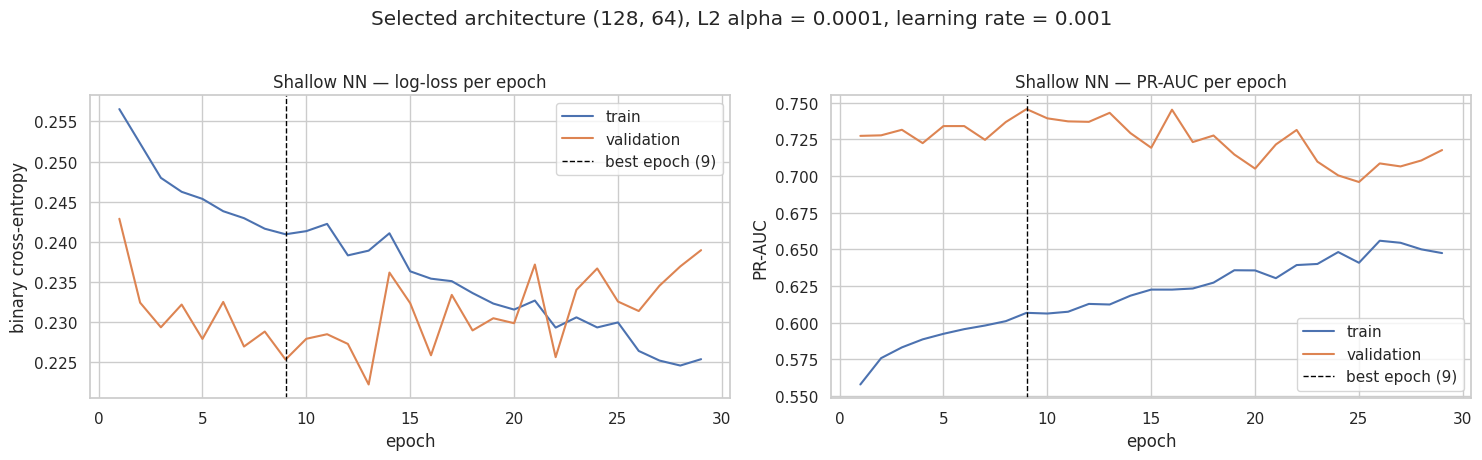

In [93]:
# ---- 8.3 Shallow neural network (feed-forward, 1-2 hidden layers, scikit-learn MLPClassifier) ------
# We train epoch by epoch with partial_fit so that we can (1) record training/validation curves and
# (2) stop early on VALIDATION PR-AUC and restore the weights of the best epoch (patience = 20 epochs).
class EarlyStoppedMLP:
    """Wraps MLPClassifier: epoch loop with early stopping on validation PR-AUC. Exposes predict_proba."""
    def __init__(self, hidden_layer_sizes=(64,), alpha=1e-4, learning_rate_init=1e-3, batch_size=256,
                 max_epochs=200, patience=20, seed=SEED):
        self.params = dict(hidden_layer_sizes=hidden_layer_sizes, alpha=alpha, learning_rate_init=learning_rate_init,
                           batch_size=batch_size)
        self.max_epochs, self.patience, self.seed = max_epochs, patience, seed
        self.classes_ = np.array([0, 1])

    def fit(self, Z_tr, y_tr, Z_va=None, y_va=None):
        net = MLPClassifier(activation="relu", solver="adam", random_state=np.random.RandomState(self.seed), **self.params)
        best_score, best_epoch, history = -np.inf, 0, []
        for epoch in range(1, self.max_epochs + 1):
            net.partial_fit(Z_tr, y_tr, classes=self.classes_)
            p_tr, p_va = net.predict_proba(Z_tr)[:, 1], net.predict_proba(Z_va)[:, 1]
            score = average_precision_score(y_va, p_va)
            history.append({"epoch": epoch, "train loss": log_loss(y_tr, p_tr), "val loss": log_loss(y_va, p_va),
                            "train PR-AUC": average_precision_score(y_tr, p_tr), "val PR-AUC": score})
            if score > best_score:
                best_score, best_epoch, self.net_ = score, epoch, copy.deepcopy(net)
            elif epoch - best_epoch >= self.patience:
                break
        self.history_, self.best_epoch_ = pd.DataFrame(history), best_epoch
        return self

    def predict_proba(self, Z):
        return self.net_.predict_proba(Z)


def fit_mlp_pipeline(features=None, **params):
    """Pre-processing fitted on train + early-stopped MLP; returned as a normal sklearn Pipeline."""
    features = FEATURES if features is None else features
    prep = make_final_preprocessor(features).fit(X_train[features])
    mlp = EarlyStoppedMLP(**params).fit(prep.transform(X_train[features]), y_train,
                                        prep.transform(X_val[features]), y_val)
    return Pipeline([("prep", prep), ("model", mlp.net_)]), mlp


nn_grid = {"hidden_layer_sizes": [(32,), (64,), (64, 32), (128, 64)], "alpha": [1e-4, 1e-2], "learning_rate_init": [1e-3, 3e-4]}
nn_rows, nn_fitted = [], []
for params in ParameterGrid(nn_grid):
    t0 = time.time()
    pipe, mlp = fit_mlp_pipeline(**params)
    nn_rows.append({"model": "Shallow NN", "params": str(params),
                    "train PR-AUC": average_precision_score(y_train, pipe.predict_proba(X_train)[:, 1]),
                    "val PR-AUC": average_precision_score(y_val, pipe.predict_proba(X_val)[:, 1]),
                    "val ROC-AUC": roc_auc_score(y_val, pipe.predict_proba(X_val)[:, 1]),
                    "best epoch": mlp.best_epoch_, "fit time (s)": round(time.time() - t0, 2)})
    nn_fitted.append((params, pipe, mlp))
nn_trials = pd.DataFrame(nn_rows)
ALL_TRIALS.append(nn_trials.drop(columns="best epoch"))
display(nn_trials.sort_values("val PR-AUC", ascending=False).round(4))
best_i = int(nn_trials["val PR-AUC"].idxmax())
nn_params, nn_pipe, nn_mlp = nn_fitted[best_i]
nn_metrics = register("Shallow NN", nn_pipe, nn_params, "neural network")

# Learning curves of the selected network
h = nn_mlp.history_
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(h["epoch"], h["train loss"], label="train")
axes[0].plot(h["epoch"], h["val loss"], label="validation")
axes[0].set_title("Shallow NN — log-loss per epoch")
axes[0].set_ylabel("binary cross-entropy")
axes[1].plot(h["epoch"], h["train PR-AUC"], label="train")
axes[1].plot(h["epoch"], h["val PR-AUC"], label="validation")
axes[1].set_title("Shallow NN — PR-AUC per epoch")
axes[1].set_ylabel("PR-AUC")
for ax in axes:
    ax.axvline(nn_mlp.best_epoch_, color="black", linestyle="--", linewidth=1, label=f"best epoch ({nn_mlp.best_epoch_})")
    ax.set_xlabel("epoch")
    ax.legend()
plt.suptitle(f"Selected architecture {nn_params['hidden_layer_sizes']}, L2 alpha = {nn_params['alpha']}, "
             f"learning rate = {nn_params['learning_rate_init']}", y=1.02)
plt.tight_layout()
save_fig("8_3_nn_learning_curves")
plt.show()

**Findings.** The best network has **two hidden layers (128 → 64 units)**, `alpha` = 1e-4 and learning rate 1e-3 (validation PR-AUC **0.746**). Its learning curves show the typical pattern: the training loss keeps falling, while validation PR-AUC peaks after only **9 epochs** and then drifts down as the network starts to memorise the training seasons — early stopping restores the epoch-9 weights. The slower learning rate (3e-4) gives smoother curves but no better score. The validation loss is *below* the training loss for the same reason as for the other models: modern seasons are easier to predict than the early ones.

## 8.4 Model comparison on training, validation and test

First, all 52 configurations side by side (the "multiple modeling attempts"), and a check of *why* every model scores lower on its own training data than on validation.

52 configurations trained in total ({'Gradient Boosting': 16, 'Logistic Regression': 8, 'Random Forest': 12, 'Shallow NN': 16}); all selected on validation PR-AUC.


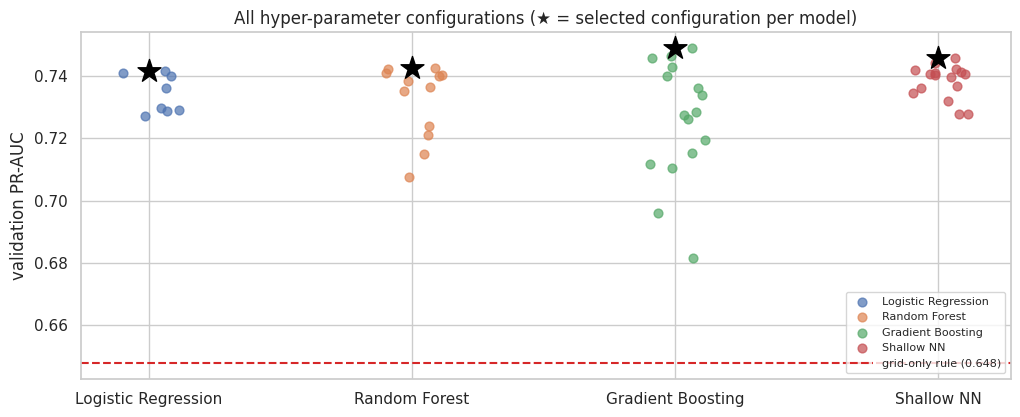

,rows,podium rate,LogReg PR-AUC
era,,,
1950–79,6779.0,0.141,0.462
1980–2002,8867.0,0.125,0.544
2003–13,4311.0,0.139,0.653
2014–19,2469.0,0.147,0.732


In [94]:
# ---- 8.4a Every modeling attempt (hyper-parameter variants of all four model families) ----------
trials_all = pd.concat(ALL_TRIALS, ignore_index=True)
print(f"{len(trials_all)} configurations trained in total "
      f"({trials_all.groupby('model').size().to_dict()}); all selected on validation PR-AUC.")

fig, ax = plt.subplots(figsize=(12, 4.5))
order = ["Logistic Regression", "Random Forest", "Gradient Boosting", "Shallow NN"]
for i, m in enumerate(order):
    t = trials_all[trials_all["model"] == m]
    ax.scatter(np.full(len(t), i) + np.random.default_rng(SEED).uniform(-0.12, 0.12, len(t)), t["val PR-AUC"],
               alpha=0.7, s=40, label=m)
    ax.scatter(i, t["val PR-AUC"].max(), marker="*", s=300, color="black", zorder=3)
ax.axhline(grid_rule_metrics.loc["validation", "PR-AUC"], color="tab:red", linestyle="--",
           label=f"grid-only rule ({grid_rule_metrics.loc['validation', 'PR-AUC']:.3f})")
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order)
ax.set_ylabel("validation PR-AUC")
ax.set_title("All hyper-parameter configurations (★ = selected configuration per model)")
ax.legend(loc="lower right", fontsize=8)
save_fig("8_4_all_attempts")
plt.show()

# Why is validation PR-AUC higher than training PR-AUC? The training seasons include early eras that are
# much harder to predict (unreliable cars, big fields). In-sample PR-AUC of the baseline per era:
era_bins = [1949, 1979, 2002, 2013, 2019]
era_perf = (train_df.assign(p=MODELS["Logistic Regression"]["pipe"].predict_proba(X_train)[:, 1],
                            era=pd.cut(train_df["year"], era_bins, labels=["1950–79", "1980–2002", "2003–13", "2014–19"]))
            .groupby("era", observed=True).apply(lambda d: pd.Series({"rows": len(d), "podium rate": d["podium"].mean(),
                                                                      "LogReg PR-AUC": average_precision_score(d["podium"], d["p"])})))
display(era_perf.round(3))

Training vs validation PR-AUC for every configuration: moving right means the model fits its training seasons better; a point that moves right but **down** has started to memorise them (overfitting).

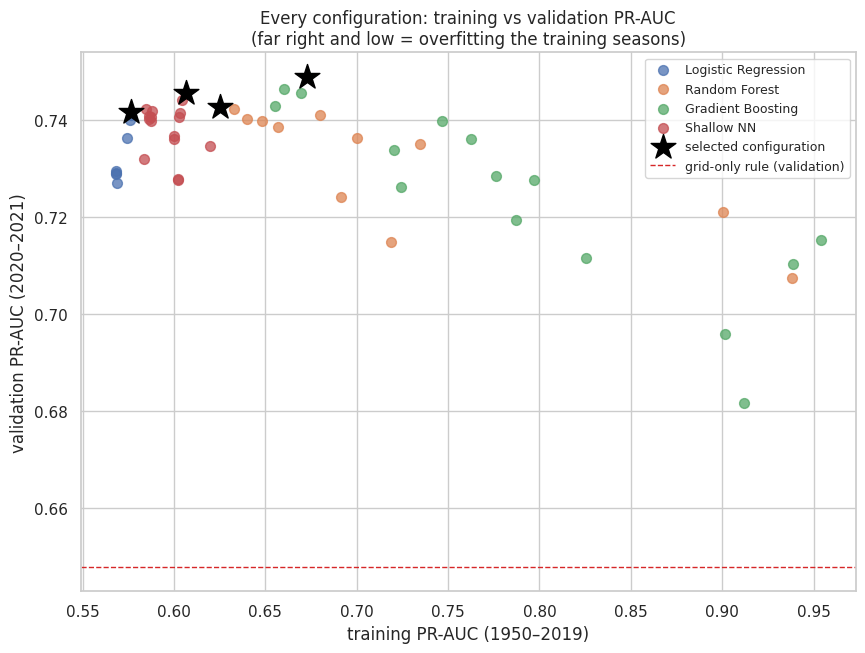

In [95]:
# ---- 8.4a (cont.) Training vs validation PR-AUC for all 52 configurations ----------------------------
fig, ax = plt.subplots(figsize=(10, 7))
for m in order:
    t = trials_all[trials_all["model"] == m]
    ax.scatter(t["train PR-AUC"], t["val PR-AUC"], s=50, alpha=0.75, label=m)
selected = trials_all.loc[trials_all.groupby("model")["val PR-AUC"].idxmax()]
ax.scatter(selected["train PR-AUC"], selected["val PR-AUC"], marker="*", s=350, color="black", label="selected configuration")
ax.axhline(grid_rule_metrics.loc["validation", "PR-AUC"], color="tab:red", linestyle="--", linewidth=1,
           label="grid-only rule (validation)")
ax.set_xlabel("training PR-AUC (1950–2019)")
ax.set_ylabel("validation PR-AUC (2020–2021)")
ax.set_title("Every configuration: training vs validation PR-AUC\n(far right and low = overfitting the training seasons)")
ax.legend(fontsize=9)
save_fig("8_4_train_vs_val_all_configs")
plt.show()

**Findings.** All four model families reach 0.73–0.75 validation PR-AUC at their best configuration, clearly above the grid-only rule (0.648). Badly regularised configurations (deep forests, fast boosting) fall to 0.68–0.71. The per-era table explains the train/validation gap: the same logistic model has an in-sample PR-AUC of only **0.46** on 1950–79 rows but **0.73** on 2014–19 — early F1 was far more random (retirements, 30-car fields). A low training score therefore reflects old, noisy seasons, not underfitting.

The training-vs-validation plot makes the over-fitting visible: configurations that push training PR-AUC to 0.80–0.95 (fully grown forests, fast boosting) all land *lower* on validation (0.68–0.72), while every selected configuration (★) sits at a moderate training score with the highest validation score.


**Final model choice (validation only) and the single test evaluation.** The selection rule was fixed in advance: highest validation PR-AUC; models within 0.005 of the best are a tie and the simplest of them wins (logistic < tree ensembles < neural network). After the choice, every model's pipeline and threshold are frozen and the test set is scored **once**. Uncertainty is shown with a 95% bootstrap interval that resamples whole races (the drivers of one race are not independent).

In [96]:
# ---- 8.4b Final model choice on VALIDATION, then ONE evaluation on the unseen test set ----------------
# Rule (fixed in advance): highest validation PR-AUC; any model within 0.005 of the best counts as a tie,
# and among ties the simplest model wins (logistic < tree ensembles < neural network).
SIMPLICITY = {"linear": 0, "tree ensemble": 1, "neural network": 2}
val_pr = {name: average_precision_score(y_val, m["pipe"].predict_proba(X_val)[:, 1]) for name, m in MODELS.items()}
best_val = max(val_pr.values())
ties = [n for n, v in val_pr.items() if best_val - v <= 0.005]
FINAL_MODEL_NAME = min(ties, key=lambda n: (SIMPLICITY[MODELS[n]["family"]], -val_pr[n]))
final_pipe = MODELS[FINAL_MODEL_NAME]["pipe"]
FINAL_THRESHOLD = MODELS[FINAL_MODEL_NAME]["threshold"]
print("Validation PR-AUC:", {k: round(v, 4) for k, v in val_pr.items()})
print(f"Within 0.005 of the best: {ties} -> FINAL MODEL = {FINAL_MODEL_NAME} (threshold {FINAL_THRESHOLD:.3f}). Frozen.")

# ---- The test set is scored here for the first time: every model is frozen (pipeline + threshold) ----
for m in MODELS.values():
    m["p"] = {"train": m["pipe"].predict_proba(X_train)[:, 1], "validation": m["pipe"].predict_proba(X_val)[:, 1],
              "test": m["pipe"].predict_proba(X_test)[:, 1]}
Y = {"train": y_train, "validation": y_val, "test": y_test}
grid_rule_score["test"] = -X_test["grid_pos"].values

rows = []
for name, m in MODELS.items():
    for split in ["train", "validation", "test"]:
        rows.append({"model": name, "split": split, **all_metrics(Y[split], m["p"][split], m["threshold"])})
for split in ["train", "validation", "test"]:
    rows.append({"model": "Grid-only rule (no ML)", "split": split, **all_metrics(Y[split], grid_rule_score[split], grid_rule_thr)})
comparison = pd.DataFrame(rows)
comparison_table = comparison.pivot(index="model", columns="split", values=METRICS)
comparison_table = comparison_table.reindex(columns=pd.MultiIndex.from_product([METRICS, ["train", "validation", "test"]]))
comparison_table = comparison_table.reindex(["Grid-only rule (no ML)", "Logistic Regression", "Random Forest",
                                             "Gradient Boosting", "Shallow NN"])
display(comparison_table.round(3))

# Uncertainty: 95% bootstrap intervals, resampling whole RACES (rows of one race are not independent)
def race_bootstrap(df_split, y, p, n_boot=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    race_ids = df_split["raceId"].values
    uniq = np.unique(race_ids)
    idx_by_race = {r: np.where(race_ids == r)[0] for r in uniq}
    stats = []
    for _ in range(n_boot):
        idx = np.concatenate([idx_by_race[r] for r in rng.choice(uniq, len(uniq), replace=True)])
        stats.append(average_precision_score(y[idx], p[idx]))
    return np.percentile(stats, [2.5, 97.5])

ci_rows = []
for name, m in MODELS.items():
    for split, d in [("validation", val_df), ("test", test_df)]:
        lo, hi = race_bootstrap(d, Y[split], m["p"][split])
        ci_rows.append({"model": name, "split": split, "PR-AUC": average_precision_score(Y[split], m["p"][split]),
                        "95% CI low": lo, "95% CI high": hi})
pr_ci = pd.DataFrame(ci_rows).pivot(index="model", columns="split", values=["PR-AUC", "95% CI low", "95% CI high"])
display(pr_ci.round(3))

Validation PR-AUC: {'Logistic Regression': 0.7417, 'Random Forest': 0.7427, 'Gradient Boosting': 0.749, 'Shallow NN': 0.7457}
Within 0.005 of the best: ['Gradient Boosting', 'Shallow NN'] -> FINAL MODEL = Gradient Boosting (threshold 0.233). Frozen.


ROC-AUC                   PR-AUC                       F1                   Precision                   Recall                  
                         train validation   test  train validation   test  train validation   test     train validation   test  train validation   test
model                                                                                                                                                  
Grid-only rule (no ML)   0.883      0.910  0.913  0.498      0.648  0.647  0.544      0.695  0.649     0.545      0.698  0.650  0.542      0.692  0.647
Logistic Regression      0.901      0.931  0.934  0.576      0.742  0.716  0.571      0.712  0.654     0.562      0.716  0.625  0.580      0.709  0.686
Random Forest            0.916      0.933  0.940  0.625      0.743  0.718  0.606      0.713  0.680     0.563      0.685  0.622  0.655      0.744  0.750
Gradient Boosting        0.933      0.931  0.938  0.673      0.749  0.709  0.626      0.703  0.673     0.505      0.641  0.567  0.823      0.778  0.828
Shallow NN               0.910      0.929  0.932  0.607      0.746  0.705  0.589      0.698  0.650     0.565      0.695  0.599  0.615      0.701  0.711

PR-AUC            95% CI low            95% CI high           
split                 test validation       test validation        test validation
model                                                                             
Gradient Boosting    0.709      0.749      0.657      0.638       0.765      0.851
Logistic Regression  0.716      0.742      0.660      0.631       0.771      0.845
Random Forest        0.718      0.743      0.661      0.630       0.777      0.848
Shallow NN           0.705      0.746      0.649      0.643       0.760      0.846

The comparison table as a chart: the five metrics per model on validation and on the unseen test set, and PR-AUC (primary metric) with its 95% race-bootstrap interval.

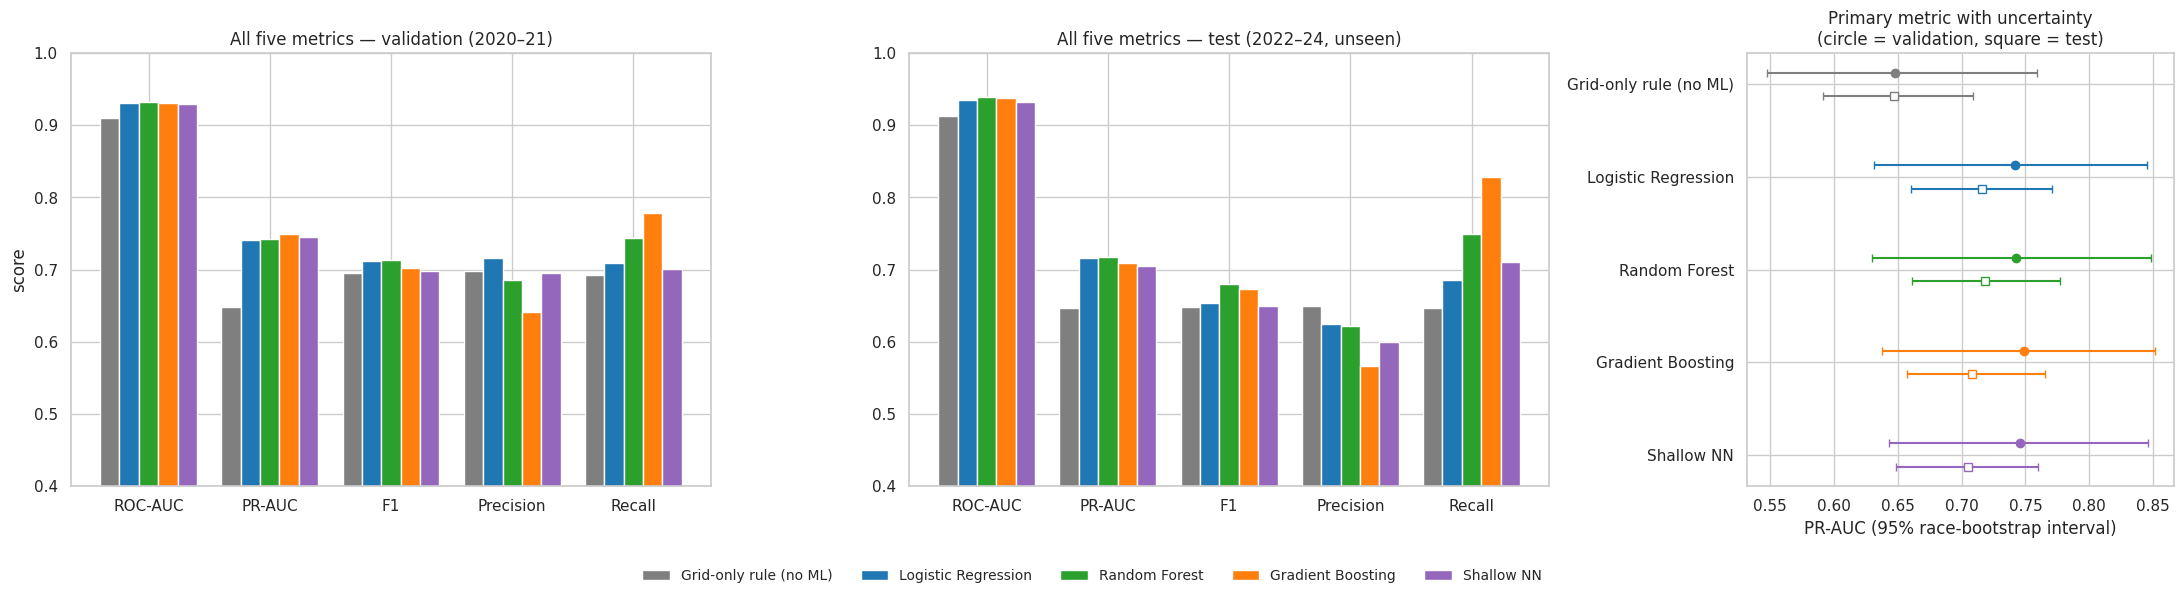

In [97]:
# ---- 8.4b (cont.) Model comparison chart: five metrics on validation and test + PR-AUC uncertainty ----
cmp_models = ["Grid-only rule (no ML)", "Logistic Regression", "Random Forest", "Gradient Boosting", "Shallow NN"]
cmp_colors = dict(zip(cmp_models, ["tab:gray", "tab:blue", "tab:green", "tab:orange", "tab:purple"]))
fig, axes = plt.subplots(1, 3, figsize=(22, 6), gridspec_kw={"width_ratios": [3, 3, 2]})
width = 0.16
for ax, split in zip(axes[:2], ["validation", "test"]):
    xs = np.arange(len(METRICS))
    for k, name in enumerate(cmp_models):
        vals = [comparison_table.loc[name, (metric, split)] for metric in METRICS]
        ax.bar(xs + (k - 2) * width, vals, width, color=cmp_colors[name], label=name)
    ax.set_xticks(xs)
    ax.set_xticklabels(METRICS)
    ax.set_ylim(0.4, 1.0)
    ax.set_title(f"All five metrics — {split} ({'2020–21' if split == 'validation' else '2022–24, unseen'})")
axes[0].set_ylabel("score")

# PR-AUC with 95% bootstrap intervals (whole races resampled); the grid rule gets the same treatment
ci = {}
for name in cmp_models:
    for split, d in [("validation", val_df), ("test", test_df)]:
        p = grid_rule_score[split] if name.startswith("Grid") else MODELS[name]["p"][split]
        lo, hi = race_bootstrap(d, Y[split], p)
        ci[(name, split)] = (average_precision_score(Y[split], p), lo, hi)
for j, (split, marker) in enumerate([("validation", "o"), ("test", "s")]):
    for k, name in enumerate(cmp_models):
        v, lo, hi = ci[(name, split)]
        axes[2].errorbar(v, k + (j - 0.5) * 0.25, xerr=[[v - lo], [hi - v]], fmt=marker, color=cmp_colors[name],
                         capsize=3, label=split if k == 0 else None, markerfacecolor="white" if split == "test" else None)
axes[2].set_yticks(range(len(cmp_models)))
axes[2].set_yticklabels(cmp_models)
axes[2].invert_yaxis()
axes[2].set_xlabel("PR-AUC (95% race-bootstrap interval)")
axes[2].set_title("Primary metric with uncertainty\n(circle = validation, square = test)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=len(cmp_models), fontsize=10, frameon=False)
plt.tight_layout(rect=(0, 0.06, 1, 1))
save_fig("8_4_model_comparison")
plt.show()

**Findings.**
- **Final model: Gradient Boosting** (validation PR-AUC 0.749; the Shallow NN at 0.746 is within the tie margin but more complex). Its validation threshold is 0.233.
- **Test performance (2022–24, held-out test set):** ROC-AUC **0.938**, PR-AUC **0.709** (95% CI 0.66–0.77), F1 **0.673**, precision 0.567, recall 0.828. The low threshold favours recall: the model finds 83% of the podium finishers, at the cost of more false alarms.
- **Every model beats the grid-only rule** on test (PR-AUC 0.705–0.718 vs 0.647; F1 0.65–0.68 vs 0.65) — learning from form and standings adds real value beyond "start at the front".
- **The differences between the four models are not compelling.** Their bootstrap intervals overlap almost completely (validation width ≈ ±0.10, test ≈ ±0.06); on test the Random Forest (0.718) and Logistic Regression (0.716) are even marginally ahead of Gradient Boosting (0.709). We do **not** switch models after seeing the test scores — that would turn the test set into a second validation set. The honest conclusion is that the added complexity buys at most a small gain over the linear baseline here.
- **Generalisation:** PR-AUC drops from validation (0.749) to test (0.709), but ROC-AUC is stable (0.931 → 0.938), i.e. the model still ranks drivers well. The per-season table shows no collapse in the new ground-effect era (2022: 0.69, 2023: 0.73, 2024: 0.70 vs 0.70/0.78 in 2020/21); the variation between single seasons is as large as the validation–test gap.
- **Comparison chart:** all four models are clearly above the grid-only rule on PR-AUC on both splits, while ROC-AUC barely separates them. The threshold choice shows in the last two metrics: Gradient Boosting has the highest recall and the lowest precision. The right panel shows the overlapping 95% intervals of the primary metric.


ROC and Precision–Recall curves for validation and test (the final model is drawn thicker), confusion matrices at each model's frozen threshold, and the final model's performance per season.

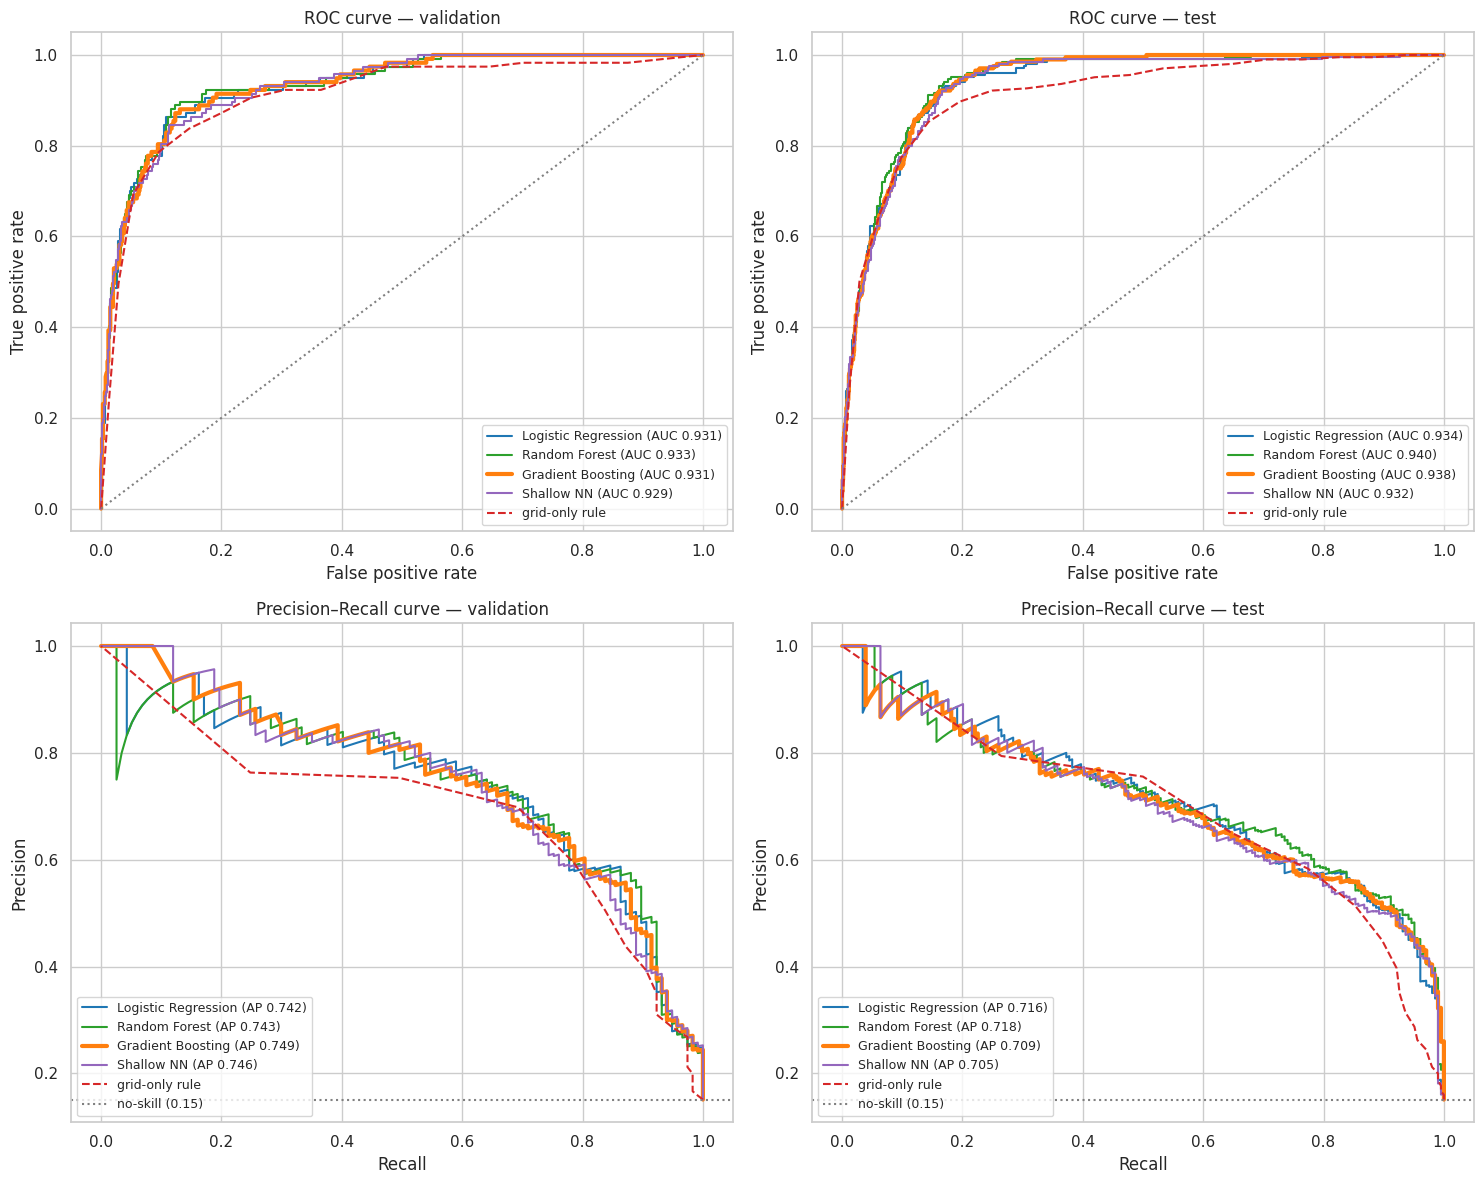

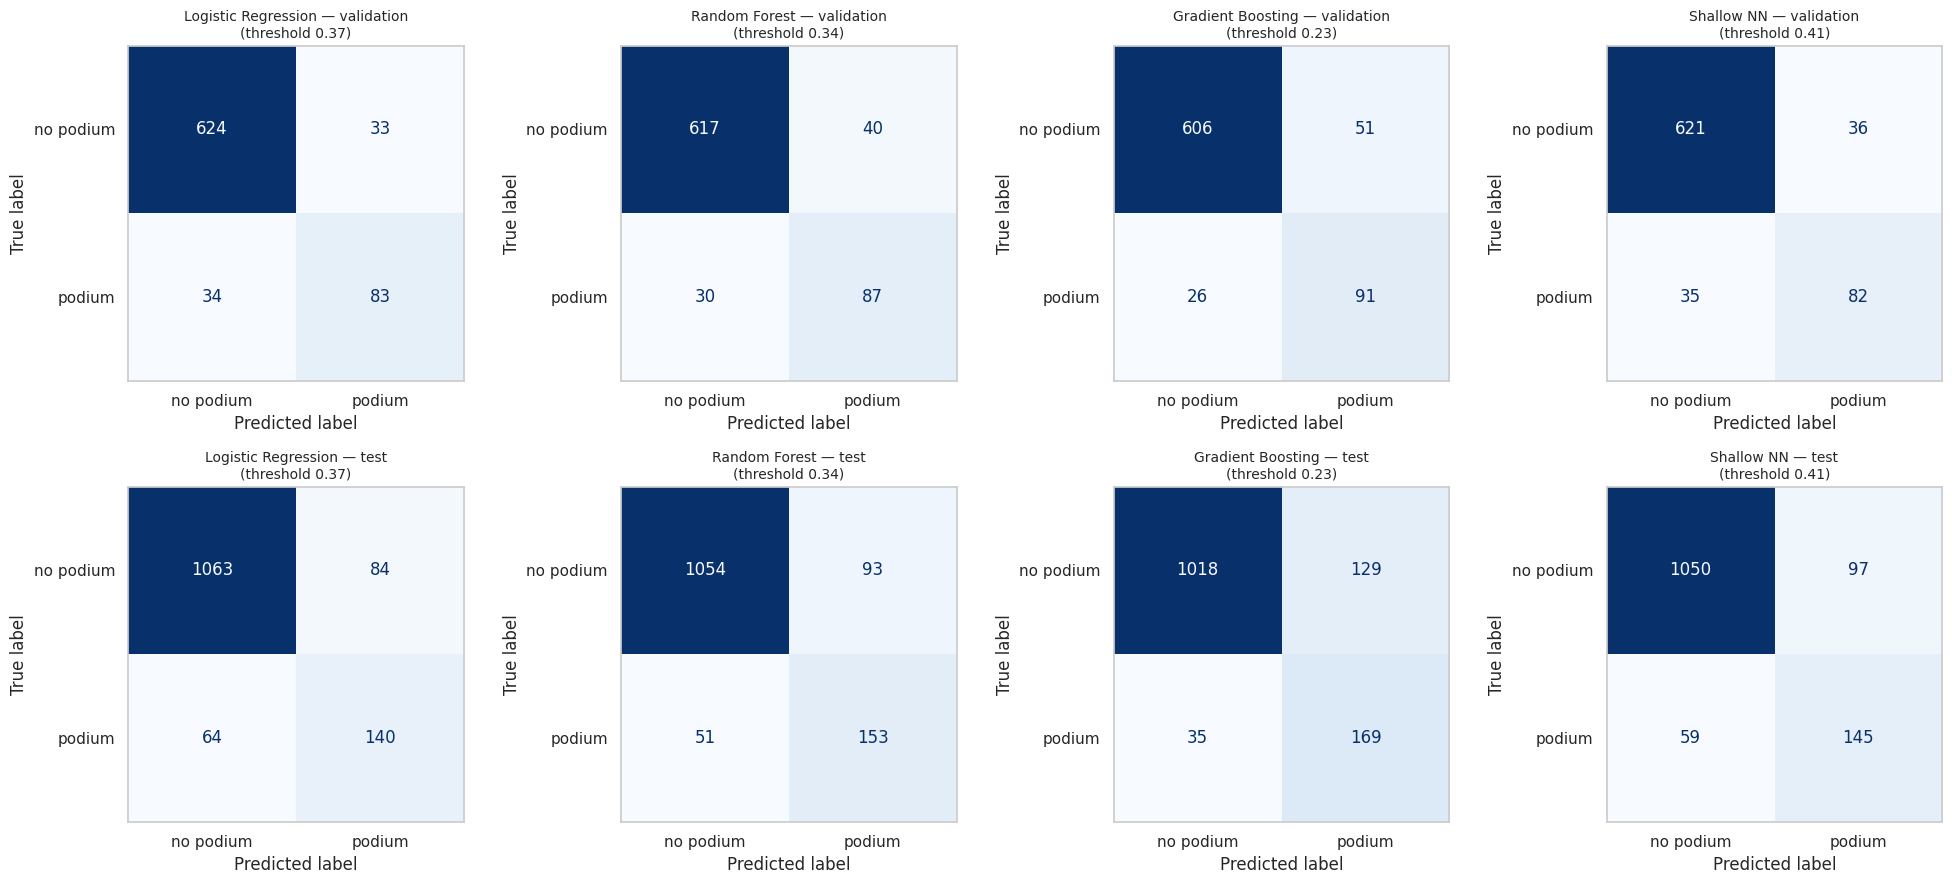

,split,races,ROC-AUC,PR-AUC,F1,Precision,Recall
season,,,,,,,
2020,validation,17,0.916,0.696,0.696,0.639,0.765
2021,validation,22,0.941,0.783,0.707,0.642,0.788
2022,test,22,0.946,0.693,0.698,0.573,0.894
2023,test,22,0.924,0.734,0.631,0.566,0.712
2024,test,24,0.940,0.701,0.685,0.562,0.875


In [98]:
# ---- 8.4c ROC and Precision-Recall curves (validation and test) --------------------------------------
model_colors = dict(zip(MODELS, ["tab:blue", "tab:green", "tab:orange", "tab:purple"]))
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
for j, split in enumerate(["validation", "test"]):
    y = Y[split]
    for name, m in MODELS.items():
        fpr, tpr, _ = roc_curve(y, m["p"][split])
        prec, rec, _ = precision_recall_curve(y, m["p"][split])
        lw = 3 if name == FINAL_MODEL_NAME else 1.5
        axes[0, j].plot(fpr, tpr, lw=lw, color=model_colors[name], label=f"{name} (AUC {roc_auc_score(y, m['p'][split]):.3f})")
        axes[1, j].plot(rec, prec, lw=lw, color=model_colors[name], label=f"{name} (AP {average_precision_score(y, m['p'][split]):.3f})")
    fpr, tpr, _ = roc_curve(y, grid_rule_score[split])
    prec, rec, _ = precision_recall_curve(y, grid_rule_score[split])
    axes[0, j].plot(fpr, tpr, "--", color="tab:red", label="grid-only rule")
    axes[1, j].plot(rec, prec, "--", color="tab:red", label="grid-only rule")
    axes[0, j].plot([0, 1], [0, 1], ":", color="gray")
    axes[1, j].axhline(y.mean(), linestyle=":", color="gray", label=f"no-skill ({y.mean():.2f})")
    axes[0, j].set(title=f"ROC curve — {split}", xlabel="False positive rate", ylabel="True positive rate")
    axes[1, j].set(title=f"Precision–Recall curve — {split}", xlabel="Recall", ylabel="Precision")
    axes[0, j].legend(loc="lower right", fontsize=9)
    axes[1, j].legend(loc="lower left", fontsize=9)
plt.tight_layout()
save_fig("8_4_roc_pr_curves")
plt.show()

# ---- Confusion matrices at each model's frozen validation threshold ----------------------------------
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for j, (name, m) in enumerate(MODELS.items()):
    for i, split in enumerate(["validation", "test"]):
        cm = confusion_matrix(Y[split], (m["p"][split] >= m["threshold"]).astype(int))
        ConfusionMatrixDisplay(cm, display_labels=["no podium", "podium"]).plot(ax=axes[i, j], colorbar=False, values_format="d", cmap="Blues")
        axes[i, j].grid(False)
        axes[i, j].set_title(f"{name} — {split}\n(threshold {m['threshold']:.2f})", fontsize=10)
plt.tight_layout()
save_fig("8_4_confusion_matrices")
plt.show()

# ---- Performance per season for the final model: how does it cope with the 2022 rules change? ---------
season_rows = []
for split, d in [("validation", val_df), ("test", test_df)]:
    p = MODELS[FINAL_MODEL_NAME]["p"][split]
    for yr in sorted(d["year"].unique()):
        mask = (d["year"] == yr).values
        season_rows.append({"season": yr, "split": split, "races": d.loc[mask, "raceId"].nunique(),
                            **all_metrics(Y[split][mask], p[mask], FINAL_THRESHOLD)})
per_season = pd.DataFrame(season_rows).set_index("season")
display(per_season.round(3))

Performance per season: PR-AUC of every model per season (dotted line = no-skill level, the season's podium rate), and all threshold-free and threshold-based metrics of the final model per season.

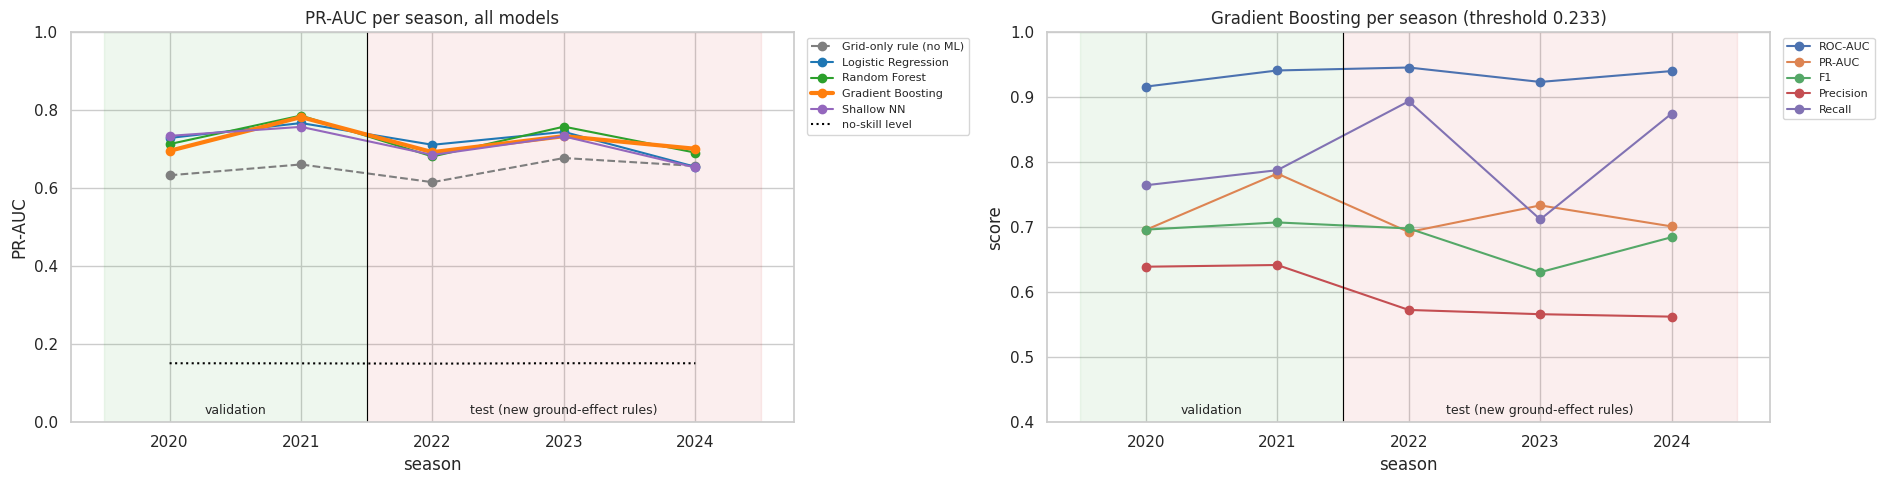

In [99]:
# ---- 8.4c (cont.) Per-season performance plot ----------------------------------------------------------
season_all = []
for split, d in [("validation", val_df), ("test", test_df)]:
    for yr in sorted(d["year"].unique()):
        mask = (d["year"] == yr).values
        row = {"season": yr, "no-skill (podium rate)": Y[split][mask].mean(),
               "Grid-only rule (no ML)": average_precision_score(Y[split][mask], grid_rule_score[split][mask])}
        row.update({name: average_precision_score(Y[split][mask], m["p"][split][mask]) for name, m in MODELS.items()})
        season_all.append(row)
season_all = pd.DataFrame(season_all).set_index("season")

fig, axes = plt.subplots(1, 2, figsize=(19, 5))
for name in ["Grid-only rule (no ML)"] + list(MODELS):
    axes[0].plot(season_all.index, season_all[name], marker="o", label=name,
                 linewidth=3 if name == FINAL_MODEL_NAME else 1.5, linestyle="--" if name.startswith("Grid") else "-",
                 color="tab:gray" if name.startswith("Grid") else model_colors[name])
axes[0].plot(season_all.index, season_all["no-skill (podium rate)"], ":", color="black", label="no-skill level")
axes[0].set(title="PR-AUC per season, all models", ylabel="PR-AUC", ylim=(0, 1))
axes[0].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
for metric in METRICS:
    axes[1].plot(per_season.index, per_season[metric], marker="o", label=metric)
axes[1].set(title=f"{FINAL_MODEL_NAME} per season (threshold {FINAL_THRESHOLD:.3f})", ylabel="score", ylim=(0.4, 1))
axes[1].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
for ax in axes:
    ax.axvspan(2019.5, 2021.5, color="tab:green", alpha=0.08)
    ax.axvspan(2021.5, 2024.5, color="tab:red", alpha=0.08)
    ax.axvline(2021.5, color="black", linewidth=0.8)
    ax.text(2020.5, 0.02, "validation", ha="center", fontsize=9, transform=ax.get_xaxis_transform())
    ax.text(2023, 0.02, "test (new ground-effect rules)", ha="center", fontsize=9, transform=ax.get_xaxis_transform())
    ax.set_xticks(season_all.index)
    ax.set_xlabel("season")
plt.tight_layout()
save_fig("8_4_per_season")
plt.show()

**Discussion.**
- **Curves:** the four models lie close together. On ROC they sit above the grid-only rule everywhere; on the PR curves precision stays around 0.75–0.85 up to ~50% recall and drops to ~0.55 at 80% recall. On test the models' main gain over the grid rule is at **high recall** (above ~0.8): the grid rule can only rank by starting slot, while the models also find podium finishers who start further back.
- **Confusion matrices (test, Gradient Boosting):** 169 of 204 podium finishers are caught (recall 0.83); the errors are mostly false positives (129 vs 35 missed podiums). 89% of those false positives started in the top 6 and 64% finished 4th–6th — fast cars that just missed the podium. The more conservative thresholds of LogReg (0.37) and the NN (0.41) trade recall for precision.
- **Overfitting / underfitting:** visible in the tuning tables (deep forests and fast boosting reach train PR-AUC 0.94–0.95 but drop on validation), and in the NN learning curves; the selected configurations are the regularised ones. No model underfits: all clearly exceed the no-skill level and the grid rule.
- **Baseline vs complexity:** Gradient Boosting gains +0.007 validation PR-AUC over Logistic Regression and is not better on test, so in practice the logistic baseline would be an equally good — and more transparent — choice. We report this honestly instead of tuning on test.
- **2022 rules era:** no clear degradation; form and standings features adapt automatically within a season (they are computed from recent races), which is why the model survives a change of competitive order.
- **Model limitations:** the model only sees pre-race information in the dataset (no weather, tyres, practice pace, upgrades or team orders), so race incidents remain unpredictable — e.g. case B in Section 9.
- **Per-season plot:** in every season all models are well above the no-skill level (the season's podium rate, ~0.15) and above the grid-only rule, and the four models move together: the season-to-season variation (e.g. 2021 vs 2022) is larger than the differences between models.


## 8.5 Feature-group ablation

Remove **one group at a time**, retrain the final model with **identical hyper-parameters** on the same rows, re-choose its threshold on validation, and record the change in validation PR-AUC (primary) — plus ROC-AUC and F1. Because grid and qualifying both describe the starting position, a combined "Grid + Qualifying" removal is added. The same ablation for the logistic baseline checks whether the conclusions depend on the model.

Ablation of the final model (Gradient Boosting), validation set:


,n features,ROC-AUC,PR-AUC,F1,Precision,Recall,Δ PR-AUC,Δ ROC-AUC,Δ F1
removed group,,,,,,,,,
none (full model),24,0.9314,0.7490,0.7027,0.6408,0.7778,0.0000,0.0000,0.0000
Grid,21,0.9268,0.7186,0.7137,0.7364,0.6923,-0.0304,-0.0046,0.0110
Qualifying,20,0.9284,0.7410,0.7100,0.7193,0.7009,-0.0080,-0.0030,0.0073
Driver form,20,0.9319,0.7309,0.7050,0.6087,0.8376,-0.0181,0.0005,0.0023
Constructor form,21,0.9307,0.7416,0.7068,0.6667,0.7521,-0.0074,-0.0007,0.0041
Standings,18,0.9311,0.7446,0.7049,0.6772,0.7350,-0.0044,-0.0003,0.0022
Context,20,0.9320,0.7476,0.7069,0.7130,0.7009,-0.0014,0.0006,0.0042
Grid + Qualifying (all starting-position info),17,0.8931,0.6554,0.7013,0.7105,0.6923,-0.0936,-0.0383,-0.0014


Same ablation for the Logistic Regression baseline (robustness check):


,PR-AUC,Δ PR-AUC,Δ ROC-AUC
removed group,,,
none (full model),0.7417,0.0000,0.0000
Grid,0.7281,-0.0136,-0.0035
Qualifying,0.7323,-0.0094,-0.0038
Driver form,0.7269,-0.0148,-0.0009
Constructor form,0.7478,0.0061,0.0012
Standings,0.7386,-0.0032,-0.0002
Context,0.7373,-0.0044,-0.0001
Grid + Qualifying (all starting-position info),0.6576,-0.0841,-0.0292


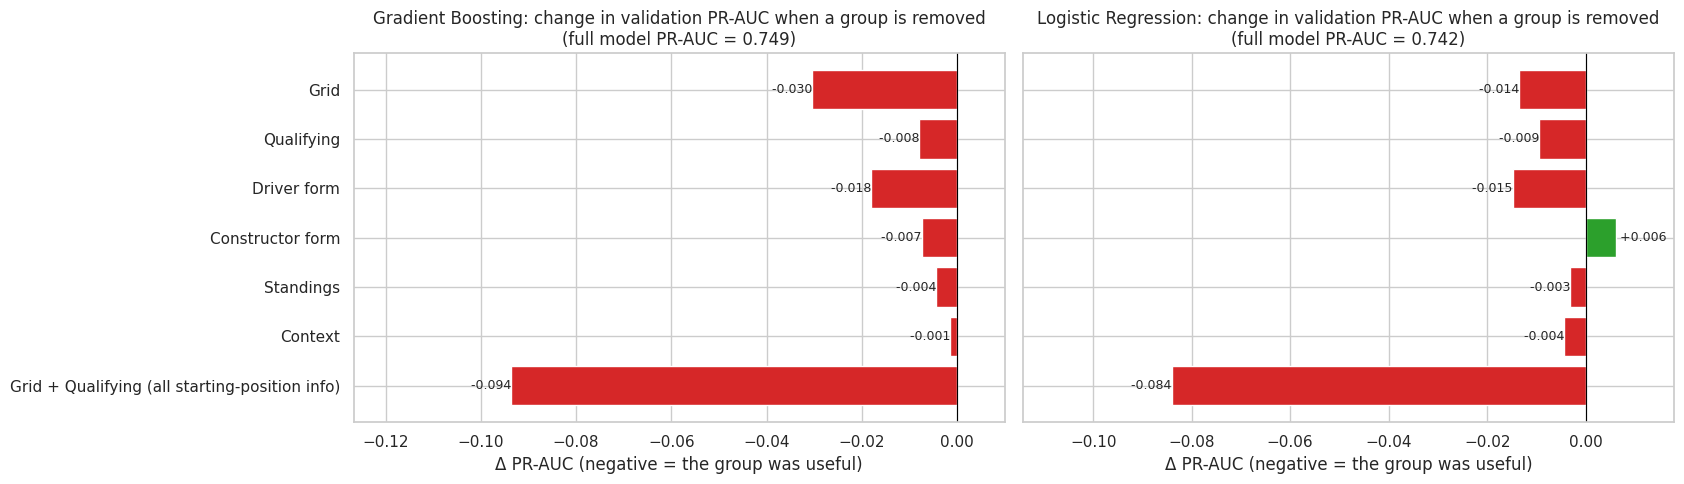

In [100]:
# ---- 8.5 Feature-group ablation: remove ONE group, retrain with identical hyper-parameters --------------
def fit_like(model_name, features):
    """Retrain the frozen configuration of `model_name` on a reduced feature list (train only)."""
    m = MODELS[model_name]
    if m["family"] == "neural network":
        return fit_mlp_pipeline(features, **m["params"])[0]
    return make_pipeline(clone(m["pipe"].named_steps["model"]), features).fit(X_train[features], y_train)


def ablation(model_name):
    rows = []
    variants = {"none (full model)": []} | {g: fs for g, fs in FEATURE_GROUPS.items()} | \
               {"Grid + Qualifying (all starting-position info)": FEATURE_GROUPS["Grid"] + FEATURE_GROUPS["Qualifying"]}
    for removed, drop in variants.items():
        feats = [f for f in FEATURES if f not in drop]
        pipe = fit_like(model_name, feats)
        p = pipe.predict_proba(X_val[feats])[:, 1]
        thr, _ = choose_threshold(y_val, p)                      # threshold re-chosen on validation per variant
        rows.append({"removed group": removed, "n features": len(feats), **all_metrics(y_val, p, thr)})
    out = pd.DataFrame(rows).set_index("removed group")
    for metric in ["PR-AUC", "ROC-AUC", "F1"]:
        out[f"Δ {metric}"] = out[metric] - out.loc["none (full model)", metric]
    return out

ablation_final = ablation(FINAL_MODEL_NAME)
ablation_lr = ablation("Logistic Regression")
print(f"Ablation of the final model ({FINAL_MODEL_NAME}), validation set:")
display(ablation_final.round(4))
print("Same ablation for the Logistic Regression baseline (robustness check):")
display(ablation_lr[["PR-AUC", "Δ PR-AUC", "Δ ROC-AUC"]].round(4))

fig, axes = plt.subplots(1, 2, figsize=(17, 5), sharey=True)
for ax, (label, tab) in zip(axes, [(FINAL_MODEL_NAME, ablation_final), ("Logistic Regression", ablation_lr)]):
    d = tab["Δ PR-AUC"].drop("none (full model)")
    ax.barh(d.index, d.values, color=["tab:red" if v < 0 else "tab:green" for v in d.values])
    ax.axvline(0, color="black", linewidth=0.8)
    for y_pos, v in enumerate(d.values):
        ax.text(v, y_pos, f" {v:+.3f}", va="center", ha="left" if v >= 0 else "right", fontsize=9)
    ax.set_title(f"{label}: change in validation PR-AUC when a group is removed\n(full model PR-AUC = {tab.loc['none (full model)', 'PR-AUC']:.3f})")
    ax.set_xlim(min(d.min(), 0) * 1.3 - 0.005, max(d.max(), 0) * 1.3 + 0.01)
    ax.set_xlabel("Δ PR-AUC (negative = the group was useful)")
axes[0].invert_yaxis()
plt.tight_layout()
save_fig("8_5_ablation")
plt.show()

**Interpretation.**
- **Starting position dominates.** Removing grid *and* qualifying together costs **−0.094** PR-AUC (Gradient Boosting) and −0.084 (LogReg) — by far the largest drop. Removed *separately*, each costs much less (grid −0.030, qualifying −0.008) because the other group still carries most of the same information (ρ ≈ 0.98): ablation of correlated groups underestimates each group's importance. This matches the EDA (1.4, 5.4) and Q1 (where a car starts matters more than where it qualified: grid hurts more than qualifying when removed).
- **Driver form** is the second most useful group (−0.018; LogReg −0.015), consistent with the strong monotone relationships in 5.4.
- **Constructor form** (−0.007) and **standings** (−0.004) add smaller amounts — they overlap with each other and with driver form (all describe "how good is this car/driver right now"). For the logistic model removing constructor form even helps slightly (+0.006), a sign of this redundancy.
- **Context** contributes almost nothing (−0.001), in line with its near-zero MI and with **Q2**: the home flag adds no predictive value once the grid is known.
- F1 changes are small and noisy because the threshold is re-chosen for each variant; PR-AUC is the reliable comparison.

<a id="9"></a>
# 9. Explainable AI (XAI)

> **Important:** feature importance shows what the model *relies on* to make its predictions. It is **not** evidence that a feature *causes* podium finishes. For example, a high constructor points share does not cause podiums; it is a marker of underlying car competitiveness, which the model cannot observe directly. All statements below are about the model's behaviour, not about F1 causality.

All explanations are for the **final model (Gradient Boosting)**, at the level of the 24 readable raw features (the whole pipeline — imputation, scaling, model — is explained together).

## 9.1 Global explanation — permutation importance and SHAP

**Permutation importance (validation set).** Each feature is randomly shuffled (20 times), which breaks its link with the target, and the drop in validation PR-AUC is measured. Because correlated features can stand in for each other when only one is shuffled, we also shuffle each **group** jointly and compare with the ablation (8.5).

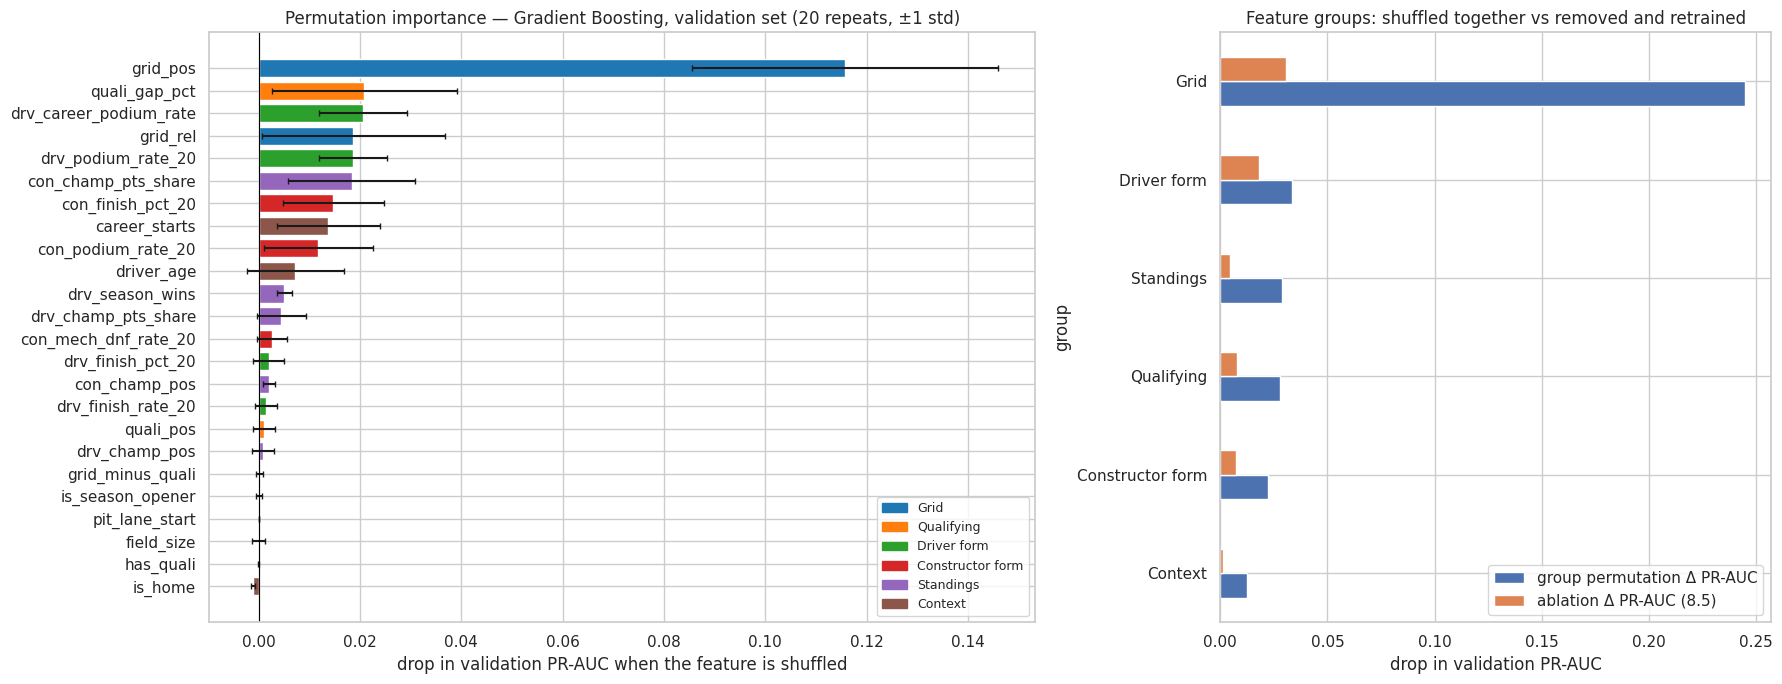

,mean Δ PR-AUC,std,group
grid_pos,0.1157,0.0302,Grid
quali_gap_pct,0.0209,0.0183,Qualifying
drv_career_podium_rate,0.0206,0.0086,Driver form
grid_rel,0.0187,0.0181,Grid
drv_podium_rate_20,0.0186,0.0067,Driver form
con_champ_pts_share,0.0183,0.0126,Standings
con_finish_pct_20,0.0147,0.0100,Constructor form
career_starts,0.0137,0.0102,Context
con_podium_rate_20,0.0118,0.0107,Constructor form
driver_age,0.0072,0.0096,Context


,group permutation Δ PR-AUC,std,ablation Δ PR-AUC (8.5)
group,,,
Grid,0.2447,0.0278,0.0304
Driver form,0.0332,0.0080,0.0181
Standings,0.0289,0.0108,0.0044
Qualifying,0.0279,0.0200,0.0080
Constructor form,0.0222,0.0103,0.0074
Context,0.0122,0.0119,0.0014


In [101]:
# ---- 9.1a Permutation importance of the FINAL model on the VALIDATION set --------------------------
# Shuffle one feature at a time (20 repeats) and measure how much validation PR-AUC drops. Because the whole
# pipeline is permuted at the raw-feature level, the result is in terms of the original, readable features.
from sklearn.inspection import permutation_importance

perm = permutation_importance(final_pipe, X_val, y_val, scoring="average_precision", n_repeats=20,
                              random_state=SEED, n_jobs=1)
perm_imp = pd.DataFrame({"mean Δ PR-AUC": perm.importances_mean, "std": perm.importances_std}, index=FEATURES)
perm_imp["group"] = [g for f in FEATURES for g, fs in FEATURE_GROUPS.items() if f in fs]
perm_imp = perm_imp.sort_values("mean Δ PR-AUC", ascending=False)

# Group permutation: shuffle ALL features of a group together (same rows), so correlated features in the
# same group (grid_pos / grid_rel) cannot stand in for each other
rng = np.random.default_rng(SEED)
base_ap = average_precision_score(y_val, final_pipe.predict_proba(X_val)[:, 1])
group_rows = []
for g, fs in FEATURE_GROUPS.items():
    drops = []
    for _ in range(20):
        Xp = X_val.copy()
        Xp[fs] = Xp[fs].values[rng.permutation(len(Xp))]
        drops.append(base_ap - average_precision_score(y_val, final_pipe.predict_proba(Xp)[:, 1]))
    group_rows.append({"group": g, "group permutation Δ PR-AUC": np.mean(drops), "std": np.std(drops),
                       "ablation Δ PR-AUC (8.5)": -ablation_final.loc[g, "Δ PR-AUC"]})
group_perm = pd.DataFrame(group_rows).set_index("group").sort_values("group permutation Δ PR-AUC", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={"width_ratios": [3, 2]})
top = perm_imp.iloc[::-1]
axes[0].barh(top.index, top["mean Δ PR-AUC"], xerr=top["std"], color=[group_colors[g] for g in top["group"]], capsize=2)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title(f"Permutation importance — {FINAL_MODEL_NAME}, validation set (20 repeats, ±1 std)")
axes[0].set_xlabel("drop in validation PR-AUC when the feature is shuffled")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in group_colors.values()]
axes[0].legend(handles, group_colors.keys(), loc="lower right", fontsize=9)
group_perm[["group permutation Δ PR-AUC", "ablation Δ PR-AUC (8.5)"]].iloc[::-1].plot.barh(ax=axes[1])
axes[1].set_title("Feature groups: shuffled together vs removed and retrained")
axes[1].set_xlabel("drop in validation PR-AUC")
plt.tight_layout()
save_fig("9_1_permutation_importance")
plt.show()
display(perm_imp.round(4))
display(group_perm.round(4))

**SHAP (validation set).** SHAP splits each single prediction into contributions, one per feature, that add up exactly to *prediction − average prediction* (Shapley values from cooperative game theory: each feature's average marginal contribution over many orderings of the features). We use the model-agnostic permutation algorithm on the whole pipeline, with 50 training rows as the reference "average driver". The **bar plot** ranks features by their mean absolute contribution; the **beeswarm** shows every explained driver-race as a dot: position = contribution to the podium probability, colour = feature value (red high, blue low).

SHAP values for 300 validation rows computed in 44 s
max |base + Σ SHAP − predicted probability| = 1.11e-15


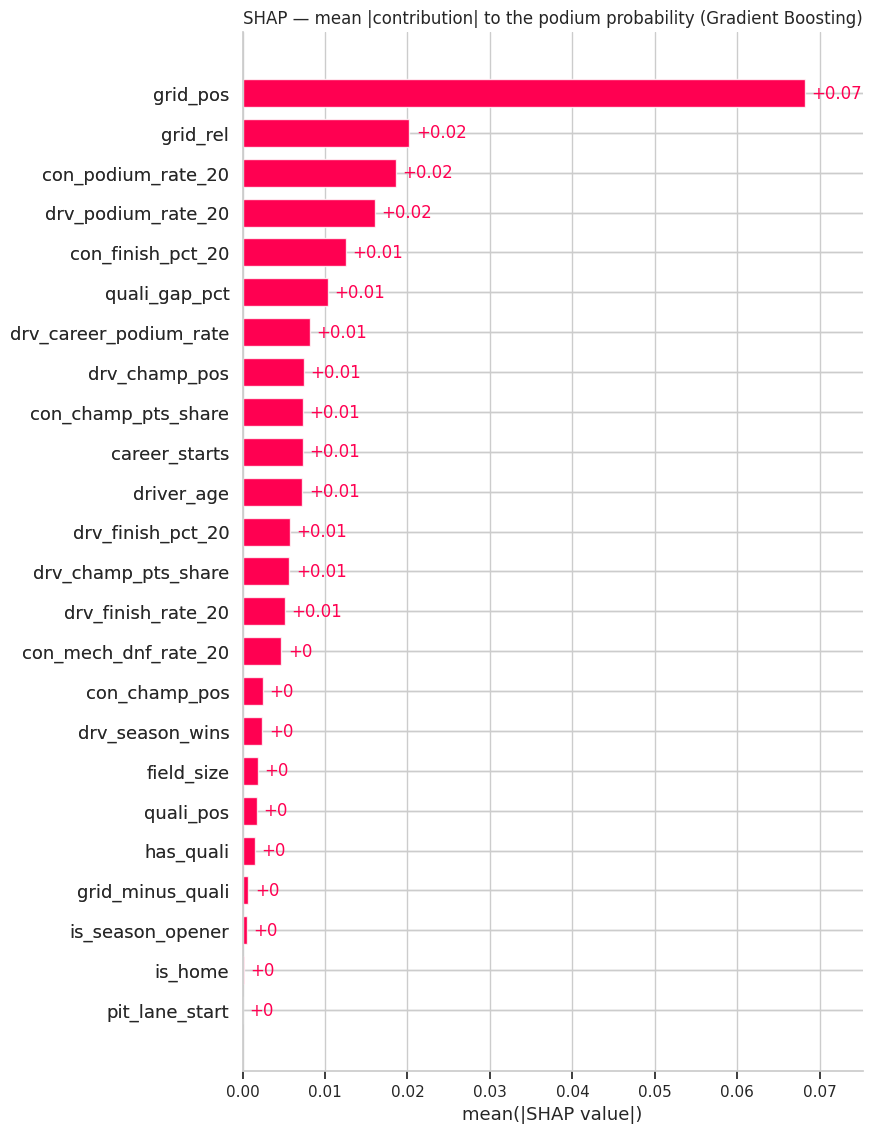

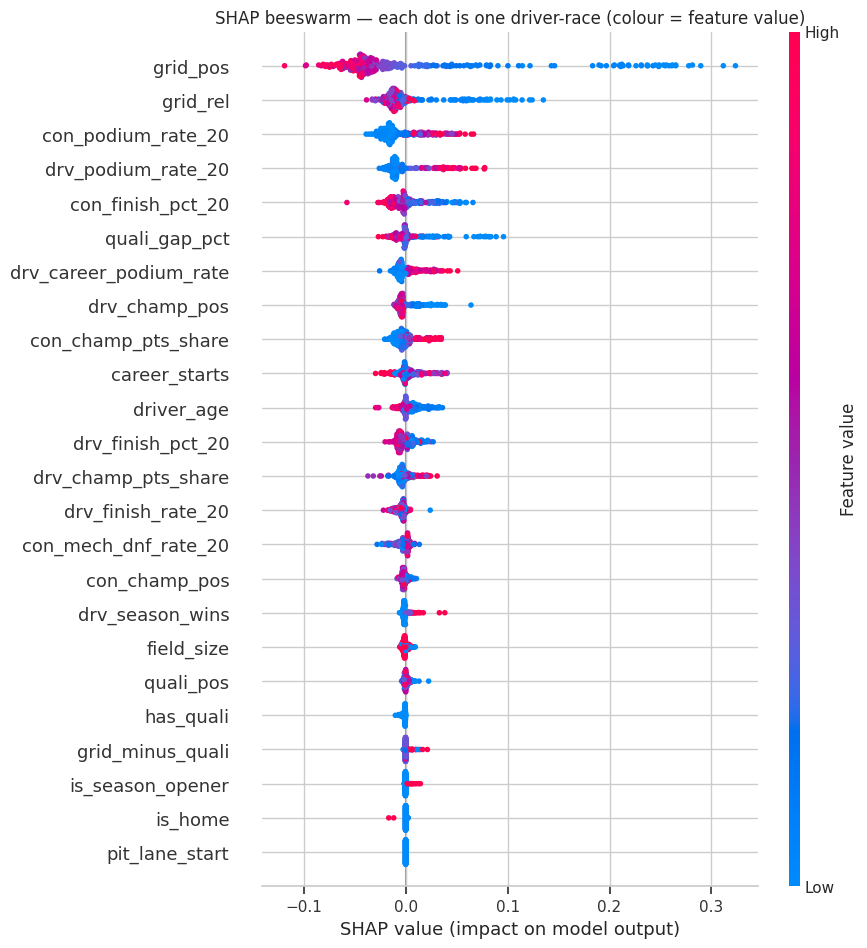

,mean |SHAP| (probability),permutation rank
grid_pos,0.0682,1
grid_rel,0.0202,4
con_podium_rate_20,0.0186,9
drv_podium_rate_20,0.0160,5
con_finish_pct_20,0.0125,7
quali_gap_pct,0.0103,2
drv_career_podium_rate,0.0082,3
drv_champ_pos,0.0074,18
con_champ_pts_share,0.0073,6
career_starts,0.0073,8


,sum of mean |SHAP| per group
Grid,0.0884
Constructor form,0.0359
Driver form,0.0351
Standings,0.0258
Context,0.0165
Qualifying,0.0142


In [102]:
# ---- 9.1b SHAP (global): how much each feature pushes each prediction up or down -----------------
# We explain the WHOLE pipeline (imputation + scaling + model) as a function of the raw features, so the
# explanation is in readable units (e.g. grid_pos = 1) and works for any model type. SHAP's permutation
# algorithm is model-agnostic and its values add up exactly to (prediction − average prediction).
import shap

def predict_podium_proba(X_array):
    return final_pipe.predict_proba(pd.DataFrame(X_array, columns=FEATURES))[:, 1]

shap_background = X_train.sample(50, random_state=SEED)               # reference rows from the TRAINING set
shap_explainer = shap.Explainer(predict_podium_proba, shap.maskers.Independent(shap_background.values),
                                algorithm="permutation", feature_names=FEATURES, seed=SEED)
shap_rows = X_val.sample(min(300, len(X_val)), random_state=SEED)     # rows to explain (validation)
t0 = time.time()
# 4 random feature orderings per row (each ordering = 2·M+1 model calls); averaging over 300 rows smooths the
# remaining sampling noise in the global summary. The local explanation (9.2) uses many more orderings.
shap_values = shap_explainer(shap_rows.values, max_evals=4 * (2 * len(FEATURES) + 1), silent=True)
print(f"SHAP values for {len(shap_rows)} validation rows computed in {time.time() - t0:.0f} s")

# Additivity check: base value + sum of SHAP values == model probability
recon = shap_values.base_values + shap_values.values.sum(axis=1)
print("max |base + Σ SHAP − predicted probability| =", f"{np.abs(recon - predict_podium_proba(shap_rows.values)).max():.2e}")

plt.figure()
shap.plots.bar(shap_values, max_display=len(FEATURES), show=False)
plt.title(f"SHAP — mean |contribution| to the podium probability ({FINAL_MODEL_NAME})")
save_fig("9_1_shap_bar")
plt.show()

plt.figure()
shap.plots.beeswarm(shap_values, max_display=len(FEATURES), show=False)
plt.title("SHAP beeswarm — each dot is one driver-race (colour = feature value)")
save_fig("9_1_shap_beeswarm")
plt.show()

shap_global = pd.Series(np.abs(shap_values.values).mean(axis=0), index=FEATURES).sort_values(ascending=False)
shap_by_group = shap_global.groupby(lambda f: next(g for g, fs in FEATURE_GROUPS.items() if f in fs)).sum().sort_values(ascending=False)
display(pd.DataFrame({"mean |SHAP| (probability)": shap_global.round(4),
                      "permutation rank": perm_imp["mean Δ PR-AUC"].rank(ascending=False).reindex(shap_global.index).astype(int)}))
display(shap_by_group.round(4).to_frame("sum of mean |SHAP| per group"))

**Interpretation (global).**
- **`grid_pos` dominates every view** — permutation importance (−0.12 PR-AUC when shuffled, 5× the next feature), SHAP (largest mean |contribution|) and the ablation. In the beeswarm, low grid values (blue) push the probability up by up to +0.3, while back-of-grid starts push it down slightly for almost everyone.
- **Form and standings come next**: constructor podium rate, driver podium rate (recent and career), constructor finishing position and the constructor points share. High values (red) push towards a podium — the model relies on "fast car + in-form driver", as the EDA suggested.
- **Qualifying gap** matters when it is small (being within a few tenths of pole), complementing the grid.
- **Context features contribute little**, and `is_home` has the smallest SHAP value of all and a slightly *negative* permutation importance (shuffling it does not hurt) — the model does not use the home flag, consistent with **Q2**.
- **Agreement between methods:** all three group-level views put **Grid far ahead** (group permutation −0.24 PR-AUC, ablation −0.030, SHAP group sum 0.088), followed by the two **form groups and standings**, with **context last or near last**. The middle of the order differs between methods (e.g. qualifying ranks 4th by group permutation but last by SHAP) because qualifying and grid carry the same information: whichever method is used, one of them gets the shared credit. Single-feature permutation importance under-rates features with a correlated partner (`quali_pos` is low because `grid_pos` stands in for it) — which is why group-level views are reported too.
- **Again:** these are statements about what the model relies on, not about what causes podiums.

## 9.2 Local explanation — one driver in one race (SHAP waterfall and LIME)

**Case A (main case)** is a test-set podium that the model predicted correctly although the driver did *not* start on the front row — a typical, not extreme, case, so several feature groups have to be weighed. **Case B** is the test set's most confident false positive, used for error analysis.

A **waterfall** starts at the average prediction E[f(x)] (bottom) and adds each feature's contribution (red pushes towards a podium, blue away) until it reaches this driver's predicted probability f(x) (top).

Case A: Sergio Pérez — 2023 Italian Grand Prix | grid 5, qualifying 5 | predicted probability 0.341 (threshold 0.233) | actual finish P2 (podium)
Case B: Max Verstappen — 2022 São Paulo Grand Prix | grid 3, qualifying 2 | predicted probability 0.876 (threshold 0.233) | actual finish P6 (no podium)


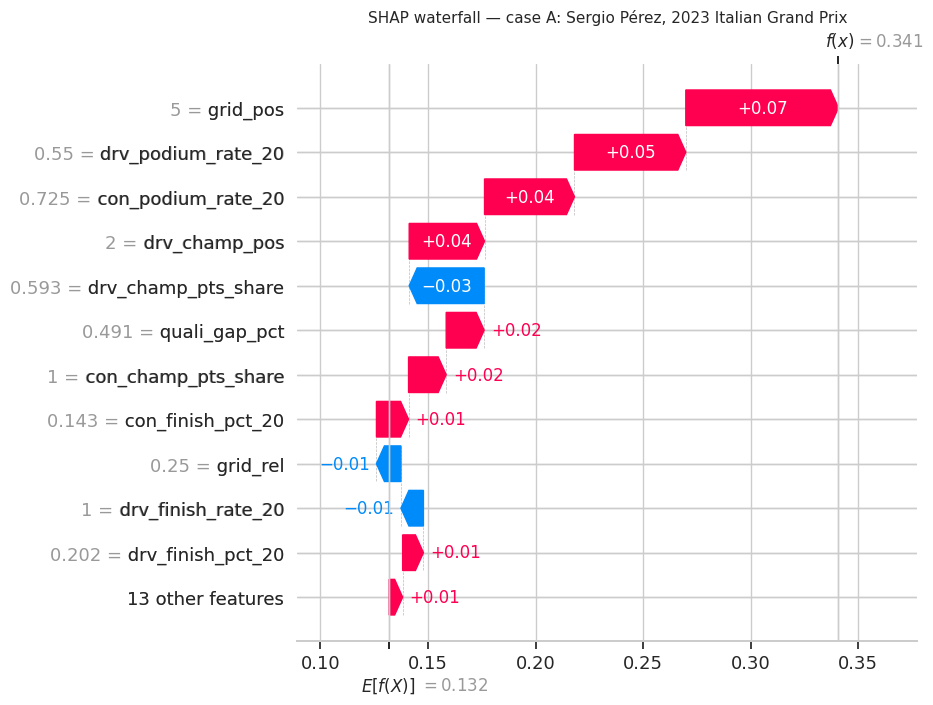

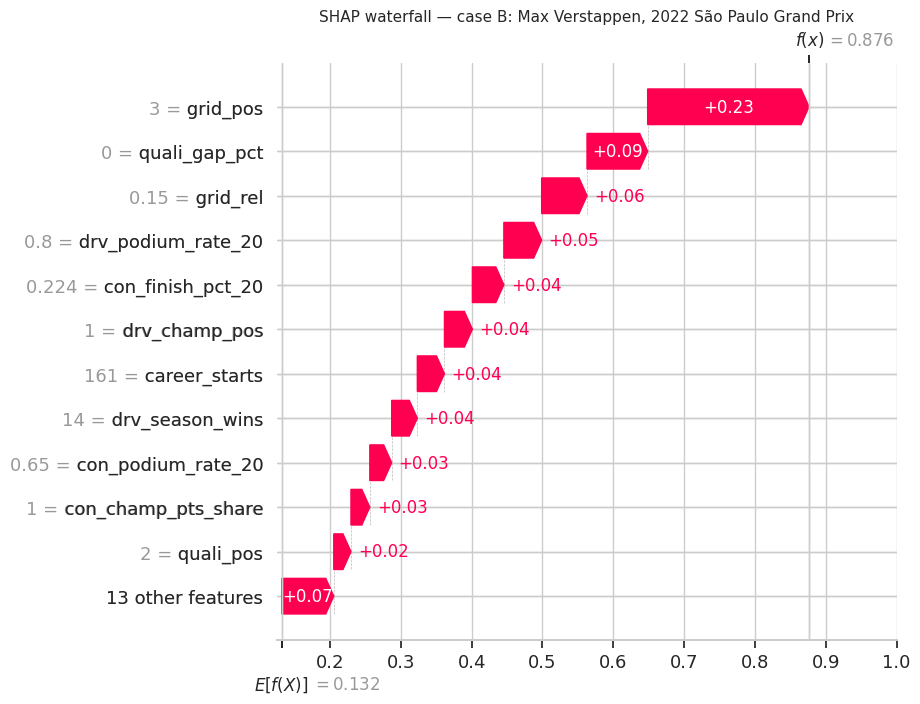

Case A: base value (average prediction on the background) = 0.132; sum of contributions = +0.209; prediction = 0.341


In [103]:
# ---- 9.2a Local explanation: one driver in one race (TEST set) — SHAP waterfall ----------------------
names = clean["drivers"].set_index("driverId").apply(lambda d: f"{d['forename']} {d['surname']}", axis=1)
race_names = clean["races"].set_index("raceId")["name"]
test_view = test_df.assign(p=MODELS[FINAL_MODEL_NAME]["p"]["test"], driver=lambda d: d["driverId"].map(names),
                           race=lambda d: d["year"].astype(str) + " " + d["raceId"].map(race_names))

# Case A (main case): a correctly predicted podium by a driver who did NOT start on the front row and who has
# complete pre-race data (round > 1, qualifying present) -> the explanation has to weigh several groups
cand = test_view[(test_view["podium"] == 1) & (test_view["grid_pos"] >= 4) & (test_view["round"] > 1)
                 & (test_view["p"] >= FINAL_THRESHOLD) & test_view[FEATURES].notna().all(axis=1)]
case_a = cand.sort_values("p", ascending=False).iloc[len(cand) // 2]           # a typical (median) case, not the extreme
# Case B (error analysis): the most confident FALSE POSITIVE in the test set
case_b = test_view[(test_view["podium"] == 0)].sort_values("p", ascending=False).iloc[0]

def describe(case):
    return (f"{case['driver']} — {case['race']} | grid {int(case['grid_pos'])}, qualifying {case['quali_pos']:.0f} | "
            f"predicted probability {case['p']:.3f} (threshold {FINAL_THRESHOLD:.3f}) | "
            f"actual finish P{int(case['positionOrder'])} ({'podium' if case['podium'] else 'no podium'})")

print("Case A:", describe(case_a))
print("Case B:", describe(case_b))

local_explanations = {}
for label, case in [("A", case_a), ("B", case_b)]:
    x = case[FEATURES].values.astype(float).reshape(1, -1)
    exp = shap_explainer(x, max_evals=40 * (2 * len(FEATURES) + 1), silent=True)   # 40 orderings: precise
    local_explanations[label] = exp[0]
    plt.figure()
    shap.plots.waterfall(exp[0], max_display=12, show=False)
    plt.title(f"SHAP waterfall — case {label}: {case['driver']}, {case['race']}", fontsize=11)
    save_fig(f"9_2_shap_waterfall_case_{label}")
    plt.show()

shap_case_a = pd.Series(local_explanations["A"].values, index=FEATURES)
print(f"Case A: base value (average prediction on the background) = {local_explanations['A'].base_values:.3f}; "
      f"sum of contributions = {shap_case_a.sum():+.3f}; prediction = {case_a['p']:.3f}")

**LIME** explains the same case A differently: it perturbs the row thousands of times, asks the model for each perturbed version, and fits a small weighted linear model around this single point. Its output is a list of conditions (e.g. `grid_pos <= 6`) with weights. We compare its directions with SHAP's.

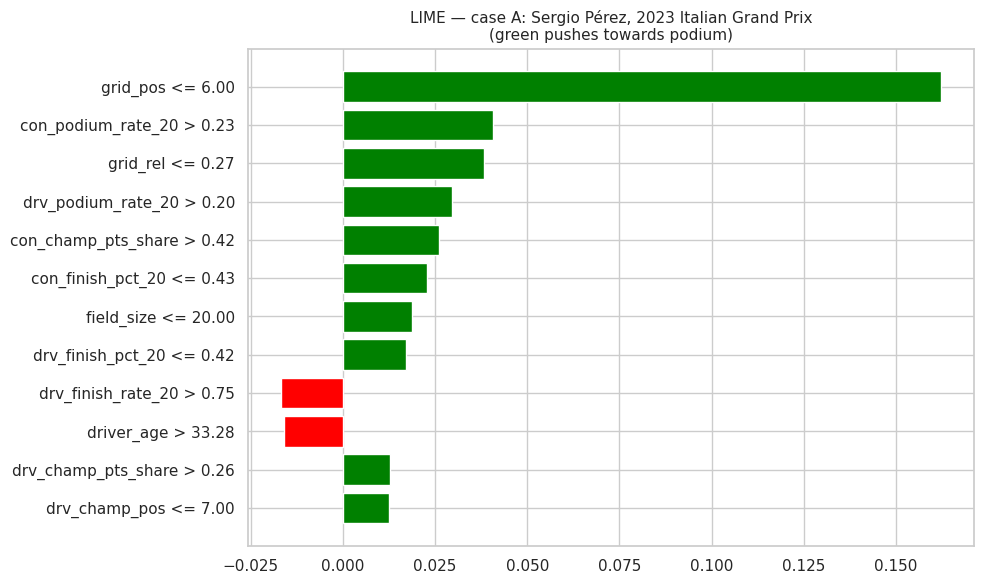

LIME local model: intercept 0.003, local prediction 0.352, model prediction 0.341, local fit R² = 0.59


,LIME condition,LIME weight,feature,SHAP value (same row),same direction?
0,grid_pos <= 6.00,0.1622,grid_pos,0.0709,True
1,con_podium_rate_20 > 0.23,0.0407,con_podium_rate_20,0.0418,True
2,grid_rel <= 0.27,0.0382,grid_rel,-0.0114,False
3,drv_podium_rate_20 > 0.20,0.0296,drv_podium_rate_20,0.0517,True
4,con_champ_pts_share > 0.42,0.0262,con_champ_pts_share,0.0175,True
5,con_finish_pct_20 <= 0.43,0.0228,con_finish_pct_20,0.0149,True
6,field_size <= 20.00,0.0189,field_size,-0.0001,False
7,drv_finish_pct_20 <= 0.42,0.0171,drv_finish_pct_20,0.0097,True
8,drv_finish_rate_20 > 0.75,-0.0167,drv_finish_rate_20,-0.0105,True
9,driver_age > 33.28,-0.0160,driver_age,0.0033,False


LIME and SHAP agree on the direction for 8 of 12 features.


In [104]:
# ---- 9.2b LIME for the same driver-race (case A) ----------------------------------------------------
# LIME perturbs the row many times, asks the model for predictions and fits a small weighted linear model
# around this one point. LIME cannot handle NaN, so it gets the training data with missing values filled by
# the SAME training medians the pipeline uses (the prediction for case A is unchanged, checked below).
try:
    from lime.lime_tabular import LimeTabularExplainer
    LIME_AVAILABLE = True
except ImportError:
    LIME_AVAILABLE = False
    print("LIME is not installed (turn Internet on in Kaggle and re-run the first cell). SHAP local explanation above still applies.")

if LIME_AVAILABLE:
    train_medians = X_train.median()
    X_train_filled = X_train.fillna(train_medians)
    lime_explainer = LimeTabularExplainer(
        X_train_filled.values, feature_names=FEATURES, class_names=["no podium", "podium"], mode="classification",
        categorical_features=[FEATURES.index(f) for f in BINARY_FEATURES], discretize_continuous=True,
        random_state=SEED)
    lime_predict = lambda arr: final_pipe.predict_proba(pd.DataFrame(arr, columns=FEATURES))
    x_a = case_a[FEATURES].astype(float).fillna(train_medians).values
    assert abs(lime_predict(x_a.reshape(1, -1))[0, 1] - case_a["p"]) < 1e-9
    lime_exp = lime_explainer.explain_instance(x_a, lime_predict, num_features=12, num_samples=5000)

    fig = lime_exp.as_pyplot_figure(label=1)
    fig.set_size_inches(10, 6)
    plt.title(f"LIME — case A: {case_a['driver']}, {case_a['race']}\n(green pushes towards podium)", fontsize=11)
    plt.tight_layout()
    save_fig("9_2_lime_case_A")
    plt.show()

    lime_table = pd.DataFrame(lime_exp.as_list(label=1), columns=["LIME condition", "LIME weight"])
    lime_table["feature"] = [next(f for f in sorted(FEATURES, key=len, reverse=True) if f in cond) for cond in lime_table["LIME condition"]]
    lime_table["SHAP value (same row)"] = lime_table["feature"].map(shap_case_a)
    lime_table["same direction?"] = np.sign(lime_table["LIME weight"]) == np.sign(lime_table["SHAP value (same row)"])
    print(f"LIME local model: intercept {lime_exp.intercept[1]:.3f}, local prediction {lime_exp.local_pred[0]:.3f}, "
          f"model prediction {case_a['p']:.3f}, local fit R² = {lime_exp.score:.2f}")
    display(lime_table.round(4))
    print(f"LIME and SHAP agree on the direction for {lime_table['same direction?'].sum()} of {len(lime_table)} features.")

**Interpretation (local).**
- **Case A — Sergio Pérez, 2023 Italian GP (started 5th, finished 2nd).** The average prediction is 0.13; the model predicts **0.34**, above the 0.23 threshold → *podium* (correct). The biggest push comes from the **starting slot** (P5 is still near the front: about +0.07), followed by **driver form** (podiums in 55% of his last 20 races: +0.05), **constructor form** (Red Bull podiums in 72.5% of recent car starts: +0.04) and his **championship position** (2nd: +0.04). Small negatives come from correlated partners (points share −0.03, `grid_rel`) — SHAP splits shared credit between correlated features. In words: *a top-team driver in strong form, starting close to the front.*
- **LIME agrees on the main story** (grid ≤ 6 has by far the largest weight, then constructor and driver podium rates and the constructor points share) and on the direction of 8 of the 12 listed features; the disagreements are small weights on correlated features (`grid_rel`, the points share) and `field_size`. LIME's local linear model fits only moderately (R² ≈ 0.6) — it is an approximation, whereas SHAP values add up exactly to the prediction.
- **Case B — Max Verstappen, 2022 São Paulo GP (started 3rd, predicted 0.88, finished 6th).** Everything the model can see points to a podium: the dominant car, the championship leader, the best recent form, a start from P3. The miss came from an in-race event (a collision with Hamilton and the resulting 5-second time penalty) — information that does not exist before the race. This is the irreducible part of the problem rather than a model bug.
- **Link to global XAI and ablation:** the local explanations use the same features that dominate globally (grid, then constructor/driver form and standings), and the context group plays no visible role — consistent with the ablation in 8.5.

<a id="10"></a>
# 10. Inference Function

`predict_podium(record)` takes the **raw pre-race information for one driver in one race** — the kind of record a user would type in after qualifying — and returns the podium probability and the predicted label:

1. `check_prerace_record(record)` rejects any post-race field (finishing position, points, laps, status, …) and any unknown field name, so future information cannot enter through the inference path.
2. `build_prerace_features(record)` constructs the 24 features: grid and qualifying features from the record; driver and constructor form, career starts and standings from the history **strictly before the race date** (reusing exactly the functions of Section 5, so training and inference cannot drift apart); age and home flag from the drivers/circuits tables. Anything not provided stays `NaN`.
3. The **frozen** pipeline (imputer + scaler fitted on training in 7.3, Gradient Boosting fitted in 8.2) transforms and scores the row — nothing is re-fitted.
4. The **frozen validation threshold** turns the probability into a 0/1 prediction.

A consistency test rebuilds the features of 150 random validation/test rows through this inference path and asserts that they equal the training features exactly.

In [105]:
# ---- 10.1 Inference: raw pre-race record -> features -> FROZEN pipeline -> probability + label --------
# History available to the function: every race start we know of (model_df), but for a given race only the
# rows with a date STRICTLY BEFORE that race are used. The feature code is the SAME code as in Section 5
# (add_driver_form, add_constructor_form, previous_round_standings), so training and serving cannot drift apart.
HISTORY = model_df[["raceId", "driverId", "constructorId", "date", "year", "round", "podium", "finish_pct",
                    "finished", "mech_dnf"]].copy()
RACES = clean["races"].set_index("raceId")[["year", "round", "circuitId", "date"]]
DRIVERS = clean["drivers"].set_index("driverId")[["dob", "nationality"]]
CIRCUIT_COUNTRY = clean["circuits"].set_index("circuitId")["country"].replace(COUNTRY_ALIASES)


# Fields a pre-race record may contain. Anything post-race (FORBIDDEN_FEATURES from Section 5.1: finishing
# position, points, laps, status, ...) is rejected, and so is any unknown field name (e.g. a typo), so that
# information from after the start can never reach the model through the inference function.
ALLOWED_RECORD_FIELDS = {"raceId", "driverId", "constructorId", "date", "year", "round", "circuitId",
                         "grid", "field_size", "quali_position", "q1", "q2", "q3", "pole_time"}


def check_prerace_record(record):
    """Leakage guard: reject post-race fields and unknown field names before any feature is computed."""
    leaked = sorted(set(record) & FORBIDDEN_FEATURES)
    if leaked:
        raise ValueError(f"post-race field(s) are not allowed at the pre-race cutoff: {leaked}")
    unknown = sorted(set(record) - ALLOWED_RECORD_FIELDS)
    if unknown:
        raise ValueError(f"unknown field(s) {unknown}; allowed fields: {sorted(ALLOWED_RECORD_FIELDS)}")
    if "driverId" not in record or "constructorId" not in record:
        raise ValueError("driverId and constructorId are required")


def build_prerace_features(record):
    """record: dict with pre-race information for ONE driver in ONE race.
    Required : driverId, constructorId, and either raceId (a known race) or date + year + round + circuitId.
    Optional : grid (0 = pit lane), field_size, quali_position, q1 / q2 / q3 (seconds or 'm:ss.sss'), pole_time.
    Anything missing simply stays NaN and is filled by the frozen training imputer."""
    check_prerace_record(record)      # leakage guard
    r = dict(record)
    race = RACES.loc[r["raceId"]] if r.get("raceId") in RACES.index else pd.Series(
        {"year": r["year"], "round": r["round"], "circuitId": r["circuitId"], "date": pd.Timestamp(r["date"])})
    date, year, rnd = pd.Timestamp(race["date"]), int(race["year"]), int(race["round"])
    row = {"raceId": r.get("raceId", -1), "driverId": r["driverId"], "constructorId": r["constructorId"],
           "date": date, "year": year, "round": rnd, "podium": np.nan, "finish_pct": np.nan, "finished": np.nan,
           "mech_dnf": np.nan}

    # Grid group
    grid, field = r.get("grid", np.nan), r.get("field_size", np.nan)
    f = {"pit_lane_start": float(grid == 0) if pd.notna(grid) else np.nan}
    f["grid_pos"] = float(field if grid == 0 else grid) if pd.notna(grid) else np.nan
    f["grid_rel"] = min(f["grid_pos"] / field, 1.0) if pd.notna(f["grid_pos"]) and pd.notna(field) else np.nan
    f["field_size"] = field

    # Qualifying group (best time of the sessions the driver took part in, % gap to the pole time)
    times = [time_to_seconds(r.get(s)) for s in ("q1", "q2", "q3")]
    times = [t for t in times if pd.notna(t)]
    best = min(times) if times else np.nan
    pole = time_to_seconds(r.get("pole_time")) if r.get("pole_time") is not None else np.nan
    f["quali_pos"] = r.get("quali_position", np.nan)
    f["has_quali"] = float(pd.notna(f["quali_pos"]))
    f["quali_gap_pct"] = 100 * (best - pole) / pole if pd.notna(best) and pd.notna(pole) else np.nan
    f["grid_minus_quali"] = f["grid_pos"] - f["quali_pos"]

    # Driver and constructor form: history strictly before the race date + this row (outcome unknown = NaN)
    past = HISTORY[HISTORY["date"] < date]
    drv = add_driver_form(pd.concat([past[past["driverId"] == r["driverId"]], pd.DataFrame([row])], ignore_index=True),
                          windows=[FORM_N])
    drv_row = drv[drv["raceId"] == row["raceId"]].iloc[0]
    con, _ = add_constructor_form(pd.concat([past[past["constructorId"] == r["constructorId"]], pd.DataFrame([row])],
                                            ignore_index=True), windows=[FORM_N])
    con_row = con[con["raceId"] == row["raceId"]].iloc[0]
    for c in FEATURE_GROUPS["Driver form"] + ["career_starts"]:
        f[c] = drv_row[c]
    for c in FEATURE_GROUPS["Constructor form"]:
        f[c] = con_row[c]

    # Standings after the previous round of the same season
    prev = RACES[(RACES["year"] == year) & (RACES["round"] == rnd - 1)]
    st = pd.DataFrame([{"prev_raceId": prev.index[0] if len(prev) else np.nan,
                        "driverId": r["driverId"], "constructorId": r["constructorId"]}])
    st, _ = previous_round_standings(st, clean["driver_standings"], "driverId", "drv")
    st, _ = previous_round_standings(st, clean["constructor_standings"], "constructorId", "con")
    for c in ["drv_champ_pos", "drv_champ_pts_share", "drv_season_wins", "con_champ_pos", "con_champ_pts_share"]:
        f[c] = st.iloc[0][c]
    f["drv_champ_pos"] = min(f["drv_champ_pos"], 30) if pd.notna(f["drv_champ_pos"]) else np.nan
    f["is_season_opener"] = float(len(prev) == 0)

    # Context
    dob, nationality = DRIVERS.loc[r["driverId"], ["dob", "nationality"]]
    f["driver_age"] = (date - dob).days / 365.25
    f["is_home"] = float(CIRCUIT_COUNTRY[race["circuitId"]] in NATIONALITY_TO_COUNTRIES[nationality])
    return pd.DataFrame([f])[FEATURES].astype(float)


def predict_podium(record, pipeline=None, threshold=None):
    """Podium probability and label for one driver-race, using the FROZEN pipeline and threshold (no refitting)."""
    pipeline = final_pipe if pipeline is None else pipeline
    threshold = FINAL_THRESHOLD if threshold is None else threshold
    X = build_prerace_features(record)
    p = float(pipeline.predict_proba(X)[0, 1])
    return {"podium_probability": round(p, 4), "predicted_podium": int(p >= threshold), "threshold": round(threshold, 4),
            "model": FINAL_MODEL_NAME, "missing_inputs_imputed": [c for c in FEATURES if pd.isna(X.iloc[0][c])]}


def record_from_tables(raceId, driverId, with_qualifying=True):
    """Assemble the raw pre-race record for a real race from the source tables (what a user would type in)."""
    res = results_clean[(results_clean["raceId"] == raceId) & (results_clean["driverId"] == driverId)].iloc[0]
    rec = {"raceId": int(raceId), "driverId": int(driverId), "constructorId": int(res["constructorId"]), "grid": int(res["grid"]),
           "field_size": int((results_clean["raceId"] == raceId).sum())}
    q = clean["qualifying"][(clean["qualifying"]["raceId"] == raceId)]
    mine = q[q["driverId"] == driverId]
    if with_qualifying and len(mine):
        rec.update({"quali_position": int(mine["position"].iloc[0]),
                    **{s: mine[s].iloc[0] for s in ("q1", "q2", "q3") if pd.notna(mine[s].iloc[0])},
                    "pole_time": float(q[["q1", "q2", "q3"]].min(axis=1).min())})
    return rec


# Train/serve consistency: features built by the inference path == features in model_df (random val/test rows)
check_rows = pd.concat([val_df, test_df]).sample(150, random_state=SEED)
max_gap = 0.0
for _, row in check_rows.iterrows():
    built = build_prerace_features(record_from_tables(row["raceId"], row["driverId"])).iloc[0]
    expected = row[FEATURES].astype(float)
    both_nan = built.isna() & expected.isna()
    assert (built.isna() == expected.isna()).all(), (row["raceId"], row["driverId"])
    max_gap = max(max_gap, float((built[~both_nan] - expected[~both_nan]).abs().max()))
print(f"Inference features == model_df features for 150 random validation/test rows (max |difference| = {max_gap:.1e})")
assert max_gap < 1e-9

Inference features == model_df features for 150 random validation/test rows (max |difference| = 0.0e+00)


**Demo 1 — complete record.** Case A from Section 9 (all information known after qualifying is provided).

In [106]:
# ---- 10.2 Demo 1: a COMPLETE pre-race record (case A from Section 9: a real 2023 race) -----------------
complete_record = record_from_tables(case_a["raceId"], case_a["driverId"])
print("Input record (everything known after qualifying):")
for k, v in complete_record.items():
    print(f"   {k:>15}: {v}")

complete_features = build_prerace_features(complete_record)
complete_pred = predict_podium(complete_record)
print("\nEngineered features (raw units):")
display(complete_features.T.rename(columns={0: "value"}).round(3))
print("Prediction:", complete_pred)
print(f"Actual result: P{int(case_a['positionOrder'])} -> {'podium' if case_a['podium'] else 'no podium'}")
assert abs(complete_pred["podium_probability"] - round(case_a["p"], 4)) < 1e-4    # same as the batch prediction

Input record (everything known after qualifying):
            raceId: 1112
          driverId: 815
     constructorId: 9
              grid: 5
        field_size: 20
    quali_position: 5
                q1: 81.911
                q2: 81.24
                q3: 80.688
         pole_time: 80.294

Engineered features (raw units):


,value
grid_pos,5.000
grid_rel,0.250
pit_lane_start,0.000
quali_pos,5.000
quali_gap_pct,0.491
grid_minus_quali,0.000
has_quali,1.000
drv_podium_rate_20,0.550
drv_finish_pct_20,0.202
drv_finish_rate_20,1.000


Prediction: {'podium_probability': 0.3408, 'predicted_podium': 1, 'threshold': 0.2335, 'model': 'Gradient Boosting', 'missing_inputs_imputed': []}
Actual result: P2 -> podium


**Demo 2 — partially missing records.** (a) The same driver-race without any qualifying information and without the field size; (b) a real debutant (no previous starts, so no form history) without qualifying data. The frozen pipeline fills the gaps with the training medians automatically — no manual step is needed.

In [107]:
# ---- 10.3 Demo 2: PARTIALLY-MISSING records ---------------------------------------------------------
# (a) the same driver-race, but qualifying information and the field size are unknown
partial_record = {k: v for k, v in complete_record.items()
                  if k not in ("quali_position", "q1", "q2", "q3", "pole_time", "field_size")}
print("Input record (no qualifying, no field size):", partial_record)
partial_features = build_prerace_features(partial_record)
partial_pred = predict_podium(partial_record)

# What the frozen pipeline does with the gaps: the medians learned on the TRAINING set are used
imputer = final_pipe.named_steps["prep"].named_transformers_["num"].named_steps["impute"]
fill_values = pd.Series(imputer.statistics_, index=[f for f in FEATURES if f in NUMERIC_FEATURES])
handling = pd.DataFrame({"complete record": complete_features.iloc[0], "partial record": partial_features.iloc[0]})
handling["value used by the model"] = [fill_values.get(f, np.nan) if pd.isna(v) else v
                                       for f, v in partial_features.iloc[0].items()]
display(handling.loc[["grid_pos", "grid_rel", "field_size", "quali_pos", "quali_gap_pct", "grid_minus_quali", "has_quali"]].round(3))
print("Prediction (partial):", partial_pred)
print("Prediction (complete):", complete_pred)

# (b) a real debutant in the test seasons: no previous starts (no form, no career rate) and, here, no qualifying
debut = test_view[test_view["career_starts"] == 0].sort_values("date").iloc[-1]
rookie_record = record_from_tables(debut["raceId"], debut["driverId"], with_qualifying=False)
rookie_pred = predict_podium(rookie_record)
print(f"\nDebutant: {debut['driver']} — {debut['race']} (first career start)")
print("Input record:", rookie_record)
print("Prediction (debutant, partially missing):", rookie_pred)
print(f"Actual result: P{int(debut['positionOrder'])}")

Input record (no qualifying, no field size): {'raceId': 1112, 'driverId': 815, 'constructorId': 9, 'grid': 5}


,complete record,partial record,value used by the model
grid_pos,5.000,5.0,5.000
grid_rel,0.250,NaN,0.524
field_size,20.000,NaN,22.000
quali_pos,5.000,NaN,11.000
quali_gap_pct,0.491,NaN,1.961
grid_minus_quali,0.000,NaN,0.000
has_quali,1.000,0.0,0.000


Prediction (partial): {'podium_probability': 0.3169, 'predicted_podium': 1, 'threshold': 0.2335, 'model': 'Gradient Boosting', 'missing_inputs_imputed': ['grid_rel', 'quali_pos', 'quali_gap_pct', 'grid_minus_quali', 'field_size']}
Prediction (complete): {'podium_probability': 0.3408, 'predicted_podium': 1, 'threshold': 0.2335, 'model': 'Gradient Boosting', 'missing_inputs_imputed': []}

Debutant: Jack Doohan — 2024 Abu Dhabi Grand Prix (first career start)
Input record: {'raceId': 1144, 'driverId': 862, 'constructorId': 214, 'grid': 17, 'field_size': 20}
Prediction (debutant, partially missing): {'podium_probability': 0.0034, 'predicted_podium': 0, 'threshold': 0.2335, 'model': 'Gradient Boosting', 'missing_inputs_imputed': ['quali_pos', 'quali_gap_pct', 'grid_minus_quali', 'drv_podium_rate_20', 'drv_finish_pct_20', 'drv_finish_rate_20', 'drv_career_podium_rate']}
Actual result: P15


**Demo 3 — the leakage guard.** A record that contains post-race information (the finishing position and points) and a record with a misspelled field name are both rejected before any feature is computed.

In [108]:
# ---- 10.4 Demo 3: post-race fields and unknown field names are rejected ----------------------------------
bad_records = {
    "post-race fields (positionOrder, points)": {**complete_record, "positionOrder": 2, "points": 18},
    "misspelled field ('grid_position' instead of 'grid')": {**{k: v for k, v in complete_record.items() if k != "grid"},
                                                             "grid_position": 5},
}
rejected = 0
for label, rec in bad_records.items():
    try:
        predict_podium(rec)
        print(f"{label}: ACCEPTED (this should not happen)")
    except ValueError as err:
        rejected += 1
        print(f"{label}:\n   rejected -> {err}")
assert rejected == len(bad_records)

post-race fields (positionOrder, points):
   rejected -> post-race field(s) are not allowed at the pre-race cutoff: ['points', 'positionOrder']
misspelled field ('grid_position' instead of 'grid'):
   rejected -> unknown field(s) ['grid_position']; allowed fields: ['circuitId', 'constructorId', 'date', 'driverId', 'field_size', 'grid', 'pole_time', 'q1', 'q2', 'q3', 'quali_position', 'raceId', 'round', 'year']


In [109]:
# ---- 10.5 Save the frozen model so it can be reused outside this notebook --------------------------------
import joblib
MODEL_DIR = "/kaggle/working/model" if os.path.exists("/kaggle") else "model"
os.makedirs(MODEL_DIR, exist_ok=True)
joblib.dump({"pipeline": final_pipe, "features": FEATURES, "threshold": FINAL_THRESHOLD,
             "model_name": FINAL_MODEL_NAME, "form_window": FORM_N}, os.path.join(MODEL_DIR, "podium_model.joblib"))
reloaded = joblib.load(os.path.join(MODEL_DIR, "podium_model.joblib"))
assert np.allclose(reloaded["pipeline"].predict_proba(X_test)[:, 1], MODELS[FINAL_MODEL_NAME]["p"]["test"])
print("Saved and re-loaded:", os.path.join(MODEL_DIR, "podium_model.joblib"), "| identical test predictions after reload")

Saved and re-loaded: /kaggle/working/model/podium_model.joblib | identical test predictions after reload


**Save the result tables** (as CSV, next to the saved figures) so the analytical report can be built from exactly the numbers in this notebook.

In [110]:
# ---- 10.6 Save the main result tables for the report ---------------------------------------------------
TABLE_DIR = "/kaggle/working/tables" if os.path.exists("/kaggle") else "tables"
os.makedirs(TABLE_DIR, exist_ok=True)
REPORT_TABLES = {
    "2_cleaning_summary": cleaning_summary, "2_primary_keys": pk_report, "2_foreign_keys": fk_report,
    "3_cleaning_impact": impact,
    "4_1_conversion_grid": conv_grid, "4_1_conversion_qualifying": conv_quali, "4_1_definition_agreement": agreement,
    "4_1_front_row_overall": overall,
    "4_2_home_within_grid": within, "4_2_home_odds_ratios": or_table,
    "4_3_status_mapping": status_map, "4_3_how_races_ended": how_races_ended, "4_3_mech_rates": q3_rates,
    "4_3_lineage_rates": lineage_rates,
    "5_1_leakage_audit": leakage_audit, "5_4_feature_evidence": evidence_table, "5_5a_window_and_N": exp_window_n,
    "5_5b_optional_features": exp_optional, "5_6_final_features": final_feature_table,
    "6_split_summary": split_summary,
    "7_2_prep_experiments": prep_summary, "7_3_prep_effect": effect,
    "8_all_trials": trials_all, "8_2_gb_learning_curve_summary": summary_curves,
    "8_4_model_comparison": comparison_table, "8_4_pr_auc_ci": pr_ci, "8_4_per_season_final": per_season,
    "8_4_per_season_all_models": season_all,
    "8_5_ablation_final": ablation_final, "8_5_ablation_logreg": ablation_lr,
    "9_1_permutation_importance": perm_imp, "9_1_group_permutation": group_perm,
    "9_1_shap_global": shap_global.to_frame("mean |SHAP|"),
}
if LIME_AVAILABLE:
    REPORT_TABLES["9_2_lime_vs_shap"] = lime_table
for name, table in REPORT_TABLES.items():
    table.to_csv(os.path.join(TABLE_DIR, f"{name}.csv"))
print(f"Saved {len(REPORT_TABLES)} tables to {TABLE_DIR} and {len(os.listdir(FIG_DIR))} figures to {FIG_DIR}")

Saved 34 tables to /kaggle/working/tables and 55 figures to /kaggle/working/figures


**Findings.**
- **Consistency:** the features built by the inference function are *identical* to the training features for 150 random validation/test rows (max difference 0), and Demo 1 reproduces the batch prediction exactly.
- **Complete record:** Pérez, 2023 Italian GP → probability **0.341** ≥ 0.233 → **podium** (actual: P2).
- **Partial record:** without qualifying and field size the five missing inputs are imputed (e.g. `quali_pos` → 11, `field_size` → 22) and `has_quali` = 0; the probability moves only slightly (0.341 → **0.317**, still a podium) because the grid slot, form and standings are still known.
- **Debutant:** Jack Doohan, 2024 Abu Dhabi GP (first start, grid 17, no qualifying given) → seven inputs imputed, probability **0.003** → no podium (actual: P15).
- The fitted pipeline is saved with `joblib` (features, threshold and model name included) and re-loaded with identical predictions.
- **Leakage guard (Demo 3):** a record that contains post-race information (`positionOrder`, `points`) and a record with a misspelled field name are both rejected with a clear error before any feature is computed.
- All figures (`figures/`) and the main result tables (`tables/`, CSV) are saved for the analytical report.


<a id="11"></a>
# 11. Conclusions and Known Limitations

## Summary of results

**Data engineering questions (Section 4).**
- **Q1 — front-row conversion by circuit.** 2014–2024: **Monaco (89.5%), Suzuka (88.9%), Yas Marina (86.4%)** lead; 2003–2013: Magny-Cours (91.7%, 6 races), Istanbul Park (78.6%), Monza and Monaco (77.3%). The ranking **partly changes** after 2014 (Spearman ρ = 0.36 grid / 0.54 qualifying definition); overall conversion rises from 68% to 76%. Grid and qualifying definitions agree closely, but drivers demoted from a front-row qualifying spot convert only 31% (vs 64% for promoted drivers): *where the car starts matters more than where it qualified*.
- **Q2 — home advantage.** **No.** The raw home podium rate is lower (11.7% vs 13.9%) only because home drivers start further back; after controlling for grid the odds ratio is ≈ 0.93 (CMH 95% CI 0.78–1.10, p = 0.41). The trained model agrees: `is_home` has ≈ 0 importance (9.1) and the context group ≈ 0 ablation effect (8.5).
- **Q3 — mechanical retirements.** 2014–2021: **Lotus F1 (17.3%), Toro Rosso (16.1%), Renault (13.1%), McLaren (12.7%)**; 2022–2024: **Alfa Romeo (12.5%), Alpine (10.4%)**, AlphaTauri (8.0%). Reliability improved overall (8.9% → 5.7% of starts). The constructor's *past* mechanical-DNF rate is used as a leakage-safe model feature.

**Modeling.**
- **Modeling table:** 24,551 driver-race rows (unique `(raceId, driverId)`), target podium = 13.6%.
- **Features:** 24 leakage-safe features in 6 groups; rolling window *N* = 20 and full-history training chosen on validation (5.5); no circuit/constructor identity, no year.
- **Split:** train 1950–2019, validation 2020–21, test 2022–24 (by season, whole races together).
- **Pre-processing:** median imputation → standard scaling, fitted on train only, no missing-indicator (3 order experiments in 7.2).
- **Models:** Logistic Regression (baseline), Random Forest, Gradient Boosting and a 2-hidden-layer neural network; 52 configurations tuned on validation.
- **Best model (chosen on validation): Gradient Boosting** — validation PR-AUC 0.749 / ROC-AUC 0.931; **unseen test (2022–24): PR-AUC 0.709, ROC-AUC 0.938, F1 0.673, precision 0.567, recall 0.828**. All models beat the grid-only rule (test PR-AUC 0.647), but the differences between them are small relative to the uncertainty (strongly overlapping bootstrap intervals); the logistic baseline is nearly as good and more transparent.
- **Most important information:** the starting position (grid + qualifying: −0.094 PR-AUC when removed), then driver form, constructor form and standings; context ≈ 0. Permutation importance, SHAP, LIME and the ablation agree.
- **Pre-processing findings:** fitting on training + validation rows leaks validation-season statistics (medians shift) even if the score barely moves; scale → impute leaves inputs un-standardised; an indicator created after imputation is empty.

## Selected features and why each is valid at the pre-race cutoff

| Group | Features | Why it is known before the race |
|---|---|---|
| Grid | `grid_pos`, `grid_rel`, `pit_lane_start` | the starting grid is published before the start |
| Qualifying | `quali_pos`, `quali_gap_pct`, `grid_minus_quali`, `has_quali` | qualifying is finished before the race |
| Driver form | `drv_podium_rate_20`, `drv_finish_pct_20`, `drv_finish_rate_20`, `drv_career_podium_rate` | computed from the driver's **previous** starts only (`shift(1)` before rolling; verified by brute force and a perturbation test) |
| Constructor form | `con_podium_rate_20`, `con_finish_pct_20`, `con_mech_dnf_rate_20` | constructor-race aggregation, then `shift(1)`: only **previous** races, no teammate leak |
| Standings | `drv_champ_pos`, `drv_champ_pts_share`, `drv_season_wins`, `con_champ_pos`, `con_champ_pts_share`, `is_season_opener` | standings after the **previous round** of the same season |
| Context | `field_size`, `is_home`, `driver_age`, `career_starts` | entry list, calendar and driver data are known beforehand |

Never used as features: current-race `positionOrder`, `position`, `points`, `laps`, `time`/`milliseconds`, fastest lap, `rank`, `status`, lap times, pit stops, `constructor_results`, same-race standings and sprint results.

## Known limitations

- **Historical qualifying-coverage drift:** no qualifying data before 1994 and patchy 1996–2002, so 63% of training rows have imputed qualifying features; the model learns the qualifying relationship mainly from 2003+.
- **Era sensitivity:** F1 changed rules, reliability and field sizes many times; training spans 70 seasons while the test era (2022+ ground-effect cars, budget cap) is new. Form features adapt within a season, but a sudden change of competitive order at the start of a season is learned only after a few races.
- **Small evaluation sets:** 39 validation and 68 test races; bootstrap intervals are wide (±0.06–0.10 PR-AUC), so small model differences are not meaningful, and the validation set is also used for early stopping, thresholds and model choice (slightly optimistic validation scores).
- **Constructor renames reset history** (`constructorId`), e.g. Toro Rosso → AlphaTauri → RB, so a renamed team starts without constructor form.
- **Cleaning assumptions:** the shared-drive rule (started car, then best `positionOrder`) and the non-starter rules affect a few 1950s rows; the Indy 500 is excluded.
- **Subjective status mapping:** the mechanical / ambiguous categories (Q3 and the mechanical-DNF feature) are a documented judgement.
- **Home-race sample:** home starts are only ~8% of rows, so small home effects cannot be detected.
- **Class imbalance:** ~14% podiums; handled with PR-AUC and validation thresholds, not with resampling.
- **Missing information:** no weather, tyre strategy, practice pace, upgrades, team orders or in-race incidents (see case B) — a large part of race outcomes is unpredictable before the start.
- **Sprint results excluded:** simpler and consistent, at the cost of ignoring Saturday sprint form in 2023–24.
- **Associations, not causes:** model importances and Q1–Q3 are associations; they do not show what causes podiums.

## Milestone 1 checklist → where it is in this notebook

| Requirement | Section |
|---|---|
| EDA before and after cleaning, with plots | 1, 3 |
| Sentinel handling (`\N`), semantic typing | 2.1 |
| Grain one row per `(raceId, driverId)`, duplicates documented | 1.5, 2.4, 5.1 |
| Primary / foreign keys verified; raw CSVs immutable | 2.2, 0 |
| Data-engineering questions Q1–Q3 (multi-hop joins, plots, grain / missingness / cutoff) | 4.1–4.3 |
| Feature selection with evidence and plots; leakage-safe form features | 5.2–5.6 |
| Chronological train / validation / test split, justified | 6 |
| Pre-processing effect on distribution / range / values; ≥ 2 order experiments | 7.2, 7.3 |
| ≥ 2 statistical models + shallow NN, baseline, how they work, limitations | 8.1–8.3 |
| All five metrics on train / validation / test; primary / secondary metric justified | 8, 8.4 |
| ROC / PR curves, confusion matrices, NN training curves | 8.3, 8.4 |
| Feature-group ablation | 8.5 |
| Global XAI (permutation importance, SHAP) and local XAI (SHAP waterfall, LIME) | 9 |
| Inference function on a complete and a partially-missing record | 10 |